### 2. Decesion Tree

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np


# Actual export directory from the successful saving step.
HANDOFF_DIR = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
    r"\artifacts\landslide_handoff_20261018_051428_848638"
)

required_files = [
    "metadata.json",
    "project_state.joblib",
    "result_tables.joblib",
]

for filename in required_files:
    file_path = HANDOFF_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )

metadata = json.loads(
    (HANDOFF_DIR / "metadata.json").read_text(
        encoding="utf-8"
    )
)

saved_state = joblib.load(
    HANDOFF_DIR / "project_state.joblib"
)

saved_tables = joblib.load(
    HANDOFF_DIR / "result_tables.joblib"
)

globals().update(saved_state["variables"])
globals().update(saved_state["models"])
globals().update(saved_tables)

for name, information in metadata["arrays"].items():
    array_path = HANDOFF_DIR / information["file"]

    loaded_array = np.load(
        array_path,
        mmap_mode="r",
        allow_pickle=False,
    )

    assert list(loaded_array.shape) == information["shape"]
    assert str(loaded_array.dtype) == information["dtype"]

    globals()[name] = loaded_array

DATA_DIR = Path(metadata["data_directory"])

print("State, models, result tables, and arrays loaded.")
print(f"Development patches: {len(dev_ids):,}")
print(f"Holdout patches: {len(test_ids):,}")
print(f"Sampled feature array: {X_patch_samples.shape}")
print(f"Result tables: {len(saved_tables)}")
print(f"Data directory exists: {DATA_DIR.exists()}")
print(f"Data directory: {DATA_DIR}")
print("\nHelper functions still need to be restored.")

State, models, result tables, and arrays loaded.
Development patches: 3,039
Holdout patches: 760
Sampled feature array: (3039, 1024, 14)
Result tables: 96
Data directory exists: True
Data directory: C:\Users\hadid\Ramen\ds-ml-project-template\data\archive

Helper functions still need to be restored.


In [2]:
from pathlib import Path

# Project directory: taken from your handoff file
PROJECT_DIR = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory does not exist: {PROJECT_DIR}"
    )

# Python searches for the previously saved project state
state_files = sorted(PROJECT_DIR.rglob("project_state.joblib"))

print(f"Saved project-state files found: {len(state_files)}")

for number, path in enumerate(state_files, start=1):
    print(f"{number}. {path}")

if not state_files:
    print("No project_state.joblib was found inside this directory.")

Saved project-state files found: 1
1. C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\landslide_handoff_20261018_051428_848638\project_state.joblib


In [3]:
import joblib

# Use the single file found in the previous cell
if len(state_files) != 1:
    raise ValueError(
        "Expected exactly one project-state file. Check the listed paths."
    )

STATE_PATH = state_files[0]
HANDOFF_DIR = STATE_PATH.parent

# Load your previously saved project state
saved_state = joblib.load(STATE_PATH)

print("Loaded file:", STATE_PATH.name)
print("Object type:", type(saved_state).__name__)

# Inspect contents without printing large arrays
if isinstance(saved_state, dict):
    print("\nSaved contents:")

    for name, value in saved_state.items():
        shape = getattr(value, "shape", None)

        if shape is not None:
            detail = f"shape={shape}"
        elif isinstance(value, (dict, list, tuple)):
            detail = f"items={len(value)}"
        else:
            detail = ""

        print(f"- {name}: {type(value).__name__} {detail}")
else:
    print("The saved object is not a dictionary.")

Loaded file: project_state.joblib
Object type: dict

Saved contents:
- variables: dict items=17
- models: dict items=3


In [4]:
# These two dictionaries come from the loaded saved_state
saved_variables = saved_state["variables"]
saved_models = saved_state["models"]

print("SAVED VARIABLES")
print("-" * 60)

for name, value in saved_variables.items():
    shape = getattr(value, "shape", None)

    if shape is not None:
        detail = f"shape={shape}, dtype={getattr(value, 'dtype', 'N/A')}"
    elif isinstance(value, (dict, list, tuple)):
        detail = f"items={len(value)}"
    elif isinstance(value, (str, int, float, bool, Path)):
        detail = f"value={value}"
    else:
        detail = ""

    print(f"{name}: {type(value).__name__} | {detail}")

print("\nSAVED MODELS")
print("-" * 60)

for name, model in saved_models.items():
    print(f"{name}: {type(model).__name__}")

SAVED VARIABLES
------------------------------------------------------------
RANDOM_STATE: int | value=43
FEATURE_NAMES: list | items=14
BETA: int | value=2
THRESHOLDS: ndarray | shape=(101,), dtype=float64
CALIBRATION_FRACTION: float | value=0.2
PLATT_C: float | value=1000000.0
dev_ids: ndarray | shape=(3039,), dtype=<U4
test_ids: ndarray | shape=(760,), dtype=<U4
nested_splits: list | items=5
presence_by_id: Series | shape=(3039,), dtype=int64
lr_final_inner_splits: list | items=3
lr_final_settings: dict | items=7
lr_final_threshold: float | value=0.1
lr_interaction_final_settings: dict | items=9
lr_interaction_final_threshold: float | value=0.11
lr_test_metrics: dict | items=16
lr_interaction_secondary_test_metrics: dict | items=16

SAVED MODELS
------------------------------------------------------------
lr_final_base_model: Pipeline
lr_final_calibrator: LogisticRegression
lr_interaction_final_base_model: Pipeline


In [5]:
import numpy as np

# Restore values from the previous project — no new settings
RANDOM_STATE = saved_variables["RANDOM_STATE"]
FEATURE_NAMES = saved_variables["FEATURE_NAMES"]
BETA = saved_variables["BETA"]
THRESHOLDS = saved_variables["THRESHOLDS"]
CALIBRATION_FRACTION = saved_variables["CALIBRATION_FRACTION"]
PLATT_C = saved_variables["PLATT_C"]

dev_ids = saved_variables["dev_ids"]
test_ids = saved_variables["test_ids"]
nested_splits = saved_variables["nested_splits"]

# Check the saved development/holdout partition
assert len(dev_ids) == len(np.unique(dev_ids)), "Duplicate development IDs."
assert len(test_ids) == len(np.unique(test_ids)), "Duplicate holdout IDs."
assert set(dev_ids).isdisjoint(set(test_ids)), "Development/holdout overlap!"
assert len(FEATURE_NAMES) == 14, "Unexpected feature count."
assert len(nested_splits) == 5, "Unexpected outer-fold count."

print("Development patches:", len(dev_ids))
print("Holdout patches:", len(test_ids))
print("Development/holdout overlap: 0")
print("Feature order:", FEATURE_NAMES)
print("Primary metric: F-beta with beta =", BETA)

# Identify separately saved arrays
ARRAYS_DIR = HANDOFF_DIR / "arrays"

if not ARRAYS_DIR.is_dir():
    raise FileNotFoundError(f"Array directory not found: {ARRAYS_DIR}")

print("\nSAVED ARRAY FILES")
for path in sorted(ARRAYS_DIR.rglob("*")):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.relative_to(ARRAYS_DIR)} | {size_mb:.2f} MiB")

# Inspect one outer-fold structure without assuming its format
first_fold = nested_splits[0]

print("\nFIRST OUTER-FOLD STRUCTURE")
print("Type:", type(first_fold).__name__)

if isinstance(first_fold, dict):
    for name, value in first_fold.items():
        size = len(value) if hasattr(value, "__len__") else "N/A"
        print(f"{name}: {type(value).__name__}, length={size}")
elif isinstance(first_fold, (list, tuple)):
    for position, value in enumerate(first_fold):
        size = len(value) if hasattr(value, "__len__") else "N/A"
        print(f"Position {position}: {type(value).__name__}, length={size}")

Development patches: 3039
Holdout patches: 760
Development/holdout overlap: 0
Feature order: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'Elevation']
Primary metric: F-beta with beta = 2

SAVED ARRAY FILES
lr_interaction_secondary_test_probability.npy | 95.00 MiB
lr_test_probability.npy | 95.00 MiB
lr_test_y.npy | 11.88 MiB
sampled_patch_ids.npy | 0.05 MiB
X_patch_samples.npy | 166.20 MiB
y_patch_samples.npy | 2.97 MiB

FIRST OUTER-FOLD STRUCTURE
Type: dict
outer_fold: int, length=N/A
train_ids: ndarray, length=2431
evaluation_ids: ndarray, length=608
inner_splits: list, length=3


In [6]:
# Load saved arrays in read-only mode
X_patch_samples = np.load(
    ARRAYS_DIR / "X_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)

y_patch_samples = np.load(
    ARRAYS_DIR / "y_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)

sampled_patch_ids = np.load(
    ARRAYS_DIR / "sampled_patch_ids.npy",
    mmap_mode="r",
    allow_pickle=False
)

print("X shape:", X_patch_samples.shape)
print("y shape:", y_patch_samples.shape)
print("Patch IDs shape:", sampled_patch_ids.shape)

# Validate dimensions and patch identities
assert X_patch_samples.ndim == 3
assert y_patch_samples.shape == X_patch_samples.shape[:2]
assert X_patch_samples.shape[2] == len(FEATURE_NAMES)
assert X_patch_samples.shape[1] == 1024

assert sampled_patch_ids.ndim == 1
assert len(sampled_patch_ids) == X_patch_samples.shape[0]
assert len(np.unique(sampled_patch_ids)) == len(sampled_patch_ids)
assert set(sampled_patch_ids) == set(dev_ids)
assert set(sampled_patch_ids).isdisjoint(set(test_ids))

# Check all saved training samples in small batches
# 128 is a manually chosen batch size for memory control
label_counts = {0: 0, 1: 0}

for start in range(0, len(sampled_patch_ids), 128):
    X_batch = X_patch_samples[start:start + 128]
    y_batch = y_patch_samples[start:start + 128]

    if not np.isfinite(X_batch).all():
        raise ValueError("Training features contain NaN or infinity.")

    if not np.isin(y_batch, [0, 1]).all():
        raise ValueError("Training labels contain values other than 0 and 1.")

    label_counts[0] += int(np.count_nonzero(y_batch == 0))
    label_counts[1] += int(np.count_nonzero(y_batch == 1))

total_pixels = sum(label_counts.values())

print("\nTraining-data checks passed.")
print("Non-landslide sampled pixels:", label_counts[0])
print("Landslide sampled pixels:", label_counts[1])
print(
    "Landslide proportion in saved samples:",
    f"{label_counts[1] / total_pixels:.2%}"
)

# Inspect the saved inner-split format for correct reuse later
print("\nFIRST INNER-SPLIT STRUCTURE")
first_inner = nested_splits[0]["inner_splits"][0]
print("Type:", type(first_inner).__name__)

if isinstance(first_inner, dict):
    for name, value in first_inner.items():
        size = len(value) if hasattr(value, "__len__") else "N/A"
        print(f"{name}: {type(value).__name__}, length={size}")
elif isinstance(first_inner, (list, tuple)):
    for position, value in enumerate(first_inner):
        size = len(value) if hasattr(value, "__len__") else "N/A"
        print(f"Position {position}: {type(value).__name__}, length={size}")

X shape: (3039, 1024, 14)
y shape: (3039, 1024)
Patch IDs shape: (3039,)

Training-data checks passed.
Non-landslide sampled pixels: 3038406
Landslide sampled pixels: 73530
Landslide proportion in saved samples: 2.36%

FIRST INNER-SPLIT STRUCTURE
Type: dict
train_ids: ndarray, length=1620
validation_ids: ndarray, length=811


In [7]:
from time import perf_counter
from sklearn.tree import DecisionTreeClassifier

# Manually chosen starting settings — not optimized yet
DT_PIXELS_PER_PATCH = 512
DT_BASELINE_MAX_DEPTH = 10
DT_BASELINE_MIN_LEAF = 20

# Map each saved patch ID to its array position
patch_position = {
    str(patch_id): position
    for position, patch_id in enumerate(sampled_patch_ids)
}

def get_sampled_pixels(patch_ids, pixels_per_patch=512):
    """Return saved training pixels in the requested patch order."""
    if not 1 <= pixels_per_patch <= X_patch_samples.shape[1]:
        raise ValueError("Invalid number of pixels per patch.")

    positions = np.array(
        [patch_position[str(patch_id)] for patch_id in patch_ids],
        dtype=int
    )

    X = X_patch_samples[
        positions, :pixels_per_patch, :
    ].reshape(-1, len(FEATURE_NAMES))

    y = y_patch_samples[
        positions, :pixels_per_patch
    ].reshape(-1)

    return X, y

# Validate every saved outer and inner partition
all_outer_evaluation_ids = []

for fold in nested_splits:
    outer_train = set(fold["train_ids"])
    outer_evaluation = set(fold["evaluation_ids"])

    assert outer_train.isdisjoint(outer_evaluation)
    assert outer_train | outer_evaluation == set(dev_ids)
    assert len(fold["inner_splits"]) == 3

    all_outer_evaluation_ids.extend(fold["evaluation_ids"])

    for inner in fold["inner_splits"]:
        inner_train = set(inner["train_ids"])
        inner_validation = set(inner["validation_ids"])

        assert inner_train.isdisjoint(inner_validation)
        assert inner_train | inner_validation == outer_train

assert len(all_outer_evaluation_ids) == len(dev_ids)
assert set(all_outer_evaluation_ids) == set(dev_ids)

# Baseline: use only the first saved inner training partition
dt_baseline_train_ids = nested_splits[0]["inner_splits"][0]["train_ids"]
dt_baseline_validation_ids = (
    nested_splits[0]["inner_splits"][0]["validation_ids"]
)

X_dt_baseline_train, y_dt_baseline_train = get_sampled_pixels(
    dt_baseline_train_ids,
    pixels_per_patch=DT_PIXELS_PER_PATCH
)

dt_baseline = DecisionTreeClassifier(
    max_depth=DT_BASELINE_MAX_DEPTH,
    min_samples_leaf=DT_BASELINE_MIN_LEAF,
    class_weight=None,
    random_state=RANDOM_STATE
)

start_time = perf_counter()
dt_baseline.fit(X_dt_baseline_train, y_dt_baseline_train)
dt_baseline_fit_seconds = perf_counter() - start_time

print("All saved split checks passed.")
print("Training patches:", len(dt_baseline_train_ids))
print("Validation patches:", len(dt_baseline_validation_ids))
print("Training pixels:", len(y_dt_baseline_train))
print("Features:", X_dt_baseline_train.shape[1])
print("Fitted tree depth:", dt_baseline.get_depth())
print("Number of leaves:", dt_baseline.get_n_leaves())
print(f"Training time: {dt_baseline_fit_seconds:.2f} seconds")

All saved split checks passed.
Training patches: 1620
Validation patches: 811
Training pixels: 829440
Features: 14
Fitted tree depth: 10
Number of leaves: 638
Training time: 5.36 seconds


In [8]:
from sklearn.metrics import (
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
    accuracy_score,
    jaccard_score
)
import pandas as pd

# Predict the same sampled pixels used to fit the baseline tree
# 0.50 is a manually fixed starting threshold, not an optimized value
DT_BASELINE_THRESHOLD = 0.50

positive_column = int(
    np.flatnonzero(dt_baseline.classes_ == 1)[0]
)

dt_baseline_train_probability = dt_baseline.predict_proba(
    X_dt_baseline_train
)[:, positive_column]

dt_baseline_train_prediction = (
    dt_baseline_train_probability >= DT_BASELINE_THRESHOLD
).astype(np.uint8)

dt_train_cm = confusion_matrix(
    y_dt_baseline_train,
    dt_baseline_train_prediction,
    labels=[0, 1]
)

tn, fp, fn, tp = dt_train_cm.ravel()

dt_baseline_training_metrics = pd.Series({
    "Threshold": DT_BASELINE_THRESHOLD,
    "F2": fbeta_score(
        y_dt_baseline_train,
        dt_baseline_train_prediction,
        beta=BETA,
        zero_division=0
    ),
    "Precision": precision_score(
        y_dt_baseline_train,
        dt_baseline_train_prediction,
        zero_division=0
    ),
    "Recall": recall_score(
        y_dt_baseline_train,
        dt_baseline_train_prediction,
        zero_division=0
    ),
    "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
    "IoU": jaccard_score(
        y_dt_baseline_train,
        dt_baseline_train_prediction,
        zero_division=0
    ),
    "Accuracy": accuracy_score(
        y_dt_baseline_train,
        dt_baseline_train_prediction
    )
}, name="DT baseline — sampled training pixels")

display(pd.DataFrame(
    dt_train_cm,
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
))

display(dt_baseline_training_metrics.to_frame().round(6))

,Predicted non-landslide,Predicted landslide
Actual non-landslide,806208,3684
Actual landslide,6898,12650


,DT baseline — sampled training pixels
Threshold,0.500000
F2,0.669128
Precision,0.774458
Recall,0.647125
Specificity,0.995451
IoU,0.544508
Accuracy,0.987242


At threshold 0.50, the baseline tree achieved training F2 = 0.6691, precision = 0.7745, and recall = 0.6471. It missed 35.3% of landslide training pixels. Validation is needed to assess generalization.

In [9]:
import h5py
import pandas as pd

# Original data location from the handoff
DATA_DIR = PROJECT_DIR / "data" / "archive"

# Manually fixed baseline threshold — not optimized
DT_BASELINE_THRESHOLD = 0.50

dt_baseline_patch_rows = []

for patch_id in dt_baseline_validation_ids:
    image_path = DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
    mask_path = DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"

    with h5py.File(image_path, "r") as file:
        image = np.asarray(file["img"], dtype=np.float32)

    with h5py.File(mask_path, "r") as file:
        mask = np.asarray(file["mask"])

    if image.shape != (128, 128, len(FEATURE_NAMES)):
        raise ValueError(f"Unexpected image shape: {patch_id}, {image.shape}")

    if mask.shape != (128, 128):
        raise ValueError(f"Unexpected mask shape: {patch_id}, {mask.shape}")

    if not np.isfinite(image).all():
        raise ValueError(f"Invalid feature values in patch {patch_id}")

    if not np.isin(mask, [0, 1]).all():
        raise ValueError(f"Invalid mask labels in patch {patch_id}")

    X_full = image.reshape(-1, len(FEATURE_NAMES))
    y_full = mask.reshape(-1).astype(np.uint8)

    positive_column = int(np.flatnonzero(dt_baseline.classes_ == 1)[0])
    probability = dt_baseline.predict_proba(X_full)[:, positive_column]

    prediction = (probability >= DT_BASELINE_THRESHOLD).astype(np.uint8)

    # Codes: 0 = TN, 1 = FP, 2 = FN, 3 = TP
    tn, fp, fn, tp = np.bincount(
        2 * y_full + prediction,
        minlength=4
    )

    dt_baseline_patch_rows.append({
        "patch_id": str(patch_id),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

dt_baseline_patch_counts = pd.DataFrame(dt_baseline_patch_rows)

tn, fp, fn, tp = (
    dt_baseline_patch_counts[["TN", "FP", "FN", "TP"]]
    .sum()
    .to_numpy()
)

def dt_safe_ratio(numerator, denominator):
    return numerator / denominator if denominator else np.nan

dt_baseline_validation_metrics = pd.Series({
    "Threshold": DT_BASELINE_THRESHOLD,
    "F2": dt_safe_ratio(5 * tp, 5 * tp + 4 * fn + fp),
    "Precision": dt_safe_ratio(tp, tp + fp),
    "Recall": dt_safe_ratio(tp, tp + fn),
    "Specificity": dt_safe_ratio(tn, tn + fp),
    "IoU": dt_safe_ratio(tp, tp + fp + fn),
    "Accuracy": dt_safe_ratio(tp + tn, tp + tn + fp + fn)
}, name="DT baseline — inner validation")

dt_baseline_confusion = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
)

print("Evaluated patches:", len(dt_baseline_patch_counts))
print("Evaluated pixels:", int(tn + fp + fn + tp))

display(dt_baseline_confusion)
display(dt_baseline_validation_metrics.to_frame().round(6))

Evaluated patches: 811
Evaluated pixels: 13287424


,Predicted non-landslide,Predicted landslide
Actual non-landslide,12906279,76428
Actual landslide,116722,187995


,DT baseline — inner validation
Threshold,0.500000
F2,0.633709
Precision,0.710963
Recall,0.616949
Specificity,0.994113
IoU,0.493237
Accuracy,0.985464


On 811 inner-validation patches, the baseline tree achieved F2 = 0.6337, precision = 0.7110, recall = 0.6169, and IoU = 0.4932 at threshold 0.50. It missed 38.3% of landslide pixels. This is an initial validation result, not the final nested-CV assessment.

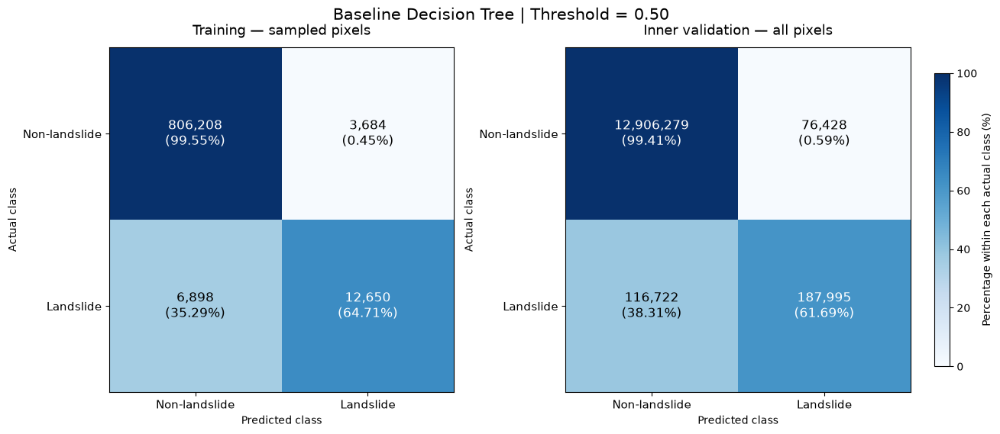

In [10]:
import matplotlib.pyplot as plt

# Counts already calculated in the previous cells
dt_baseline_matrices = {
    "Training — sampled pixels": np.asarray(dt_train_cm),
    "Inner validation — all pixels": (
        dt_baseline_confusion.to_numpy()
    )
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    constrained_layout=True
)

for ax, (title, counts) in zip(
    axes, dt_baseline_matrices.items()
):
    row_totals = counts.sum(axis=1, keepdims=True)

    row_percent = np.divide(
        counts,
        row_totals,
        out=np.zeros_like(counts, dtype=float),
        where=row_totals != 0
    ) * 100

    heatmap = ax.imshow(
        row_percent,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    for row in range(2):
        for column in range(2):
            percentage = row_percent[row, column]

            ax.text(
                column,
                row,
                f"{counts[row, column]:,}\n({percentage:.2f}%)",
                ha="center",
                va="center",
                fontsize=12,
                color="white" if percentage > 55 else "black"
            )

    ax.set(
        title=title,
        xlabel="Predicted class",
        ylabel="Actual class"
    )

    ax.set_xticks([0, 1], ["Non-landslide", "Landslide"])
    ax.set_yticks([0, 1], ["Non-landslide", "Landslide"])
    ax.tick_params(axis="both", labelsize=11)
    ax.set_title(title, fontsize=13, pad=12)

colorbar = fig.colorbar(
    heatmap,
    ax=axes,
    shrink=0.85,
    pad=0.03
)
colorbar.set_label("Percentage within each actual class (%)")

fig.suptitle(
    "Baseline Decision Tree | Threshold = 0.50",
    fontsize=15
)

plt.show()

In [11]:
from sklearn.model_selection import ParameterSampler

# Manually proposed search space
DT_PARAM_SPACE = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_leaf": [5, 20, 50, 100],
    "min_samples_split": [2, 20, 100],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0.0, 0.00001, 0.0001, 0.001]
}

# Include the exact baseline for comparison within the same folds
dt_baseline_params = {
    "max_depth": DT_BASELINE_MAX_DEPTH,
    "min_samples_leaf": DT_BASELINE_MIN_LEAF,
    "min_samples_split": 2,
    "criterion": "gini",
    "class_weight": None,
    "ccp_alpha": 0.0
}

# Draw one extra candidate so we can exclude the baseline if sampled
sampled_candidates = list(ParameterSampler(
    DT_PARAM_SPACE,
    n_iter=25,
    random_state=RANDOM_STATE
))

dt_random_candidates = [
    params for params in sampled_candidates
    if params != dt_baseline_params
][:24]

dt_candidates = [dt_baseline_params] + dt_random_candidates

dt_candidate_table = pd.DataFrame([
    {"candidate_id": number, **params}
    for number, params in enumerate(dt_candidates)
])

outer_search_fits = len(dt_candidates) * sum(
    len(fold["inner_splits"])
    for fold in nested_splits
)

print("Candidate configurations:", len(dt_candidates))
print("Outer folds:", len(nested_splits))
print("Inner folds per outer fold: 3")
print("Hyperparameter-search fits across outer folds:", outer_search_fits)
print("Training pixels per patch:", DT_PIXELS_PER_PATCH)
print("Search-stage threshold:", DT_BASELINE_THRESHOLD)
print("No models are fitted by this cell.")

display(dt_candidate_table)

Candidate configurations: 25
Outer folds: 5
Inner folds per outer fold: 3
Hyperparameter-search fits across outer folds: 375
Training pixels per patch: 512
Search-stage threshold: 0.5
No models are fitted by this cell.


,candidate_id,max_depth,min_samples_leaf,min_samples_split,criterion,class_weight,ccp_alpha
0,0,10.0,20,2,gini,NaN,0.00000
1,1,15.0,50,20,entropy,balanced,0.00001
2,2,5.0,50,20,entropy,NaN,0.00010
3,3,15.0,5,2,entropy,balanced,0.00001
4,4,10.0,50,20,entropy,NaN,0.00001
5,5,10.0,100,100,gini,balanced,0.00100
6,6,20.0,100,20,entropy,balanced,0.00000
7,7,5.0,50,2,entropy,balanced,0.00010
8,8,15.0,100,2,gini,NaN,0.00010
9,9,10.0,100,2,gini,balanced,0.00000


### Result — Decision Tree Search Setup

The search includes 25 candidate configurations: the baseline tree and 24 randomly sampled alternatives. The candidates vary tree depth, minimum leaf size, minimum split size, splitting criterion, class weighting, and pruning strength.

The hyperparameter search requires 375 fits: 25 candidates × 3 inner folds × 5 outer folds. Additional fits for calibration and final model development are not included in this count.

Each fit uses the existing 512 sampled pixels per training patch. Inner validation evaluates all pixels in its validation patches. Candidates will be ranked by mean inner-validation F2 at the fixed search-stage threshold of 0.50. Calibration and threshold selection follow as separate stages.

The candidate configurations were generated using the saved random seed of 43. No candidate has been selected as best, and this setup cell has not trained any models.

In the displayed table, NaN represents None: no depth limit in max_depth and no class weighting in class_weight.

In [12]:
def evaluate_dt_candidates_full_patches(
    models,
    patch_ids,
    threshold=0.50
):
    """
    models: dictionary {candidate_id: fitted_model}
    Evaluate all pixels, reading each patch once.
    """
    totals = {
        candidate_id: np.zeros(4, dtype=np.int64)
        for candidate_id in models
    }

    positive_columns = {
        candidate_id: int(np.flatnonzero(model.classes_ == 1)[0])
        for candidate_id, model in models.items()
    }

    for patch_id in patch_ids:
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")

        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")

        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")

        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid labels: {patch_id}")

        X_full = image.reshape(-1, len(FEATURE_NAMES))
        y_full = mask.reshape(-1).astype(np.uint8)

        for candidate_id, model in models.items():
            probability = model.predict_proba(X_full)[
                :, positive_columns[candidate_id]
            ]
            prediction = (
                probability >= threshold
            ).astype(np.uint8)

            totals[candidate_id] += np.bincount(
                2 * y_full + prediction,
                minlength=4
            )

    rows = []

    for candidate_id, counts in totals.items():
        tn, fp, fn, tp = counts

        rows.append({
            "candidate_id": candidate_id,
            "threshold": threshold,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "F2": dt_safe_ratio(5 * tp, 5 * tp + 4 * fn + fp),
            "precision": dt_safe_ratio(tp, tp + fp),
            "recall": dt_safe_ratio(tp, tp + fn),
            "specificity": dt_safe_ratio(tn, tn + fp),
            "IoU": dt_safe_ratio(tp, tp + fp + fn)
        })

    return pd.DataFrame(rows)


# Candidate 1 is selected by its position, not its performance
DT_PILOT_CANDIDATE_ID = 1

dt_pilot_model = DecisionTreeClassifier(
    **dt_candidates[DT_PILOT_CANDIDATE_ID],
    random_state=RANDOM_STATE
)

start_time = perf_counter()

dt_pilot_model.fit(
    X_dt_baseline_train,
    y_dt_baseline_train
)

dt_pilot_fit_seconds = perf_counter() - start_time

start_time = perf_counter()

dt_pilot_validation = evaluate_dt_candidates_full_patches(
    models={DT_PILOT_CANDIDATE_ID: dt_pilot_model},
    patch_ids=dt_baseline_validation_ids,
    threshold=DT_BASELINE_THRESHOLD
)

dt_pilot_evaluation_seconds = perf_counter() - start_time

print("Pilot candidate:", DT_PILOT_CANDIDATE_ID)
print("Parameters:", dt_candidates[DT_PILOT_CANDIDATE_ID])
print(f"Training time: {dt_pilot_fit_seconds:.2f} seconds")
print(
    "Full-pixel validation time:",
    f"{dt_pilot_evaluation_seconds:.2f} seconds"
)
print("Actual tree depth:", dt_pilot_model.get_depth())
print("Number of leaves:", dt_pilot_model.get_n_leaves())

display(dt_pilot_validation.round(6))

Pilot candidate: 1
Parameters: {'min_samples_split': 20, 'min_samples_leaf': 50, 'max_depth': 15, 'criterion': 'entropy', 'class_weight': 'balanced', 'ccp_alpha': 1e-05}
Training time: 5.75 seconds
Full-pixel validation time: 1.77 seconds
Actual tree depth: 15
Number of leaves: 1147


,candidate_id,threshold,TN,FP,FN,TP,F2,precision,recall,specificity,IoU
0,1,0.5,12298288,684419,23054,281663,0.644553,0.291552,0.924343,0.947282,0.284757


### Result — Decision Tree Pilot Evaluation

Candidate 1 was fitted on 1,620 training patches using 512 sampled pixels per patch. It was evaluated on all pixels of 811 inner-validation patches at threshold 0.50.

Validation F2 increased from 0.6337 for the baseline to 0.6446. Recall increased from 0.6169 to 0.9243, while precision decreased from 0.7110 to 0.2916. IoU decreased from 0.4932 to 0.2848.

Missed landslide pixels decreased from 116,722 to 23,054, but false-positive pixels increased from 76,428 to 684,419. The candidate therefore detects more landslide pixels at the cost of substantially more false alarms.

Training took 5.75 seconds and full-pixel validation took 1.77 seconds. The fitted tree had depth 15 and 1,147 leaves.

This is a pilot result from one inner split, not a selected model or a final performance estimate. Multiple parameters changed together, so their individual effects cannot be isolated from this comparison.

In [13]:
# Keep completed searches in memory without replacing previous results
if "dt_search_results_by_outer" not in globals():
    dt_search_results_by_outer = {}


def run_dt_inner_search(outer_index):
    """Tune candidates using only the selected outer training partition."""
    fold = nested_splits[outer_index]
    search_rows = []
    search_start = perf_counter()

    for inner_index, inner in enumerate(fold["inner_splits"]):
        print(
            f"\nOuter fold {outer_index + 1} | "
            f"Inner fold {inner_index + 1}/3",
            flush=True
        )

        # Only this inner split's training patches are used for fitting
        X_fit, y_fit = get_sampled_pixels(
            inner["train_ids"],
            pixels_per_patch=DT_PIXELS_PER_PATCH
        )

        fitted_models = {}
        fit_times = {}
        tree_depths = {}
        leaf_counts = {}

        for candidate_id, params in enumerate(dt_candidates):
            model = DecisionTreeClassifier(
                **params,
                random_state=RANDOM_STATE
            )

            fit_start = perf_counter()
            model.fit(X_fit, y_fit)
            fit_seconds = perf_counter() - fit_start

            fitted_models[candidate_id] = model
            fit_times[candidate_id] = fit_seconds
            tree_depths[candidate_id] = model.get_depth()
            leaf_counts[candidate_id] = model.get_n_leaves()

            print(
                f"  Candidate {candidate_id:02d} fitted "
                f"({candidate_id + 1}/{len(dt_candidates)}) "
                f"| {fit_seconds:.2f} s",
                flush=True
            )

        print(
            "  Evaluating all candidates on full validation patches...",
            flush=True
        )

        evaluation_start = perf_counter()

        scores = evaluate_dt_candidates_full_patches(
            models=fitted_models,
            patch_ids=inner["validation_ids"],
            threshold=DT_BASELINE_THRESHOLD
        )

        evaluation_seconds = perf_counter() - evaluation_start

        scores["outer_fold"] = outer_index + 1
        scores["inner_fold"] = inner_index + 1
        scores["fit_seconds"] = scores["candidate_id"].map(fit_times)
        scores["tree_depth"] = scores["candidate_id"].map(tree_depths)
        scores["n_leaves"] = scores["candidate_id"].map(leaf_counts)

        search_rows.append(scores)

        print(
            f"  Validation completed in {evaluation_seconds:.2f} s.",
            flush=True
        )

        # Release fitted trees before moving to the next inner split
        del fitted_models, model, X_fit, y_fit

    fold_results = pd.concat(search_rows, ignore_index=True)

    # Mean across the three inner folds; not pooled-pixel F2
    ranking = (
        fold_results
        .groupby("candidate_id", as_index=False)
        .agg(
            mean_inner_F2=("F2", "mean"),
            sd_inner_F2=("F2", "std"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_specificity=("specificity", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_fit_seconds=("fit_seconds", "mean")
        )
    )

    # Predefined tie-break: lower candidate ID
    ranking = (
        ranking
        .sort_values(
            ["mean_inner_F2", "candidate_id"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    best_candidate_id = int(ranking.iloc[0]["candidate_id"])

    return {
        "fold_results": fold_results,
        "ranking": ranking,
        "best_candidate_id": best_candidate_id,
        "best_params": dict(dt_candidates[best_candidate_id]),
        "search_seconds": perf_counter() - search_start
    }


# Run only the first outer fold's INNER search
if 1 not in dt_search_results_by_outer:
    dt_search_results_by_outer[1] = run_dt_inner_search(outer_index=0)
else:
    print("Using the completed search already stored for outer fold 1.")

dt_outer1_search = dt_search_results_by_outer[1]

print("\nINNER SEARCH COMPLETED")
print("Selected candidate:", dt_outer1_search["best_candidate_id"])
print("Selected parameters:", dt_outer1_search["best_params"])
print(
    "Total search time:",
    f"{dt_outer1_search['search_seconds'] / 60:.2f} minutes"
)

display(dt_outer1_search["ranking"].round(6))


Outer fold 1 | Inner fold 1/3
  Candidate 00 fitted (1/25) | 5.96 s
  Candidate 01 fitted (2/25) | 5.67 s
  Candidate 02 fitted (3/25) | 3.18 s
  Candidate 03 fitted (4/25) | 5.82 s
  Candidate 04 fitted (5/25) | 5.35 s
  Candidate 05 fitted (6/25) | 6.11 s
  Candidate 06 fitted (7/25) | 5.64 s
  Candidate 07 fitted (8/25) | 3.31 s
  Candidate 08 fitted (9/25) | 8.05 s
  Candidate 09 fitted (10/25) | 6.12 s
  Candidate 10 fitted (11/25) | 8.08 s
  Candidate 11 fitted (12/25) | 3.14 s
  Candidate 12 fitted (13/25) | 3.15 s
  Candidate 13 fitted (14/25) | 8.78 s
  Candidate 14 fitted (15/25) | 3.29 s
  Candidate 15 fitted (16/25) | 5.69 s
  Candidate 16 fitted (17/25) | 5.33 s
  Candidate 17 fitted (18/25) | 5.92 s
  Candidate 18 fitted (19/25) | 5.17 s
  Candidate 19 fitted (20/25) | 5.81 s
  Candidate 20 fitted (21/25) | 3.15 s
  Candidate 21 fitted (22/25) | 8.55 s
  Candidate 22 fitted (23/25) | 5.23 s
  Candidate 23 fitted (24/25) | 8.53 s
  Candidate 24 fitted (25/25) | 5.80 s
  E

,candidate_id,mean_inner_F2,sd_inner_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_fit_seconds
0,3,0.681813,0.018980,0.366856,0.869392,0.964311,0.347624,16.334540
1,1,0.656619,0.025503,0.305240,0.923989,0.949924,0.297741,5.742645
2,6,0.635904,0.028601,0.278546,0.938833,0.942068,0.273563,5.643556
3,9,0.625433,0.033649,0.267010,0.945480,0.938025,0.262911,5.995299
4,15,0.625092,0.029970,0.266007,0.946416,0.937782,0.262051,5.662076
5,10,0.621792,0.036001,0.263924,0.945420,0.936972,0.259908,11.258520
6,0,0.620443,0.012087,0.720147,0.600256,0.994464,0.485814,5.826018
7,16,0.619083,0.028532,0.262266,0.941003,0.936920,0.258002,5.315578
8,4,0.608284,0.007282,0.723424,0.585327,0.994697,0.477810,5.286036
9,17,0.604173,0.006102,0.726840,0.580008,0.994837,0.475834,5.700098


### Result — Outer Fold 1: Inner Hyperparameter Search

All 25 Decision Tree configurations were evaluated across the three inner folds. The search completed in 9.37 minutes.

Candidate 3 achieved the highest mean inner-validation F2 at threshold 0.50. Its parameters were: max_depth=15, min_samples_leaf=5, min_samples_split=2, criterion="entropy", class_weight="balanced", and ccp_alpha=0.00001.

Mean inner-validation F2 increased from 0.6204 for the baseline to 0.6818, an absolute gain of 0.0614. Recall increased from 0.6003 to 0.8694, while precision decreased from 0.7201 to 0.3669 and IoU decreased from 0.4858 to 0.3476.

The selected candidate's inner-fold F2 standard deviation was 0.0190. This describes variation across the three folds; it is not a confidence interval.

These scores were used for hyperparameter selection and are not final generalization estimates. Calibration and threshold selection remain pending. Neither the outer evaluation patches nor the holdout patches were used in this search.

Baseline and selected candidate — individual inner folds


,inner_fold,candidate_id,F2,precision,recall,specificity,IoU,tree_depth,n_leaves
0,1,0,0.633709,0.710963,0.616949,0.994113,0.493237,10,638
3,1,3,0.671099,0.352803,0.866548,0.962690,0.334622,15,1925
25,2,0,0.617566,0.678277,0.604049,0.993842,0.469523,10,659
28,2,3,0.670613,0.348489,0.872156,0.964956,0.331552,15,1931
50,3,0,0.610055,0.771202,0.579768,0.995436,0.494681,10,608
53,3,3,0.703728,0.399277,0.869472,0.965289,0.376698,15,1867



Paired F2 differences


,Baseline F2,Selected F2,F2 difference
inner_fold,,,
1,0.633709,0.671099,0.037390
2,0.617566,0.670613,0.053047
3,0.610055,0.703728,0.093673


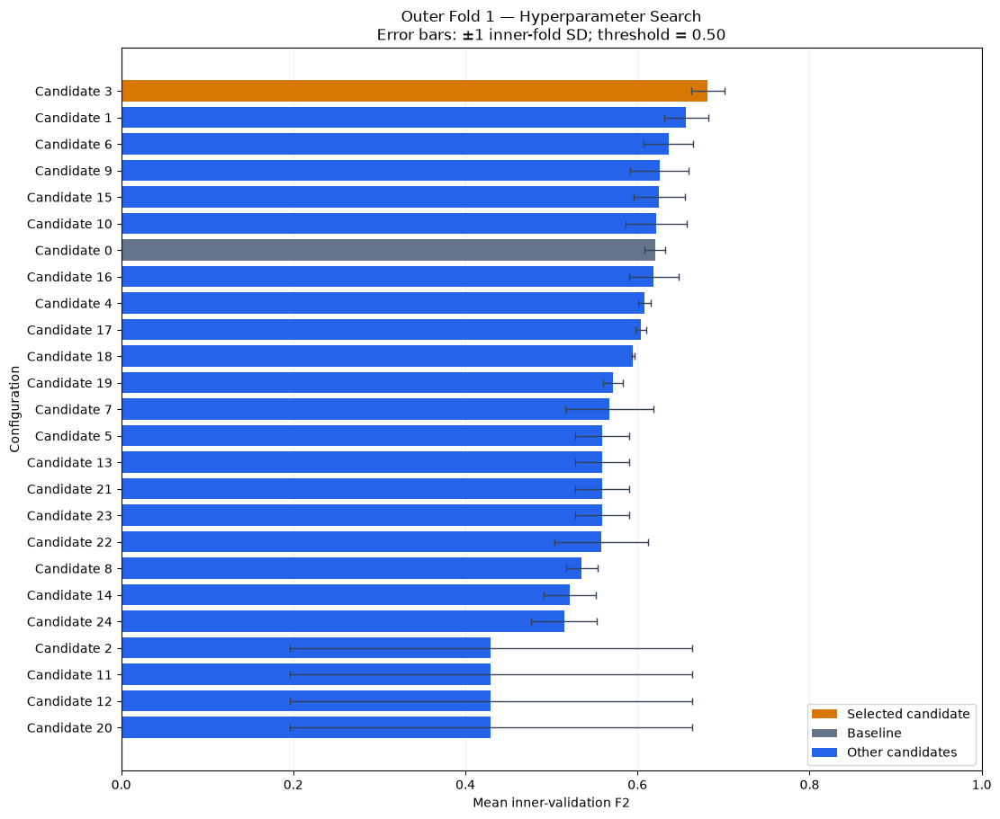

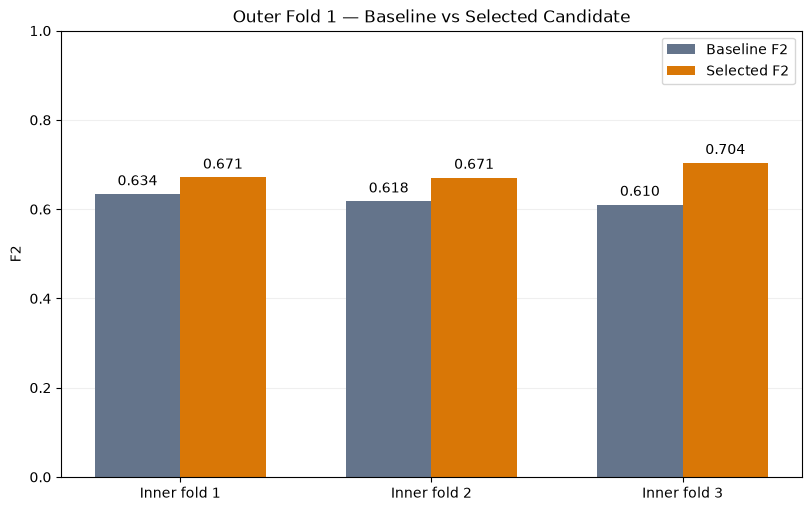

In [14]:
# Results already calculated by the completed search
dt_outer1_fold_results = dt_outer1_search["fold_results"]
dt_outer1_ranking = dt_outer1_search["ranking"]
dt_outer1_best_id = dt_outer1_search["best_candidate_id"]

# Verify that every candidate has three valid inner-fold results
assert len(dt_outer1_fold_results) == len(dt_candidates) * 3
assert not dt_outer1_fold_results.duplicated(
    ["candidate_id", "inner_fold"]
).any()

assert (
    dt_outer1_fold_results.groupby("candidate_id")["inner_fold"]
    .nunique()
    .eq(3)
    .all()
)

assert np.isfinite(dt_outer1_fold_results["F2"]).all()

# Compare the baseline and selected candidate within each inner fold
dt_outer1_selected_details = (
    dt_outer1_fold_results.loc[
        dt_outer1_fold_results["candidate_id"].isin(
            [0, dt_outer1_best_id]
        ),
        [
            "inner_fold", "candidate_id", "F2",
            "precision", "recall", "specificity", "IoU",
            "tree_depth", "n_leaves"
        ]
    ]
    .sort_values(["inner_fold", "candidate_id"])
)

print("Baseline and selected candidate — individual inner folds")
display(dt_outer1_selected_details.round(6))

# Paired F2 comparison: both models evaluated on the same patches
dt_outer1_f2_comparison = (
    dt_outer1_fold_results
    .pivot(index="inner_fold", columns="candidate_id", values="F2")
    [[0, dt_outer1_best_id]]
    .copy()
)

dt_outer1_f2_comparison.columns = [
    "Baseline F2",
    "Selected F2"
]

dt_outer1_f2_comparison["F2 difference"] = (
    dt_outer1_f2_comparison["Selected F2"]
    - dt_outer1_f2_comparison["Baseline F2"]
)

print("\nPaired F2 differences")
display(dt_outer1_f2_comparison.round(6))

# Plot 1: all candidates, ordered by mean inner-validation F2
plot_data = dt_outer1_ranking.copy()
positions = np.arange(len(plot_data))

colors = [
    "#D97706" if candidate_id == dt_outer1_best_id
    else "#64748B" if candidate_id == 0
    else "#2563EB"
    for candidate_id in plot_data["candidate_id"]
]

fig, ax = plt.subplots(
    figsize=(11, 9),
    constrained_layout=True
)

ax.barh(
    positions,
    plot_data["mean_inner_F2"],
    xerr=plot_data["sd_inner_F2"],
    color=colors,
    capsize=3,
    error_kw={"elinewidth": 1, "ecolor": "#334155"}
)

ax.set_yticks(
    positions,
    [f"Candidate {int(i)}" for i in plot_data["candidate_id"]]
)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Mean inner-validation F2")
ax.set_ylabel("Configuration")
ax.set_title(
    "Outer Fold 1 — Hyperparameter Search\n"
    "Error bars: ±1 inner-fold SD; threshold = 0.50"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor="#D97706", label="Selected candidate"),
        Patch(facecolor="#64748B", label="Baseline"),
        Patch(facecolor="#2563EB", label="Other candidates")
    ],
    loc="lower right"
)

plt.show()

# Plot 2: baseline versus selected candidate in each inner fold
fig, ax = plt.subplots(
    figsize=(8, 5),
    constrained_layout=True
)

x = np.arange(len(dt_outer1_f2_comparison))
width = 0.34

for offset, column, color in [
    (-width / 2, "Baseline F2", "#64748B"),
    (width / 2, "Selected F2", "#D97706")
]:
    bars = ax.bar(
        x + offset,
        dt_outer1_f2_comparison[column],
        width=width,
        label=column,
        color=color
    )
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)

ax.set_xticks(
    x,
    [
        f"Inner fold {i}"
        for i in dt_outer1_f2_comparison.index
    ]
)
ax.set_ylim(0, 1)
ax.set_ylabel("F2")
ax.set_title("Outer Fold 1 — Baseline vs Selected Candidate")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.show()

### Result — Fold-Level Search Diagnostics

Candidate 3 improved F2 over the baseline in all three inner folds:

- Inner fold 1: 0.6337 → 0.6711; difference = +0.0374.
- Inner fold 2: 0.6176 → 0.6706; difference = +0.0530.
- Inner fold 3: 0.6101 → 0.7037; difference = +0.0937.

The improvement was therefore observed across all three inner splits. Selected-candidate recall remained approximately 87%, while precision ranged from approximately 35% to 40%, indicating substantial false-positive predictions at threshold 0.50.

All three fitted trees reached depth 15, with 1,925, 1,931, and 1,867 leaves. Their structures differed because they were fitted on different training patches.

The ranking plot shows mean F2 with ±1 inner-fold standard deviation. These are descriptive error bars, not confidence intervals or significance tests.

These results support proceeding with candidate 3 within outer fold 1. They remain selection-stage diagnostics, not an independent assessment of generalization.

In [15]:
from sklearn.model_selection import train_test_split

# Saved patch-level information from the previous project
dt_presence_by_id = saved_variables["presence_by_id"].copy()
dt_presence_by_id.index = dt_presence_by_id.index.map(str)

assert dt_presence_by_id.index.is_unique

dt_outer1_calibration_splits = []
dt_calibration_split_rows = []

outer1_evaluation_ids = set(
    str(i) for i in nested_splits[0]["evaluation_ids"]
)
holdout_id_set = set(str(i) for i in test_ids)

for inner_number, inner in enumerate(
    nested_splits[0]["inner_splits"],
    start=1
):
    inner_train_ids = np.asarray(
        [str(i) for i in inner["train_ids"]]
    )
    inner_validation_ids = np.asarray(
        [str(i) for i in inner["validation_ids"]]
    )

    # Stratify by whether a training patch contains any landslide
    presence = dt_presence_by_id.reindex(inner_train_ids)

    if presence.isna().any():
        raise ValueError("Missing patch-presence information.")

    if not np.isfinite(presence.to_numpy(dtype=float)).all():
        raise ValueError("Invalid patch-presence values.")

    patch_strata = (presence.to_numpy() > 0).astype(int)

    # Verify that stratified splitting is possible
    _, stratum_counts = np.unique(
        patch_strata,
        return_counts=True
    )
    if stratum_counts.min() < 2:
        raise ValueError("Too few patches in a stratum for splitting.")

    fit_ids, calibration_ids = train_test_split(
        inner_train_ids,
        test_size=CALIBRATION_FRACTION,
        random_state=RANDOM_STATE,
        stratify=patch_strata
    )

    fit_set = set(fit_ids)
    calibration_set = set(calibration_ids)
    validation_set = set(inner_validation_ids)

    assert fit_set.isdisjoint(calibration_set)
    assert fit_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)
    assert fit_set | calibration_set == set(inner_train_ids)

    all_inner_ids = fit_set | calibration_set | validation_set

    assert all_inner_ids.isdisjoint(outer1_evaluation_ids)
    assert all_inner_ids.isdisjoint(holdout_id_set)

    dt_outer1_calibration_splits.append({
        "inner_fold": inner_number,
        "train_ids": inner_train_ids,
        "fit_ids": fit_ids,
        "calibration_ids": calibration_ids,
        "validation_ids": inner_validation_ids
    })

    dt_calibration_split_rows.append({
        "inner_fold": inner_number,
        "original_training_patches": len(inner_train_ids),
        "tree_fitting_patches": len(fit_ids),
        "calibration_patches": len(calibration_ids),
        "validation_patches": len(inner_validation_ids),
        "fit_calibration_overlap": len(
            fit_set & calibration_set
        )
    })

dt_outer1_calibration_split_table = pd.DataFrame(
    dt_calibration_split_rows
)

print("Calibration fraction:", CALIBRATION_FRACTION)
print("All patch-separation checks passed.")
display(dt_outer1_calibration_split_table)

Calibration fraction: 0.2
All patch-separation checks passed.


,inner_fold,original_training_patches,tree_fitting_patches,calibration_patches,validation_patches,fit_calibration_overlap
0,1,1620,1296,324,811,0
1,2,1621,1296,325,810,0
2,3,1621,1296,325,810,0


### Result — Calibration Split Preparation

The calibration splits were successfully prepared for all three inner folds of outer fold 1, using the saved calibration fraction of 20%.

- Inner fold 1: 1,296 tree-fitting patches, 324 calibration patches, and 811 validation patches.
- Inner fold 2: 1,296 tree-fitting patches, 325 calibration patches, and 810 validation patches.
- Inner fold 3: 1,296 tree-fitting patches, 325 calibration patches, and 810 validation patches.

The one-patch differences reflect the original fold sizes and integer rounding during splitting.

All patch-separation checks passed. Tree-fitting and calibration subsets have zero overlap, and neither overlaps the corresponding inner-validation patches. Outer-evaluation and holdout patches remain excluded.

The split was stratified by patch-level landslide presence. No additional trees or calibrators have been fitted at this stage.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression


def collect_dt_calibration_pixels(model, patch_ids):
    """Collect predictions and labels from full calibration patches."""
    probability_parts = []
    label_parts = []

    positive_column = int(np.flatnonzero(model.classes_ == 1)[0])

    for patch_id in patch_ids:
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")
        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid labels: {patch_id}")

        probability_parts.append(
            model.predict_proba(
                image.reshape(-1, len(FEATURE_NAMES))
            )[:, positive_column]
        )
        label_parts.append(mask.reshape(-1).astype(np.uint8))

    return (
        np.concatenate(probability_parts),
        np.concatenate(label_parts)
    )


def fit_dt_probability_options(split, params):
    """Fit the uncalibrated and calibrated pipeline options."""
    start = perf_counter()

    # Option 1: no calibration; all inner-training patches
    X_train, y_train = get_sampled_pixels(
        split["train_ids"], DT_PIXELS_PER_PATCH
    )

    uncalibrated_tree = DecisionTreeClassifier(
        **params,
        random_state=RANDOM_STATE
    )
    uncalibrated_tree.fit(X_train, y_train)
    del X_train, y_train

    print("Uncalibrated tree fitted.", flush=True)

    # Options 2–3: reserve separate patches for calibration
    X_fit, y_fit = get_sampled_pixels(
        split["fit_ids"], DT_PIXELS_PER_PATCH
    )

    calibration_base_tree = DecisionTreeClassifier(
        **params,
        random_state=RANDOM_STATE
    )
    calibration_base_tree.fit(X_fit, y_fit)
    del X_fit, y_fit

    print("Calibration-base tree fitted.", flush=True)

    p_cal, y_cal = collect_dt_calibration_pixels(
        calibration_base_tree,
        split["calibration_ids"]
    )

    if np.unique(y_cal).size != 2:
        raise ValueError("Calibration data must contain both classes.")

    # Sigmoid mapping of raw tree probability to calibrated probability
    sigmoid_calibrator = LogisticRegression(
        C=PLATT_C,
        solver="lbfgs",
        max_iter=1000,
        class_weight=None,
        random_state=RANDOM_STATE
    )
    sigmoid_calibrator.fit(p_cal.reshape(-1, 1), y_cal)

    # Non-decreasing piecewise mapping
    isotonic_calibrator = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
        y_min=0.0,
        y_max=1.0
    )
    isotonic_calibrator.fit(p_cal, y_cal)

    summary = {
        "inner_fold": split["inner_fold"],
        "uncalibrated_training_patches": len(split["train_ids"]),
        "calibrated_tree_training_patches": len(split["fit_ids"]),
        "calibration_patches": len(split["calibration_ids"]),
        "calibration_pixels": len(y_cal),
        "calibration_landslide_pixels": int(y_cal.sum()),
        "calibration_landslide_fraction": float(y_cal.mean()),
        "sigmoid_iterations": int(sigmoid_calibrator.n_iter_[0]),
        "fit_seconds": perf_counter() - start
    }

    return {
        "uncalibrated_tree": uncalibrated_tree,
        "calibration_base_tree": calibration_base_tree,
        "sigmoid": sigmoid_calibrator,
        "isotonic": isotonic_calibrator,
        "summary": summary
    }


# Fit only inner fold 1 at this stage
dt_outer1_inner1_probability_options = fit_dt_probability_options(
    split=dt_outer1_calibration_splits[0],
    params=dt_outer1_search["best_params"]
)

display(pd.DataFrame([
    dt_outer1_inner1_probability_options["summary"]
]).T.rename(columns={0: "Value"}))

Uncalibrated tree fitted.
Calibration-base tree fitted.


,Value
inner_fold,1.000000e+00
uncalibrated_training_patches,1.620000e+03
calibrated_tree_training_patches,1.296000e+03
calibration_patches,3.240000e+02
calibration_pixels,5.308416e+06
calibration_landslide_pixels,1.353870e+05
calibration_landslide_fraction,2.550422e-02
sigmoid_iterations,1.200000e+01
fit_seconds,1.250814e+01


In [17]:
dt_iso = dt_outer1_inner1_probability_options["isotonic"]

print("Isotonic calibrator:", type(dt_iso).__name__)
print("Number of fitted mapping points:", len(dt_iso.X_thresholds_))
print(
    "Observed raw-probability range:",
    f"{dt_iso.X_min_:.6f} to {dt_iso.X_max_:.6f}"
)

dt_isotonic_mapping_table = pd.DataFrame({
    "Raw tree probability": dt_iso.X_thresholds_,
    "Isotonic calibrated probability": dt_iso.y_thresholds_
})

display(dt_isotonic_mapping_table)

Isotonic calibrator: IsotonicRegression
Number of fitted mapping points: 61
Observed raw-probability range: 0.000000 to 1.000000


,Raw tree probability,Isotonic calibrated probability
0,0.000000,0.003718
1,0.144777,0.003718
2,0.255994,0.019509
3,0.443986,0.019509
4,0.461747,0.024415
...,...,...
56,0.997643,0.888246
57,0.997857,0.888246
58,0.998165,0.903123
59,0.998565,0.926206


### Result — Probability-Model Fitting: Inner Fold 1

The uncalibrated Decision Tree was fitted using 1,620 inner-training patches. A separate calibration-base tree was fitted using 1,296 patches, reserving 324 disjoint patches for calibration.

Sigmoid and isotonic calibrators were fitted using all 5,308,416 pixels from the calibration patches. These included 135,387 landslide pixels, corresponding to a landslide prevalence of approximately 2.55%.

The sigmoid calibrator required 12 optimization iterations. Total fitting and calibration-data collection time was approximately 12.51 seconds.

The uncalibrated pipeline and the two calibrated pipelines are now fitted for inner fold 1. Their validation performance has not yet been measured, and no calibration method or threshold has been selected.
### Result — Isotonic Calibration Mapping

The fitted isotonic calibrator contains 61 mapping points spanning raw tree probabilities from 0 to 1.

For example, raw probabilities of 0 and 1 map to approximately 0.0037 and 0.9262, respectively. The non-decreasing mapping was learned from the separate calibration patches.

These values describe the fitted calibration mapping. They do not yet demonstrate improved probability quality or classification performance; that requires evaluation on the inner-validation patches.

In [18]:
def evaluate_dt_probability_options(options, patch_ids, threshold=0.50):
    method_names = [
        "Uncalibrated — all training patches",
        "Raw calibration-base tree — diagnostic",
        "Sigmoid",
        "Isotonic"
    ]

    totals = {
        name: {
            "counts": np.zeros(4, dtype=np.int64),
            "squared_error_sum": 0.0,
            "log_loss_sum": 0.0,
            "pixels": 0
        }
        for name in method_names
    }

    full_tree = options["uncalibrated_tree"]
    calibration_tree = options["calibration_base_tree"]

    full_positive_col = int(
        np.flatnonzero(full_tree.classes_ == 1)[0]
    )
    calibration_positive_col = int(
        np.flatnonzero(calibration_tree.classes_ == 1)[0]
    )

    # Explicit float64 clipping for numerical stability in log loss
    epsilon = np.finfo(np.float64).eps

    for patch_id in patch_ids:
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")
        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid labels: {patch_id}")

        X_full = image.reshape(-1, len(FEATURE_NAMES))
        y_full = mask.reshape(-1).astype(np.uint8)

        p_uncalibrated = full_tree.predict_proba(X_full)[
            :, full_positive_col
        ]
        p_raw = calibration_tree.predict_proba(X_full)[
            :, calibration_positive_col
        ]

        sigmoid_positive_col = int(
            np.flatnonzero(options["sigmoid"].classes_ == 1)[0]
        )

        probabilities = {
            method_names[0]: p_uncalibrated,
            method_names[1]: p_raw,
            method_names[2]: options["sigmoid"].predict_proba(
                p_raw.reshape(-1, 1)
            )[:, sigmoid_positive_col],
            method_names[3]: options["isotonic"].predict(p_raw)
        }

        for name, probability in probabilities.items():
            p = np.asarray(probability, dtype=np.float64)

            if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
                raise ValueError(f"Invalid probabilities: {name}")

            prediction = (p >= threshold).astype(np.uint8)

            totals[name]["counts"] += np.bincount(
                2 * y_full + prediction,
                minlength=4
            )

            totals[name]["squared_error_sum"] += float(
                np.square(p - y_full).sum()
            )

            p_clipped = np.clip(p, epsilon, 1 - epsilon)

            totals[name]["log_loss_sum"] += float(
                -(
                    y_full * np.log(p_clipped)
                    + (1 - y_full) * np.log1p(-p_clipped)
                ).sum()
            )
            totals[name]["pixels"] += len(y_full)

    rows = []

    for name, values in totals.items():
        tn, fp, fn, tp = values["counts"]
        n = values["pixels"]

        rows.append({
            "Method": name,
            "Threshold": threshold,
            "Pixels": n,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "F2": dt_safe_ratio(5 * tp, 5 * tp + 4 * fn + fp),
            "Precision": dt_safe_ratio(tp, tp + fp),
            "Recall": dt_safe_ratio(tp, tp + fn),
            "Specificity": dt_safe_ratio(tn, tn + fp),
            "IoU": dt_safe_ratio(tp, tp + fp + fn),
            "Brier": values["squared_error_sum"] / n,
            "Log loss": values["log_loss_sum"] / n
        })

    return pd.DataFrame(rows).set_index("Method")


start_time = perf_counter()

dt_outer1_inner1_probability_scores = evaluate_dt_probability_options(
    options=dt_outer1_inner1_probability_options,
    patch_ids=dt_outer1_calibration_splits[0]["validation_ids"],
    threshold=DT_BASELINE_THRESHOLD
)

print(f"Evaluation time: {perf_counter() - start_time:.2f} seconds")

print("\nCLASSIFICATION METRICS")
display(
    dt_outer1_inner1_probability_scores[
        ["Threshold", "F2", "Precision", "Recall", "Specificity", "IoU"]
    ].round(6)
)

print("\nPROBABILITY QUALITY — LOWER IS BETTER")
display(
    dt_outer1_inner1_probability_scores[
        ["Brier", "Log loss"]
    ].round(6)
)

print("\nPIXEL COUNTS")
display(
    dt_outer1_inner1_probability_scores[
        ["Pixels", "TN", "FP", "FN", "TP"]
    ]
)

Evaluation time: 4.17 seconds

CLASSIFICATION METRICS


,Threshold,F2,Precision,Recall,Specificity,IoU
Method,,,,,,
Uncalibrated — all training patches,0.5,0.671099,0.352803,0.866548,0.962690,0.334622
Raw calibration-base tree — diagnostic,0.5,0.673340,0.364252,0.854642,0.964990,0.343003
Sigmoid,0.5,0.596803,0.718547,0.572551,0.994736,0.467668
Isotonic,0.5,0.595456,0.720317,0.570723,0.994799,0.467193



PROBABILITY QUALITY — LOWER IS BETTER


,Brier,Log loss
Method,,
Uncalibrated — all training patches,0.032482,0.210581
Raw calibration-base tree — diagnostic,0.032023,0.220720
Sigmoid,0.014167,0.053798
Isotonic,0.011567,0.047463



PIXEL COUNTS


,Pixels,TN,FP,FN,TP
Method,,,,,
Uncalibrated — all training patches,13287424,12498318,484389,40665,264052
Raw calibration-base tree — diagnostic,13287424,12528176,454531,44293,260424
Sigmoid,13287424,12914369,68338,130251,174466
Isotonic,13287424,12915182,67525,130808,173909


### Result — Probability and Classification Evaluation: Inner Fold 1

All four outputs were evaluated on the same 13,287,424 pixels from 811 inner-validation patches. Evaluation took 4.17 seconds.

Both calibration methods improved probability scores relative to their shared raw calibration-base tree:

| Output | Brier score | Log loss |
|---|---:|---:|
| Uncalibrated tree — all training patches | 0.032482 | 0.210581 |
| Raw calibration-base tree — diagnostic | 0.032023 | 0.220720 |
| Sigmoid | 0.014167 | 0.053798 |
| Isotonic | 0.011567 | 0.047463 |

Isotonic achieved the lowest Brier score and log loss in this split.

At threshold 0.50, F2 was 0.6711 for the uncalibrated full-training tree, 0.6733 for the raw calibration-base tree, 0.5968 for sigmoid, and 0.5955 for isotonic.

Calibration increased precision and reduced false positives, but also reduced recall at this fixed threshold. For isotonic, false positives decreased from 454,531 to 67,525, while false negatives increased from 44,293 to 130,808 relative to the same raw base tree.

Improved probability scores do not guarantee improved F2 at an unchanged threshold. Calibration-method and threshold selection remain pending and must use all three inner folds. No outer-evaluation or holdout patches were used.

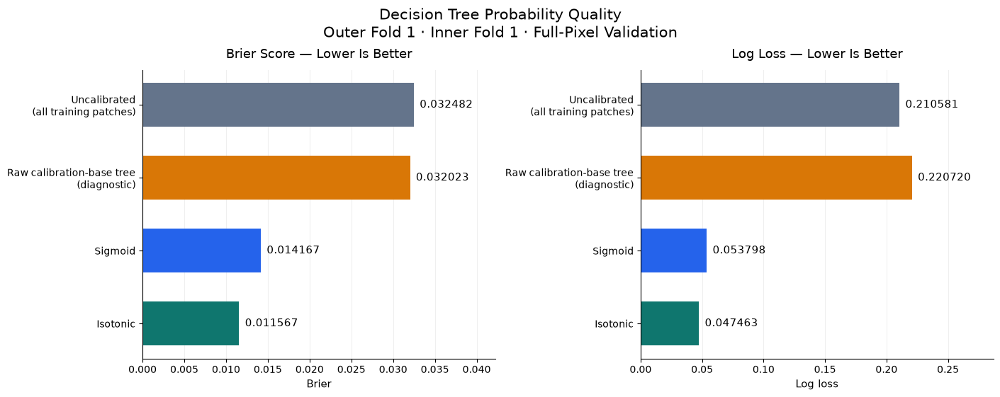

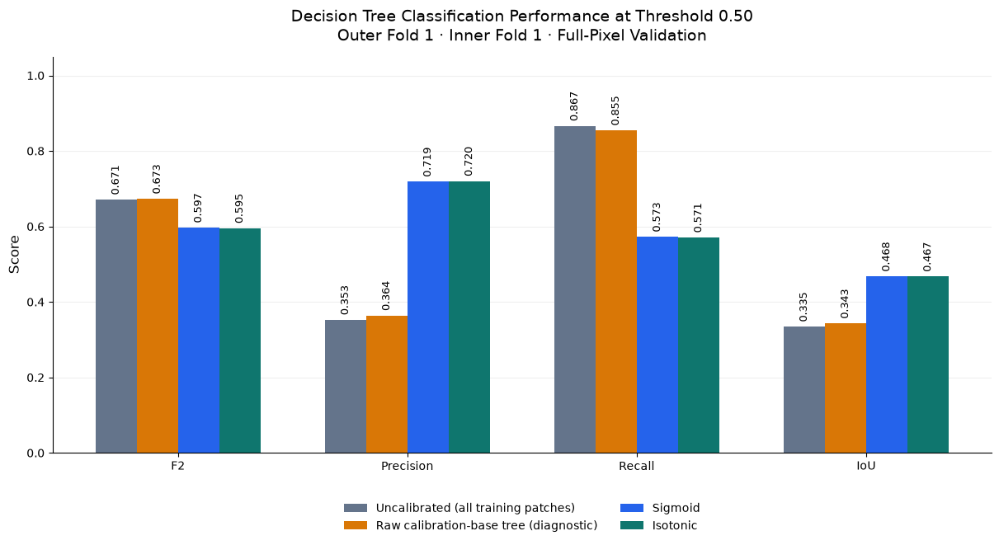

In [19]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Existing evaluation results, kept in their original order
dt_plot_scores = dt_outer1_inner1_probability_scores.copy()

plot_labels = [
    "Uncalibrated\n(all training patches)",
    "Raw calibration-base tree\n(diagnostic)",
    "Sigmoid",
    "Isotonic"
]

plot_colors = [
    "#64748B",  # Full-training uncalibrated tree
    "#D97706",  # Raw calibration-base tree
    "#2563EB",  # Sigmoid
    "#0F766E"   # Isotonic
]

# FIGURE 1: Probability quality
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    constrained_layout=True
)

for ax, metric, title in zip(
    axes,
    ["Brier", "Log loss"],
    ["Brier Score — Lower Is Better", "Log Loss — Lower Is Better"]
):
    values = dt_plot_scores[metric].to_numpy()
    y_positions = np.arange(len(values))

    bars = ax.barh(
        y_positions,
        values,
        color=plot_colors,
        height=0.6
    )

    ax.set_yticks(y_positions, plot_labels)
    ax.invert_yaxis()
    ax.set_xlim(0, max(values) * 1.30)

    ax.bar_label(
        bars,
        labels=[f"{value:.6f}" for value in values],
        padding=6,
        fontsize=11
    )

    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(title, fontsize=13, pad=12)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", labelsize=10)

fig.suptitle(
    "Decision Tree Probability Quality\n"
    "Outer Fold 1 · Inner Fold 1 · Full-Pixel Validation",
    fontsize=15
)

plt.show()


# FIGURE 2: Classification metrics at the same fixed threshold
classification_metrics = ["F2", "Precision", "Recall", "IoU"]
x_positions = np.arange(len(classification_metrics))
bar_width = 0.18

fig, ax = plt.subplots(
    figsize=(12, 6.5),
    constrained_layout=True
)

for method_index in range(len(dt_plot_scores)):
    values = dt_plot_scores.iloc[method_index][
        classification_metrics
    ].to_numpy(dtype=float)

    offset = (method_index - 1.5) * bar_width

    bars = ax.bar(
        x_positions + offset,
        values,
        width=bar_width,
        color=plot_colors[method_index]
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=4,
        fontsize=9,
        rotation=90
    )

ax.set_xticks(x_positions, classification_metrics)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score", fontsize=12)
ax.set_title(
    "Decision Tree Classification Performance at Threshold 0.50\n"
    "Outer Fold 1 · Inner Fold 1 · Full-Pixel Validation",
    fontsize=14,
    pad=14
)

ax.legend(
    handles=[
        Patch(
            facecolor=color,
            label=label.replace("\n", " ")
        )
        for color, label in zip(plot_colors, plot_labels)
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False,
    fontsize=10
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

### Result — Calibration Comparison Plots

The probability-score plots show that both calibration methods improved Brier score and log loss relative to their shared raw calibration-base tree. Isotonic achieved the lowest values: Brier = 0.011567 and log loss = 0.047463.

At threshold 0.50, both calibrated methods increased precision and IoU but reduced recall and F2. This illustrates that better probability scores do not necessarily produce better classification performance at an unchanged threshold.

The raw calibration-base tree provides a same-tree reference for assessing calibration effects. The separate uncalibrated pipeline uses more training patches.

These figures describe inner fold 1 only. Calibration-method and threshold selection require results from all three inner folds.

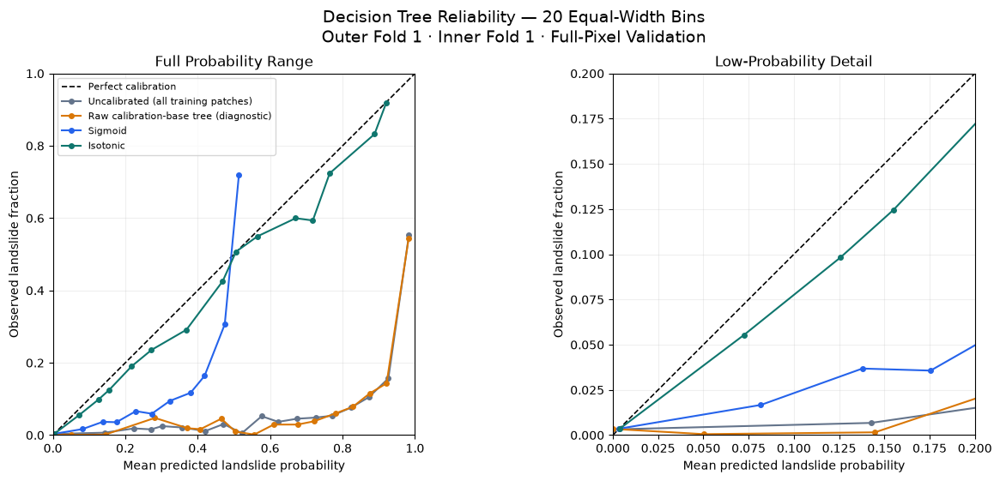

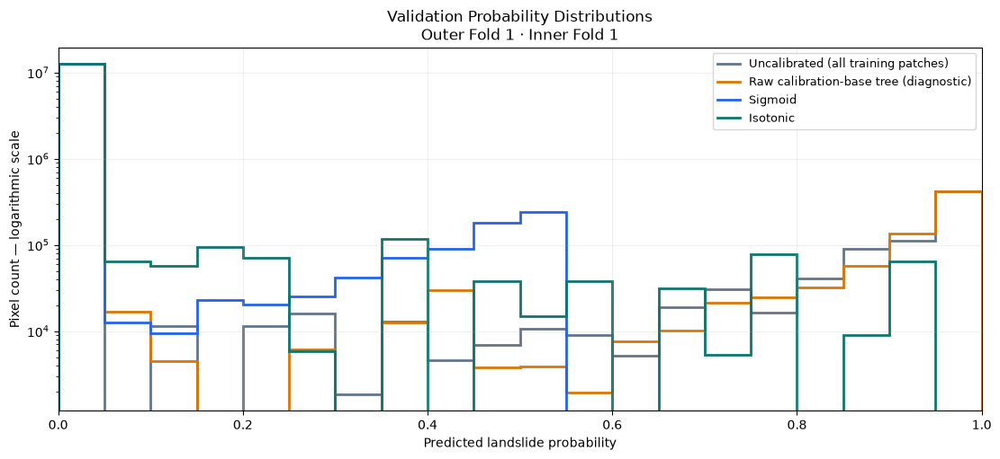

,Pixels,Nonempty bins,ECE — 20 equal-width bins
Method,,,
Uncalibrated — all training patches,13287424,18,0.035948
Raw calibration-base tree — diagnostic,13287424,17,0.035102
Sigmoid,13287424,11,0.011125
Isotonic,13287424,15,0.002203


In [20]:
DT_RELIABILITY_BINS = 20
dt_reliability_edges = np.linspace(
    0, 1, DT_RELIABILITY_BINS + 1
)

dt_method_names = list(
    dt_outer1_inner1_probability_scores.index
)

dt_reliability_totals = {
    name: {
        "count": np.zeros(DT_RELIABILITY_BINS, dtype=np.int64),
        "probability_sum": np.zeros(DT_RELIABILITY_BINS),
        "positive_sum": np.zeros(DT_RELIABILITY_BINS)
    }
    for name in dt_method_names
}

options = dt_outer1_inner1_probability_options
full_tree = options["uncalibrated_tree"]
calibration_tree = options["calibration_base_tree"]

full_col = int(np.flatnonzero(full_tree.classes_ == 1)[0])
base_col = int(np.flatnonzero(calibration_tree.classes_ == 1)[0])
sigmoid_col = int(
    np.flatnonzero(options["sigmoid"].classes_ == 1)[0]
)

for patch_id in dt_outer1_calibration_splits[0]["validation_ids"]:
    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
    )

    with h5py.File(image_path, "r") as file:
        image = np.asarray(file["img"], dtype=np.float32)

    with h5py.File(mask_path, "r") as file:
        mask = np.asarray(file["mask"])

    if image.shape != (128, 128, len(FEATURE_NAMES)):
        raise ValueError(f"Unexpected image shape: {patch_id}")
    if mask.shape != (128, 128):
        raise ValueError(f"Unexpected mask shape: {patch_id}")
    if not np.isfinite(image).all():
        raise ValueError(f"Invalid features: {patch_id}")
    if not np.isin(mask, [0, 1]).all():
        raise ValueError(f"Invalid mask: {patch_id}")

    X_full = image.reshape(-1, len(FEATURE_NAMES))
    y_full = mask.reshape(-1).astype(np.uint8)

    raw_probability = calibration_tree.predict_proba(X_full)[:, base_col]

    probability_outputs = [
        full_tree.predict_proba(X_full)[:, full_col],
        raw_probability,
        options["sigmoid"].predict_proba(
            raw_probability.reshape(-1, 1)
        )[:, sigmoid_col],
        options["isotonic"].predict(raw_probability)
    ]

    for name, probability in zip(
        dt_method_names, probability_outputs
    ):
        p = np.asarray(probability, dtype=np.float64)

        if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
            raise ValueError(f"Invalid probabilities: {name}")

        # Bins are [left, right), with probability 1 in the last bin
        bin_ids = np.minimum(
            np.searchsorted(
                dt_reliability_edges, p, side="right"
            ) - 1,
            DT_RELIABILITY_BINS - 1
        )

        totals = dt_reliability_totals[name]

        totals["count"] += np.bincount(
            bin_ids, minlength=DT_RELIABILITY_BINS
        )
        totals["probability_sum"] += np.bincount(
            bin_ids, weights=p, minlength=DT_RELIABILITY_BINS
        )
        totals["positive_sum"] += np.bincount(
            bin_ids, weights=y_full, minlength=DT_RELIABILITY_BINS
        )

# Preserve bin-level tables for later interpretation
dt_inner1_reliability_tables = {}
dt_inner1_ece_rows = []

for name, totals in dt_reliability_totals.items():
    counts = totals["count"]
    nonempty = counts > 0

    mean_probability = np.divide(
        totals["probability_sum"],
        counts,
        out=np.full(DT_RELIABILITY_BINS, np.nan),
        where=nonempty
    )
    observed_fraction = np.divide(
        totals["positive_sum"],
        counts,
        out=np.full(DT_RELIABILITY_BINS, np.nan),
        where=nonempty
    )

    dt_inner1_reliability_tables[name] = pd.DataFrame({
        "bin_left": dt_reliability_edges[:-1],
        "bin_right": dt_reliability_edges[1:],
        "pixels": counts,
        "mean_probability": mean_probability,
        "observed_landslide_fraction": observed_fraction
    })

    expected_pixels = int(
        dt_outer1_inner1_probability_scores.loc[name, "Pixels"]
    )
    assert counts.sum() == expected_pixels

    ece = np.sum(
        counts[nonempty] / counts.sum()
        * np.abs(
            mean_probability[nonempty]
            - observed_fraction[nonempty]
        )
    )

    dt_inner1_ece_rows.append({
        "Method": name,
        "Pixels": int(counts.sum()),
        "Nonempty bins": int(nonempty.sum()),
        "ECE — 20 equal-width bins": float(ece)
    })

# FIGURE 1: Reliability diagrams
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    constrained_layout=True
)

for ax, limit, title in zip(
    axes,
    [1.0, 0.20],
    ["Full Probability Range", "Low-Probability Detail"]
):
    ax.plot(
        [0, limit], [0, limit],
        linestyle="--", color="black",
        linewidth=1.2, label="Perfect calibration"
    )

    for name, label, color in zip(
        dt_method_names, plot_labels, plot_colors
    ):
        table = dt_inner1_reliability_tables[name]
        valid = table["pixels"] > 0

        ax.plot(
            table.loc[valid, "mean_probability"],
            table.loc[valid, "observed_landslide_fraction"],
            marker="o",
            markersize=4,
            linewidth=1.5,
            color=color,
            label=label.replace("\n", " ")
        )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_xlabel("Mean predicted landslide probability")
    ax.set_ylabel("Observed landslide fraction")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.set_aspect("equal", adjustable="box")

axes[0].legend(fontsize=8, loc="upper left")

fig.suptitle(
    "Decision Tree Reliability — 20 Equal-Width Bins\n"
    "Outer Fold 1 · Inner Fold 1 · Full-Pixel Validation",
    fontsize=14
)

plt.show()

# FIGURE 2: Probability distribution
fig, ax = plt.subplots(
    figsize=(11, 5),
    constrained_layout=True
)

for name, label, color in zip(
    dt_method_names, plot_labels, plot_colors
):
    # Empty bins are omitted on the logarithmic count axis
    counts = dt_reliability_totals[name]["count"].astype(float)
    counts[counts == 0] = np.nan

    ax.stairs(
        counts,
        dt_reliability_edges,
        color=color,
        linewidth=2,
        label=label.replace("\n", " ")
    )

ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted landslide probability")
ax.set_ylabel("Pixel count — logarithmic scale")
ax.set_title(
    "Validation Probability Distributions\n"
    "Outer Fold 1 · Inner Fold 1"
)
ax.legend(fontsize=9)
ax.grid(alpha=0.2, which="major")

plt.show()

dt_inner1_ece_table = pd.DataFrame(
    dt_inner1_ece_rows
).set_index("Method")

display(dt_inner1_ece_table.round(6))

### Result — Reliability and Probability Distributions

Reliability was assessed on the same 13,287,424 inner-validation pixels using 20 equal-width probability bins.

The raw tree outputs generally overestimated landslide probabilities in many bins. Sigmoid calibration reduced this discrepancy, while isotonic tracked the ideal calibration line more closely across much of the probability range.

The descriptive binned ECE values were:

- Uncalibrated full-training tree: 0.035948.
- Raw calibration-base tree: 0.035102.
- Sigmoid: 0.011125.
- Isotonic: 0.002203.

The probability distributions show a large concentration of pixels in the lowest probability bin. Consequently, the weighted ECE is strongly influenced by low-probability pixels. It is bin-dependent and is not a classification accuracy measure.

The low-probability panel is a zoom of the same bin-level results. Connecting lines are visual guides, not exact calibration mappings or confidence intervals.

Together with the previously observed Brier and log-loss scores, these diagnostics support improved probability calibration, particularly for isotonic, in inner fold 1. They do not yet establish the final calibration method or classification threshold.

In [21]:
# Preserve the completed work for inner fold 1
if "dt_outer1_probability_options_by_inner" not in globals():
    dt_outer1_probability_options_by_inner = {
        1: dt_outer1_inner1_probability_options
    }

if "dt_outer1_probability_scores_by_inner" not in globals():
    dt_outer1_probability_scores_by_inner = {
        1: dt_outer1_inner1_probability_scores
    }

# Complete inner folds 2 and 3
for split in dt_outer1_calibration_splits[1:]:
    inner_number = split["inner_fold"]

    print(
        f"\nINNER FOLD {inner_number}/3",
        flush=True
    )

    if inner_number not in dt_outer1_probability_options_by_inner:
        dt_outer1_probability_options_by_inner[inner_number] = (
            fit_dt_probability_options(
                split=split,
                params=dt_outer1_search["best_params"]
            )
        )
    else:
        print("Using previously fitted models.", flush=True)

    if inner_number not in dt_outer1_probability_scores_by_inner:
        print("Evaluating full validation patches...", flush=True)

        dt_outer1_probability_scores_by_inner[inner_number] = (
            evaluate_dt_probability_options(
                options=dt_outer1_probability_options_by_inner[
                    inner_number
                ],
                patch_ids=split["validation_ids"],
                threshold=DT_BASELINE_THRESHOLD
            )
        )
    else:
        print("Using previously computed scores.", flush=True)

    print(f"Inner fold {inner_number} completed.", flush=True)

# Combine results without replacing earlier tables
dt_outer1_probability_all_folds = pd.concat(
    [
        scores.reset_index().assign(inner_fold=inner_number)
        for inner_number, scores in sorted(
            dt_outer1_probability_scores_by_inner.items()
        )
    ],
    ignore_index=True
)

assert set(
    dt_outer1_probability_all_folds["inner_fold"]
) == {1, 2, 3}

assert not dt_outer1_probability_all_folds.duplicated(
    ["inner_fold", "Method"]
).any()

assert (
    dt_outer1_probability_all_folds
    .groupby("Method")["inner_fold"]
    .nunique()
    .eq(3)
    .all()
)

# Actual calibration fitting details for all three inner folds
dt_outer1_calibration_fit_summary = pd.DataFrame([
    dt_outer1_probability_options_by_inner[i]["summary"]
    for i in [1, 2, 3]
])

print("\nCALIBRATION FITTING DETAILS")
display(dt_outer1_calibration_fit_summary.round(6))

print("\nINDIVIDUAL INNER-FOLD VALIDATION SCORES")
display(
    dt_outer1_probability_all_folds[
        [
            "inner_fold", "Method", "F2",
            "Precision", "Recall", "Brier", "Log loss"
        ]
    ].round(6)
)

# Simple mean across inner folds — not pooled-pixel metrics
dt_outer1_probability_mean_scores = (
    dt_outer1_probability_all_folds
    .groupby("Method", sort=False)
    .agg(
        mean_F2=("F2", "mean"),
        sd_F2=("F2", "std"),
        mean_precision=("Precision", "mean"),
        mean_recall=("Recall", "mean"),
        mean_specificity=("Specificity", "mean"),
        mean_IoU=("IoU", "mean"),
        mean_Brier=("Brier", "mean"),
        mean_log_loss=("Log loss", "mean")
    )
)

print("\nMEAN INNER-VALIDATION SCORES — THRESHOLD 0.50")
display(dt_outer1_probability_mean_scores.round(6))


INNER FOLD 2/3
Uncalibrated tree fitted.
Calibration-base tree fitted.
Evaluating full validation patches...
Inner fold 2 completed.

INNER FOLD 3/3
Uncalibrated tree fitted.
Calibration-base tree fitted.
Evaluating full validation patches...
Inner fold 3 completed.

CALIBRATION FITTING DETAILS


,inner_fold,uncalibrated_training_patches,calibrated_tree_training_patches,calibration_patches,calibration_pixels,calibration_landslide_pixels,calibration_landslide_fraction,sigmoid_iterations,fit_seconds
0,1,1620,1296,324,5308416,135387,0.025504,12,12.508140
1,2,1621,1296,325,5324800,129048,0.024235,12,12.771604
2,3,1621,1296,325,5324800,117227,0.022015,12,96.069263



INDIVIDUAL INNER-FOLD VALIDATION SCORES


,inner_fold,Method,F2,Precision,Recall,Brier,Log loss
0,1,Uncalibrated — all training patches,0.671099,0.352803,0.866548,0.032482,0.210581
1,1,Raw calibration-base tree — diagnostic,0.673340,0.364252,0.854642,0.032023,0.220720
2,1,Sigmoid,0.596803,0.718547,0.572551,0.014167,0.053798
3,1,Isotonic,0.595456,0.720317,0.570723,0.011567,0.047463
4,2,Uncalibrated — all training patches,0.670613,0.348489,0.872156,0.030474,0.193972
5,2,Raw calibration-base tree — diagnostic,0.659851,0.350089,0.847270,0.030330,0.214286
6,2,Sigmoid,0.000000,NaN,0.000000,0.013211,0.050821
7,2,Isotonic,0.569476,0.709323,0.542726,0.011190,0.046093
8,3,Uncalibrated — all training patches,0.703728,0.399277,0.869472,0.030124,0.212356
9,3,Raw calibration-base tree — diagnostic,0.701143,0.418019,0.844064,0.028918,0.232329



MEAN INNER-VALIDATION SCORES — THRESHOLD 0.50


,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_Brier,mean_log_loss
Method,,,,,,,,
Uncalibrated — all training patches,0.681813,0.018980,0.366856,0.869392,0.964311,0.347624,0.031027,0.205637
Raw calibration-base tree — diagnostic,0.678111,0.021055,0.377453,0.848658,0.966667,0.353453,0.030424,0.222445
Sigmoid,0.198934,0.344564,0.718547,0.190850,0.998245,0.155889,0.014051,0.053959
Isotonic,0.593018,0.022422,0.729554,0.566532,0.995027,0.468453,0.011628,0.048160


### Result — Probability Evaluation Across Three Inner Folds

Isotonic achieved the lowest Brier score and log loss in every inner fold. Its mean Brier score was 0.011628 and mean log loss was 0.048160, compared with 0.014051 and 0.053959 for sigmoid.

At threshold 0.50, mean F2 was 0.6818 for the uncalibrated full-training pipeline, 0.6781 for the raw calibration-base diagnostic, 0.1989 for sigmoid, and 0.5930 for isotonic.

Sigmoid produced no positive predictions in inner folds 2 and 3 at this threshold. Precision was therefore undefined in those folds. The original mean-precision calculation omitted these undefined values, so its displayed sigmoid value represents fold 1 only, not all three folds.

The sigmoid mappings require inspection before proceeding to threshold selection. No final calibration method or threshold has been selected.

In [22]:
# Inspect each fitted sigmoid over the full possible raw-probability range
dt_sigmoid_diagnostic_rows = []

for inner_number, options in sorted(
    dt_outer1_probability_options_by_inner.items()
):
    calibrator = options["sigmoid"]

    positive_column = int(
        np.flatnonzero(calibrator.classes_ == 1)[0]
    )

    endpoint_probabilities = calibrator.predict_proba(
        np.array([[0.0], [1.0]])
    )[:, positive_column]

    slope = float(calibrator.coef_[0, 0])
    intercept = float(calibrator.intercept_[0])

    raw_probability_at_half = (
        -intercept / slope if slope != 0 else np.nan
    )

    dt_sigmoid_diagnostic_rows.append({
        "inner_fold": inner_number,
        "sigmoid_slope": slope,
        "sigmoid_intercept": intercept,
        "calibrated_p_at_raw_0": endpoint_probabilities[0],
        "calibrated_p_at_raw_1": endpoint_probabilities[1],
        "maximum_over_raw_0_to_1": endpoint_probabilities.max(),
        "raw_p_needed_for_calibrated_0.50": raw_probability_at_half
    })

dt_sigmoid_diagnostics = pd.DataFrame(
    dt_sigmoid_diagnostic_rows
)

print("SIGMOID MAPPING DIAGNOSTICS")
display(dt_sigmoid_diagnostics.round(6))

# Preserve undefined per-fold precision values in the original results
precision_summary = (
    dt_outer1_probability_all_folds
    .groupby("Method", sort=False)
    .agg(
        total_folds=("inner_fold", "nunique"),
        folds_with_defined_precision=("Precision", "count")
    )
)

# Explicit alternative reporting convention:
# precision = 0 when there are no predicted positives
precision_zero_convention = (
    dt_outer1_probability_all_folds
    .assign(
        precision_zero_convention=lambda table:
            table["Precision"].fillna(0.0)
    )
    .groupby("Method", sort=False)["precision_zero_convention"]
    .mean()
)

precision_summary["mean_precision_zero_if_no_positive"] = (
    precision_zero_convention
)

print("\nPRECISION REPORTING CHECK")
display(precision_summary.round(6))

SIGMOID MAPPING DIAGNOSTICS


,inner_fold,sigmoid_slope,sigmoid_intercept,calibrated_p_at_raw_0,calibrated_p_at_raw_1,maximum_over_raw_0_to_1,raw_p_needed_for_calibrated_0.50
0,1,5.844774,-5.754273,0.003159,0.522610,0.522610,0.984516
1,2,5.610151,-5.675307,0.003418,0.483717,0.483717,1.011614
2,3,5.628248,-5.686681,0.003379,0.485396,0.485396,1.010382



PRECISION REPORTING CHECK


,total_folds,folds_with_defined_precision,mean_precision_zero_if_no_positive
Method,,,
Uncalibrated — all training patches,3,3,0.366856
Raw calibration-base tree — diagnostic,3,3,0.377453
Sigmoid,3,1,0.239516
Isotonic,3,3,0.729554


### Result — Sigmoid Threshold Diagnostics

The fitted sigmoid mappings explain the zero recall and F2 observed in inner folds 2 and 3 at threshold 0.50.

Their maximum possible calibrated probabilities over raw inputs from 0 to 1 were 0.483717 and 0.485396, respectively. Neither mapping can reach the classification threshold of 0.50.

For inner fold 1, the maximum calibrated probability was 0.522610. Reaching a calibrated probability of 0.50 requires a raw probability of approximately 0.9845.

Precision was defined in only one of the three sigmoid validation folds. Under the explicit convention of assigning precision zero when there are no positive predictions, mean precision was 0.239516. The original undefined values remain preserved.

These diagnostics explain the fixed-threshold results. They do not establish the optimal threshold or justify rejecting sigmoid before inner-validation threshold selection.

In [23]:
dt_threshold_grid = np.asarray(THRESHOLDS, dtype=float).copy()

assert dt_threshold_grid.ndim == 1
assert len(dt_threshold_grid) > 0
assert np.isfinite(dt_threshold_grid).all()
assert ((dt_threshold_grid >= 0) & (dt_threshold_grid <= 1)).all()
assert (np.diff(dt_threshold_grid) > 0).all()

DT_SELECTION_METHODS = [
    "Uncalibrated — all training patches",
    "Sigmoid",
    "Isotonic"
]


def evaluate_dt_threshold_grid(options, patch_ids, thresholds):
    number_of_thresholds = len(thresholds)

    # Each histogram records how many thresholds a probability reaches
    histograms = {
        method: {
            "positive": np.zeros(
                number_of_thresholds + 1, dtype=np.int64
            ),
            "negative": np.zeros(
                number_of_thresholds + 1, dtype=np.int64
            )
        }
        for method in DT_SELECTION_METHODS
    }

    full_tree = options["uncalibrated_tree"]
    base_tree = options["calibration_base_tree"]

    full_col = int(np.flatnonzero(full_tree.classes_ == 1)[0])
    base_col = int(np.flatnonzero(base_tree.classes_ == 1)[0])
    sigmoid_col = int(
        np.flatnonzero(options["sigmoid"].classes_ == 1)[0]
    )

    for patch_id in patch_ids:
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")
        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid mask: {patch_id}")

        X_full = image.reshape(-1, len(FEATURE_NAMES))
        positive = mask.reshape(-1) == 1

        raw_probability = base_tree.predict_proba(X_full)[:, base_col]

        probabilities = {
            DT_SELECTION_METHODS[0]:
                full_tree.predict_proba(X_full)[:, full_col],

            "Sigmoid":
                options["sigmoid"].predict_proba(
                    raw_probability.reshape(-1, 1)
                )[:, sigmoid_col],

            "Isotonic":
                options["isotonic"].predict(raw_probability)
        }

        for method, probability in probabilities.items():
            p = np.asarray(probability, dtype=np.float64)

            if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
                raise ValueError(f"Invalid probabilities: {method}")

            # side="right" implements prediction probability >= threshold
            reached = np.searchsorted(thresholds, p, side="right")

            histograms[method]["positive"] += np.bincount(
                reached[positive],
                minlength=number_of_thresholds + 1
            )
            histograms[method]["negative"] += np.bincount(
                reached[~positive],
                minlength=number_of_thresholds + 1
            )

    def divide_or_zero(numerator, denominator):
        return np.divide(
            numerator,
            denominator,
            out=np.zeros_like(numerator, dtype=float),
            where=denominator != 0
        )

    frames = []
    beta_squared = BETA ** 2

    for method, histogram in histograms.items():
        tp = np.cumsum(histogram["positive"][::-1])[::-1][1:]
        fp = np.cumsum(histogram["negative"][::-1])[::-1][1:]

        fn = histogram["positive"].sum() - tp
        tn = histogram["negative"].sum() - fp

        frames.append(pd.DataFrame({
            "Method": method,
            "Threshold": thresholds,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "F2": divide_or_zero(
                (1 + beta_squared) * tp,
                (1 + beta_squared) * tp + beta_squared * fn + fp
            ),
            "Precision": divide_or_zero(tp, tp + fp),
            "Recall": divide_or_zero(tp, tp + fn),
            "Specificity": divide_or_zero(tn, tn + fp),
            "IoU": divide_or_zero(tp, tp + fp + fn)
        }))

    return pd.concat(frames, ignore_index=True)


dt_outer1_threshold_frames = []

for split in dt_outer1_calibration_splits:
    inner_number = split["inner_fold"]

    print(
        f"Evaluating thresholds — inner fold {inner_number}/3",
        flush=True
    )

    scores = evaluate_dt_threshold_grid(
        options=dt_outer1_probability_options_by_inner[inner_number],
        patch_ids=split["validation_ids"],
        thresholds=dt_threshold_grid
    )

    scores["inner_fold"] = inner_number
    dt_outer1_threshold_frames.append(scores)

dt_outer1_threshold_results = pd.concat(
    dt_outer1_threshold_frames,
    ignore_index=True
)

# Verify three results for every method–threshold pair
assert not dt_outer1_threshold_results.duplicated(
    ["Method", "Threshold", "inner_fold"]
).any()

assert (
    dt_outer1_threshold_results
    .groupby(["Method", "Threshold"])["inner_fold"]
    .nunique()
    .eq(3)
    .all()
)

dt_outer1_threshold_summary = (
    dt_outer1_threshold_results
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        mean_F2=("F2", "mean"),
        sd_F2=("F2", "std"),
        mean_precision=("Precision", "mean"),
        mean_recall=("Recall", "mean"),
        mean_specificity=("Specificity", "mean"),
        mean_IoU=("IoU", "mean")
    )
)

method_priority = {
    method: number
    for number, method in enumerate(DT_SELECTION_METHODS)
}

dt_outer1_threshold_ranking = (
    dt_outer1_threshold_summary
    .assign(
        method_priority=lambda table:
            table["Method"].map(method_priority)
    )
    .sort_values(
        ["mean_F2", "method_priority", "Threshold"],
        ascending=[False, True, False]
    )
    .reset_index(drop=True)
)

dt_outer1_best_by_method = (
    dt_outer1_threshold_ranking
    .drop_duplicates("Method")
    .drop(columns="method_priority")
)

dt_outer1_selected_probability_rule = (
    dt_outer1_threshold_ranking.iloc[0].to_dict()
)

print("\nThresholds checked per method:", len(dt_threshold_grid))

print("\nBEST THRESHOLD WITHIN EACH METHOD")
display(dt_outer1_best_by_method.round(6))

print("\nSELECTED METHOD AND THRESHOLD — OUTER FOLD 1")
display(
    dt_outer1_threshold_ranking
    .head(1)
    .drop(columns="method_priority")
    .round(6)
)

Evaluating thresholds — inner fold 1/3
Evaluating thresholds — inner fold 2/3
Evaluating thresholds — inner fold 3/3

Thresholds checked per method: 101

BEST THRESHOLD WITHIN EACH METHOD


,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,Uncalibrated — all training patches,0.90,0.715401,0.017401,0.481328,0.815480,0.979109,0.433890
11,Isotonic,0.17,0.706857,0.015962,0.512881,0.781170,0.982384,0.448429
16,Sigmoid,0.37,0.704846,0.016093,0.487634,0.795119,0.979983,0.432507



SELECTED METHOD AND THRESHOLD — OUTER FOLD 1


,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,Uncalibrated — all training patches,0.9,0.715401,0.017401,0.481328,0.81548,0.979109,0.43389


### Result — Calibration-Method and Threshold Selection: Outer Fold 1

Each probability method was evaluated at 101 saved thresholds across all three inner folds. Selection used the highest mean inner-validation F2.

| Method | Selected threshold | Mean F2 | Mean precision | Mean recall | Mean IoU |
|---|---:|---:|---:|---:|---:|
| Uncalibrated | 0.90 | 0.715401 | 0.481328 | 0.815480 | 0.433890 |
| Isotonic | 0.17 | 0.706857 | 0.512881 | 0.781170 | 0.448429 |
| Sigmoid | 0.37 | 0.704846 | 0.487634 | 0.795119 | 0.432507 |

The uncalibrated pipeline at threshold 0.90 was selected for outer fold 1. Its inner-fold F2 standard deviation was 0.017401.

Although isotonic achieved better probability scores, the uncalibrated pipeline achieved the highest F2 after threshold tuning. Sigmoid also performed substantially better after replacing the fixed threshold of 0.50 with its selected threshold of 0.37.

These are selection-stage results, not independent performance estimates. The differences between methods do not establish statistical superiority. Outer-evaluation and holdout patches were not used.

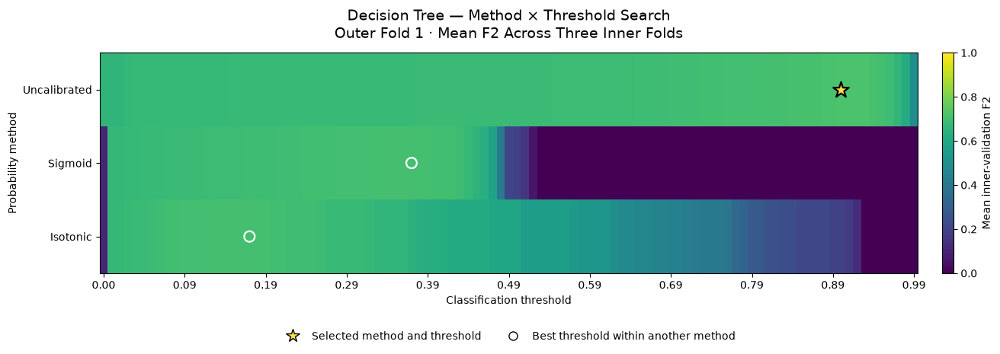

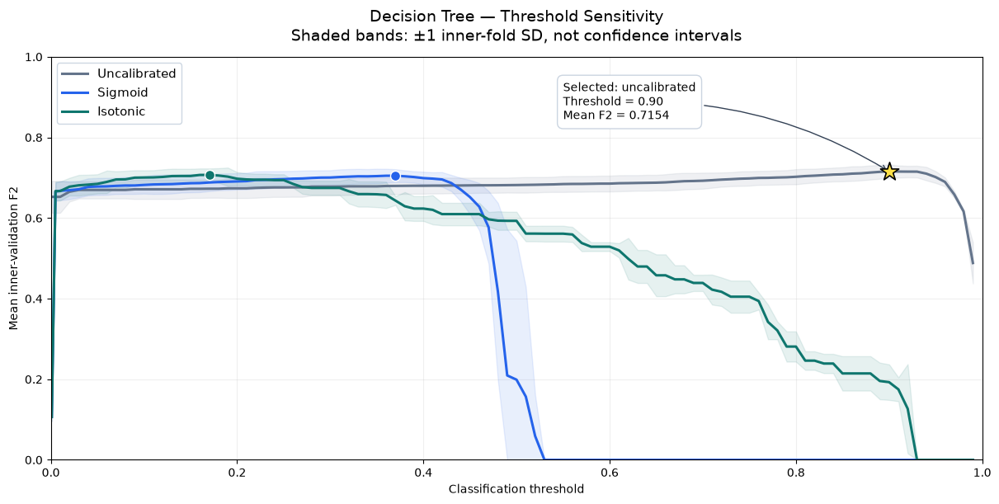

In [25]:
from matplotlib.lines import Line2D

dt_threshold_plot_methods = DT_SELECTION_METHODS

dt_threshold_plot_labels = [
    "Uncalibrated",
    "Sigmoid",
    "Isotonic"
]

dt_threshold_plot_colors = [
    "#64748B",
    "#2563EB",
    "#0F766E"
]

# Build the method × threshold matrix from actual calculated scores
dt_f2_heatmap = (
    dt_outer1_threshold_summary
    .pivot(index="Method", columns="Threshold", values="mean_F2")
    .reindex(
        index=dt_threshold_plot_methods,
        columns=dt_threshold_grid
    )
)

assert np.isfinite(dt_f2_heatmap.to_numpy()).all()

selected_method = dt_outer1_selected_probability_rule["Method"]
selected_threshold = float(
    dt_outer1_selected_probability_rule["Threshold"]
)

# FIGURE 1: Heatmap
fig, ax = plt.subplots(
    figsize=(13, 4.5),
    constrained_layout=True
)

heatmap = ax.imshow(
    dt_f2_heatmap.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="viridis",
    vmin=0,
    vmax=1
)

# Positions follow the actual saved grid, including nonuniform grids
tick_positions = np.unique(
    np.linspace(
        0, len(dt_threshold_grid) - 1, 11
    ).round().astype(int)
)

ax.set_xticks(
    tick_positions,
    [f"{dt_threshold_grid[i]:.2f}" for i in tick_positions]
)
ax.set_yticks(
    np.arange(len(dt_threshold_plot_methods)),
    dt_threshold_plot_labels
)

for row, method in enumerate(dt_threshold_plot_methods):
    best = dt_outer1_best_by_method.loc[
        dt_outer1_best_by_method["Method"] == method
    ].iloc[0]

    column = int(np.argmin(
        np.abs(dt_threshold_grid - best["Threshold"])
    ))

    is_selected = method == selected_method

    ax.scatter(
        column,
        row,
        marker="*" if is_selected else "o",
        s=240 if is_selected else 100,
        facecolors="#FDE047" if is_selected else "none",
        edgecolors="black" if is_selected else "white",
        linewidths=1.6,
        zorder=5
    )

ax.set_xlabel("Classification threshold")
ax.set_ylabel("Probability method")
ax.set_title(
    "Decision Tree — Method × Threshold Search\n"
    "Outer Fold 1 · Mean F2 Across Three Inner Folds",
    fontsize=14,
    pad=14
)

colorbar = fig.colorbar(heatmap, ax=ax, pad=0.02)
colorbar.set_label("Mean inner-validation F2")

ax.legend(
    handles=[
        Line2D(
            [], [], marker="*", linestyle="none",
            markerfacecolor="#FDE047", markeredgecolor="black",
            markersize=13, label="Selected method and threshold"
        ),
        Line2D(
            [], [], marker="o", linestyle="none",
            markerfacecolor="none", markeredgecolor="black",
            markersize=8, label="Best threshold within another method"
        )
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    frameon=False
)

plt.show()


# FIGURE 2: F2 curves
fig, ax = plt.subplots(
    figsize=(12, 6),
    constrained_layout=True
)

for method, label, color in zip(
    dt_threshold_plot_methods,
    dt_threshold_plot_labels,
    dt_threshold_plot_colors
):
    curve = (
        dt_outer1_threshold_summary.loc[
            dt_outer1_threshold_summary["Method"] == method
        ]
        .sort_values("Threshold")
    )

    x = curve["Threshold"].to_numpy()
    mean_f2 = curve["mean_F2"].to_numpy()
    sd_f2 = curve["sd_F2"].to_numpy()

    ax.plot(
        x, mean_f2,
        color=color,
        linewidth=2.2,
        label=label
    )

    ax.fill_between(
        x,
        np.maximum(0, mean_f2 - sd_f2),
        np.minimum(1, mean_f2 + sd_f2),
        color=color,
        alpha=0.10
    )

    best = dt_outer1_best_by_method.loc[
        dt_outer1_best_by_method["Method"] == method
    ].iloc[0]

    ax.scatter(
        best["Threshold"],
        best["mean_F2"],
        color=color,
        edgecolors="white",
        linewidths=1,
        s=75,
        zorder=5
    )

selected_f2 = float(
    dt_outer1_selected_probability_rule["mean_F2"]
)

ax.scatter(
    selected_threshold,
    selected_f2,
    marker="*",
    s=280,
    facecolors="#FDE047",
    edgecolors="black",
    linewidths=1.2,
    zorder=6
)

ax.annotate(
    f"Selected: uncalibrated\n"
    f"Threshold = {selected_threshold:.2f}\n"
    f"Mean F2 = {selected_f2:.4f}",
    xy=(selected_threshold, selected_f2),
    xytext=(0.55, 0.94),
    textcoords="axes fraction",
    fontsize=10,
    ha="left",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#CBD5E1"
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#334155",
        connectionstyle="arc3,rad=-0.15"
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Mean inner-validation F2")
ax.set_title(
    "Decision Tree — Threshold Sensitivity\n"
    "Shaded bands: ±1 inner-fold SD, not confidence intervals",
    fontsize=14,
    pad=14
)
ax.legend(
    loc="upper left",
    ncol=1,
    frameon=True,
    facecolor="white",
    edgecolor="#CBD5E1",
    framealpha=0.95,
    fontsize=11
)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.show()

### Result — Method–Threshold Heatmap and Sensitivity Curves

The heatmap and sensitivity curves confirm that the uncalibrated pipeline achieved the highest mean inner-validation F2: 0.7154 at threshold 0.90.

Its curve has a relatively flat region near the selected threshold, rather than an isolated sharp peak. Performance decreases toward the upper end of the tested threshold range.

Sigmoid achieved its best mean F2 of 0.7048 at threshold 0.37, followed by a sharp decline as thresholds approached and exceeded its calibrated probability range. Isotonic peaked at threshold 0.17 with mean F2 = 0.7069.

The shaded bands represent ±1 standard deviation across three inner folds, not confidence intervals. Their overlap does not establish statistical equivalence or superiority.

These plots describe threshold selection within outer fold 1. They are not independent estimates of performance, and the selected threshold is not yet a project-wide final threshold.

SELECTED TREE — TRAINING VS INNER VALIDATION


,inner_fold,threshold,training_pixels,training_F2,validation_F2,F2_gap_train_minus_validation,training_precision,validation_precision,training_recall,validation_recall,training_IoU,validation_IoU
0,1,0.9,829440,0.829365,0.708947,0.120418,0.575886,0.469447,0.931911,0.812587,0.552633,0.423585
1,2,0.9,829952,0.830944,0.702150,0.128794,0.568664,0.449057,0.939245,0.817312,0.548488,0.408095
2,3,0.9,829952,0.816567,0.735107,0.081459,0.544788,0.525479,0.932918,0.816542,0.524251,0.469991


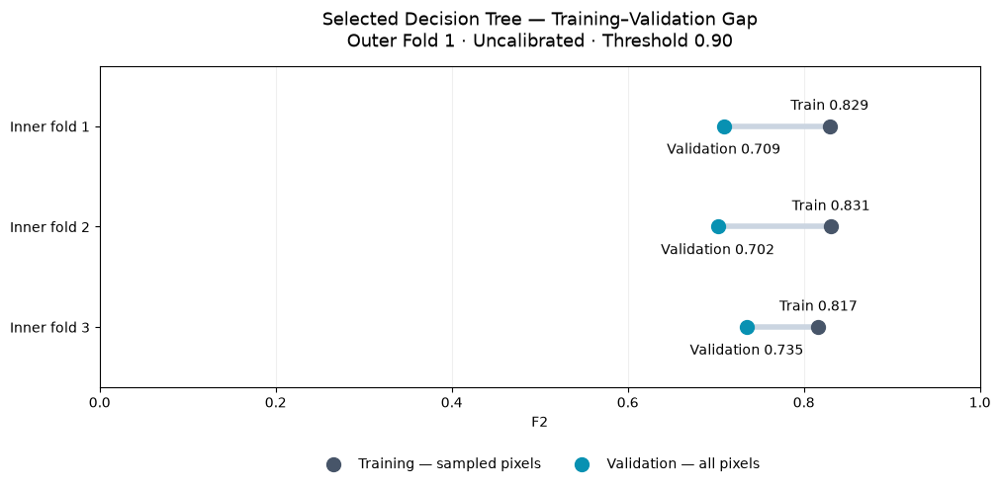

In [26]:
dt_selected_method = dt_outer1_selected_probability_rule["Method"]
dt_selected_threshold = float(
    dt_outer1_selected_probability_rule["Threshold"]
)

# This diagnostic matches the currently selected uncalibrated pipeline
assert dt_selected_method == DT_SELECTION_METHODS[0]

dt_selected_train_validation_rows = []

for split in dt_outer1_calibration_splits:
    inner_number = split["inner_fold"]

    model = dt_outer1_probability_options_by_inner[
        inner_number
    ]["uncalibrated_tree"]

    X_train, y_train = get_sampled_pixels(
        split["train_ids"],
        pixels_per_patch=DT_PIXELS_PER_PATCH
    )

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    training_probability = model.predict_proba(
        X_train
    )[:, positive_column]

    training_prediction = (
        training_probability >= dt_selected_threshold
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        training_prediction,
        labels=[0, 1]
    ).ravel()

    beta_squared = BETA ** 2

    training_f2 = dt_safe_ratio(
        (1 + beta_squared) * tp,
        (1 + beta_squared) * tp + beta_squared * fn + fp
    )

    validation_rows = dt_outer1_threshold_results.loc[
        (dt_outer1_threshold_results["inner_fold"] == inner_number)
        & (dt_outer1_threshold_results["Method"] == dt_selected_method)
        & np.isclose(
            dt_outer1_threshold_results["Threshold"],
            dt_selected_threshold,
            rtol=0,
            atol=1e-12
        )
    ]

    assert len(validation_rows) == 1
    validation = validation_rows.iloc[0]

    dt_selected_train_validation_rows.append({
        "inner_fold": inner_number,
        "threshold": dt_selected_threshold,
        "training_pixels": len(y_train),
        "training_F2": training_f2,
        "validation_F2": validation["F2"],
        "F2_gap_train_minus_validation": (
            training_f2 - validation["F2"]
        ),
        "training_precision": dt_safe_ratio(tp, tp + fp),
        "validation_precision": validation["Precision"],
        "training_recall": dt_safe_ratio(tp, tp + fn),
        "validation_recall": validation["Recall"],
        "training_IoU": dt_safe_ratio(tp, tp + fp + fn),
        "validation_IoU": validation["IoU"]
    })

    del X_train, y_train, training_probability, training_prediction

dt_selected_train_validation_table = pd.DataFrame(
    dt_selected_train_validation_rows
)

print("SELECTED TREE — TRAINING VS INNER VALIDATION")
display(dt_selected_train_validation_table.round(6))

# Paired-dot plot: one row per inner fold
fig, ax = plt.subplots(
    figsize=(10, 4.8),
    constrained_layout=True
)

for row_position, row in enumerate(
    dt_selected_train_validation_rows
):
    ax.plot(
        [row["validation_F2"], row["training_F2"]],
        [row_position, row_position],
        color="#CBD5E1",
        linewidth=4,
        zorder=1
    )

    ax.scatter(
        row["training_F2"], row_position,
        color="#475569", s=100, zorder=3,
        label="Training — sampled pixels" if row_position == 0 else None
    )
    ax.scatter(
        row["validation_F2"], row_position,
        color="#0891B2", s=100, zorder=3,
        label="Validation — all pixels" if row_position == 0 else None
    )

    ax.annotate(
        f"Train {row['training_F2']:.3f}",
        (row["training_F2"], row_position),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )
    ax.annotate(
        f"Validation {row['validation_F2']:.3f}",
        (row["validation_F2"], row_position),
        xytext=(0, -20),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_yticks(
    range(3),
    ["Inner fold 1", "Inner fold 2", "Inner fold 3"]
)
ax.set_ylim(-0.6, 2.6)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F2")
ax.set_title(
    "Selected Decision Tree — Training–Validation Gap\n"
    f"Outer Fold 1 · Uncalibrated · Threshold {dt_selected_threshold:.2f}",
    fontsize=13,
    pad=14
)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.show()

### Result — Selected Tree: Training–Validation Gap

At threshold 0.90, training F2 exceeded inner-validation F2 in all three folds:

| Inner fold | Training F2 | Validation F2 | Gap |
|---|---:|---:|---:|
| 1 | 0.829365 | 0.708947 | 0.120418 |
| 2 | 0.830944 | 0.702150 | 0.128794 |
| 3 | 0.816567 | 0.735107 | 0.081459 |

Mean training F2 was approximately 0.8256, compared with mean validation F2 of 0.7154, giving a mean gap of approximately 0.1102.

Training recall was approximately 93–94%, compared with approximately 81–82% on validation patches. The consistent gap is compatible with some overfitting, although patch differences and the sampled-training versus full-pixel-validation evaluation also affect this comparison.

These are selection-stage diagnostics. They do not replace outer-fold evaluation.

In [27]:
def make_dt_simplification_candidates(center_params):
    """
    Fixed refinement rule:
    reduce depth, increase leaf size, or increase pruning.
    Change one parameter at a time.
    """
    center = dict(center_params)
    candidates = [center]
    changes = ["Reference — current selected parameters"]

    depth = center["max_depth"]

    if depth is None:
        proposed_depths = [20, 10]
    else:
        proposed_depths = [
            max(2, int(depth) - 3),
            max(2, int(depth) - 6)
        ]

    proposed_leaves = [
        int(center["min_samples_leaf"]) * 2,
        int(center["min_samples_leaf"]) * 4
    ]

    alpha = float(center["ccp_alpha"])
    proposed_alphas = (
        [alpha * 10, alpha * 100]
        if alpha > 0
        else [0.00001, 0.0001]
    )

    proposed_changes = [
        *[("max_depth", value) for value in proposed_depths],
        *[("min_samples_leaf", value) for value in proposed_leaves],
        *[("ccp_alpha", value) for value in proposed_alphas]
    ]

    for parameter, value in proposed_changes:
        proposal = {**center, parameter: value}

        if proposal not in candidates:
            candidates.append(proposal)
            changes.append(f"{parameter} → {value}")

    return candidates, changes


dt_outer1_refinement_candidates, dt_outer1_refinement_changes = (
    make_dt_simplification_candidates(
        dt_outer1_search["best_params"]
    )
)

dt_outer1_refinement_plan = pd.DataFrame([
    {
        "local_candidate_id": number,
        "change": change,
        **params
    }
    for number, (change, params) in enumerate(zip(
        dt_outer1_refinement_changes,
        dt_outer1_refinement_candidates
    ))
])

number_of_inner_folds = len(nested_splits[0]["inner_splits"])
total_refinement_fits = (
    len(dt_outer1_refinement_candidates) * number_of_inner_folds
)

# The reference's three results already exist from the original search
new_refinement_fits = (
    len(dt_outer1_refinement_candidates) - 1
) * number_of_inner_folds

print("Configurations including reference:",
      len(dt_outer1_refinement_candidates))
print("Inner-fold evaluations required:", total_refinement_fits)
print("New training fits required:", new_refinement_fits)
print("Parameter-search threshold:", DT_BASELINE_THRESHOLD)
print("No models fitted by this cell.")

display(dt_outer1_refinement_plan)

Configurations including reference: 7
Inner-fold evaluations required: 21
New training fits required: 18
Parameter-search threshold: 0.5
No models fitted by this cell.


,local_candidate_id,change,min_samples_split,min_samples_leaf,max_depth,criterion,class_weight,ccp_alpha
0,0,Reference — current selected parameters,2,5,15,entropy,balanced,0.00001
1,1,max_depth → 12,2,5,12,entropy,balanced,0.00001
2,2,max_depth → 9,2,5,9,entropy,balanced,0.00001
3,3,min_samples_leaf → 10,2,10,15,entropy,balanced,0.00001
4,4,min_samples_leaf → 20,2,20,15,entropy,balanced,0.00001
5,5,ccp_alpha → 0.0001,2,5,15,entropy,balanced,0.00010
6,6,ccp_alpha → 0.001,2,5,15,entropy,balanced,0.00100


### Rationale — Why Check Simpler Trees?

The selected tree showed a mean training–validation F2 gap of approximately 0.1102: training F2 was 0.8256, compared with validation F2 of 0.7154.

This motivated a limited check of stronger complexity control. Reducing maximum depth, increasing minimum leaf size, or increasing pruning strength may reduce sensitivity to training-specific patterns. Improvement is not guaranteed; simpler trees may also underfit.

One parameter is changed at a time relative to the selected reference configuration.

### Result — Local Refinement Setup

Seven configurations were prepared: the reference and six alternatives.

- Maximum depth: 12 or 9 instead of 15.
- Minimum samples per leaf: 10 or 20 instead of 5.
- Pruning strength: 0.0001 or 0.001 instead of 0.00001.

The comparison requires 21 inner-fold evaluations. Three reference evaluations already exist, leaving 18 new training fits.

Hyperparameters will be compared using mean inner-validation F2 at the fixed search-stage threshold of 0.50. Calibration and threshold selection must be revisited if the selected parameters change.

No new models were fitted by this setup cell, and no performance improvement has yet been demonstrated.

In [28]:
def run_dt_outer1_local_refinement():
    start_time = perf_counter()
    result_frames = []

    # Reuse the reference's three validation results
    original_reference_id = dt_outer1_search["best_candidate_id"]

    reference_results = (
        dt_outer1_search["fold_results"]
        .loc[
            lambda table:
                table["candidate_id"] == original_reference_id
        ]
        .copy()
    )

    assert len(reference_results) == 3

    # ID 0 refers to the reference in this LOCAL search
    reference_results["candidate_id"] = 0
    reference_results["reused_from_initial_search"] = True
    result_frames.append(reference_results)

    for inner_number, inner in enumerate(
        nested_splits[0]["inner_splits"],
        start=1
    ):
        print(
            f"\nLOCAL REFINEMENT — INNER FOLD {inner_number}/3",
            flush=True
        )

        X_fit, y_fit = get_sampled_pixels(
            inner["train_ids"],
            pixels_per_patch=DT_PIXELS_PER_PATCH
        )

        fitted_models = {}
        fit_times = {}
        depths = {}
        leaves = {}

        # Reference is already evaluated; fit only the six alternatives
        for local_id, params in enumerate(
            dt_outer1_refinement_candidates[1:],
            start=1
        ):
            model = DecisionTreeClassifier(
                **params,
                random_state=RANDOM_STATE
            )

            fit_start = perf_counter()
            model.fit(X_fit, y_fit)

            fit_times[local_id] = perf_counter() - fit_start
            fitted_models[local_id] = model
            depths[local_id] = model.get_depth()
            leaves[local_id] = model.get_n_leaves()

            print(
                f"  Local candidate {local_id} fitted "
                f"| {fit_times[local_id]:.2f} s",
                flush=True
            )

        print("  Evaluating full validation patches...", flush=True)

        scores = evaluate_dt_candidates_full_patches(
            models=fitted_models,
            patch_ids=inner["validation_ids"],
            threshold=DT_BASELINE_THRESHOLD
        )

        scores["outer_fold"] = 1
        scores["inner_fold"] = inner_number
        scores["fit_seconds"] = scores["candidate_id"].map(fit_times)
        scores["tree_depth"] = scores["candidate_id"].map(depths)
        scores["n_leaves"] = scores["candidate_id"].map(leaves)
        scores["reused_from_initial_search"] = False

        result_frames.append(scores)

        del fitted_models, model, X_fit, y_fit

    results = (
        pd.concat(result_frames, ignore_index=True)
        .rename(columns={"candidate_id": "local_candidate_id"})
    )

    assert not results.duplicated(
        ["local_candidate_id", "inner_fold"]
    ).any()

    assert (
        results.groupby("local_candidate_id")["inner_fold"]
        .nunique()
        .eq(3)
        .all()
    )

    ranking = (
        results
        .groupby("local_candidate_id", as_index=False)
        .agg(
            mean_F2=("F2", "mean"),
            sd_F2=("F2", "std"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_depth=("tree_depth", "mean"),
            mean_leaves=("n_leaves", "mean")
        )
        .merge(
            dt_outer1_refinement_plan[
                ["local_candidate_id", "change"]
            ],
            on="local_candidate_id",
            validate="one_to_one"
        )
        .sort_values(
            ["mean_F2", "mean_leaves", "local_candidate_id"],
            ascending=[False, True, True]
        )
        .reset_index(drop=True)
    )

    reference_f2 = float(
        ranking.loc[
            ranking["local_candidate_id"] == 0,
            "mean_F2"
        ].iloc[0]
    )

    ranking["F2_difference_from_reference"] = (
        ranking["mean_F2"] - reference_f2
    )

    selected_id = int(ranking.iloc[0]["local_candidate_id"])

    return {
        "fold_results": results,
        "ranking": ranking,
        "selected_local_id": selected_id,
        "selected_params": dict(
            dt_outer1_refinement_candidates[selected_id]
        ),
        "elapsed_seconds": perf_counter() - start_time
    }


if "dt_outer1_refinement_result" not in globals():
    dt_outer1_refinement_result = run_dt_outer1_local_refinement()
else:
    print("Using the completed local refinement already stored.")

print("\nLOCAL REFINEMENT COMPLETED")
print(
    "Elapsed time:",
    f"{dt_outer1_refinement_result['elapsed_seconds'] / 60:.2f} minutes"
)
print(
    "Selected local candidate:",
    dt_outer1_refinement_result["selected_local_id"]
)
print(
    "Selected parameters:",
    dt_outer1_refinement_result["selected_params"]
)

display(dt_outer1_refinement_result["ranking"].round(6))


LOCAL REFINEMENT — INNER FOLD 1/3
  Local candidate 1 fitted | 8.28 s
  Local candidate 2 fitted | 10.72 s
  Local candidate 3 fitted | 5.64 s
  Local candidate 4 fitted | 5.73 s
  Local candidate 5 fitted | 5.63 s
  Local candidate 6 fitted | 5.83 s
  Evaluating full validation patches...

LOCAL REFINEMENT — INNER FOLD 2/3
  Local candidate 1 fitted | 5.89 s
  Local candidate 2 fitted | 5.22 s
  Local candidate 3 fitted | 6.13 s
  Local candidate 4 fitted | 5.92 s
  Local candidate 5 fitted | 6.15 s
  Local candidate 6 fitted | 5.97 s
  Evaluating full validation patches...

LOCAL REFINEMENT — INNER FOLD 3/3
  Local candidate 1 fitted | 5.76 s
  Local candidate 2 fitted | 5.31 s
  Local candidate 3 fitted | 5.97 s
  Local candidate 4 fitted | 5.92 s
  Local candidate 5 fitted | 6.00 s
  Local candidate 6 fitted | 6.01 s
  Evaluating full validation patches...

LOCAL REFINEMENT COMPLETED
Elapsed time: 2.09 minutes
Selected local candidate: 0
Selected parameters: {'min_samples_split': 

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.681813,0.018980,0.366856,0.869392,0.347624,15.0,1907.666667,Reference — current selected parameters,0.000000
1,3,0.681067,0.021313,0.357610,0.881560,0.341156,15.0,1733.333333,min_samples_leaf → 10,-0.000747
2,4,0.672844,0.025456,0.333229,0.905049,0.321912,15.0,1532.000000,min_samples_leaf → 20,-0.008969
3,1,0.652180,0.025367,0.302486,0.919243,0.294640,12.0,994.666667,max_depth → 12,-0.029633
4,5,0.627592,0.030720,0.268841,0.944870,0.264674,15.0,523.666667,ccp_alpha → 0.0001,-0.054221
5,2,0.609857,0.026708,0.252645,0.945576,0.249021,9.0,341.666667,max_depth → 9,-0.071956
6,6,0.557542,0.054383,0.214092,0.943944,0.211262,9.0,46.333333,ccp_alpha → 0.001,-0.124271


### Rationale — Local Complexity Refinement

The selected tree showed a mean training–validation F2 gap of approximately 0.1102. A limited refinement therefore examined whether reduced depth, larger leaves, or stronger pruning could improve inner-validation performance.

### Result — Local Refinement

The refinement completed in 2.09 minutes. The reference configuration retained the highest mean inner-validation F2 at the fixed hyperparameter-search threshold of 0.50:

- Reference: F2 = 0.681813; mean leaves = 1,907.7.
- Minimum leaf size 10: F2 = 0.681067; mean leaves = 1,733.3.
- Minimum leaf size 20: F2 = 0.672844.
- Maximum depth 12: F2 = 0.652180.
- Pruning strength 0.0001: F2 = 0.627592.
- Maximum depth 9: F2 = 0.609857.
- Pruning strength 0.001: F2 = 0.557542.

Increasing minimum leaf size to 10 reduced the mean leaf count by approximately 9%, with an F2 decrease of only 0.000747. However, the predefined maximum-mean-F2 rule retained the reference. This small difference does not demonstrate statistical superiority.

Stronger simplification reduced F2 under this staged search. This does not prove that every simpler configuration is inferior after separate threshold optimization.

The selected hyperparameters remain unchanged. Therefore, the existing calibration and threshold-selection results remain applicable: uncalibrated predictions with threshold 0.90 for outer fold 1.

In [29]:
DT_LEARNING_CONFIGURATIONS = [
    {"configuration": "A", "patch_fraction": 0.25, "pixels_per_patch": 512},
    {"configuration": "B", "patch_fraction": 0.50, "pixels_per_patch": 512},
    {"configuration": "C", "patch_fraction": 1.00, "pixels_per_patch": 512},
    {"configuration": "D", "patch_fraction": 1.00, "pixels_per_patch": 1024}
]

dt_outer1_learning_plan = []
dt_learning_plan_rows = []

for split in dt_outer1_calibration_splits:
    inner_number = split["inner_fold"]
    training_ids = np.asarray(split["train_ids"])

    presence = dt_presence_by_id.reindex(training_ids)
    assert not presence.isna().any()

    # A reproducible, approximately stratified ordering.
    # Taking progressively larger prefixes within each class
    # produces nested patch subsets.
    strata = (presence.to_numpy() > 0).astype(int)
    rng = np.random.default_rng(RANDOM_STATE)

    ordered_groups = {
        label: rng.permutation(training_ids[strata == label])
        for label in np.unique(strata)
    }

    previous_subset = set()

    for config in DT_LEARNING_CONFIGURATIONS:
        fraction = config["patch_fraction"]

        selected_ids = np.concatenate([
            ids[:max(1, int(np.ceil(len(ids) * fraction)))]
            for ids in ordered_groups.values()
        ])

        assert previous_subset.issubset(set(selected_ids))
        previous_subset = set(selected_ids)

        assert set(selected_ids).issubset(set(training_ids))
        assert set(selected_ids).isdisjoint(
            set(split["validation_ids"])
        )

        dt_outer1_learning_plan.append({
            **config,
            "inner_fold": inner_number,
            "train_ids": selected_ids,
            "validation_ids": split["validation_ids"]
        })

        dt_learning_plan_rows.append({
            "inner_fold": inner_number,
            "configuration": config["configuration"],
            "patch_fraction": fraction,
            "training_patches": len(selected_ids),
            "pixels_per_patch": config["pixels_per_patch"],
            "training_pixels": (
                len(selected_ids) * config["pixels_per_patch"]
            ),
            "validation_patches": len(split["validation_ids"]),
            "reuse_existing_result": config["configuration"] == "C"
        })

dt_outer1_learning_plan_table = pd.DataFrame(
    dt_learning_plan_rows
)

print("Fixed threshold:", dt_selected_threshold)
print("Reference evaluations reused: 3")
print("New training fits required: 9")
print("No models fitted by this cell.")

display(dt_outer1_learning_plan_table)

Fixed threshold: 0.9
Reference evaluations reused: 3
New training fits required: 9
No models fitted by this cell.


,inner_fold,configuration,patch_fraction,training_patches,pixels_per_patch,training_pixels,validation_patches,reuse_existing_result
0,1,A,0.25,405,512,207360,811,False
1,1,B,0.50,810,512,414720,811,False
2,1,C,1.00,1620,512,829440,811,True
3,1,D,1.00,1620,1024,1658880,811,False
4,2,A,0.25,406,512,207872,810,False
5,2,B,0.50,811,512,415232,810,False
6,2,C,1.00,1621,512,829952,810,True
7,2,D,1.00,1621,1024,1659904,810,False
8,3,A,0.25,406,512,207872,810,False
9,3,B,0.50,811,512,415232,810,False


### Rationale — Training-Data Size Sensitivity

This analysis separates two questions:

1. Does using more training patches improve performance?
2. Does sampling more pixels from the same patches improve performance?

Configurations A, B, and C increase patch coverage from approximately 25% to 50% to 100%, while keeping 512 pixels per patch. Configuration D uses the same full training-patch set as C but increases sampling to 1,024 pixels per patch.

### Result — Learning-Curve Setup

The training subsets were successfully prepared for all three inner folds:

- A: 405–406 patches, with 512 pixels per patch.
- B: 810–811 patches, with 512 pixels per patch.
- C: 1,620–1,621 patches, with 512 pixels per patch.
- D: 1,620–1,621 patches, with 1,024 pixels per patch.

Patch subsets are nested within each inner fold. Validation patches remain unchanged across configurations.

The analysis keeps the selected tree parameters and threshold 0.90 fixed. Three existing reference evaluations will be reused, leaving nine new training fits.

No new models have been fitted. This is a diagnostic sensitivity analysis, not a separate optimization of each training-data size.

In [30]:
def run_dt_outer1_learning_analysis():
    analysis_start = perf_counter()
    result_frames = []

    for inner_number in [1, 2, 3]:
        print(
            f"\nDATA-SIZE ANALYSIS — INNER FOLD {inner_number}/3",
            flush=True
        )

        plans = [
            plan for plan in dt_outer1_learning_plan
            if plan["inner_fold"] == inner_number
        ]

        fitted_models = {}
        training_rows = []

        for plan in plans:
            configuration = plan["configuration"]

            if configuration == "C":
                continue

            X_fit, y_fit = get_sampled_pixels(
                plan["train_ids"],
                pixels_per_patch=plan["pixels_per_patch"]
            )

            model = DecisionTreeClassifier(
                **dt_outer1_search["best_params"],
                random_state=RANDOM_STATE
            )

            fit_start = perf_counter()
            model.fit(X_fit, y_fit)
            fit_seconds = perf_counter() - fit_start

            positive_column = int(
                np.flatnonzero(model.classes_ == 1)[0]
            )

            training_probability = model.predict_proba(
                X_fit
            )[:, positive_column]

            training_prediction = (
                training_probability >= dt_selected_threshold
            ).astype(np.uint8)

            training_f2 = fbeta_score(
                y_fit,
                training_prediction,
                beta=BETA,
                zero_division=0
            )

            fitted_models[configuration] = model

            training_rows.append({
                "configuration": configuration,
                "training_patches": len(plan["train_ids"]),
                "pixels_per_patch": plan["pixels_per_patch"],
                "training_pixels": len(y_fit),
                "training_F2": training_f2,
                "fit_seconds": fit_seconds,
                "tree_depth": model.get_depth(),
                "n_leaves": model.get_n_leaves(),
                "reused_reference": False
            })

            print(
                f"  Configuration {configuration} fitted "
                f"| {len(y_fit):,} pixels "
                f"| {fit_seconds:.2f} s",
                flush=True
            )

            del X_fit, y_fit, training_probability, training_prediction

        print("  Evaluating full validation patches...", flush=True)

        validation_scores = evaluate_dt_candidates_full_patches(
            models=fitted_models,
            patch_ids=plans[0]["validation_ids"],
            threshold=dt_selected_threshold
        ).rename(columns={
            "candidate_id": "configuration",
            "F2": "validation_F2",
            "precision": "validation_precision",
            "recall": "validation_recall",
            "specificity": "validation_specificity",
            "IoU": "validation_IoU"
        })

        combined = validation_scores.merge(
            pd.DataFrame(training_rows),
            on="configuration",
            validate="one_to_one"
        )
        combined["inner_fold"] = inner_number
        result_frames.append(combined)

        # Reuse configuration C from the completed diagnostics
        reference_plan = next(
            plan for plan in plans
            if plan["configuration"] == "C"
        )

        reference_training = (
            dt_selected_train_validation_table
            .set_index("inner_fold")
            .loc[inner_number]
        )

        reference_validation = dt_outer1_threshold_results.loc[
            (dt_outer1_threshold_results["inner_fold"] == inner_number)
            & (
                dt_outer1_threshold_results["Method"]
                == DT_SELECTION_METHODS[0]
            )
            & np.isclose(
                dt_outer1_threshold_results["Threshold"],
                dt_selected_threshold,
                rtol=0,
                atol=1e-12
            )
        ]

        assert len(reference_validation) == 1
        reference_validation = reference_validation.iloc[0]

        reference_model = dt_outer1_probability_options_by_inner[
            inner_number
        ]["uncalibrated_tree"]

        reference_row = {
            "configuration": "C",
            "inner_fold": inner_number,
            "threshold": dt_selected_threshold,
            "training_patches": len(reference_plan["train_ids"]),
            "pixels_per_patch": reference_plan["pixels_per_patch"],
            "training_pixels": int(
                reference_training["training_pixels"]
            ),
            "training_F2": reference_training["training_F2"],
            "validation_F2": reference_validation["F2"],
            "validation_precision": reference_validation["Precision"],
            "validation_recall": reference_validation["Recall"],
            "validation_specificity": reference_validation["Specificity"],
            "validation_IoU": reference_validation["IoU"],
            "TN": reference_validation["TN"],
            "FP": reference_validation["FP"],
            "FN": reference_validation["FN"],
            "TP": reference_validation["TP"],
            "tree_depth": reference_model.get_depth(),
            "n_leaves": reference_model.get_n_leaves(),
            "fit_seconds": np.nan,
            "reused_reference": True
        }

        result_frames.append(pd.DataFrame([reference_row]))

        del fitted_models, model

    results = (
        pd.concat(result_frames, ignore_index=True)
        .sort_values(["inner_fold", "configuration"])
        .reset_index(drop=True)
    )

    assert len(results) == 12
    assert not results.duplicated(
        ["inner_fold", "configuration"]
    ).any()

    results["F2_gap"] = (
        results["training_F2"] - results["validation_F2"]
    )

    summary = (
        results
        .groupby("configuration", as_index=False)
        .agg(
            mean_training_F2=("training_F2", "mean"),
            mean_validation_F2=("validation_F2", "mean"),
            sd_validation_F2=("validation_F2", "std"),
            mean_F2_gap=("F2_gap", "mean"),
            mean_validation_precision=("validation_precision", "mean"),
            mean_validation_recall=("validation_recall", "mean"),
            mean_validation_IoU=("validation_IoU", "mean"),
            mean_leaves=("n_leaves", "mean")
        )
    )

    return {
        "fold_results": results,
        "summary": summary,
        "elapsed_seconds": perf_counter() - analysis_start
    }


if "dt_outer1_learning_analysis" not in globals():
    dt_outer1_learning_analysis = run_dt_outer1_learning_analysis()
else:
    print("Using the completed data-size analysis already stored.")

dt_outer1_learning_results = (
    dt_outer1_learning_analysis["fold_results"]
)
dt_outer1_learning_summary = (
    dt_outer1_learning_analysis["summary"]
)

print(
    "\nTotal analysis time:",
    f"{dt_outer1_learning_analysis['elapsed_seconds'] / 60:.2f} minutes"
)

print("\nINDIVIDUAL INNER-FOLD RESULTS")
display(
    dt_outer1_learning_results[
        [
            "inner_fold", "configuration",
            "training_patches", "pixels_per_patch",
            "training_F2", "validation_F2", "F2_gap",
            "validation_precision", "validation_recall",
            "validation_IoU"
        ]
    ].round(6)
)

print("\nMEAN RESULTS ACROSS THREE INNER FOLDS")
display(dt_outer1_learning_summary.round(6))


DATA-SIZE ANALYSIS — INNER FOLD 1/3
  Configuration A fitted | 207,360 pixels | 1.09 s
  Configuration B fitted | 414,720 pixels | 2.75 s
  Configuration D fitted | 1,658,880 pixels | 12.87 s
  Evaluating full validation patches...

DATA-SIZE ANALYSIS — INNER FOLD 2/3
  Configuration A fitted | 207,872 pixels | 1.09 s
  Configuration B fitted | 415,232 pixels | 2.58 s
  Configuration D fitted | 1,659,904 pixels | 13.15 s
  Evaluating full validation patches...

DATA-SIZE ANALYSIS — INNER FOLD 3/3
  Configuration A fitted | 207,872 pixels | 1.04 s
  Configuration B fitted | 415,232 pixels | 2.45 s
  Configuration D fitted | 1,659,904 pixels | 12.74 s
  Evaluating full validation patches...

Total analysis time: 0.98 minutes

INDIVIDUAL INNER-FOLD RESULTS


,inner_fold,configuration,training_patches,pixels_per_patch,training_F2,validation_F2,F2_gap,validation_precision,validation_recall,validation_IoU
0,1,A,405,512,0.889194,0.663454,0.225740,0.430366,0.767355,0.380694
1,1,B,810,512,0.855723,0.682119,0.173604,0.450496,0.782730,0.400423
2,1,C,1620,512,0.829365,0.708947,0.120418,0.469447,0.812587,0.423585
3,1,D,1620,1024,0.810669,0.720774,0.089895,0.470862,0.831043,0.429725
4,2,A,406,512,0.864195,0.668072,0.196124,0.441589,0.766331,0.389185
5,2,B,811,512,0.856524,0.675816,0.180708,0.440139,0.780266,0.391600
6,2,C,1621,512,0.830944,0.702150,0.128794,0.449057,0.817312,0.408095
7,2,D,1621,1024,0.812752,0.714197,0.098554,0.461487,0.827479,0.420982
8,3,A,406,512,0.833766,0.688492,0.145274,0.490933,0.765505,0.426755
9,3,B,811,512,0.839900,0.714282,0.125617,0.520398,0.787645,0.456368



MEAN RESULTS ACROSS THREE INNER FOLDS


,configuration,mean_training_F2,mean_validation_F2,sd_validation_F2,mean_F2_gap,mean_validation_precision,mean_validation_recall,mean_validation_IoU,mean_leaves
0,A,0.862385,0.673339,0.013324,0.189046,0.454296,0.766397,0.398878,827.333333
1,B,0.850716,0.690739,0.020631,0.159977,0.470344,0.783547,0.416131,1292.333333
2,C,0.825625,0.715401,0.017401,0.110224,0.481328,0.815480,0.433890,1907.666667
3,D,0.807259,0.726499,0.015955,0.080760,0.483100,0.831708,0.440083,2578.666667


### Rationale — Training-Data Size Sensitivity

This analysis examined whether increasing training-patch coverage or sampling more pixels from the same patches improved validation performance and reduced the training–validation gap.

### Result — Data-Size Analysis

With 512 pixels per patch, increasing training-patch coverage from approximately 25% to 50% to 100% increased mean validation F2 from 0.673339 to 0.690739 to 0.715401. The corresponding training–validation gaps decreased from 0.189046 to 0.159977 to 0.110224.

Using 1,024 pixels per patch on the same full training-patch sets further increased mean validation F2 to 0.726499, an absolute gain of 0.011098 over 512 pixels. Improvement occurred in all three inner folds.

Mean validation recall increased from 0.815480 to 0.831708, while precision remained approximately unchanged: 0.481328 versus 0.483100. The mean F2 gap decreased to 0.080760.

The larger pixel sample produced more complex trees: mean leaf count increased from approximately 1,908 to 2,579. Thus, the reduced gap did not result from smaller trees.

The analysis completed in 0.98 minutes. These are fixed-parameter, fixed-threshold sensitivity results, not independent performance estimates. Adopting 1,024 pixels requires revisiting calibration and threshold selection before outer evaluation.

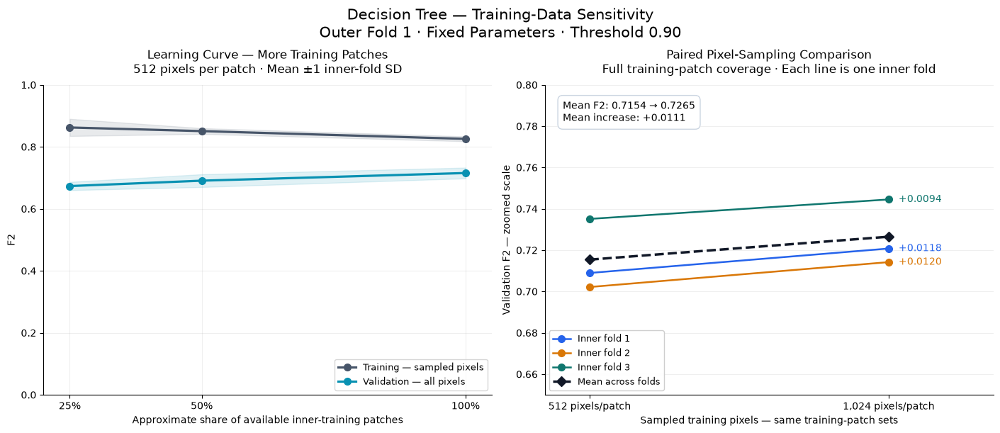

In [31]:
# Summaries calculated from the actual three-fold results
dt_learning_plot_summary = (
    dt_outer1_learning_results
    .groupby("configuration")
    .agg(
        mean_training_F2=("training_F2", "mean"),
        sd_training_F2=("training_F2", "std"),
        mean_validation_F2=("validation_F2", "mean"),
        sd_validation_F2=("validation_F2", "std")
    )
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

# PANEL 1: More training patches, fixed pixels per patch
ax = axes[0]

patch_fractions = np.array([25, 50, 100])
patch_curve = dt_learning_plot_summary.loc[["A", "B", "C"]]

for mean_column, sd_column, label, color in [
    (
        "mean_training_F2", "sd_training_F2",
        "Training — sampled pixels", "#475569"
    ),
    (
        "mean_validation_F2", "sd_validation_F2",
        "Validation — all pixels", "#0891B2"
    )
]:
    means = patch_curve[mean_column].to_numpy()
    standard_deviations = patch_curve[sd_column].to_numpy()

    ax.plot(
        patch_fractions,
        means,
        marker="o",
        markersize=7,
        linewidth=2.3,
        color=color,
        label=label
    )

    ax.fill_between(
        patch_fractions,
        np.maximum(0, means - standard_deviations),
        np.minimum(1, means + standard_deviations),
        color=color,
        alpha=0.12
    )

ax.set_xticks(patch_fractions, ["25%", "50%", "100%"])
ax.set_xlim(20, 105)
ax.set_ylim(0, 1)
ax.set_xlabel("Approximate share of available inner-training patches")
ax.set_ylabel("F2")
ax.set_title(
    "Learning Curve — More Training Patches\n"
    "512 pixels per patch · Mean ±1 inner-fold SD",
    fontsize=12,
    pad=12
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

# PANEL 2: More pixels from the same full training-patch sets
ax = axes[1]

dt_pixel_comparison = (
    dt_outer1_learning_results.loc[
        dt_outer1_learning_results["configuration"].isin(["C", "D"])
    ]
    .pivot(
        index="inner_fold",
        columns="configuration",
        values="validation_F2"
    )
    .sort_index()
)

fold_colors = ["#2563EB", "#D97706", "#0F766E"]

for (inner_fold, row), color in zip(
    dt_pixel_comparison.iterrows(),
    fold_colors
):
    values = row[["C", "D"]].to_numpy(dtype=float)

    ax.plot(
        [0, 1],
        values,
        marker="o",
        markersize=7,
        linewidth=1.8,
        color=color,
        label=f"Inner fold {inner_fold}"
    )

    ax.annotate(
        f"+{values[1] - values[0]:.4f}",
        xy=(1, values[1]),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        color=color
    )

mean_values = dt_pixel_comparison[["C", "D"]].mean().to_numpy()

ax.plot(
    [0, 1],
    mean_values,
    color="#111827",
    linestyle="--",
    linewidth=2.5,
    marker="D",
    markersize=7,
    label="Mean across folds"
)

ax.text(
    0.04, 0.95,
    f"Mean F2: {mean_values[0]:.4f} → {mean_values[1]:.4f}\n"
    f"Mean increase: +{mean_values[1] - mean_values[0]:.4f}",
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#CBD5E1"
    )
)

ax.set_xticks([0, 1], ["512 pixels/patch", "1,024 pixels/patch"])
ax.set_xlim(-0.15, 1.35)

# Deliberately zoomed scale to make small paired changes visible
ax.set_ylim(0.65, 0.80)
ax.set_xlabel("Sampled training pixels — same training-patch sets")
ax.set_ylabel("Validation F2 — zoomed scale")
ax.set_title(
    "Paired Pixel-Sampling Comparison\n"
    "Full training-patch coverage · Each line is one inner fold",
    fontsize=12,
    pad=12
)

ax.legend(
    loc="lower left",
    fontsize=9,
    frameon=True,
    facecolor="white",
    framealpha=0.95
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Training-Data Sensitivity\n"
    "Outer Fold 1 · Fixed Parameters · Threshold 0.90",
    fontsize=15
)

plt.show()

### Rationale — Visualizing Training-Data Sensitivity

The plots separate the effect of increasing training-patch coverage from the effect of sampling more pixels within the same patches.

### Result — Learning and Pixel-Sampling Curves

With 512 pixels per patch, increasing training-patch coverage from approximately 25% to 100% increased mean validation F2 from 0.6733 to 0.7154 and reduced the training–validation gap. The three tested sizes do not establish that performance has reached a plateau.

Increasing sampling from 512 to 1,024 pixels per patch improved validation F2 in all three inner folds. Mean F2 increased from 0.7154 to 0.7265, an absolute gain of approximately 0.0111.

The learning-curve bands show ±1 inner-fold standard deviation, not confidence intervals. The paired-comparison panel uses a zoomed vertical scale.

These are diagnostic results at fixed tree parameters and threshold 0.90. They do not establish statistical superiority or performance on unseen outer-evaluation patches.

In [32]:
def fit_dt_probability_options_for_sample_size(
    split,
    params,
    pixels_per_patch
):
    start = perf_counter()

    # Uncalibrated pipeline: all inner-training patches
    X_train, y_train = get_sampled_pixels(
        split["train_ids"],
        pixels_per_patch=pixels_per_patch
    )

    uncalibrated_training_pixels = len(y_train)

    uncalibrated_tree = DecisionTreeClassifier(
        **params,
        random_state=RANDOM_STATE
    )
    uncalibrated_tree.fit(X_train, y_train)
    del X_train, y_train

    print("  Uncalibrated tree fitted.", flush=True)

    # Calibrated pipelines: separate fitting and calibration patches
    X_fit, y_fit = get_sampled_pixels(
        split["fit_ids"],
        pixels_per_patch=pixels_per_patch
    )

    calibration_base_training_pixels = len(y_fit)

    calibration_base_tree = DecisionTreeClassifier(
        **params,
        random_state=RANDOM_STATE
    )
    calibration_base_tree.fit(X_fit, y_fit)
    del X_fit, y_fit

    print("  Calibration-base tree fitted.", flush=True)

    p_cal, y_cal = collect_dt_calibration_pixels(
        calibration_base_tree,
        split["calibration_ids"]
    )

    if np.unique(y_cal).size != 2:
        raise ValueError("Calibration data must contain both classes.")

    sigmoid_calibrator = LogisticRegression(
        C=PLATT_C,
        solver="lbfgs",
        max_iter=1000,
        class_weight=None,
        random_state=RANDOM_STATE
    )
    sigmoid_calibrator.fit(p_cal.reshape(-1, 1), y_cal)

    print("  Sigmoid calibrator fitted.", flush=True)

    isotonic_calibrator = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
        y_min=0.0,
        y_max=1.0
    )
    isotonic_calibrator.fit(p_cal, y_cal)

    print("  Isotonic calibrator fitted.", flush=True)

    positive_column = int(
        np.flatnonzero(sigmoid_calibrator.classes_ == 1)[0]
    )

    sigmoid_endpoints = sigmoid_calibrator.predict_proba(
        np.array([[0.0], [1.0]])
    )[:, positive_column]

    isotonic_endpoints = isotonic_calibrator.predict(
        np.array([0.0, 1.0])
    )

    summary = {
        "inner_fold": split["inner_fold"],
        "pixels_per_patch": pixels_per_patch,
        "uncalibrated_training_patches": len(split["train_ids"]),
        "uncalibrated_training_pixels": uncalibrated_training_pixels,
        "calibrated_tree_training_patches": len(split["fit_ids"]),
        "calibrated_tree_training_pixels": calibration_base_training_pixels,
        "calibration_patches": len(split["calibration_ids"]),
        "calibration_pixels": len(y_cal),
        "calibration_landslide_pixels": int(y_cal.sum()),
        "calibration_landslide_fraction": float(y_cal.mean()),
        "sigmoid_iterations": int(sigmoid_calibrator.n_iter_[0]),
        "sigmoid_p_at_raw_0": float(sigmoid_endpoints[0]),
        "sigmoid_p_at_raw_1": float(sigmoid_endpoints[1]),
        "isotonic_mapping_points": len(
            isotonic_calibrator.X_thresholds_
        ),
        "isotonic_p_at_raw_0": float(isotonic_endpoints[0]),
        "isotonic_p_at_raw_1": float(isotonic_endpoints[1]),
        "fit_seconds": perf_counter() - start
    }

    return {
        "uncalibrated_tree": uncalibrated_tree,
        "calibration_base_tree": calibration_base_tree,
        "sigmoid": sigmoid_calibrator,
        "isotonic": isotonic_calibrator,
        "summary": summary
    }


# Separate storage: the 512-pixel results are preserved
if "dt_outer1_options_1024_by_inner" not in globals():
    dt_outer1_options_1024_by_inner = {}

for split in dt_outer1_calibration_splits:
    inner_number = split["inner_fold"]

    print(
        f"\n1,024 PIXELS/PATCH — INNER FOLD {inner_number}/3",
        flush=True
    )

    if inner_number not in dt_outer1_options_1024_by_inner:
        dt_outer1_options_1024_by_inner[inner_number] = (
            fit_dt_probability_options_for_sample_size(
                split=split,
                params=dt_outer1_search["best_params"],
                pixels_per_patch=1024
            )
        )
    else:
        print("  Using previously fitted models.", flush=True)

dt_outer1_fit_summary_1024 = pd.DataFrame([
    dt_outer1_options_1024_by_inner[i]["summary"]
    for i in [1, 2, 3]
])

print("\nTREE FITTING AND CALIBRATION DATA")
display(
    dt_outer1_fit_summary_1024[
        [
            "inner_fold",
            "pixels_per_patch",
            "uncalibrated_training_pixels",
            "calibrated_tree_training_pixels",
            "calibration_patches",
            "calibration_pixels",
            "calibration_landslide_fraction",
            "fit_seconds"
        ]
    ].round(6)
)

print("\nSIGMOID FITTING DETAILS")
display(
    dt_outer1_fit_summary_1024[
        [
            "inner_fold",
            "sigmoid_iterations",
            "sigmoid_p_at_raw_0",
            "sigmoid_p_at_raw_1"
        ]
    ].round(6)
)

print("\nISOTONIC FITTING DETAILS")
display(
    dt_outer1_fit_summary_1024[
        [
            "inner_fold",
            "isotonic_mapping_points",
            "isotonic_p_at_raw_0",
            "isotonic_p_at_raw_1"
        ]
    ].round(6)
)


1,024 PIXELS/PATCH — INNER FOLD 1/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.

1,024 PIXELS/PATCH — INNER FOLD 2/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.

1,024 PIXELS/PATCH — INNER FOLD 3/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.

TREE FITTING AND CALIBRATION DATA


,inner_fold,pixels_per_patch,uncalibrated_training_pixels,calibrated_tree_training_pixels,calibration_patches,calibration_pixels,calibration_landslide_fraction,fit_seconds
0,1,1024,1658880,1327104,324,5308416,0.025504,25.460064
1,2,1024,1659904,1327104,325,5324800,0.024235,24.809031
2,3,1024,1659904,1327104,325,5324800,0.022015,24.670057



SIGMOID FITTING DETAILS


,inner_fold,sigmoid_iterations,sigmoid_p_at_raw_0,sigmoid_p_at_raw_1
0,1,12,0.002388,0.518340
1,2,12,0.002300,0.484994
2,3,12,0.002377,0.478582



ISOTONIC FITTING DETAILS


,inner_fold,isotonic_mapping_points,isotonic_p_at_raw_0,isotonic_p_at_raw_1
0,1,74,0.002958,0.956485
1,2,84,0.003000,0.952061
2,3,87,0.002966,0.939754


### Rationale — Calibration for the 1,024-Pixel Pipeline

The larger training sample produced new fitted trees. Separate sigmoid and isotonic calibrators were therefore fitted for these trees rather than reusing calibrators from the 512-pixel pipeline.

### Result — Fitting Completed Across Three Inner Folds

The uncalibrated trees used 1,658,880–1,659,904 training pixels per fold. Each calibration-base tree used 1,327,104 training pixels.

The original disjoint calibration patches were preserved: 324 patches in fold 1 and 325 in folds 2 and 3. All their pixels were used for calibration. Total fitting time was approximately 25 seconds per fold.

Sigmoid required 12 optimization iterations in every fold. At raw probability 1, its outputs were 0.518340, 0.484994, and 0.478582. Thus, threshold 0.50 remains unreachable in folds 2 and 3.

Isotonic learned 74, 84, and 87 mapping points. Its outputs at raw probability 1 were 0.956485, 0.952061, and 0.939754.

These outputs describe fitted mappings, not validation performance. Probability evaluation and threshold selection for the 1,024-pixel pipeline remain pending.

In [33]:
# Separate storage preserves the completed 512-pixel analysis
if "dt_outer1_scores_1024_by_inner" not in globals():
    dt_outer1_scores_1024_by_inner = {}

if "dt_outer1_thresholds_1024_by_inner" not in globals():
    dt_outer1_thresholds_1024_by_inner = {}

for split in dt_outer1_calibration_splits:
    inner_number = split["inner_fold"]
    options = dt_outer1_options_1024_by_inner[inner_number]

    print(
        f"\n1,024-PIXEL VALIDATION — INNER FOLD {inner_number}/3",
        flush=True
    )

    if inner_number not in dt_outer1_scores_1024_by_inner:
        dt_outer1_scores_1024_by_inner[inner_number] = (
            evaluate_dt_probability_options(
                options=options,
                patch_ids=split["validation_ids"],
                threshold=DT_BASELINE_THRESHOLD
            )
        )

    print("  Probability scores computed.", flush=True)

    if inner_number not in dt_outer1_thresholds_1024_by_inner:
        dt_outer1_thresholds_1024_by_inner[inner_number] = (
            evaluate_dt_threshold_grid(
                options=options,
                patch_ids=split["validation_ids"],
                thresholds=dt_threshold_grid
            )
        )

    print("  Threshold grid evaluated.", flush=True)

# Fixed-threshold and probability results
dt_outer1_probability_all_folds_1024 = pd.concat(
    [
        scores.reset_index().assign(inner_fold=inner_number)
        for inner_number, scores in sorted(
            dt_outer1_scores_1024_by_inner.items()
        )
    ],
    ignore_index=True
)

assert len(dt_outer1_probability_all_folds_1024) == 12
assert not dt_outer1_probability_all_folds_1024.duplicated(
    ["inner_fold", "Method"]
).any()

# Keep original undefined precision values.
# Apply the explicit zero convention only in the summary.
dt_outer1_probability_summary_1024 = (
    dt_outer1_probability_all_folds_1024
    .assign(
        precision_zero_convention=lambda table:
            table["Precision"].fillna(0.0)
    )
    .groupby("Method", sort=False)
    .agg(
        mean_F2=("F2", "mean"),
        mean_precision_zero_convention=(
            "precision_zero_convention", "mean"
        ),
        folds_with_defined_precision=("Precision", "count"),
        mean_recall=("Recall", "mean"),
        mean_Brier=("Brier", "mean"),
        mean_log_loss=("Log loss", "mean")
    )
)

# Threshold results for the 1,024-pixel pipeline
dt_outer1_threshold_results_1024 = pd.concat(
    [
        scores.assign(inner_fold=inner_number)
        for inner_number, scores in sorted(
            dt_outer1_thresholds_1024_by_inner.items()
        )
    ],
    ignore_index=True
)

assert not dt_outer1_threshold_results_1024.duplicated(
    ["Method", "Threshold", "inner_fold"]
).any()

assert (
    dt_outer1_threshold_results_1024
    .groupby(["Method", "Threshold"])["inner_fold"]
    .nunique()
    .eq(3)
    .all()
)

dt_outer1_threshold_summary_1024 = (
    dt_outer1_threshold_results_1024
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        mean_F2=("F2", "mean"),
        sd_F2=("F2", "std"),
        mean_precision=("Precision", "mean"),
        mean_recall=("Recall", "mean"),
        mean_specificity=("Specificity", "mean"),
        mean_IoU=("IoU", "mean")
    )
)

# Compare both sample sizes using their actual threshold-search results
dt_outer1_sample_method_threshold_comparison = pd.concat(
    [
        dt_outer1_threshold_summary.assign(pixels_per_patch=512),
        dt_outer1_threshold_summary_1024.assign(pixels_per_patch=1024)
    ],
    ignore_index=True
)

dt_outer1_extended_ranking = (
    dt_outer1_sample_method_threshold_comparison
    .assign(
        method_priority=lambda table:
            table["Method"].map(method_priority)
    )
    .sort_values(
        ["mean_F2", "pixels_per_patch", "method_priority", "Threshold"],
        ascending=[False, True, True, False]
    )
    .reset_index(drop=True)
)

dt_outer1_best_per_sample_and_method = (
    dt_outer1_extended_ranking
    .drop_duplicates(["pixels_per_patch", "Method"])
    .drop(columns="method_priority")
)

# New selection object; earlier selections remain preserved
dt_outer1_pipeline_selection = (
    dt_outer1_extended_ranking.iloc[0].to_dict()
)

print("\n1,024 PIXELS — INDIVIDUAL VALIDATION RESULTS AT THRESHOLD 0.50")
display(
    dt_outer1_probability_all_folds_1024[
        [
            "inner_fold", "Method", "F2",
            "Precision", "Recall", "Brier", "Log loss"
        ]
    ].round(6)
)

print("\n1,024 PIXELS — MEAN RESULTS AT THRESHOLD 0.50")
display(dt_outer1_probability_summary_1024.round(6))

print("\nBEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD")
display(
    dt_outer1_best_per_sample_and_method[
        [
            "pixels_per_patch", "Method", "Threshold",
            "mean_F2", "sd_F2",
            "mean_precision", "mean_recall", "mean_IoU"
        ]
    ].round(6)
)

print("\nSELECTED PIPELINE — OUTER FOLD 1")
display(
    dt_outer1_extended_ranking
    .head(1)
    .drop(columns="method_priority")
    .round(6)
)


1,024-PIXEL VALIDATION — INNER FOLD 1/3
  Probability scores computed.
  Threshold grid evaluated.

1,024-PIXEL VALIDATION — INNER FOLD 2/3
  Probability scores computed.
  Threshold grid evaluated.

1,024-PIXEL VALIDATION — INNER FOLD 3/3
  Probability scores computed.
  Threshold grid evaluated.

1,024 PIXELS — INDIVIDUAL VALIDATION RESULTS AT THRESHOLD 0.50


,inner_fold,Method,F2,Precision,Recall,Brier,Log loss
0,1,Uncalibrated — all training patches,0.666153,0.327107,0.899142,0.034828,0.188463
1,1,Raw calibration-base tree — diagnostic,0.678398,0.350470,0.885546,0.033175,0.196113
2,1,Sigmoid,0.557589,0.770180,0.521595,0.013792,0.050903
3,1,Isotonic,0.622595,0.716154,0.602904,0.011102,0.044322
4,2,Uncalibrated — all training patches,0.661689,0.323032,0.896710,0.033006,0.175751
5,2,Raw calibration-base tree — diagnostic,0.654239,0.320576,0.884351,0.032566,0.185698
6,2,Sigmoid,0.000000,NaN,0.000000,0.012778,0.047769
7,2,Isotonic,0.610630,0.693300,0.592954,0.010625,0.042543
8,3,Uncalibrated — all training patches,0.703141,0.377133,0.896990,0.032367,0.189714
9,3,Raw calibration-base tree — diagnostic,0.697381,0.383188,0.877194,0.031667,0.205223



1,024 PIXELS — MEAN RESULTS AT THRESHOLD 0.50


,mean_F2,mean_precision_zero_convention,folds_with_defined_precision,mean_recall,mean_Brier,mean_log_loss
Method,,,,,,
Uncalibrated — all training patches,0.676994,0.342424,3,0.897614,0.033400,0.184643
Raw calibration-base tree — diagnostic,0.676673,0.351411,3,0.882364,0.032469,0.195678
Sigmoid,0.185863,0.256727,1,0.173865,0.013701,0.051086
Isotonic,0.607267,0.734020,3,0.582949,0.011151,0.044887



BEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD


,pixels_per_patch,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU
0,1024,Uncalibrated — all training patches,0.91,0.727642,0.015168,0.501550,0.820459,0.451963
8,1024,Isotonic,0.14,0.721876,0.012785,0.499890,0.812333,0.448127
17,1024,Sigmoid,0.34,0.719335,0.013842,0.474685,0.827690,0.431386
32,512,Uncalibrated — all training patches,0.90,0.715401,0.017401,0.481328,0.815480,0.433890
61,512,Isotonic,0.17,0.706857,0.015962,0.512881,0.781170,0.448429
71,512,Sigmoid,0.37,0.704846,0.016093,0.487634,0.795119,0.432507



SELECTED PIPELINE — OUTER FOLD 1


,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,pixels_per_patch
0,Uncalibrated — all training patches,0.91,0.727642,0.015168,0.50155,0.820459,0.98063,0.451963,1024


### Rationale — Comparing Sample Sizes After Threshold Tuning

Increasing training pixels can change both probability outputs and the appropriate classification threshold. The 1,024-pixel pipeline was therefore evaluated with its own fitted calibrators and threshold search.

### Result — Pipeline Selection for Outer Fold 1

Isotonic achieved the best probability scores for the 1,024-pixel pipeline: mean Brier = 0.011151 and mean log loss = 0.044887.

However, the primary selection criterion was mean inner-validation F2. After threshold tuning, the selected pipeline was:

- Training sample: 1,024 pixels per patch.
- Probability method: uncalibrated.
- Threshold: 0.91.
- Mean F2: 0.727642; inner-fold SD: 0.015168.
- Mean precision: 0.501550.
- Mean recall: 0.820459.
- Mean specificity: 0.980630.
- Mean IoU: 0.451963.

Its mean F2 exceeded the best 512-pixel pipeline by approximately 0.0122. All three probability methods achieved higher tuned F2 with 1,024 pixels than with 512 pixels.

Tree hyperparameters remain unchanged. This comparison used the existing staged search rather than a complete hyperparameter retuning at the larger sample size.

These are selection-stage results for outer fold 1. They do not establish statistical superiority or independent generalization performance. Outer-evaluation and holdout patches remain unused in this Decision Tree selection.

In [34]:
# Freeze a separate specification for outer fold 1
dt_outer1_locked_settings = {
    "outer_fold": 1,
    "pixels_per_patch": int(
        dt_outer1_pipeline_selection["pixels_per_patch"]
    ),
    "probability_method": dt_outer1_pipeline_selection["Method"],
    "threshold": float(
        dt_outer1_pipeline_selection["Threshold"]
    ),
    "model_params": {
        **dt_outer1_refinement_result["selected_params"],
        "random_state": RANDOM_STATE
    }
}

assert (
    dt_outer1_locked_settings["probability_method"]
    == DT_SELECTION_METHODS[0]
)


def fit_locked_dt_outer1(settings):
    train_ids = nested_splits[0]["train_ids"]
    evaluation_ids = nested_splits[0]["evaluation_ids"]

    assert set(train_ids).isdisjoint(set(evaluation_ids))
    assert set(train_ids) | set(evaluation_ids) == set(dev_ids)
    assert set(train_ids).isdisjoint(set(test_ids))
    assert set(evaluation_ids).isdisjoint(set(test_ids))

    X_train, y_train = get_sampled_pixels(
        train_ids,
        pixels_per_patch=settings["pixels_per_patch"]
    )

    model = DecisionTreeClassifier(**settings["model_params"])

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )
    probability = model.predict_proba(X_train)[:, positive_column]
    prediction = (
        probability >= settings["threshold"]
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        prediction,
        labels=[0, 1]
    ).ravel()

    beta_squared = BETA ** 2

    training_summary = {
        "outer_fold": 1,
        "training_patches": len(train_ids),
        "training_pixels": len(y_train),
        "pixels_per_patch": settings["pixels_per_patch"],
        "threshold": settings["threshold"],
        "training_F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "training_precision": dt_safe_ratio(tp, tp + fp),
        "training_recall": dt_safe_ratio(tp, tp + fn),
        "training_specificity": dt_safe_ratio(tn, tn + fp),
        "training_IoU": dt_safe_ratio(tp, tp + fp + fn),
        "tree_depth": model.get_depth(),
        "n_leaves": model.get_n_leaves(),
        "fit_seconds": fit_seconds
    }

    return {
        "settings": {
            **settings,
            "model_params": dict(settings["model_params"])
        },
        "model": model,
        "training_summary": training_summary
    }


# Avoid repeating the fit if this exact model is already available
if "dt_outer1_fitted_bundle" not in globals():
    dt_outer1_fitted_bundle = fit_locked_dt_outer1(
        dt_outer1_locked_settings
    )
else:
    if (
        dt_outer1_fitted_bundle["settings"]
        != dt_outer1_locked_settings
    ):
        raise ValueError(
            "An existing outer-fold model has different settings. "
            "Preserve it before fitting a different specification."
        )
    print("Using the fitted outer-fold model already stored.")

print("LOCKED PARAMETERS")
print(dt_outer1_fitted_bundle["settings"])

print("\nOUTER-FOLD TRAINING RESULTS")
display(
    pd.DataFrame([
        dt_outer1_fitted_bundle["training_summary"]
    ]).round(6)
)

print(
    "\nOuter-evaluation patches reserved:",
    len(nested_splits[0]["evaluation_ids"])
)
print("No outer-evaluation predictions computed by this cell.")

LOCKED PARAMETERS
{'outer_fold': 1, 'pixels_per_patch': 1024, 'probability_method': 'Uncalibrated — all training patches', 'threshold': 0.91, 'model_params': {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 15, 'criterion': 'entropy', 'class_weight': 'balanced', 'ccp_alpha': 1e-05, 'random_state': 43}}

OUTER-FOLD TRAINING RESULTS


,outer_fold,training_patches,training_pixels,pixels_per_patch,threshold,training_F2,training_precision,training_recall,training_specificity,training_IoU,tree_depth,n_leaves,fit_seconds
0,1,2431,2489344,1024,0.91,0.791176,0.549838,0.888693,0.982645,0.514413,15,3035,21.256436



Outer-evaluation patches reserved: 608
No outer-evaluation predictions computed by this cell.


### Rationale — Outer-Fold Refitting

After inner selection, the locked Decision Tree pipeline was refitted using all 2,431 training patches available within outer fold 1, with 1,024 sampled pixels per patch.

### Result — Outer Fold 1 Training

The tree was fitted on 2,489,344 training pixels using uncalibrated probabilities and threshold 0.91.

Training performance:
- F2: 0.791176.
- Precision: 0.549838.
- Recall: 0.888693.
- Specificity: 0.982645.
- IoU: 0.514413.

The fitted tree reached depth 15 with 3,035 leaves. Fitting took approximately 21.26 seconds.

These are training scores. The 608 reserved outer-evaluation patches have not yet been evaluated.

### Visualization Decision

A separate training-score plot is unnecessary at this stage. A training-versus-outer-evaluation comparison will be more informative once evaluation is complete. A limited-depth tree visualization will be included during model interpretation.

In [35]:
from sklearn.metrics import roc_auc_score, average_precision_score


def evaluate_locked_dt_outer1(fitted_bundle):
    settings = fitted_bundle["settings"]
    model = fitted_bundle["model"]
    evaluation_ids = np.asarray(nested_splits[0]["evaluation_ids"])

    assert settings == dt_outer1_locked_settings
    assert set(evaluation_ids).isdisjoint(
        set(nested_splits[0]["train_ids"])
    )
    assert set(evaluation_ids).isdisjoint(set(test_ids))

    threshold = settings["threshold"]
    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    pixels_per_image = 128 * 128
    total_pixels = len(evaluation_ids) * pixels_per_image

    # Retain probabilities and labels for later ROC/PR analysis
    all_probability = np.empty(total_pixels, dtype=np.float64)
    all_labels = np.empty(total_pixels, dtype=np.uint8)

    patch_rows = []
    epsilon = np.finfo(np.float64).eps
    start_time = perf_counter()

    for position, patch_id in enumerate(evaluation_ids):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")
        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid mask: {patch_id}")

        y = mask.reshape(-1).astype(np.uint8)
        p = np.asarray(
            model.predict_proba(
                image.reshape(-1, len(FEATURE_NAMES))
            )[:, positive_column],
            dtype=np.float64
        )

        if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
            raise ValueError(f"Invalid probabilities: {patch_id}")

        prediction = (p >= threshold).astype(np.uint8)

        tn, fp, fn, tp = np.bincount(
            2 * y + prediction,
            minlength=4
        )

        clipped_p = np.clip(p, epsilon, 1 - epsilon)

        patch_rows.append({
            "outer_fold": 1,
            "patch_id": str(patch_id),
            "pixels": len(y),
            "landslide_pixels": int(y.sum()),
            "landslide_fraction": float(y.mean()),
            "predicted_landslide_pixels": int(prediction.sum()),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "squared_error_sum": float(np.square(p - y).sum()),
            "log_loss_sum": float(
                -(
                    y * np.log(clipped_p)
                    + (1 - y) * np.log1p(-clipped_p)
                ).sum()
            )
        })

        start = position * pixels_per_image
        stop = start + pixels_per_image
        all_labels[start:stop] = y
        all_probability[start:stop] = p

        if (position + 1) % 100 == 0:
            print(
                f"Evaluated {position + 1}/{len(evaluation_ids)} patches",
                flush=True
            )

    patch_counts = pd.DataFrame(patch_rows)
    assert patch_counts["patch_id"].is_unique

    tn, fp, fn, tp = (
        patch_counts[["TN", "FP", "FN", "TP"]]
        .sum()
        .to_numpy()
    )

    assert tn + fp + fn + tp == total_pixels

    beta_squared = BETA ** 2

    metrics = {
        "outer_fold": 1,
        "evaluation_patches": len(evaluation_ids),
        "evaluation_pixels": total_pixels,
        "pixels_per_training_patch": settings["pixels_per_patch"],
        "threshold": threshold,
        "F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": dt_safe_ratio(tp, tp + fp),
        "Recall": dt_safe_ratio(tp, tp + fn),
        "Specificity": dt_safe_ratio(tn, tn + fp),
        "IoU": dt_safe_ratio(tp, tp + fp + fn),
        "Accuracy": dt_safe_ratio(tp + tn, total_pixels),
        "ROC_AUC": roc_auc_score(all_labels, all_probability),
        "Average_precision": average_precision_score(
            all_labels, all_probability
        ),
        "Brier": (
            patch_counts["squared_error_sum"].sum() / total_pixels
        ),
        "Log_loss": (
            patch_counts["log_loss_sum"].sum() / total_pixels
        ),
        "evaluation_seconds": perf_counter() - start_time
    }

    return {
        "settings": {
            **settings,
            "model_params": dict(settings["model_params"])
        },
        "metrics": metrics,
        "patch_counts": patch_counts,
        "patch_ids": evaluation_ids.copy(),
        "y": all_labels,
        "probability": all_probability
    }


if "dt_outer1_evaluation" not in globals():
    dt_outer1_evaluation = evaluate_locked_dt_outer1(
        dt_outer1_fitted_bundle
    )
else:
    assert (
        dt_outer1_evaluation["settings"]
        == dt_outer1_locked_settings
    )
    print("Using the outer-fold evaluation already computed.")

print("\nOUTER FOLD 1 — EVALUATION METRICS")
display(
    pd.Series(
        dt_outer1_evaluation["metrics"],
        name="Value"
    ).to_frame().round(6)
)

outer_counts = (
    dt_outer1_evaluation["patch_counts"][
        ["TN", "FP", "FN", "TP"]
    ]
    .sum()
)
tn, fp, fn, tp = outer_counts.to_numpy()

print("\nOUTER-EVALUATION CONFUSION MATRIX")
display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
))

print(
    "\nPer-patch records preserved:",
    len(dt_outer1_evaluation["patch_counts"])
)

Evaluated 100/608 patches
Evaluated 200/608 patches
Evaluated 300/608 patches
Evaluated 400/608 patches
Evaluated 500/608 patches
Evaluated 600/608 patches

OUTER FOLD 1 — EVALUATION METRICS


,Value
outer_fold,1.000000e+00
evaluation_patches,6.080000e+02
evaluation_pixels,9.961472e+06
pixels_per_training_patch,1.024000e+03
threshold,9.100000e-01
F2,7.310710e-01
Precision,5.033210e-01
Recall,8.243220e-01
Specificity,9.790230e-01
IoU,4.545610e-01



OUTER-EVALUATION CONFUSION MATRIX


,Predicted non-landslide,Predicted landslide
Actual non-landslide,9507342,203706
Actual landslide,43994,206430



Per-patch records preserved: 608


### Rationale — Outer Fold 1 Evaluation

The locked pipeline was evaluated on 608 patches excluded from training and inner selection for this outer fold. The model used 1,024 training pixels per patch, uncalibrated probabilities, and threshold 0.91.

### Result — Outer Fold 1

Evaluation covered all 9,961,472 pixels:

- F2: 0.731071.
- Precision: 0.503321.
- Recall: 0.824322.
- Specificity: 0.979023.
- IoU: 0.454561.
- Accuracy: 0.975134.
- ROC AUC: 0.950717.
- Average precision: 0.713443.
- Brier score: 0.036638.
- Log loss: 0.186777.

The model correctly detected 206,430 landslide pixels and missed 43,994. It generated 203,706 false-positive pixels. Recall was high, but approximately half of predicted landslide pixels were false positives.

Training F2 was 0.791176, compared with outer-evaluation F2 of 0.731071. Per-patch records were retained for all 608 patches. Evaluation, including aggregate metrics, took approximately 11.24 seconds.

This is one outer-fold result, not the completed five-fold assessment. It will not be used to retune this fold's model.

### Visualization Decision

Confusion-matrix, ROC, precision–recall, and training-versus-evaluation plots are appropriate next. Probability reliability and spatial-error analyses also remain to be completed.

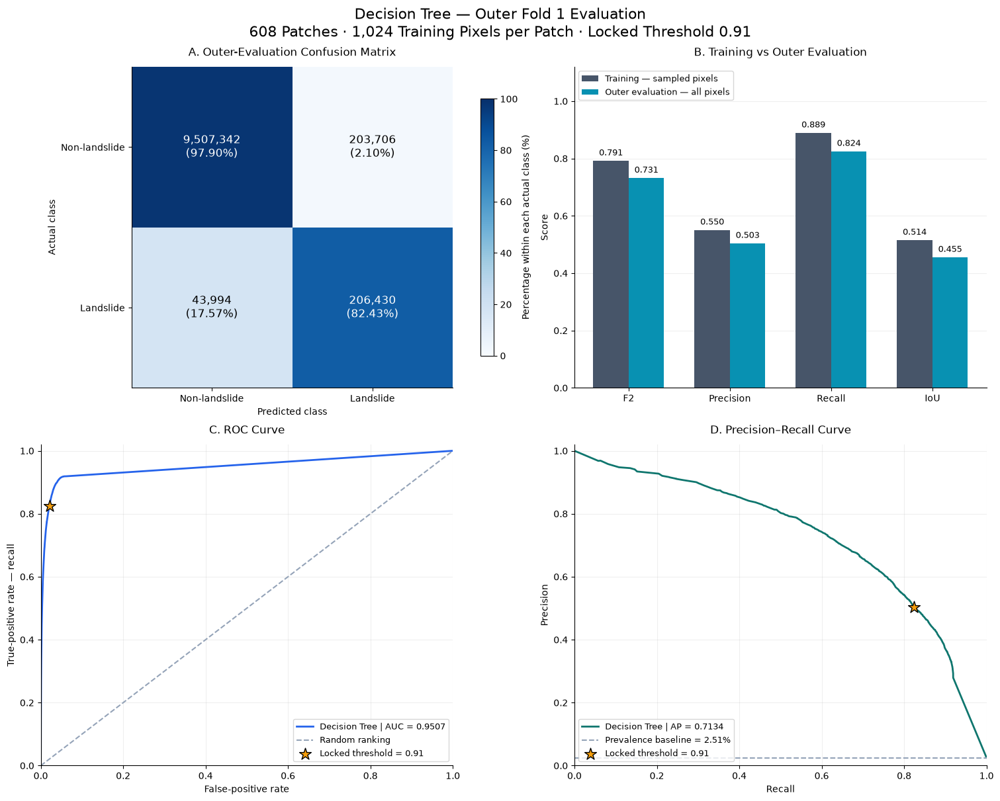

In [36]:
from sklearn.metrics import roc_curve, precision_recall_curve

outer_metrics = dt_outer1_evaluation["metrics"]
training_metrics = dt_outer1_fitted_bundle["training_summary"]

y_outer = dt_outer1_evaluation["y"]
p_outer = dt_outer1_evaluation["probability"]

# Compute curves using all outer-evaluation pixels
dt_outer1_fpr, dt_outer1_tpr, dt_outer1_roc_thresholds = roc_curve(
    y_outer, p_outer
)

dt_outer1_pr_precision, dt_outer1_pr_recall, dt_outer1_pr_thresholds = (
    precision_recall_curve(y_outer, p_outer)
)

outer_prevalence = float(y_outer.mean())

totals = (
    dt_outer1_evaluation["patch_counts"][
        ["TN", "FP", "FN", "TP"]
    ].sum()
)
tn, fp, fn, tp = totals.to_numpy()

confusion_counts = np.array([[tn, fp], [fn, tp]])
row_percentages = (
    confusion_counts
    / confusion_counts.sum(axis=1, keepdims=True)
    * 100
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 12),
    constrained_layout=True
)

# PANEL 1: Confusion matrix
ax = axes[0, 0]

heatmap = ax.imshow(
    row_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

for row in range(2):
    for column in range(2):
        percentage = row_percentages[row, column]

        ax.text(
            column, row,
            f"{confusion_counts[row, column]:,}\n"
            f"({percentage:.2f}%)",
            ha="center",
            va="center",
            fontsize=12,
            color="white" if percentage > 55 else "black"
        )

ax.set_xticks([0, 1], ["Non-landslide", "Landslide"])
ax.set_yticks([0, 1], ["Non-landslide", "Landslide"])
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("A. Outer-Evaluation Confusion Matrix", pad=12)

fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8,
    label="Percentage within each actual class (%)"
)

# PANEL 2: Training versus outer evaluation
ax = axes[0, 1]

comparison_labels = ["F2", "Precision", "Recall", "IoU"]

train_values = [
    training_metrics["training_F2"],
    training_metrics["training_precision"],
    training_metrics["training_recall"],
    training_metrics["training_IoU"]
]

outer_values = [
    outer_metrics["F2"],
    outer_metrics["Precision"],
    outer_metrics["Recall"],
    outer_metrics["IoU"]
]

positions = np.arange(len(comparison_labels))
width = 0.35

for offset, values, color, label in [
    (-width / 2, train_values, "#475569", "Training — sampled pixels"),
    (width / 2, outer_values, "#0891B2", "Outer evaluation — all pixels")
]:
    bars = ax.bar(
        positions + offset,
        values,
        width,
        color=color,
        label=label
    )
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)

ax.set_xticks(positions, comparison_labels)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("B. Training vs Outer Evaluation", pad=12)
ax.legend(loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# PANEL 3: ROC
ax = axes[1, 0]

ax.plot(
    dt_outer1_fpr,
    dt_outer1_tpr,
    color="#2563EB",
    linewidth=2,
    label=f"Decision Tree | AUC = {outer_metrics['ROC_AUC']:.4f}"
)
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#94A3B8",
    label="Random ranking"
)
ax.scatter(
    1 - outer_metrics["Specificity"],
    outer_metrics["Recall"],
    marker="*",
    s=180,
    color="#F59E0B",
    edgecolors="black",
    zorder=5,
    label="Locked threshold = 0.91"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate — recall")
ax.set_title("C. ROC Curve", pad=12)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

# PANEL 4: Precision–recall
ax = axes[1, 1]

ax.plot(
    dt_outer1_pr_recall,
    dt_outer1_pr_precision,
    color="#0F766E",
    linewidth=2,
    label=f"Decision Tree | AP = {outer_metrics['Average_precision']:.4f}"
)
ax.axhline(
    outer_prevalence,
    linestyle="--",
    color="#94A3B8",
    label=f"Prevalence baseline = {outer_prevalence:.2%}"
)
ax.scatter(
    outer_metrics["Recall"],
    outer_metrics["Precision"],
    marker="*",
    s=180,
    color="#F59E0B",
    edgecolors="black",
    zorder=5,
    label="Locked threshold = 0.91"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("D. Precision–Recall Curve", pad=12)
ax.legend(loc="lower left", fontsize=9)
ax.grid(alpha=0.2)

for ax in axes.flat:
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Outer Fold 1 Evaluation\n"
    "608 Patches · 1,024 Training Pixels per Patch · Locked Threshold 0.91",
    fontsize=16
)

plt.show()

### Rationale — Outer-Evaluation Visual Diagnostics

The four panels jointly examine class-specific errors, the training–evaluation gap, ranking performance, and the precision–recall trade-off at the locked threshold.

### Result — Outer Fold 1 Visual Evaluation

The model detected 82.43% of landslide pixels and missed 17.57%. The false-positive rate among non-landslide pixels was 2.10%, producing 203,706 false-positive pixels because the negative class was much larger.

Outer-evaluation F2 was 0.7311, compared with training F2 of 0.7912. Training was assessed on sampled pixels, while outer evaluation covered all pixels in the reserved patches.

ROC AUC was 0.9507 and average precision was 0.7134. The precision–recall prevalence baseline was approximately 2.51%. At the locked threshold of 0.91, recall was 0.8243 and precision was 0.5033.

The ROC and precision–recall curves describe ranking across thresholds. Their marked operating points use the previously selected threshold; no outer-data threshold tuning was performed.

These results describe outer fold 1 only. The remaining outer folds, uncertainty estimates, probability-reliability diagnostics, and spatial-error analyses remain pending.

In [37]:
# Identify this exact search protocol for safe checkpoint reuse
dt_search_protocol = {
    "candidates": dt_candidates,
    "pixels_per_patch": DT_PIXELS_PER_PATCH,
    "search_threshold": DT_BASELINE_THRESHOLD,
    "random_state": RANDOM_STATE,
    "beta": BETA,
    "feature_names": FEATURE_NAMES,
    "nested_splits": nested_splits,
    "sampled_patch_ids": np.asarray(sampled_patch_ids),
    "X_shape": X_patch_samples.shape,
    "y_shape": y_patch_samples.shape,
    "handoff_directory": str(HANDOFF_DIR)
}

dt_search_signature = joblib.hash(dt_search_protocol)

DT_CHECKPOINT_DIR = (
    PROJECT_DIR
    / "artifacts"
    / "decision_tree_checkpoints"
    / dt_search_signature
)
DT_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def save_dt_search_checkpoint(outer_number, search_result):
    target = (
        DT_CHECKPOINT_DIR
        / f"outer_{outer_number}_initial_search.joblib"
    )
    temporary = target.with_suffix(".joblib.tmp")

    joblib.dump(
        {
            "search_signature": dt_search_signature,
            "outer_fold": outer_number,
            "result": search_result
        },
        temporary,
        compress=3
    )

    # Replace only this protocol's checkpoint after a complete write
    temporary.replace(target)


# Preserve the completed first search
save_dt_search_checkpoint(
    outer_number=1,
    search_result=dt_search_results_by_outer[1]
)

for outer_index in range(1, len(nested_splits)):
    outer_number = outer_index + 1
    checkpoint_path = (
        DT_CHECKPOINT_DIR
        / f"outer_{outer_number}_initial_search.joblib"
    )

    print(
        f"\nSTARTING INITIAL SEARCH — OUTER FOLD {outer_number}/5",
        flush=True
    )

    if outer_number in dt_search_results_by_outer:
        print("Using completed result already in memory.", flush=True)

    elif checkpoint_path.exists():
        checkpoint = joblib.load(checkpoint_path)

        if (
            checkpoint["search_signature"] != dt_search_signature
            or checkpoint["outer_fold"] != outer_number
        ):
            raise ValueError("Checkpoint does not match this search.")

        dt_search_results_by_outer[outer_number] = checkpoint["result"]
        print("Loaded completed search from checkpoint.", flush=True)

    else:
        dt_search_results_by_outer[outer_number] = run_dt_inner_search(
            outer_index=outer_index
        )

    save_dt_search_checkpoint(
        outer_number,
        dt_search_results_by_outer[outer_number]
    )

    result = dt_search_results_by_outer[outer_number]

    print(
        f"\nOUTER FOLD {outer_number} — INITIAL SEARCH SAVED",
        flush=True
    )
    print("Selected candidate:", result["best_candidate_id"])
    print("Selected parameters:", result["best_params"])

    display(result["ranking"].head(5).round(6))


# Compare initial selections across all five outer folds
dt_initial_search_summary_rows = []

for outer_number, result in sorted(
    dt_search_results_by_outer.items()
):
    best_row = result["ranking"].iloc[0]

    dt_initial_search_summary_rows.append({
        "outer_fold": outer_number,
        "selected_candidate": result["best_candidate_id"],
        "mean_inner_F2": best_row["mean_inner_F2"],
        "sd_inner_F2": best_row["sd_inner_F2"],
        "search_minutes": result["search_seconds"] / 60,
        **result["best_params"]
    })

dt_initial_search_summary = pd.DataFrame(
    dt_initial_search_summary_rows
)

print("\nINITIAL HYPERPARAMETER SEARCH — ALL OUTER FOLDS")
display(dt_initial_search_summary.round(6))

print("\nCheckpoint directory:")
print(DT_CHECKPOINT_DIR)


STARTING INITIAL SEARCH — OUTER FOLD 2/5

Outer fold 2 | Inner fold 1/3
  Candidate 00 fitted (1/25) | 13.79 s
  Candidate 01 fitted (2/25) | 5.99 s
  Candidate 02 fitted (3/25) | 3.17 s
  Candidate 03 fitted (4/25) | 6.17 s
  Candidate 04 fitted (5/25) | 5.33 s
  Candidate 05 fitted (6/25) | 6.11 s
  Candidate 06 fitted (7/25) | 5.99 s
  Candidate 07 fitted (8/25) | 3.31 s
  Candidate 08 fitted (9/25) | 7.98 s
  Candidate 09 fitted (10/25) | 6.12 s
  Candidate 10 fitted (11/25) | 8.08 s
  Candidate 11 fitted (12/25) | 3.18 s
  Candidate 12 fitted (13/25) | 3.14 s
  Candidate 13 fitted (14/25) | 8.58 s
  Candidate 14 fitted (15/25) | 3.26 s
  Candidate 15 fitted (16/25) | 6.02 s
  Candidate 16 fitted (17/25) | 5.60 s
  Candidate 17 fitted (18/25) | 5.87 s
  Candidate 18 fitted (19/25) | 5.28 s
  Candidate 19 fitted (20/25) | 5.80 s
  Candidate 20 fitted (21/25) | 3.18 s
  Candidate 21 fitted (22/25) | 8.50 s
  Candidate 22 fitted (23/25) | 5.71 s
  Candidate 23 fitted (24/25) | 8.38 s

,candidate_id,mean_inner_F2,sd_inner_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_fit_seconds
0,3,0.681722,0.011239,0.369403,0.864570,0.963981,0.349218,5.876531
1,1,0.657214,0.009082,0.305995,0.921818,0.948964,0.298265,5.696228
2,6,0.638510,0.011952,0.280821,0.937159,0.941366,0.275637,5.652743
3,15,0.629175,0.012611,0.269342,0.945176,0.937319,0.265196,5.701360
4,10,0.628378,0.017144,0.268615,0.945644,0.937037,0.264526,7.805565



STARTING INITIAL SEARCH — OUTER FOLD 3/5

Outer fold 3 | Inner fold 1/3
  Candidate 00 fitted (1/25) | 5.97 s
  Candidate 01 fitted (2/25) | 6.11 s
  Candidate 02 fitted (3/25) | 3.09 s
  Candidate 03 fitted (4/25) | 6.19 s
  Candidate 04 fitted (5/25) | 5.25 s
  Candidate 05 fitted (6/25) | 5.92 s
  Candidate 06 fitted (7/25) | 6.07 s
  Candidate 07 fitted (8/25) | 3.26 s
  Candidate 08 fitted (9/25) | 7.78 s
  Candidate 09 fitted (10/25) | 5.87 s
  Candidate 10 fitted (11/25) | 7.68 s
  Candidate 11 fitted (12/25) | 3.09 s
  Candidate 12 fitted (13/25) | 3.13 s
  Candidate 13 fitted (14/25) | 8.48 s
  Candidate 14 fitted (15/25) | 3.29 s
  Candidate 15 fitted (16/25) | 6.09 s
  Candidate 16 fitted (17/25) | 5.67 s
  Candidate 17 fitted (18/25) | 5.84 s
  Candidate 18 fitted (19/25) | 5.21 s
  Candidate 19 fitted (20/25) | 5.88 s
  Candidate 20 fitted (21/25) | 3.08 s
  Candidate 21 fitted (22/25) | 8.38 s
  Candidate 22 fitted (23/25) | 5.68 s
  Candidate 23 fitted (24/25) | 8.41 s


,candidate_id,mean_inner_F2,sd_inner_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_fit_seconds
0,3,0.688680,0.009027,0.380407,0.863957,0.965456,0.358874,6.209600
1,1,0.660730,0.012970,0.308579,0.924839,0.949216,0.301039,5.919998
2,6,0.642068,0.012672,0.283297,0.939935,0.941755,0.278264,5.831949
3,15,0.634792,0.009064,0.274364,0.945415,0.938750,0.270088,5.906187
4,16,0.630400,0.019273,0.272670,0.939630,0.938374,0.267936,5.453686



STARTING INITIAL SEARCH — OUTER FOLD 4/5

Outer fold 4 | Inner fold 1/3
  Candidate 00 fitted (1/25) | 5.80 s
  Candidate 01 fitted (2/25) | 5.87 s
  Candidate 02 fitted (3/25) | 3.14 s
  Candidate 03 fitted (4/25) | 6.02 s
  Candidate 04 fitted (5/25) | 5.18 s
  Candidate 05 fitted (6/25) | 6.05 s
  Candidate 06 fitted (7/25) | 5.80 s
  Candidate 07 fitted (8/25) | 3.33 s
  Candidate 08 fitted (9/25) | 7.88 s
  Candidate 09 fitted (10/25) | 6.09 s
  Candidate 10 fitted (11/25) | 7.91 s
  Candidate 11 fitted (12/25) | 3.18 s
  Candidate 12 fitted (13/25) | 3.11 s
  Candidate 13 fitted (14/25) | 8.59 s
  Candidate 14 fitted (15/25) | 3.27 s
  Candidate 15 fitted (16/25) | 5.77 s
  Candidate 16 fitted (17/25) | 5.52 s
  Candidate 17 fitted (18/25) | 5.78 s
  Candidate 18 fitted (19/25) | 5.21 s
  Candidate 19 fitted (20/25) | 5.61 s
  Candidate 20 fitted (21/25) | 3.17 s
  Candidate 21 fitted (22/25) | 8.42 s
  Candidate 22 fitted (23/25) | 5.54 s
  Candidate 23 fitted (24/25) | 7.77 s


...


STARTING INITIAL SEARCH — OUTER FOLD 5/5

Outer fold 5 | Inner fold 1/3
  Candidate 00 fitted (1/25) | 5.77 s
  Candidate 01 fitted (2/25) | 6.29 s
  Candidate 02 fitted (3/25) | 3.13 s
  Candidate 03 fitted (4/25) | 6.40 s
  Candidate 04 fitted (5/25) | 5.28 s
  Candidate 05 fitted (6/25) | 5.99 s
  Candidate 06 fitted (7/25) | 6.22 s
  Candidate 07 fitted (8/25) | 3.32 s
  Candidate 08 fitted (9/25) | 7.90 s
  Candidate 09 fitted (10/25) | 6.02 s
  Candidate 10 fitted (11/25) | 7.86 s
  Candidate 11 fitted (12/25) | 3.14 s
  Candidate 12 fitted (13/25) | 3.13 s
  Candidate 13 fitted (14/25) | 8.85 s
  Candidate 14 fitted (15/25) | 3.23 s
  Candidate 15 fitted (16/25) | 6.24 s
  Candidate 16 fitted (17/25) | 5.75 s
  Candidate 17 fitted (18/25) | 5.83 s
  Candidate 18 fitted (19/25) | 5.22 s
  Candidate 19 fitted (20/25) | 5.59 s
  Candidate 20 fitted (21/25) | 3.15 s
  Candidate 21 fitted (22/25) | 8.57 s
  Candidate 22 fitted (23/25) | 5.78 s
  Candidate 23 fitted (24/25) | 8.66 s


,candidate_id,mean_inner_F2,sd_inner_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_fit_seconds
0,3,0.682925,0.001930,0.371994,0.863358,0.964463,0.351306,6.074978
1,1,0.655694,0.004806,0.303792,0.923024,0.948420,0.296287,5.939749
2,6,0.632806,0.014193,0.275349,0.937453,0.939813,0.270383,5.871682
3,16,0.632761,0.010868,0.276315,0.934554,0.940226,0.271047,5.551918
4,15,0.629992,0.008688,0.271496,0.940601,0.938470,0.266925,5.909241



INITIAL HYPERPARAMETER SEARCH — ALL OUTER FOLDS


,outer_fold,selected_candidate,mean_inner_F2,sd_inner_F2,search_minutes,min_samples_split,min_samples_leaf,max_depth,criterion,class_weight,ccp_alpha
0,1,3,0.681813,0.018980,9.373777,2,5,15,entropy,balanced,0.00001
1,2,3,0.681722,0.011239,7.719099,2,5,15,entropy,balanced,0.00001
2,3,3,0.688680,0.009027,7.544719,2,5,15,entropy,balanced,0.00001
3,4,3,0.667506,0.011773,7.455876,2,5,15,entropy,balanced,0.00001
4,5,3,0.682925,0.001930,7.513091,2,5,15,entropy,balanced,0.00001



Checkpoint directory:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_checkpoints\fb68d01cf38fc3e53e6685386ece1d0e


### Rationale — Initial Search Across All Outer Folds

The same 25 configurations were evaluated independently within each outer training partition, using three inner folds. This checks whether the initial hyperparameter selection is stable across different training partitions.

### Result — Initial Hyperparameter Selection

Candidate 3 achieved the highest mean inner-validation F2 in all five outer folds.

Its settings were max_depth=15, min_samples_leaf=5, min_samples_split=2, criterion="entropy", class_weight="balanced", and ccp_alpha=0.00001.

Selected mean inner-validation F2 values were:

- Outer fold 1: 0.681813.
- Outer fold 2: 0.681722.
- Outer fold 3: 0.688680.
- Outer fold 4: 0.667506.
- Outer fold 5: 0.682925.

These searches used 512 sampled training pixels per patch and threshold 0.50. Completed results were checkpointed.

The repeated selection indicates stability within the tested candidate set. It does not establish a global optimum, and the overlapping training partitions are not independent experiments.

These are selection-stage scores. Only outer fold 1 has completed the subsequent pipeline selection and outer evaluation.

### Visualization Decision

A candidate-by-outer-fold heatmap is appropriate to show the performance of all configurations and the consistency of the selected candidate.

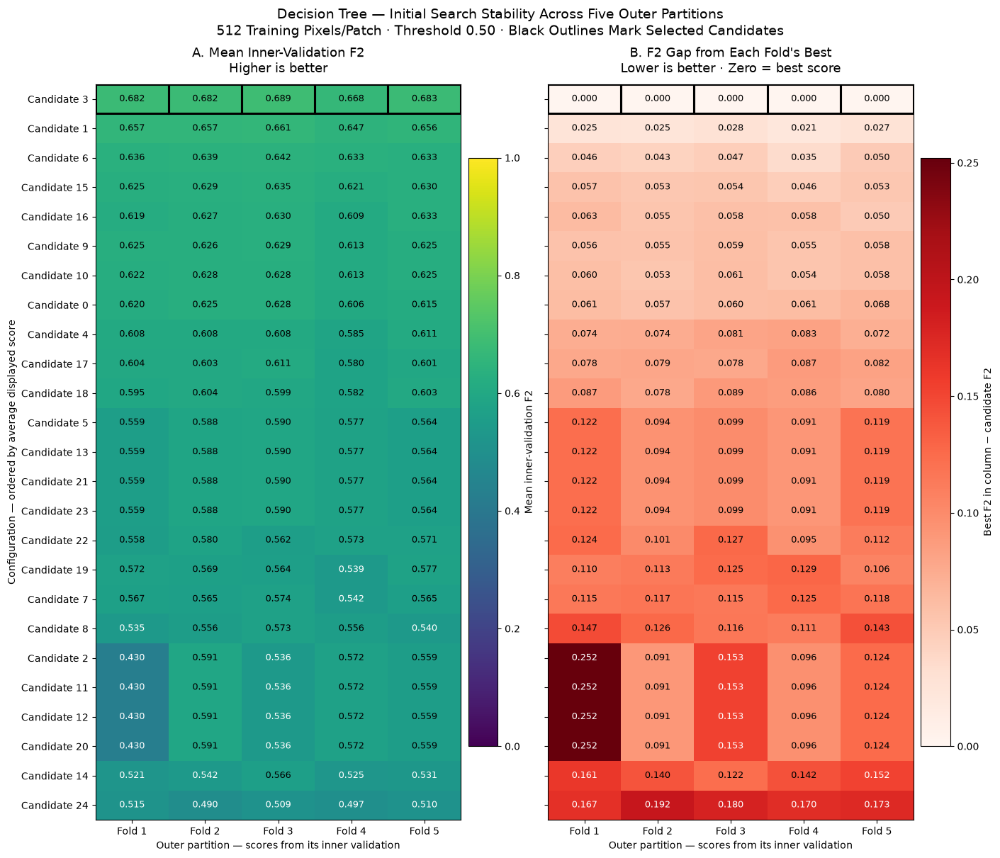

In [38]:
from matplotlib.patches import Rectangle

# Collect all candidate scores from the five completed searches
dt_search_heatmap_source = pd.concat(
    [
        result["ranking"].assign(outer_fold=outer_number)
        for outer_number, result in sorted(
            dt_search_results_by_outer.items()
        )
    ],
    ignore_index=True
)

dt_search_score_matrix = (
    dt_search_heatmap_source
    .pivot(
        index="candidate_id",
        columns="outer_fold",
        values="mean_inner_F2"
    )
    .reindex(columns=[1, 2, 3, 4, 5])
)

assert dt_search_score_matrix.shape == (25, 5)
assert np.isfinite(dt_search_score_matrix.to_numpy()).all()

# Order rows for display only; this does not select a new model
candidate_display_order = (
    dt_search_score_matrix.mean(axis=1)
    .sort_values(ascending=False, kind="stable")
    .index
)

dt_search_score_matrix = dt_search_score_matrix.loc[
    candidate_display_order
]

dt_search_gap_matrix = (
    dt_search_score_matrix.max(axis=0)
    - dt_search_score_matrix
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 12),
    constrained_layout=True
)

score_values = dt_search_score_matrix.to_numpy()
gap_values = dt_search_gap_matrix.to_numpy()
maximum_gap = max(float(gap_values.max()), 0.001)

left_image = axes[0].imshow(
    score_values,
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1
)

right_image = axes[1].imshow(
    gap_values,
    cmap="Reds",
    aspect="auto",
    vmin=0,
    vmax=maximum_gap
)

for row in range(len(candidate_display_order)):
    candidate_id = int(candidate_display_order[row])

    for column, outer_number in enumerate([1, 2, 3, 4, 5]):
        score = score_values[row, column]
        gap = gap_values[row, column]

        axes[0].text(
            column, row, f"{score:.3f}",
            ha="center", va="center",
            fontsize=9,
            color="white" if score < 0.55 else "black"
        )

        axes[1].text(
            column, row, f"{gap:.3f}",
            ha="center", va="center",
            fontsize=9,
            color="white" if gap > maximum_gap * 0.6 else "black"
        )

        selected_id = dt_search_results_by_outer[
            outer_number
        ]["best_candidate_id"]

        if candidate_id == selected_id:
            for ax in axes:
                ax.add_patch(Rectangle(
                    (column - 0.5, row - 0.5),
                    1, 1,
                    fill=False,
                    edgecolor="black",
                    linewidth=2.2
                ))

for ax in axes:
    ax.set_xticks(
        range(5),
        [f"Fold {i}" for i in range(1, 6)]
    )
    ax.set_xlabel("Outer partition — scores from its inner validation")
    ax.set_yticks(range(len(candidate_display_order)))
    ax.tick_params(axis="both", labelsize=10)

axes[0].set_yticklabels([
    f"Candidate {int(i)}"
    for i in candidate_display_order
])
axes[0].set_ylabel("Configuration — ordered by average displayed score")

axes[1].tick_params(axis="y", labelleft=False)

axes[0].set_title(
    "A. Mean Inner-Validation F2\nHigher is better",
    fontsize=13,
    pad=12
)
axes[1].set_title(
    "B. F2 Gap from Each Fold's Best\nLower is better · Zero = best score",
    fontsize=13,
    pad=12
)

fig.colorbar(
    left_image, ax=axes[0],
    shrink=0.8, pad=0.02,
    label="Mean inner-validation F2"
)
fig.colorbar(
    right_image, ax=axes[1],
    shrink=0.8, pad=0.02,
    label="Best F2 in column − candidate F2"
)

fig.suptitle(
    "Decision Tree — Initial Search Stability Across Five Outer Partitions\n"
    "512 Training Pixels/Patch · Threshold 0.50 · "
    "Black Outlines Mark Selected Candidates",
    fontsize=14
)

plt.show()

### Rationale — Visualizing Initial Search Stability

The heatmaps show all 25 configurations across five outer training partitions. Absolute scores and gaps from each partition's best score provide complementary views of selection stability.

### Result — Candidate-by-Fold Heatmaps

Candidate 3 ranked first in all five initial searches. Candidate 1 consistently ranked second, with mean inner-validation F2 approximately 0.021–0.028 below the winner. Candidate 6 consistently ranked third.

Several configurations share identical displayed scores. Rounded metric agreement does not establish identical fitted trees or pixel predictions. Other configurations show greater sensitivity to the training partition.

The repeated ranking supports selection stability within the tested candidate set. It does not establish a global optimum or statistical superiority.

All values are inner-selection scores obtained with 512 training pixels per patch and threshold 0.50. They are not outer-evaluation results. No additional plot is needed for this diagnostic.

In [39]:
def run_dt_local_refinement(outer_index):
    outer_number = outer_index + 1
    initial_search = dt_search_results_by_outer[outer_number]

    candidates, changes = make_dt_simplification_candidates(
        initial_search["best_params"]
    )

    start_time = perf_counter()

    # Reuse the reference's original three inner-fold results
    reference = initial_search["fold_results"].loc[
        lambda table:
            table["candidate_id"] == initial_search["best_candidate_id"]
    ].copy()

    assert len(reference) == 3

    reference["candidate_id"] = 0
    reference["reused_from_initial_search"] = True
    frames = [reference]

    for inner_number, inner in enumerate(
        nested_splits[outer_index]["inner_splits"],
        start=1
    ):
        print(
            f"\nOuter {outer_number}/5 | "
            f"Local refinement | Inner {inner_number}/3",
            flush=True
        )

        X_fit, y_fit = get_sampled_pixels(
            inner["train_ids"],
            pixels_per_patch=DT_PIXELS_PER_PATCH
        )

        models = {}
        fit_times = {}
        depths = {}
        leaves = {}

        for local_id, params in enumerate(candidates[1:], start=1):
            model = DecisionTreeClassifier(
                **params,
                random_state=RANDOM_STATE
            )

            fit_start = perf_counter()
            model.fit(X_fit, y_fit)

            models[local_id] = model
            fit_times[local_id] = perf_counter() - fit_start
            depths[local_id] = model.get_depth()
            leaves[local_id] = model.get_n_leaves()

            print(
                f"  Local candidate {local_id}/{len(candidates) - 1}"
                f" fitted | {fit_times[local_id]:.2f} s",
                flush=True
            )

        print("  Evaluating full validation patches...", flush=True)

        scores = evaluate_dt_candidates_full_patches(
            models=models,
            patch_ids=inner["validation_ids"],
            threshold=DT_BASELINE_THRESHOLD
        )

        scores["outer_fold"] = outer_number
        scores["inner_fold"] = inner_number
        scores["fit_seconds"] = scores["candidate_id"].map(fit_times)
        scores["tree_depth"] = scores["candidate_id"].map(depths)
        scores["n_leaves"] = scores["candidate_id"].map(leaves)
        scores["reused_from_initial_search"] = False

        frames.append(scores)
        del models, model, X_fit, y_fit

    results = (
        pd.concat(frames, ignore_index=True)
        .rename(columns={"candidate_id": "local_candidate_id"})
    )

    assert len(results) == len(candidates) * 3
    assert not results.duplicated(
        ["local_candidate_id", "inner_fold"]
    ).any()

    ranking = (
        results.groupby("local_candidate_id", as_index=False)
        .agg(
            mean_F2=("F2", "mean"),
            sd_F2=("F2", "std"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_depth=("tree_depth", "mean"),
            mean_leaves=("n_leaves", "mean")
        )
    )

    ranking["change"] = ranking["local_candidate_id"].map(
        dict(enumerate(changes))
    )

    reference_f2 = float(
        ranking.loc[
            ranking["local_candidate_id"] == 0, "mean_F2"
        ].iloc[0]
    )

    ranking["F2_difference_from_reference"] = (
        ranking["mean_F2"] - reference_f2
    )

    ranking = ranking.sort_values(
        ["mean_F2", "mean_leaves", "local_candidate_id"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    selected_id = int(ranking.iloc[0]["local_candidate_id"])

    return {
        "fold_results": results,
        "ranking": ranking,
        "selected_local_id": selected_id,
        "selected_params": dict(candidates[selected_id]),
        "candidates": candidates,
        "changes": changes,
        "elapsed_seconds": perf_counter() - start_time
    }


if "dt_refinement_results_by_outer" not in globals():
    dt_refinement_results_by_outer = {
        1: dt_outer1_refinement_result
    }

# Signature identifies the search settings and refinement rule
dt_refinement_signature = joblib.hash({
    "initial_search_signature": dt_search_signature,
    "rule_version": "depth_minus_3_6_leaf_times_2_4_alpha_times_10_100",
    "selection": "maximum_mean_F2_then_fewer_mean_leaves_then_local_id"
})

for outer_index in range(1, len(nested_splits)):
    outer_number = outer_index + 1

    checkpoint_path = (
        DT_CHECKPOINT_DIR
        / f"outer_{outer_number}_local_refinement.joblib"
    )

    print(
        f"\nLOCAL REFINEMENT — OUTER FOLD {outer_number}/5",
        flush=True
    )

    if outer_number in dt_refinement_results_by_outer:
        print("Using completed result in memory.", flush=True)

    elif checkpoint_path.exists():
        checkpoint = joblib.load(checkpoint_path)

        if (
            checkpoint["signature"] != dt_refinement_signature
            or checkpoint["outer_fold"] != outer_number
        ):
            raise ValueError("Refinement checkpoint does not match.")

        dt_refinement_results_by_outer[outer_number] = checkpoint["result"]
        print("Loaded completed refinement.", flush=True)

    else:
        dt_refinement_results_by_outer[outer_number] = (
            run_dt_local_refinement(outer_index)
        )

    result = dt_refinement_results_by_outer[outer_number]

    temporary_path = checkpoint_path.with_suffix(".joblib.tmp")

    joblib.dump(
        {
            "signature": dt_refinement_signature,
            "outer_fold": outer_number,
            "result": result
        },
        temporary_path,
        compress=3
    )
    temporary_path.replace(checkpoint_path)

    print("Selected local candidate:", result["selected_local_id"])
    print("Selected parameters:", result["selected_params"])
    display(result["ranking"].head(3).round(6))


dt_refinement_summary_rows = []

for outer_number, result in sorted(
    dt_refinement_results_by_outer.items()
):
    best = result["ranking"].iloc[0]

    dt_refinement_summary_rows.append({
        "outer_fold": outer_number,
        "selected_local_candidate": result["selected_local_id"],
        "selected_change": best["change"],
        "mean_inner_F2": best["mean_F2"],
        "F2_gain_over_reference": best["F2_difference_from_reference"],
        "mean_leaves": best["mean_leaves"],
        "refinement_minutes": result["elapsed_seconds"] / 60,
        **result["selected_params"]
    })

dt_refinement_summary = pd.DataFrame(dt_refinement_summary_rows)

print("\nLOCAL REFINEMENT — ALL FIVE OUTER PARTITIONS")
display(dt_refinement_summary.round(6))


LOCAL REFINEMENT — OUTER FOLD 2/5

Outer 2/5 | Local refinement | Inner 1/3
  Local candidate 1/6 fitted | 5.82 s
  Local candidate 2/6 fitted | 5.45 s
  Local candidate 3/6 fitted | 6.17 s
  Local candidate 4/6 fitted | 6.20 s
  Local candidate 5/6 fitted | 6.20 s
  Local candidate 6/6 fitted | 6.24 s
  Evaluating full validation patches...

Outer 2/5 | Local refinement | Inner 2/3
  Local candidate 1/6 fitted | 5.54 s
  Local candidate 2/6 fitted | 5.06 s
  Local candidate 3/6 fitted | 5.69 s
  Local candidate 4/6 fitted | 5.70 s
  Local candidate 5/6 fitted | 5.76 s
  Local candidate 6/6 fitted | 5.76 s
  Evaluating full validation patches...

Outer 2/5 | Local refinement | Inner 3/3
  Local candidate 1/6 fitted | 5.28 s
  Local candidate 2/6 fitted | 4.85 s
  Local candidate 3/6 fitted | 5.38 s
  Local candidate 4/6 fitted | 8.33 s
  Local candidate 5/6 fitted | 41.49 s
  Local candidate 6/6 fitted | 28.17 s
  Evaluating full validation patches...
Selected local candidate: 0
Selec

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.681722,0.011239,0.369403,0.864570,0.349218,15.0,1979.666667,Reference — current selected parameters,0.000000
1,3,0.681158,0.010079,0.358293,0.879380,0.341522,15.0,1797.000000,min_samples_leaf → 10,-0.000564
2,4,0.672520,0.009076,0.332813,0.903009,0.321342,15.0,1567.000000,min_samples_leaf → 20,-0.009202



LOCAL REFINEMENT — OUTER FOLD 3/5

Outer 3/5 | Local refinement | Inner 1/3
  Local candidate 1/6 fitted | 5.99 s
  Local candidate 2/6 fitted | 5.31 s
  Local candidate 3/6 fitted | 5.86 s
  Local candidate 4/6 fitted | 5.87 s
  Local candidate 5/6 fitted | 6.17 s
  Local candidate 6/6 fitted | 6.29 s
  Evaluating full validation patches...

Outer 3/5 | Local refinement | Inner 2/3
  Local candidate 1/6 fitted | 9.09 s
  Local candidate 2/6 fitted | 5.36 s
  Local candidate 3/6 fitted | 6.14 s
  Local candidate 4/6 fitted | 6.00 s
  Local candidate 5/6 fitted | 6.11 s
  Local candidate 6/6 fitted | 6.10 s
  Evaluating full validation patches...

Outer 3/5 | Local refinement | Inner 3/3
  Local candidate 1/6 fitted | 5.98 s
  Local candidate 2/6 fitted | 5.43 s
  Local candidate 3/6 fitted | 6.36 s
  Local candidate 4/6 fitted | 6.48 s
  Local candidate 5/6 fitted | 6.42 s
  Local candidate 6/6 fitted | 6.21 s
  Evaluating full validation patches...
Selected local candidate: 0
Selecte

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.688680,0.009027,0.380407,0.863957,0.358874,15.0,2001.000000,Reference — current selected parameters,0.000000
1,3,0.687869,0.011651,0.367921,0.879253,0.350224,15.0,1806.000000,min_samples_leaf → 10,-0.000810
2,4,0.679907,0.011294,0.342527,0.902397,0.330279,15.0,1584.666667,min_samples_leaf → 20,-0.008772



LOCAL REFINEMENT — OUTER FOLD 4/5

Outer 4/5 | Local refinement | Inner 1/3
  Local candidate 1/6 fitted | 5.77 s
  Local candidate 2/6 fitted | 5.17 s
  Local candidate 3/6 fitted | 5.94 s
  Local candidate 4/6 fitted | 5.87 s
  Local candidate 5/6 fitted | 5.92 s
  Local candidate 6/6 fitted | 5.99 s
  Evaluating full validation patches...

Outer 4/5 | Local refinement | Inner 2/3
  Local candidate 1/6 fitted | 5.81 s
  Local candidate 2/6 fitted | 5.11 s
  Local candidate 3/6 fitted | 6.04 s
  Local candidate 4/6 fitted | 5.94 s
  Local candidate 5/6 fitted | 5.98 s
  Local candidate 6/6 fitted | 24.45 s
  Evaluating full validation patches...

Outer 4/5 | Local refinement | Inner 3/3
  Local candidate 1/6 fitted | 53.30 s
  Local candidate 2/6 fitted | 43.53 s
  Local candidate 3/6 fitted | 11.82 s
  Local candidate 4/6 fitted | 5.90 s
  Local candidate 5/6 fitted | 5.79 s
  Local candidate 6/6 fitted | 5.86 s
  Evaluating full validation patches...
Selected local candidate: 0
Sel

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.667506,0.011773,0.349069,0.864839,0.331040,15.0,1970.666667,Reference — current selected parameters,0.000000
1,3,0.667038,0.011225,0.340348,0.877780,0.324971,15.0,1804.333333,min_samples_leaf → 10,-0.000468
2,4,0.660137,0.010481,0.318748,0.901721,0.308057,15.0,1573.666667,min_samples_leaf → 20,-0.007369



LOCAL REFINEMENT — OUTER FOLD 5/5

Outer 5/5 | Local refinement | Inner 1/3
  Local candidate 1/6 fitted | 6.23 s
  Local candidate 2/6 fitted | 5.41 s
  Local candidate 3/6 fitted | 6.22 s
  Local candidate 4/6 fitted | 9.12 s
  Local candidate 5/6 fitted | 6.32 s
  Local candidate 6/6 fitted | 6.28 s
  Evaluating full validation patches...

Outer 5/5 | Local refinement | Inner 2/3
  Local candidate 1/6 fitted | 5.78 s
  Local candidate 2/6 fitted | 5.30 s
  Local candidate 3/6 fitted | 6.04 s
  Local candidate 4/6 fitted | 6.08 s
  Local candidate 5/6 fitted | 6.05 s
  Local candidate 6/6 fitted | 6.10 s
  Evaluating full validation patches...

Outer 5/5 | Local refinement | Inner 3/3
  Local candidate 1/6 fitted | 5.88 s
  Local candidate 2/6 fitted | 5.35 s
  Local candidate 3/6 fitted | 6.11 s
  Local candidate 4/6 fitted | 6.01 s
  Local candidate 5/6 fitted | 6.11 s
  Local candidate 6/6 fitted | 6.09 s
  Evaluating full validation patches...
Selected local candidate: 0
Selecte

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.682925,0.001930,0.371994,0.863358,0.351306,15.0,2064.000000,Reference — current selected parameters,0.000000
1,3,0.681953,0.003485,0.359190,0.879607,0.342352,15.0,1842.333333,min_samples_leaf → 10,-0.000972
2,4,0.672334,0.003756,0.333111,0.902060,0.321473,15.0,1608.666667,min_samples_leaf → 20,-0.010592



LOCAL REFINEMENT — ALL FIVE OUTER PARTITIONS


,outer_fold,selected_local_candidate,selected_change,mean_inner_F2,F2_gain_over_reference,mean_leaves,refinement_minutes,min_samples_split,min_samples_leaf,max_depth,criterion,class_weight,ccp_alpha
0,1,0,Reference — current selected parameters,0.681813,0.0,1907.666667,2.091976,2,5,15,entropy,balanced,0.00001
1,2,0,Reference — current selected parameters,0.681722,0.0,1979.666667,2.931926,2,5,15,entropy,balanced,0.00001
2,3,0,Reference — current selected parameters,0.688680,0.0,2001.000000,2.080400,2,5,15,entropy,balanced,0.00001
3,4,0,Reference — current selected parameters,0.667506,0.0,1970.666667,4.430604,2,5,15,entropy,balanced,0.00001
4,5,0,Reference — current selected parameters,0.682925,0.0,2064.000000,2.063138,2,5,15,entropy,balanced,0.00001


### Rationale — Local Refinement Across Outer Partitions

The same limited complexity-control rule was applied within each outer training partition. Six alternatives examined reduced depth, larger minimum leaf size, and stronger pruning relative to that partition's initial winner.

### Result — Local Refinement

The reference configuration, local candidate 0, retained the highest mean inner-validation F2 in all five partitions. It corresponds to candidate 3 from the initial search:

max_depth=15, min_samples_leaf=5, min_samples_split=2, criterion="entropy", class_weight="balanced", and ccp_alpha=0.00001.

Selected mean F2 values remained 0.681813, 0.681722, 0.688680, 0.667506, and 0.682925.

Increasing minimum leaf size to 10 reduced tree size while producing very similar scores. In partitions 2–5, its F2 decrease was approximately 0.0005–0.0010. The predefined maximum-mean-F2 rule nevertheless retained the reference; these small differences do not establish statistical superiority.

All comparisons used 512 training pixels per patch and threshold 0.50. No outer-evaluation predictions were used for this local selection.

### Visualization Decision

The table sufficiently documents the unchanged selections. A consolidated complexity-versus-performance plot can additionally show the trade-off between leaf count and F2 without repeating separate plots for every partition.

In [40]:
def prepare_dt_calibration_splits(outer_index):
    outer_fold = nested_splits[outer_index]

    outer_train_set = set(
        str(i) for i in outer_fold["train_ids"]
    )
    outer_evaluation_set = set(
        str(i) for i in outer_fold["evaluation_ids"]
    )
    holdout_set = set(str(i) for i in test_ids)

    assert outer_train_set.isdisjoint(outer_evaluation_set)
    assert outer_train_set | outer_evaluation_set == set(
        str(i) for i in dev_ids
    )
    assert (outer_train_set | outer_evaluation_set).isdisjoint(
        holdout_set
    )

    prepared_splits = []

    for inner_number, inner in enumerate(
        outer_fold["inner_splits"],
        start=1
    ):
        train_ids = np.asarray([
            str(i) for i in inner["train_ids"]
        ])
        validation_ids = np.asarray([
            str(i) for i in inner["validation_ids"]
        ])

        presence = dt_presence_by_id.reindex(train_ids)

        if presence.isna().any():
            raise ValueError("Missing patch-presence information.")

        if not np.isfinite(
            presence.to_numpy(dtype=float)
        ).all():
            raise ValueError("Invalid patch-presence values.")

        strata = (presence.to_numpy() > 0).astype(int)

        _, stratum_counts = np.unique(
            strata,
            return_counts=True
        )
        if stratum_counts.min() < 2:
            raise ValueError("Too few patches for stratified splitting.")

        fit_ids, calibration_ids = train_test_split(
            train_ids,
            test_size=CALIBRATION_FRACTION,
            random_state=RANDOM_STATE,
            stratify=strata
        )

        fit_set = set(fit_ids)
        calibration_set = set(calibration_ids)
        validation_set = set(validation_ids)

        assert fit_set.isdisjoint(calibration_set)
        assert fit_set.isdisjoint(validation_set)
        assert calibration_set.isdisjoint(validation_set)

        assert fit_set | calibration_set == set(train_ids)
        assert set(train_ids).isdisjoint(validation_set)

        all_inner_ids = (
            fit_set | calibration_set | validation_set
        )

        assert all_inner_ids == outer_train_set
        assert all_inner_ids.isdisjoint(outer_evaluation_set)
        assert all_inner_ids.isdisjoint(holdout_set)

        prepared_splits.append({
            "inner_fold": inner_number,
            "train_ids": train_ids,
            "fit_ids": fit_ids,
            "calibration_ids": calibration_ids,
            "validation_ids": validation_ids
        })

    return prepared_splits


# Preserve the already prepared splits for outer fold 1
if "dt_calibration_splits_by_outer" not in globals():
    dt_calibration_splits_by_outer = {
        1: dt_outer1_calibration_splits
    }

for outer_index in range(1, len(nested_splits)):
    outer_number = outer_index + 1

    if outer_number not in dt_calibration_splits_by_outer:
        dt_calibration_splits_by_outer[outer_number] = (
            prepare_dt_calibration_splits(outer_index)
        )

# Summarize all 15 inner splits
dt_all_calibration_split_rows = []

for outer_number, splits in sorted(
    dt_calibration_splits_by_outer.items()
):
    for split in splits:
        dt_all_calibration_split_rows.append({
            "outer_fold": outer_number,
            "inner_fold": split["inner_fold"],
            "all_inner_training_patches": len(split["train_ids"]),
            "tree_fitting_patches": len(split["fit_ids"]),
            "calibration_patches": len(split["calibration_ids"]),
            "validation_patches": len(split["validation_ids"]),
            "fit_calibration_overlap": len(
                set(split["fit_ids"]) & set(split["calibration_ids"])
            )
        })

dt_all_calibration_split_table = pd.DataFrame(
    dt_all_calibration_split_rows
)

assert len(dt_all_calibration_split_table) == 15
assert (
    dt_all_calibration_split_table["fit_calibration_overlap"] == 0
).all()

print("Prepared outer partitions:", len(dt_calibration_splits_by_outer))
print("Prepared inner splits:", len(dt_all_calibration_split_table))
print("Calibration fraction:", CALIBRATION_FRACTION)
print("No models fitted by this cell.")

display(dt_all_calibration_split_table)

Prepared outer partitions: 5
Prepared inner splits: 15
Calibration fraction: 0.2
No models fitted by this cell.


,outer_fold,inner_fold,all_inner_training_patches,tree_fitting_patches,calibration_patches,validation_patches,fit_calibration_overlap
0,1,1,1620,1296,324,811,0
1,1,2,1621,1296,325,810,0
2,1,3,1621,1296,325,810,0
3,2,1,1620,1296,324,811,0
4,2,2,1621,1296,325,810,0
5,2,3,1621,1296,325,810,0
6,3,1,1620,1296,324,811,0
7,3,2,1621,1296,325,810,0
8,3,3,1621,1296,325,810,0
9,4,1,1620,1296,324,811,0


### Rationale — Calibration Splits Across All Outer Partitions

Separate tree-fitting and calibration subsets were prepared within each inner-training partition. Inner-validation, outer-evaluation, and holdout patches remain excluded from both fitting subsets.

### Result — Split Preparation Completed

Calibration splits are available for all five outer partitions, giving 15 inner splits in total.

- Inner-training patches: 1,620–1,622.
- Calibration-base tree-fitting patches: 1,296–1,297.
- Calibration patches: 324–325.
- Inner-validation patches: 810–811.

The saved calibration fraction of 20% was used. All 15 splits have zero overlap between tree-fitting and calibration patches. Small count differences reflect partition sizes and integer rounding.

No new models were fitted by this cell.

### Visualization Decision

No additional plot is needed. The table adequately documents split sizes and the overlap check.

In [41]:
# Identify the complete, fixed selection procedure
dt_pipeline_signature = joblib.hash({
    "initial_search_signature": dt_search_signature,
    "refinement_signature": dt_refinement_signature,
    "selected_parameters": {
        fold: result["selected_params"]
        for fold, result in dt_refinement_results_by_outer.items()
    },
    "calibration_splits": dt_calibration_splits_by_outer,
    "sample_sizes": [512, 1024],
    "thresholds": dt_threshold_grid,
    "methods": DT_SELECTION_METHODS,
    "calibration_fraction": CALIBRATION_FRACTION,
    "sigmoid_C": PLATT_C,
    "sigmoid_input": "raw_tree_probability",
    "sigmoid_solver": "lbfgs",
    "sigmoid_max_iter": 1000,
    "random_state": RANDOM_STATE,
    "beta": BETA,
    "tie_rule": "smaller_sample_then_method_order_then_higher_threshold"
})

DT_PIPELINE_CHECKPOINT_DIR = (
    DT_CHECKPOINT_DIR
    / "pipeline_selection"
    / dt_pipeline_signature
)
DT_PIPELINE_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def save_dt_pipeline_checkpoint(path, payload):
    temporary = path.with_suffix(".joblib.tmp")
    joblib.dump(payload, temporary, compress=3)
    temporary.replace(path)


def run_dt_pipeline_selection(outer_number):
    params = dt_refinement_results_by_outer[
        outer_number
    ]["selected_params"]

    probability_frames = []
    threshold_frames = []
    fit_rows = []

    for pixels_per_patch in [512, 1024]:
        for split in dt_calibration_splits_by_outer[outer_number]:
            inner_number = split["inner_fold"]

            print(
                f"\nOuter {outer_number}/5 | "
                f"{pixels_per_patch} pixels/patch | "
                f"Inner {inner_number}/3",
                flush=True
            )

            checkpoint_path = (
                DT_PIPELINE_CHECKPOINT_DIR
                / (
                    f"outer_{outer_number}_pixels_{pixels_per_patch}"
                    f"_inner_{inner_number}.joblib"
                )
            )

            if checkpoint_path.exists():
                completed = joblib.load(checkpoint_path)

                if (
                    completed["signature"] != dt_pipeline_signature
                    or completed["outer_fold"] != outer_number
                    or completed["inner_fold"] != inner_number
                    or completed["pixels_per_patch"] != pixels_per_patch
                ):
                    raise ValueError("Pipeline checkpoint mismatch.")

                print("  Loaded completed task.", flush=True)

            else:
                options = fit_dt_probability_options_for_sample_size(
                    split=split,
                    params=params,
                    pixels_per_patch=pixels_per_patch
                )

                print(
                    "  Evaluating probability quality at threshold 0.50...",
                    flush=True
                )

                probability_scores = evaluate_dt_probability_options(
                    options=options,
                    patch_ids=split["validation_ids"],
                    threshold=DT_BASELINE_THRESHOLD
                )

                print("  Evaluating threshold grid...", flush=True)

                threshold_scores = evaluate_dt_threshold_grid(
                    options=options,
                    patch_ids=split["validation_ids"],
                    thresholds=dt_threshold_grid
                )

                completed = {
                    "signature": dt_pipeline_signature,
                    "outer_fold": outer_number,
                    "inner_fold": inner_number,
                    "pixels_per_patch": pixels_per_patch,
                    "fit_summary": options["summary"],
                    "probability_scores": probability_scores,
                    "threshold_scores": threshold_scores
                }

                save_dt_pipeline_checkpoint(
                    checkpoint_path, completed
                )

                # Only numerical results are needed for selection
                del options

                print("  Task completed and saved.", flush=True)

            probability_frames.append(
                completed["probability_scores"]
                .reset_index()
                .assign(
                    outer_fold=outer_number,
                    inner_fold=inner_number,
                    pixels_per_patch=pixels_per_patch
                )
            )

            threshold_frames.append(
                completed["threshold_scores"].assign(
                    outer_fold=outer_number,
                    inner_fold=inner_number,
                    pixels_per_patch=pixels_per_patch
                )
            )

            fit_rows.append({
                **completed["fit_summary"],
                "outer_fold": outer_number
            })

    probability_results = pd.concat(
        probability_frames, ignore_index=True
    )
    threshold_results = pd.concat(
        threshold_frames, ignore_index=True
    )

    assert len(probability_results) == 2 * 3 * 4
    assert not probability_results.duplicated(
        ["pixels_per_patch", "inner_fold", "Method"]
    ).any()

    assert not threshold_results.duplicated(
        ["pixels_per_patch", "inner_fold", "Method", "Threshold"]
    ).any()

    assert (
        threshold_results
        .groupby(["pixels_per_patch", "Method", "Threshold"])["inner_fold"]
        .nunique()
        .eq(3)
        .all()
    )

    probability_summary = (
        probability_results
        .assign(
            precision_zero_convention=lambda table:
                table["Precision"].fillna(0.0)
        )
        .groupby(["pixels_per_patch", "Method"], sort=False)
        .agg(
            mean_F2=("F2", "mean"),
            mean_precision_zero_convention=(
                "precision_zero_convention", "mean"
            ),
            folds_with_defined_precision=("Precision", "count"),
            mean_recall=("Recall", "mean"),
            mean_Brier=("Brier", "mean"),
            mean_log_loss=("Log loss", "mean")
        )
    )

    threshold_summary = (
        threshold_results
        .groupby(
            ["pixels_per_patch", "Method", "Threshold"],
            as_index=False
        )
        .agg(
            mean_F2=("F2", "mean"),
            sd_F2=("F2", "std"),
            mean_precision=("Precision", "mean"),
            mean_recall=("Recall", "mean"),
            mean_specificity=("Specificity", "mean"),
            mean_IoU=("IoU", "mean")
        )
    )

    ranking = (
        threshold_summary
        .assign(
            method_priority=lambda table:
                table["Method"].map(method_priority)
        )
        .sort_values(
            [
                "mean_F2", "pixels_per_patch",
                "method_priority", "Threshold"
            ],
            ascending=[False, True, True, False]
        )
        .reset_index(drop=True)
    )

    return {
        "fit_summary": pd.DataFrame(fit_rows),
        "probability_fold_results": probability_results,
        "probability_summary": probability_summary,
        "threshold_fold_results": threshold_results,
        "threshold_summary": threshold_summary,
        "ranking": ranking,
        "selected": ranking.iloc[0].to_dict()
    }


# Preserve the already completed selection for outer fold 1
if "dt_pipeline_results_by_outer" not in globals():
    dt_pipeline_results_by_outer = {
        1: {
            "selected": dict(dt_outer1_pipeline_selection),
            "ranking": dt_outer1_extended_ranking.copy()
        }
    }

for outer_number in [2, 3, 4, 5]:
    if outer_number not in dt_pipeline_results_by_outer:
        dt_pipeline_results_by_outer[outer_number] = (
            run_dt_pipeline_selection(outer_number)
        )
    else:
        print(
            f"Using completed pipeline selection for fold {outer_number}."
        )

    result = dt_pipeline_results_by_outer[outer_number]

    save_dt_pipeline_checkpoint(
        DT_PIPELINE_CHECKPOINT_DIR
        / f"outer_{outer_number}_complete_selection.joblib",
        {
            "signature": dt_pipeline_signature,
            "outer_fold": outer_number,
            "result": result
        }
    )

    print(f"\nOUTER FOLD {outer_number} — CALIBRATOR FITTING DETAILS")
    display(
        result["fit_summary"][
            [
                "pixels_per_patch", "inner_fold",
                "calibration_pixels",
                "sigmoid_iterations", "sigmoid_p_at_raw_1",
                "isotonic_mapping_points", "isotonic_p_at_raw_1"
            ]
        ].round(6)
    )

    print("\nMEAN RESULTS AT FIXED THRESHOLD 0.50")
    display(result["probability_summary"].round(6))

    print("\nBEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD")
    display(
        result["ranking"]
        .drop_duplicates(["pixels_per_patch", "Method"])
        .drop(columns="method_priority")
        .round(6)
    )


dt_pipeline_selection_summary = pd.DataFrame([
    {
        "outer_fold": outer_number,
        **{
            name: result["selected"][name]
            for name in [
                "pixels_per_patch", "Method", "Threshold",
                "mean_F2", "sd_F2",
                "mean_precision", "mean_recall",
                "mean_specificity", "mean_IoU"
            ]
        }
    }
    for outer_number, result in sorted(
        dt_pipeline_results_by_outer.items()
    )
])

print("\nPIPELINE SELECTION — ALL FIVE OUTER PARTITIONS")
display(dt_pipeline_selection_summary.round(6))

print("\nCheckpoint directory:")
print(DT_PIPELINE_CHECKPOINT_DIR)


Outer 2/5 | 512 pixels/patch | Inner 1/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
  Evaluating probability quality at threshold 0.50...
  Evaluating threshold grid...
  Task completed and saved.

Outer 2/5 | 512 pixels/patch | Inner 2/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
  Evaluating probability quality at threshold 0.50...
  Evaluating threshold grid...
  Task completed and saved.

Outer 2/5 | 512 pixels/patch | Inner 3/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
  Evaluating probability quality at threshold 0.50...
  Evaluating threshold grid...
  Task completed and saved.

Outer 2/5 | 1024 pixels/patch | Inner 1/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
  Evaluating pro

,pixels_per_patch,inner_fold,calibration_pixels,sigmoid_iterations,sigmoid_p_at_raw_1,isotonic_mapping_points,isotonic_p_at_raw_1
0,512,1,5308416,11,0.498092,61,0.908431
1,512,2,5324800,12,0.459063,72,0.900000
2,512,3,5324800,12,0.489317,58,0.914232
3,1024,1,5308416,12,0.500892,81,0.912719
4,1024,2,5324800,12,0.451283,94,0.935956
5,1024,3,5324800,12,0.482982,73,0.944918



MEAN RESULTS AT FIXED THRESHOLD 0.50


mean_F2  \
pixels_per_patch Method                                             
512              Uncalibrated — all training patches     0.681722   
                 Raw calibration-base tree — diagnostic  0.685483   
                 Sigmoid                                 0.000000   
                 Isotonic                                0.570244   
1024             Uncalibrated — all training patches     0.679983   
                 Raw calibration-base tree — diagnostic  0.683028   
                 Sigmoid                                 0.001469   
                 Isotonic                                0.582430   

                                                         mean_precision_zero_convention  \
pixels_per_patch Method                                                                   
512              Uncalibrated — all training patches                           0.369403   
                 Raw calibration-base tree — diagnostic                        0.387155   
                 Sigmoid                                                       0.000000   
                 Isotonic                                                      0.753268   
1024             Uncalibrated — all training patches                           0.344737   
                 Raw calibration-base tree — diagnostic                        0.356934   
                 Sigmoid                                                       0.301971   
                 Isotonic                                                      0.763567   

                                                         folds_with_defined_precision  \
pixels_per_patch Method                                                                 
512              Uncalibrated — all training patches                                3   
                 Raw calibration-base tree — diagnostic                             3   
                 Sigmoid                                                            0   
                 Isotonic                                                           3   
1024             Uncalibrated — all training patches                                3   
                 Raw calibration-base tree — diagnostic                             3   
                 Sigmoid                                                            1   
                 Isotonic                                                           3   

                                                         mean_recall  \
pixels_per_patch Method                                                
512              Uncalibrated — all training patches        0.864570   
                 Raw calibration-base tree — diagnostic     0.849636   
                 Sigmoid                                    0.000000   
                 Isotonic                                   0.537685   
1024             Uncalibrated — all training patches        0.898486   
                 Raw calibration-base tree — diagnostic     0.885335   
                 Sigmoid                                    0.001176   
                 Isotonic                                   0.550131   

                                                         mean_Brier  \
pixels_per_patch Method                                               
512              Uncalibrated — all training patches       0.031431   
                 Raw calibration-base tree — diagnostic    0.029955   
                 Sigmoid                                   0.014179   
                 Isotonic                                  0.011835   
1024             Uncalibrated — all training patches       0.033902   
                 Raw calibration-base tree — diagnostic    0.032727   
                 Sigmoid                                   0.013890   
                 Isotonic                                  0.011312   

                                                         mean_log_loss  
pixels_per_patch Method                                     


BEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD


...


BEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD


,pixels_per_patch,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,1024,Uncalibrated — all training patches,0.91,0.727334,0.006813,0.506864,0.816146,0.980623,0.454885
8,1024,Isotonic,0.14,0.721019,0.005515,0.513409,0.802335,0.981448,0.455678
11,1024,Sigmoid,0.36,0.720436,0.005414,0.510041,0.803746,0.981151,0.453358
42,512,Uncalibrated — all training patches,0.90,0.713148,0.005943,0.481313,0.810860,0.978700,0.432723
55,512,Isotonic,0.17,0.709481,0.006515,0.511011,0.786153,0.981645,0.448509
67,512,Sigmoid,0.37,0.707890,0.007964,0.504940,0.787569,0.981139,0.444192



PIPELINE SELECTION — ALL FIVE OUTER PARTITIONS


,outer_fold,pixels_per_patch,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,1,1024,Uncalibrated — all training patches,0.91,0.727642,0.015168,0.501550,0.820459,0.980630,0.451963
1,2,1024,Uncalibrated — all training patches,0.91,0.729643,0.008179,0.509245,0.818199,0.980753,0.457498
2,3,1024,Uncalibrated — all training patches,0.91,0.732795,0.006961,0.507789,0.824285,0.980364,0.458104
3,4,1024,Uncalibrated — all training patches,0.92,0.720522,0.006381,0.515812,0.799894,0.981990,0.456861
4,5,1024,Uncalibrated — all training patches,0.91,0.727334,0.006813,0.506864,0.816146,0.980623,0.454885



Checkpoint directory:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_checkpoints\fb68d01cf38fc3e53e6685386ece1d0e\pipeline_selection\10ded7eb4de47770ebe04c63a5353470


### Rationale — Pipeline Selection Across All Outer Partitions

Each outer partition independently compared 512 versus 1,024 training pixels per patch, uncalibrated versus sigmoid versus isotonic probabilities, and the saved threshold grid. Selection used mean F2 across its three inner folds.

### Result — Selected Pipelines

All five partitions selected 1,024 pixels per patch and uncalibrated probabilities.

| Outer fold | Threshold | Mean inner F2 |
|---|---:|---:|
| 1 | 0.91 | 0.727642 |
| 2 | 0.91 | 0.729643 |
| 3 | 0.91 | 0.732795 |
| 4 | 0.92 | 0.720522 |
| 5 | 0.91 | 0.727334 |

Isotonic achieved the lowest mean Brier score and log loss for both sample sizes in partitions 2–5. However, the uncalibrated pipeline achieved the highest tuned F2 in every partition.

Sigmoid's poor fixed-threshold results in some folds reflected unreachable or restrictive probability thresholds. Its performance improved after inner threshold tuning.

The repeated selections indicate stability within the tested staged procedure, not statistical superiority. Tree hyperparameters were initially selected at 512 pixels per patch; this was not a joint exhaustive optimization.

All selection results were checkpointed. These remain inner-selection scores: outer evaluation is complete only for fold 1.

### Visualization Decision

One consolidated comparison of sample size, probability method, and selected thresholds is useful. Repeating every detailed fold-1 diagnostic for each remaining partition is unnecessary.

findfont: Failed to find font weight medium, now using 400.


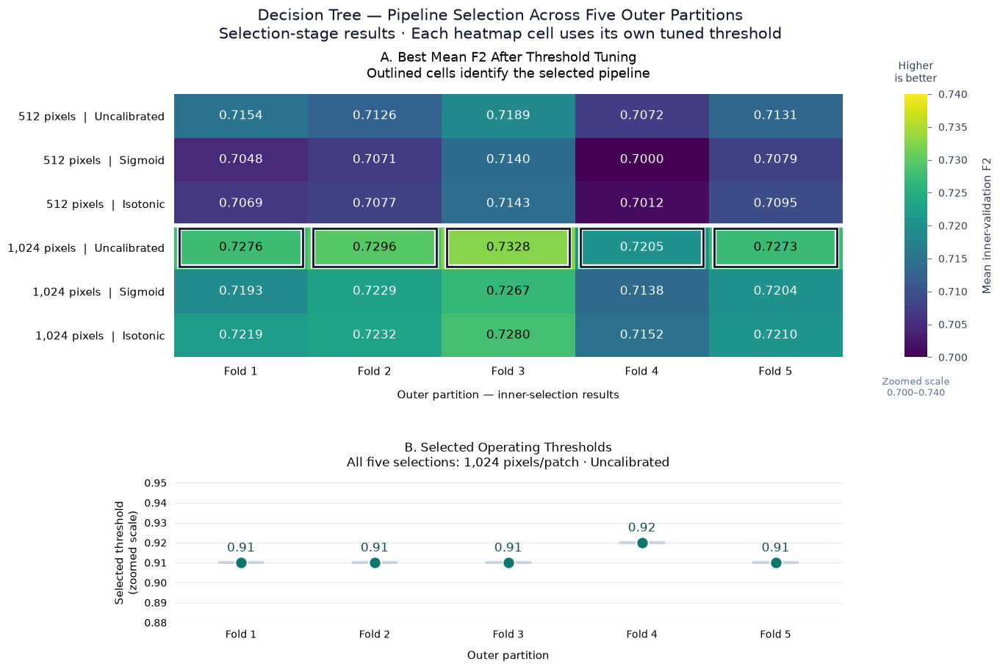

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
from matplotlib.ticker import FormatStrFormatter


# ---------------------------------------------------------
# 1. Collect previously calculated results
# ---------------------------------------------------------
dt_best_options_all_outer = pd.concat(
    [
        result["ranking"]
        .drop_duplicates(["pixels_per_patch", "Method"])
        .assign(outer_fold=outer_number)
        for outer_number, result in sorted(
            dt_pipeline_results_by_outer.items()
        )
    ],
    ignore_index=True
)

row_order = pd.MultiIndex.from_tuples(
    [
        (sample_size, method)
        for sample_size in [512, 1024]
        for method in DT_SELECTION_METHODS
    ],
    names=["pixels_per_patch", "Method"]
)

dt_pipeline_comparison_matrix = (
    dt_best_options_all_outer
    .pivot(
        index=["pixels_per_patch", "Method"],
        columns="outer_fold",
        values="mean_F2"
    )
    .reindex(index=row_order, columns=[1, 2, 3, 4, 5])
)

values = dt_pipeline_comparison_matrix.to_numpy()

assert values.shape == (6, 5)
assert np.isfinite(values).all()

short_method_names = {
    DT_SELECTION_METHODS[0]: "Uncalibrated",
    "Sigmoid": "Sigmoid",
    "Isotonic": "Isotonic"
}

row_labels = [
    f"{sample_size:,} pixels  |  {short_method_names[method]}"
    for sample_size, method in row_order
]


# ---------------------------------------------------------
# 2. Figure layout with a dedicated colorbar column
# ---------------------------------------------------------
fig = plt.figure(
    figsize=(13.5, 9),
    facecolor="white",
    constrained_layout=True
)

grid = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[30, 1],
    height_ratios=[3.2, 1.7],
    hspace=0.12,
    wspace=0.08
)

ax_heatmap = fig.add_subplot(grid[0, 0])
ax_colorbar = fig.add_subplot(grid[0, 1])
ax_threshold = fig.add_subplot(grid[1, 0])


# ---------------------------------------------------------
# 3. Heatmap with an explicitly zoomed color scale
# ---------------------------------------------------------
COLOR_MIN = 0.70
COLOR_MAX = 0.74

cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=COLOR_MIN, vmax=COLOR_MAX)

heatmap = ax_heatmap.imshow(
    values,
    cmap=cmap,
    norm=norm,
    aspect="auto",
    interpolation="nearest"
)

# Adapt text color to the actual cell background
for row in range(values.shape[0]):
    for column in range(values.shape[1]):
        red, green, blue, _ = cmap(norm(values[row, column]))

        brightness = (
            0.2126 * red
            + 0.7152 * green
            + 0.0722 * blue
        )

        ax_heatmap.text(
            column,
            row,
            f"{values[row, column]:.4f}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="medium",
            color="black" if brightness > 0.55 else "white"
        )

# Outline the selected pipeline in each outer partition
for column, outer_number in enumerate([1, 2, 3, 4, 5]):
    selected = dt_pipeline_results_by_outer[
        outer_number
    ]["selected"]

    selected_row = row_order.get_loc((
        int(selected["pixels_per_patch"]),
        selected["Method"]
    ))

    # White outer border and dark inner border remain visible
    # against both dark and bright cells.
    for edge_color, line_width in [
        ("white", 4.5),
        ("#111827", 2.0)
    ]:
        ax_heatmap.add_patch(Rectangle(
            (column - 0.46, selected_row - 0.43),
            0.92,
            0.86,
            fill=False,
            edgecolor=edge_color,
            linewidth=line_width,
            zorder=4
        ))

# Separate the two sample-size groups
ax_heatmap.axhline(
    2.5,
    color="white",
    linewidth=4,
    zorder=3
)

ax_heatmap.set_xticks(
    range(5),
    [f"Fold {i}" for i in range(1, 6)]
)
ax_heatmap.set_yticks(range(6), row_labels)

ax_heatmap.tick_params(
    axis="both",
    labelsize=11,
    length=0,
    pad=9
)

ax_heatmap.set_xlabel(
    "Outer partition — inner-selection results",
    fontsize=11,
    labelpad=12
)

ax_heatmap.set_title(
    "A. Best Mean F2 After Threshold Tuning\n"
    "Outlined cells identify the selected pipeline",
    fontsize=13,
    pad=16
)

for spine in ax_heatmap.spines.values():
    spine.set_visible(False)


# ---------------------------------------------------------
# 4. Refined colorbar
# ---------------------------------------------------------
# Extension triangles would reveal any future out-of-range values.
below_scale = bool((values < COLOR_MIN).any())
above_scale = bool((values > COLOR_MAX).any())

colorbar_extension = (
    "both" if below_scale and above_scale
    else "min" if below_scale
    else "max" if above_scale
    else "neither"
)

colorbar = fig.colorbar(
    heatmap,
    cax=ax_colorbar,
    orientation="vertical",
    ticks=np.arange(0.70, 0.7401, 0.005),
    extend=colorbar_extension
)

colorbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

colorbar.ax.tick_params(
    labelsize=10,
    length=4,
    width=0.8,
    color="#64748B",
    labelcolor="#334155",
    pad=7
)

colorbar.outline.set_visible(False)

colorbar.set_label(
    "Mean inner-validation F2",
    fontsize=11,
    color="#334155",
    labelpad=14
)

colorbar.ax.set_title(
    "Higher\nis better",
    fontsize=10,
    color="#334155",
    pad=12
)

colorbar.ax.text(
    0.5,
    -0.07,
    "Zoomed scale\n0.700–0.740",
    transform=colorbar.ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    color="#64748B"
)


# ---------------------------------------------------------
# 5. Selected thresholds
# ---------------------------------------------------------
selection_plot = (
    dt_pipeline_selection_summary
    .sort_values("outer_fold")
)

x_positions = np.arange(len(selection_plot))
threshold_values = selection_plot["Threshold"].to_numpy()

# Small reference ticks make each operating threshold easy to locate
for x, threshold in zip(x_positions, threshold_values):
    ax_threshold.plot(
        [x - 0.16, x + 0.16],
        [threshold, threshold],
        color="#CBD5E1",
        linewidth=3,
        zorder=2
    )

ax_threshold.scatter(
    x_positions,
    threshold_values,
    s=140,
    color="#0F766E",
    edgecolors="white",
    linewidths=1.5,
    zorder=3
)

for x, threshold in zip(x_positions, threshold_values):
    ax_threshold.annotate(
        f"{threshold:.2f}",
        xy=(x, threshold),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="medium",
        color="#134E4A"
    )

ax_threshold.set_xticks(
    x_positions,
    [f"Fold {i}" for i in selection_plot["outer_fold"]]
)

ax_threshold.set_xlim(-0.5, 4.5)
ax_threshold.set_ylim(0.88, 0.95)
ax_threshold.set_yticks(np.arange(0.88, 0.951, 0.01))
ax_threshold.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

ax_threshold.set_ylabel(
    "Selected threshold\n(zoomed scale)",
    fontsize=11
)
ax_threshold.set_xlabel(
    "Outer partition",
    fontsize=11,
    labelpad=10
)

ax_threshold.set_title(
    "B. Selected Operating Thresholds\n"
    "All five selections: 1,024 pixels/patch · Uncalibrated",
    fontsize=12,
    pad=16
)

ax_threshold.tick_params(
    axis="both",
    labelsize=10,
    length=0,
    pad=7
)

ax_threshold.grid(
    axis="y",
    color="#E2E8F0",
    linewidth=0.8
)
ax_threshold.set_axisbelow(True)

for spine in ax_threshold.spines.values():
    spine.set_visible(False)


# ---------------------------------------------------------
# 6. Overall title
# ---------------------------------------------------------
fig.suptitle(
    "Decision Tree — Pipeline Selection Across Five Outer Partitions\n"
    "Selection-stage results · Each heatmap cell uses its own tuned threshold",
    fontsize=15,
    color="#0F172A"
)

plt.show()

### Rationale — Consolidated Pipeline Comparison

The figure compares sample size and probability method after each option's threshold tuning, and displays the selected operating thresholds across the five outer partitions.

### Result — Pipeline Selection Stability

The 1,024-pixel uncalibrated pipeline achieved the highest mean inner-validation F2 in every partition. Each probability method also achieved higher tuned F2 with 1,024 pixels than with 512 pixels.

Selected thresholds were 0.91 in folds 1, 2, 3, and 5, and 0.92 in fold 4.

The heatmap uses an explicitly zoomed color range of 0.700–0.740 to reveal small numerical differences. Color contrast does not establish practical or statistical superiority.

These are inner-selection results. Outer evaluation for folds 2–5 remains pending.

In [44]:
# Freeze each fold's independently selected specification
dt_locked_settings_by_outer = {}

for outer_number in range(1, 6):
    selected = dt_pipeline_results_by_outer[
        outer_number
    ]["selected"]

    dt_locked_settings_by_outer[outer_number] = {
        "outer_fold": outer_number,
        "pixels_per_patch": int(selected["pixels_per_patch"]),
        "probability_method": selected["Method"],
        "threshold": float(selected["Threshold"]),
        "model_params": {
            **dt_refinement_results_by_outer[
                outer_number
            ]["selected_params"],
            "random_state": RANDOM_STATE
        }
    }

# All current selections are uncalibrated pipelines
assert all(
    settings["probability_method"] == DT_SELECTION_METHODS[0]
    for settings in dt_locked_settings_by_outer.values()
)

assert dt_locked_settings_by_outer[1] == dt_outer1_locked_settings

DT_OUTER_MODEL_DIR = DT_PIPELINE_CHECKPOINT_DIR / "outer_models"
DT_OUTER_MODEL_DIR.mkdir(parents=True, exist_ok=True)


def fit_locked_dt_outer(settings):
    outer_number = settings["outer_fold"]
    fold = nested_splits[outer_number - 1]

    train_ids = fold["train_ids"]
    evaluation_ids = fold["evaluation_ids"]

    assert set(train_ids).isdisjoint(set(evaluation_ids))
    assert set(train_ids) | set(evaluation_ids) == set(dev_ids)
    assert (set(train_ids) | set(evaluation_ids)).isdisjoint(
        set(test_ids)
    )

    X_train, y_train = get_sampled_pixels(
        train_ids,
        pixels_per_patch=settings["pixels_per_patch"]
    )

    model = DecisionTreeClassifier(**settings["model_params"])

    start_time = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start_time

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    probability = model.predict_proba(X_train)[:, positive_column]
    prediction = (
        probability >= settings["threshold"]
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_train, prediction, labels=[0, 1]
    ).ravel()

    beta_squared = BETA ** 2

    training_summary = {
        "outer_fold": outer_number,
        "training_patches": len(train_ids),
        "training_pixels": len(y_train),
        "pixels_per_patch": settings["pixels_per_patch"],
        "threshold": settings["threshold"],
        "training_F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "training_precision": dt_safe_ratio(tp, tp + fp),
        "training_recall": dt_safe_ratio(tp, tp + fn),
        "training_specificity": dt_safe_ratio(tn, tn + fp),
        "training_IoU": dt_safe_ratio(tp, tp + fp + fn),
        "tree_depth": model.get_depth(),
        "n_leaves": model.get_n_leaves(),
        "fit_seconds": fit_seconds
    }

    return {
        "settings": {
            **settings,
            "model_params": dict(settings["model_params"])
        },
        "model": model,
        "training_summary": training_summary
    }


if "dt_fitted_bundles_by_outer" not in globals():
    dt_fitted_bundles_by_outer = {
        1: dt_outer1_fitted_bundle
    }

for outer_number in range(1, 6):
    settings = dt_locked_settings_by_outer[outer_number]

    model_signature = joblib.hash({
        "pipeline_signature": dt_pipeline_signature,
        "settings": settings,
        "training_ids": nested_splits[
            outer_number - 1
        ]["train_ids"]
    })

    checkpoint_path = (
        DT_OUTER_MODEL_DIR
        / f"outer_{outer_number}_fitted_model.joblib"
    )

    print(
        f"\nLOCKED MODEL — OUTER FOLD {outer_number}/5",
        flush=True
    )

    if outer_number in dt_fitted_bundles_by_outer:
        bundle = dt_fitted_bundles_by_outer[outer_number]
        assert bundle["settings"] == settings
        print("Using fitted model already in memory.", flush=True)

    elif checkpoint_path.exists():
        checkpoint = joblib.load(checkpoint_path)

        if checkpoint["signature"] != model_signature:
            raise ValueError("Stored model has a different specification.")

        bundle = checkpoint["bundle"]
        assert bundle["settings"] == settings

        dt_fitted_bundles_by_outer[outer_number] = bundle
        print("Loaded fitted model from checkpoint.", flush=True)

    else:
        bundle = fit_locked_dt_outer(settings)
        dt_fitted_bundles_by_outer[outer_number] = bundle

        print(
            "Training completed in "
            f"{bundle['training_summary']['fit_seconds']:.2f} seconds.",
            flush=True
        )

    save_dt_pipeline_checkpoint(
        checkpoint_path,
        {
            "signature": model_signature,
            "bundle": bundle
        }
    )

    print("Model and settings saved.", flush=True)


dt_outer_training_summary = pd.DataFrame([
    bundle["training_summary"]
    for outer_number, bundle in sorted(
        dt_fitted_bundles_by_outer.items()
    )
])

assert len(dt_outer_training_summary) == 5

print("\nTRAINING RESULTS — ALL FIVE OUTER-FOLD MODELS")
display(dt_outer_training_summary.round(6))

print("\nModel checkpoint directory:")
print(DT_OUTER_MODEL_DIR)

print(
    "\nNo new outer-evaluation predictions were computed by this cell."
)


LOCKED MODEL — OUTER FOLD 1/5
Using fitted model already in memory.
Model and settings saved.

LOCKED MODEL — OUTER FOLD 2/5
Training completed in 20.70 seconds.
Model and settings saved.

LOCKED MODEL — OUTER FOLD 3/5
Training completed in 21.25 seconds.
Model and settings saved.

LOCKED MODEL — OUTER FOLD 4/5
Training completed in 21.13 seconds.
Model and settings saved.

LOCKED MODEL — OUTER FOLD 5/5
Training completed in 21.23 seconds.
Model and settings saved.

TRAINING RESULTS — ALL FIVE OUTER-FOLD MODELS


,outer_fold,training_patches,training_pixels,pixels_per_patch,threshold,training_F2,training_precision,training_recall,training_specificity,training_IoU,tree_depth,n_leaves,fit_seconds
0,1,2431,2489344,1024,0.91,0.791176,0.549838,0.888693,0.982645,0.514413,15,3035,21.256436
1,2,2431,2489344,1024,0.91,0.786885,0.553814,0.879409,0.982725,0.514724,15,2906,20.701398
2,3,2431,2489344,1024,0.91,0.792690,0.562749,0.882877,0.983231,0.523655,15,2937,21.254709
3,4,2431,2489344,1024,0.92,0.780867,0.568713,0.861181,0.984346,0.520955,15,2973,21.132961
4,5,2432,2490368,1024,0.91,0.787172,0.549934,0.882330,0.982414,0.512358,15,2876,21.234829



Model checkpoint directory:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_checkpoints\fb68d01cf38fc3e53e6685386ece1d0e\pipeline_selection\10ded7eb4de47770ebe04c63a5353470\outer_models

No new outer-evaluation predictions were computed by this cell.


### Rationale — Refitting the Five Outer-Fold Models

Each locked pipeline was refitted using all training patches available within its own outer partition. Inner-selected parameters, sample size, probability method, and threshold were preserved.

### Result — Outer-Fold Training Completed

All five models were fitted and checkpointed. Folds 1–4 used 2,431 training patches each, while fold 5 used 2,432. Every model used 1,024 sampled pixels per patch.

Training F2 values were 0.791176, 0.786885, 0.792690, 0.780867, and 0.787172.

All trees reached depth 15, with 2,876–3,035 leaves. Fitting took approximately 20–21 seconds per model. Thresholds were 0.91 except for fold 4, which used 0.92.

These are training scores, not generalization estimates. This cell computed no new outer-evaluation predictions.

### Visualization Decision

The table is sufficient at this stage. A paired training-versus-outer-evaluation plot will follow after evaluation is complete.

In [45]:
DT_OUTER_EVALUATION_DIR = (
    DT_PIPELINE_CHECKPOINT_DIR / "outer_evaluation"
)
DT_OUTER_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)


def evaluate_locked_dt_outer(fitted_bundle):
    settings = fitted_bundle["settings"]
    outer_number = settings["outer_fold"]

    assert settings == dt_locked_settings_by_outer[outer_number]
    assert settings["probability_method"] == DT_SELECTION_METHODS[0]

    fold = nested_splits[outer_number - 1]
    evaluation_ids = np.asarray(fold["evaluation_ids"])
    model = fitted_bundle["model"]

    assert set(evaluation_ids).isdisjoint(set(fold["train_ids"]))
    assert set(evaluation_ids).isdisjoint(set(test_ids))

    threshold = settings["threshold"]
    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    pixels_per_image = 128 * 128
    total_pixels = len(evaluation_ids) * pixels_per_image

    all_probability = np.empty(total_pixels, dtype=np.float64)
    all_labels = np.empty(total_pixels, dtype=np.uint8)

    patch_rows = []
    epsilon = np.finfo(np.float64).eps
    start_time = perf_counter()

    for position, patch_id in enumerate(evaluation_ids):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")
        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid mask: {patch_id}")

        y = mask.reshape(-1).astype(np.uint8)
        p = np.asarray(
            model.predict_proba(
                image.reshape(-1, len(FEATURE_NAMES))
            )[:, positive_column],
            dtype=np.float64
        )

        if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
            raise ValueError(f"Invalid probabilities: {patch_id}")

        prediction = (p >= threshold).astype(np.uint8)

        tn, fp, fn, tp = np.bincount(
            2 * y + prediction,
            minlength=4
        )

        clipped_p = np.clip(p, epsilon, 1 - epsilon)

        patch_rows.append({
            "outer_fold": outer_number,
            "patch_id": str(patch_id),
            "pixels": len(y),
            "landslide_pixels": int(y.sum()),
            "landslide_fraction": float(y.mean()),
            "predicted_landslide_pixels": int(prediction.sum()),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "squared_error_sum": float(np.square(p - y).sum()),
            "log_loss_sum": float(
                -(
                    y * np.log(clipped_p)
                    + (1 - y) * np.log1p(-clipped_p)
                ).sum()
            )
        })

        start = position * pixels_per_image
        stop = start + pixels_per_image

        all_labels[start:stop] = y
        all_probability[start:stop] = p

        if (position + 1) % 200 == 0:
            print(
                f"  Evaluated {position + 1}/{len(evaluation_ids)} patches",
                flush=True
            )

    patch_counts = pd.DataFrame(patch_rows)

    assert patch_counts["patch_id"].is_unique

    tn, fp, fn, tp = (
        patch_counts[["TN", "FP", "FN", "TP"]]
        .sum()
        .to_numpy()
    )

    assert tn + fp + fn + tp == total_pixels

    beta_squared = BETA ** 2

    metrics = {
        "outer_fold": outer_number,
        "evaluation_patches": len(evaluation_ids),
        "evaluation_pixels": total_pixels,
        "pixels_per_training_patch": settings["pixels_per_patch"],
        "threshold": threshold,
        "F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": dt_safe_ratio(tp, tp + fp),
        "Recall": dt_safe_ratio(tp, tp + fn),
        "Specificity": dt_safe_ratio(tn, tn + fp),
        "IoU": dt_safe_ratio(tp, tp + fp + fn),
        "Accuracy": dt_safe_ratio(tp + tn, total_pixels),
        "ROC_AUC": roc_auc_score(all_labels, all_probability),
        "Average_precision": average_precision_score(
            all_labels, all_probability
        ),
        "Brier": patch_counts["squared_error_sum"].sum() / total_pixels,
        "Log_loss": patch_counts["log_loss_sum"].sum() / total_pixels,
        "evaluation_seconds": perf_counter() - start_time
    }

    return {
        "settings": {
            **settings,
            "model_params": dict(settings["model_params"])
        },
        "metrics": metrics,
        "patch_counts": patch_counts,
        "patch_ids": evaluation_ids.copy(),
        "y": all_labels,
        "probability": all_probability
    }


if "dt_outer_evaluations" not in globals():
    dt_outer_evaluations = {
        1: dt_outer1_evaluation
    }

for outer_number in range(1, 6):
    evaluation_signature = joblib.hash({
        "pipeline_signature": dt_pipeline_signature,
        "settings": dt_locked_settings_by_outer[outer_number],
        "evaluation_ids": nested_splits[
            outer_number - 1
        ]["evaluation_ids"],
        "beta": BETA,
        "log_loss_clipping": "float64_machine_epsilon"
    })

    checkpoint_path = (
        DT_OUTER_EVALUATION_DIR
        / f"outer_{outer_number}_evaluation.joblib"
    )

    print(
        f"\nOUTER EVALUATION — FOLD {outer_number}/5",
        flush=True
    )

    if outer_number in dt_outer_evaluations:
        result = dt_outer_evaluations[outer_number]
        assert result["settings"] == dt_locked_settings_by_outer[
            outer_number
        ]
        print("Using completed evaluation in memory.", flush=True)

    elif checkpoint_path.exists():
        checkpoint = joblib.load(checkpoint_path)

        if checkpoint["signature"] != evaluation_signature:
            raise ValueError("Evaluation checkpoint mismatch.")

        result = checkpoint["result"]
        assert result["settings"] == dt_locked_settings_by_outer[
            outer_number
        ]

        dt_outer_evaluations[outer_number] = result
        print("Loaded completed evaluation.", flush=True)

    else:
        result = evaluate_locked_dt_outer(
            dt_fitted_bundles_by_outer[outer_number]
        )
        dt_outer_evaluations[outer_number] = result

    save_dt_pipeline_checkpoint(
        checkpoint_path,
        {
            "signature": evaluation_signature,
            "result": result
        }
    )

    print(
        f"  F2 = {result['metrics']['F2']:.6f}"
        f" | Recall = {result['metrics']['Recall']:.6f}"
        f" | Precision = {result['metrics']['Precision']:.6f}",
        flush=True
    )
    print("  Evaluation and per-patch records saved.", flush=True)


dt_outer_metrics_table = (
    pd.DataFrame([
        result["metrics"]
        for outer_number, result in sorted(
            dt_outer_evaluations.items()
        )
    ])
    .sort_values("outer_fold")
    .reset_index(drop=True)
)

assert len(dt_outer_metrics_table) == 5

# Confirm one outer prediction per development patch
dt_oof_patch_counts = pd.concat(
    [
        result["patch_counts"]
        for outer_number, result in sorted(
            dt_outer_evaluations.items()
        )
    ],
    ignore_index=True
)

assert len(dt_oof_patch_counts) == len(dev_ids)
assert dt_oof_patch_counts["patch_id"].is_unique
assert set(dt_oof_patch_counts["patch_id"]) == set(
    str(i) for i in dev_ids
)

metric_columns = [
    "F2", "Precision", "Recall", "Specificity",
    "IoU", "Accuracy", "ROC_AUC", "Average_precision",
    "Brier", "Log_loss"
]

dt_outer_mean_sd = (
    dt_outer_metrics_table[metric_columns]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean across outer folds",
        "std": "SD across outer folds"
    })
)

print("\nOUTER-EVALUATION RESULTS — ALL FIVE FOLDS")
display(dt_outer_metrics_table.round(6))

print("\nMEAN AND DESCRIPTIVE SD")
display(dt_outer_mean_sd.round(6))

print("\nUnique out-of-fold patch records:", len(dt_oof_patch_counts))
print("Every development patch appears exactly once.")


OUTER EVALUATION — FOLD 1/5
Using completed evaluation in memory.
  F2 = 0.731071 | Recall = 0.824322 | Precision = 0.503321
  Evaluation and per-patch records saved.

OUTER EVALUATION — FOLD 2/5
  Evaluated 200/608 patches
  Evaluated 400/608 patches
  Evaluated 600/608 patches
  F2 = 0.736093 | Recall = 0.817419 | Precision = 0.526546
  Evaluation and per-patch records saved.

OUTER EVALUATION — FOLD 3/5
  Evaluated 200/608 patches
  Evaluated 400/608 patches
  Evaluated 600/608 patches
  F2 = 0.720459 | Recall = 0.819308 | Precision = 0.485944
  Evaluation and per-patch records saved.

OUTER EVALUATION — FOLD 4/5
  Evaluated 200/608 patches
  Evaluated 400/608 patches
  Evaluated 600/608 patches
  F2 = 0.763988 | Recall = 0.837945 | Precision = 0.564646
  Evaluation and per-patch records saved.

OUTER EVALUATION — FOLD 5/5
  Evaluated 200/607 patches
  Evaluated 400/607 patches
  Evaluated 600/607 patches
  F2 = 0.735678 | Recall = 0.833789 | Precision = 0.500232
  Evaluation and p

,outer_fold,evaluation_patches,evaluation_pixels,pixels_per_training_patch,threshold,F2,Precision,Recall,Specificity,IoU,Accuracy,ROC_AUC,Average_precision,Brier,Log_loss,evaluation_seconds
0,1,608,9961472,1024,0.91,0.731071,0.503321,0.824322,0.979023,0.454561,0.975134,0.950717,0.713443,0.036638,0.186777,11.241784
1,2,608,9961472,1024,0.91,0.736093,0.526546,0.817419,0.982737,0.471135,0.978944,0.953276,0.712948,0.033271,0.165714,2.999421
2,3,608,9961472,1024,0.91,0.720459,0.485944,0.819308,0.979974,0.438906,0.976346,0.950761,0.678256,0.037846,0.181278,2.999703
3,4,608,9961472,1024,0.92,0.763988,0.564646,0.837945,0.983743,0.509057,0.980165,0.962762,0.750893,0.033886,0.157685,3.013575
4,5,607,9945088,1024,0.91,0.735678,0.500232,0.833789,0.980374,0.454873,0.976999,0.956612,0.713360,0.036802,0.170939,3.027447



MEAN AND DESCRIPTIVE SD


,Mean across outer folds,SD across outer folds
F2,0.737458,0.016114
Precision,0.516138,0.030783
Recall,0.826556,0.008987
Specificity,0.981170,0.001984
IoU,0.465706,0.026779
Accuracy,0.977518,0.002023
ROC_AUC,0.954825,0.005049
Average_precision,0.713780,0.025692
Brier,0.035689,0.001993
Log_loss,0.172479,0.011714



Unique out-of-fold patch records: 3039
Every development patch appears exactly once.


### Rationale — Completing Outer Evaluation

Each locked model was evaluated on its reserved outer patches. This assesses the selected modeling procedure beyond the inner-validation scores used for tuning.

### Result — Five-Fold Outer Evaluation

Outer-fold F2 values were 0.731071, 0.736093, 0.720459, 0.763988, and 0.735678.

Mean performance across the five folds was:

- F2: 0.734458; SD: 0.016114.
- Precision: 0.516138; SD: 0.030783.
- Recall: 0.826556; SD: 0.008987.
- Specificity: 0.981170; SD: 0.001984.
- IoU: 0.465706; SD: 0.026779.
- Accuracy: 0.977518; SD: 0.002023.
- ROC AUC: 0.954825; SD: 0.005049.
- Average precision: 0.713780; SD: 0.025692.
- Brier score: 0.035689; SD: 0.001993.
- Log loss: 0.172479; SD: 0.011714.

All 3,039 development patches have exactly one out-of-fold record. Four evaluation folds contained 608 patches and one contained 607.

Recall was relatively consistent, while precision varied more across partitions. False-positive predictions remain an important limitation.

These are arithmetic means of fold-level metrics, not pooled out-of-fold metrics. The SD values are descriptive, not confidence intervals. Overlapping training sets prevent treating the five scores as independent experiments.

### Visualization Decision

Paired training–evaluation plots and fold-level metric plots are appropriate next. Pooled metrics, patch-bootstrap intervals, reliability, subgroup errors, and spatial diagnostics remain to be completed.

TRAINING–OUTER EVALUATION COMPARISON


,outer_fold,training_F2,outer_F2,F2_gap
0,1,0.791176,0.731071,0.060105
1,2,0.786885,0.736093,0.050792
2,3,0.792690,0.720459,0.072231
3,4,0.780867,0.763988,0.016879
4,5,0.787172,0.735678,0.051494


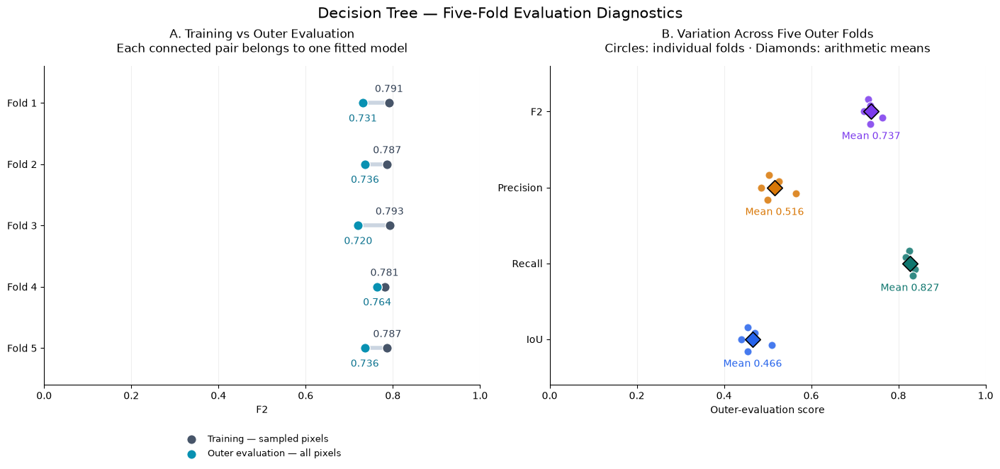

In [46]:
# Match training and evaluation results by outer-fold number
dt_train_outer_comparison = (
    dt_outer_training_summary[
        ["outer_fold", "training_F2"]
    ]
    .merge(
        dt_outer_metrics_table[
            ["outer_fold", "F2"]
        ].rename(columns={"F2": "outer_F2"}),
        on="outer_fold",
        validate="one_to_one"
    )
    .sort_values("outer_fold")
    .reset_index(drop=True)
)

dt_train_outer_comparison["F2_gap"] = (
    dt_train_outer_comparison["training_F2"]
    - dt_train_outer_comparison["outer_F2"]
)

print("TRAINING–OUTER EVALUATION COMPARISON")
display(dt_train_outer_comparison.round(6))

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6.5),
    constrained_layout=True
)

# PANEL A: Two scores belonging to the same fitted model
ax = axes[0]

for position, row in dt_train_outer_comparison.iterrows():
    ax.plot(
        [row["outer_F2"], row["training_F2"]],
        [position, position],
        color="#CBD5E1",
        linewidth=4,
        zorder=1
    )

    ax.scatter(
        row["training_F2"],
        position,
        s=95,
        color="#475569",
        edgecolors="white",
        zorder=3,
        label="Training — sampled pixels" if position == 0 else None
    )

    ax.scatter(
        row["outer_F2"],
        position,
        s=95,
        color="#0891B2",
        edgecolors="white",
        zorder=3,
        label="Outer evaluation — all pixels" if position == 0 else None
    )

    ax.annotate(
        f"{row['training_F2']:.3f}",
        (row["training_F2"], position),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#334155"
    )

    ax.annotate(
        f"{row['outer_F2']:.3f}",
        (row["outer_F2"], position),
        xytext=(0, -19),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#0E7490"
    )

ax.set_yticks(
    range(5),
    [
        f"Fold {int(i)}"
        for i in dt_train_outer_comparison["outer_fold"]
    ]
)

ax.set_xlim(0, 1)
ax.set_ylim(-0.6, 4.6)
ax.invert_yaxis()
ax.set_xlabel("F2")
ax.set_title(
    "A. Training vs Outer Evaluation\n"
    "Each connected pair belongs to one fitted model",
    fontsize=12,
    pad=14
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    frameon=False,
    fontsize=9
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)


# PANEL B: Individual outer-fold scores, not confidence intervals
ax = axes[1]

metrics_to_plot = [
    ("F2", "F2", "#7C3AED"),
    ("Precision", "Precision", "#D97706"),
    ("Recall", "Recall", "#0F766E"),
    ("IoU", "IoU", "#2563EB")
]

fold_scores = dt_outer_metrics_table.sort_values("outer_fold")
offsets = np.linspace(-0.16, 0.16, len(fold_scores))

for metric_position, (column, label, color) in enumerate(
    metrics_to_plot
):
    scores = fold_scores[column].to_numpy()
    mean_score = float(scores.mean())

    # Small deterministic offsets separate the five fold markers
    ax.scatter(
        scores,
        metric_position + offsets,
        s=65,
        color=color,
        alpha=0.85,
        edgecolors="white",
        zorder=3
    )

    ax.scatter(
        mean_score,
        metric_position,
        marker="D",
        s=120,
        color=color,
        edgecolors="black",
        linewidths=1.2,
        zorder=4
    )

    ax.annotate(
        f"Mean {mean_score:.3f}",
        (mean_score, metric_position),
        xytext=(0, -28),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color=color
    )

ax.set_yticks(
    range(len(metrics_to_plot)),
    [label for _, label, _ in metrics_to_plot]
)
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(metrics_to_plot) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("Outer-evaluation score")
ax.set_title(
    "B. Variation Across Five Outer Folds\n"
    "Circles: individual folds · Diamonds: arithmetic means",
    fontsize=12,
    pad=14
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for ax in axes:
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Five-Fold Evaluation Diagnostics",
    fontsize=15
)

plt.show()

### Rationale — Training–Evaluation and Fold-Variation Diagnostics

The connected-score plot compares training and outer-evaluation F2 for each fitted model. The second panel displays individual outer-fold scores and their arithmetic means.

### Result — Five-Fold Diagnostics

Mean training F2 was 0.787758 and mean outer-evaluation F2 was 0.737458, giving a mean gap of 0.050300.

Training F2 exceeded outer-evaluation F2 in every fold. The largest gap occurred in fold 3 (0.072231), and the smallest in fold 4 (0.016879).

Recall varied less across folds than precision and IoU. This indicates relatively consistent landslide detection, with greater variation in false-positive burden and overlap quality.

Training scores use sampled pixels; outer evaluation uses all pixels in the reserved patches. The displayed fold scores and means are descriptive, not confidence intervals or independent statistical experiments.

Correction: the previously transcribed mean outer F2 of 0.734458 should read 0.737458.

In [47]:
# ---------------------------------------------------------
# 1. Pool the actual out-of-fold classification counts
# ---------------------------------------------------------
dt_pooled_counts = (
    dt_oof_patch_counts[["TN", "FP", "FN", "TP"]]
    .sum()
)

tn, fp, fn, tp = dt_pooled_counts.to_numpy()
dt_pooled_pixel_count = int(
    dt_oof_patch_counts["pixels"].sum()
)

assert tn + fp + fn + tp == dt_pooled_pixel_count
assert dt_oof_patch_counts["patch_id"].is_unique

beta_squared = BETA ** 2

dt_pooled_oof_metrics = {
    "F2": dt_safe_ratio(
        (1 + beta_squared) * tp,
        (1 + beta_squared) * tp + beta_squared * fn + fp
    ),
    "Precision": dt_safe_ratio(tp, tp + fp),
    "Recall": dt_safe_ratio(tp, tp + fn),
    "Specificity": dt_safe_ratio(tn, tn + fp),
    "IoU": dt_safe_ratio(tp, tp + fp + fn),
    "Accuracy": dt_safe_ratio(tp + tn, dt_pooled_pixel_count),
    "Brier": (
        dt_oof_patch_counts["squared_error_sum"].sum()
        / dt_pooled_pixel_count
    ),
    "Log_loss": (
        dt_oof_patch_counts["log_loss_sum"].sum()
        / dt_pooled_pixel_count
    )
}


# ---------------------------------------------------------
# 2. Aggregate identical probability values exactly
# ---------------------------------------------------------
if "dt_pooled_probability_score_counts" not in globals():
    probability_count_frames = []

    for outer_number, result in sorted(
        dt_outer_evaluations.items()
    ):
        print(
            f"Aggregating probability scores — fold {outer_number}/5",
            flush=True
        )

        p = result["probability"]
        y = result["y"]

        unique_scores, total_counts = np.unique(
            p,
            return_counts=True
        )

        positive_scores, positive_counts = np.unique(
            p[y == 1],
            return_counts=True
        )

        positives_per_score = np.zeros(
            len(unique_scores),
            dtype=np.int64
        )

        positive_positions = np.searchsorted(
            unique_scores,
            positive_scores
        )

        assert np.array_equal(
            unique_scores[positive_positions],
            positive_scores
        )

        positives_per_score[positive_positions] = positive_counts

        probability_count_frames.append(pd.DataFrame({
            "probability": unique_scores,
            "positive_pixels": positives_per_score,
            "negative_pixels": total_counts - positives_per_score
        }))

    dt_pooled_probability_score_counts = (
        pd.concat(probability_count_frames, ignore_index=True)
        .groupby("probability", as_index=False)[
            ["positive_pixels", "negative_pixels"]
        ]
        .sum()
        .sort_values("probability")
        .reset_index(drop=True)
    )

score_counts = dt_pooled_probability_score_counts

assert int(
    score_counts["positive_pixels"].sum()
) == int(tp + fn)

assert int(
    score_counts[["positive_pixels", "negative_pixels"]]
    .to_numpy()
    .sum()
) == dt_pooled_pixel_count

# Weighted entries reproduce the original pixels and probability ties
grouped_labels = np.concatenate([
    np.ones(len(score_counts), dtype=np.uint8),
    np.zeros(len(score_counts), dtype=np.uint8)
])

grouped_probabilities = np.tile(
    score_counts["probability"].to_numpy(),
    2
)

grouped_weights = np.concatenate([
    score_counts["positive_pixels"].to_numpy(),
    score_counts["negative_pixels"].to_numpy()
])

nonzero_weight = grouped_weights > 0

dt_pooled_oof_metrics["ROC_AUC"] = roc_auc_score(
    grouped_labels[nonzero_weight],
    grouped_probabilities[nonzero_weight],
    sample_weight=grouped_weights[nonzero_weight]
)

dt_pooled_oof_metrics["Average_precision"] = average_precision_score(
    grouped_labels[nonzero_weight],
    grouped_probabilities[nonzero_weight],
    sample_weight=grouped_weights[nonzero_weight]
)


# ---------------------------------------------------------
# 3. Compare fold means with pooled metrics
# ---------------------------------------------------------
dt_oof_metric_comparison = dt_outer_mean_sd.join(
    pd.Series(
        dt_pooled_oof_metrics,
        name="Pooled out-of-fold"
    )
)

print("Development patches:", len(dt_oof_patch_counts))
print("Out-of-fold pixels:", f"{dt_pooled_pixel_count:,}")

print("\nFOLD MEANS VS POOLED OUT-OF-FOLD METRICS")
display(dt_oof_metric_comparison.round(6))

print("\nPOOLED OUT-OF-FOLD CONFUSION MATRIX")
display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
))

Aggregating probability scores — fold 1/5
Aggregating probability scores — fold 2/5
Aggregating probability scores — fold 3/5
Aggregating probability scores — fold 4/5
Aggregating probability scores — fold 5/5
Development patches: 3039
Out-of-fold pixels: 49,790,976

FOLD MEANS VS POOLED OUT-OF-FOLD METRICS


,Mean across outer folds,SD across outer folds,Pooled out-of-fold
F2,0.737458,0.016114,0.737575
Precision,0.516138,0.030783,0.515352
Recall,0.826556,0.008987,0.826693
Specificity,0.981170,0.001984,0.981171
IoU,0.465706,0.026779,0.465103
Accuracy,0.977518,0.002023,0.977518
ROC_AUC,0.954825,0.005049,0.954870
Average_precision,0.713780,0.025692,0.716037
Brier,0.035689,0.001993,0.035688
Log_loss,0.172479,0.011714,0.172479



POOLED OUT-OF-FOLD CONFUSION MATRIX


,Predicted non-landslide,Predicted landslide
Actual non-landslide,47698203,915364
Actual landslide,204053,973356


### Rationale — Pooled Out-of-Fold Evaluation

Metrics were recomputed from all out-of-fold predictions to distinguish pooled performance from the arithmetic mean of fold-level scores.

### Result — Pooled Decision Tree Performance

The evaluation covered 49,790,976 pixels from 3,039 development patches, each evaluated exactly once.

Pooled metrics:
- F2: 0.737575.
- Precision: 0.515352.
- Recall: 0.826693.
- Specificity: 0.981171.
- IoU: 0.465103.
- Accuracy: 0.977518.
- ROC AUC: 0.954870.
- Average precision: 0.716037.
- Brier score: 0.035688.
- Log loss: 0.172479.

The pooled confusion counts were TN = 47,698,203; FP = 915,364; FN = 204,053; TP = 973,356.

The procedure detected 82.67% of landslide pixels, while approximately 48.46% of predicted landslide pixels were false positives.

Pooled F2 was close to mean outer-fold F2 (0.737458), although these quantities are not generally identical.

These predictions come from five outer-fold models using their locked operating rules. They do not represent one final model fitted on all development data.

### Visualization Decision

A pooled confusion matrix and ROC/precision–recall curves are useful. The fold-mean versus pooled-metric table does not require an additional plot.

In [48]:
from scipy.sparse import coo_matrix

# Manually specified bootstrap settings
DT_BOOTSTRAP_REPEATS = 2000
DT_BOOTSTRAP_CONFIDENCE = 0.95
DT_BOOTSTRAP_BATCH_SIZE = 50

dt_bootstrap_patch_table = (
    dt_oof_patch_counts.reset_index(drop=True).copy()
)

assert dt_bootstrap_patch_table["patch_id"].is_unique

dt_bootstrap_patch_ids = (
    dt_bootstrap_patch_table["patch_id"].astype(str).to_numpy()
)

dt_bootstrap_score_values = (
    dt_pooled_probability_score_counts["probability"].to_numpy()
)

# ---------------------------------------------------------
# 1. Build exact, sparse probability counts for each patch
# ---------------------------------------------------------
if "dt_bootstrap_score_histograms" not in globals():
    row_by_patch = {
        patch_id: row
        for row, patch_id in enumerate(dt_bootstrap_patch_ids)
    }

    positive_rows, positive_columns, positive_data = [], [], []
    negative_rows, negative_columns, negative_data = [], [], []

    for outer_number, result in sorted(dt_outer_evaluations.items()):
        print(
            f"Preparing patch probability counts — fold {outer_number}/5",
            flush=True
        )

        probabilities = result["probability"].reshape(-1, 128 * 128)
        labels = result["y"].reshape(-1, 128 * 128)

        assert len(probabilities) == len(result["patch_ids"])

        for patch_position, patch_id in enumerate(result["patch_ids"]):
            row = row_by_patch[str(patch_id)]

            p = probabilities[patch_position]
            y = labels[patch_position]

            scores, counts = np.unique(p, return_counts=True)
            positive_scores, positive_counts = np.unique(
                p[y == 1], return_counts=True
            )

            positives = np.zeros(len(scores), dtype=np.int64)
            positives[np.searchsorted(scores, positive_scores)] = (
                positive_counts
            )
            negatives = counts - positives

            columns = np.searchsorted(dt_bootstrap_score_values, scores)

            assert np.array_equal(
                dt_bootstrap_score_values[columns], scores
            )

            for class_counts, rows_list, columns_list, data_list in [
                (
                    positives, positive_rows,
                    positive_columns, positive_data
                ),
                (
                    negatives, negative_rows,
                    negative_columns, negative_data
                )
            ]:
                keep = class_counts > 0

                rows_list.append(
                    np.full(int(keep.sum()), row, dtype=np.int64)
                )
                columns_list.append(columns[keep])
                data_list.append(class_counts[keep])

    shape = (
        len(dt_bootstrap_patch_ids),
        len(dt_bootstrap_score_values)
    )

    positive_matrix = coo_matrix(
        (
            np.concatenate(positive_data),
            (
                np.concatenate(positive_rows),
                np.concatenate(positive_columns)
            )
        ),
        shape=shape
    ).tocsr()

    negative_matrix = coo_matrix(
        (
            np.concatenate(negative_data),
            (
                np.concatenate(negative_rows),
                np.concatenate(negative_columns)
            )
        ),
        shape=shape
    ).tocsr()

    dt_bootstrap_score_histograms = {
        "patch_ids": dt_bootstrap_patch_ids.copy(),
        "score_values": dt_bootstrap_score_values.copy(),
        "positive": positive_matrix,
        "negative": negative_matrix
    }

histograms = dt_bootstrap_score_histograms

assert np.array_equal(
    histograms["patch_ids"], dt_bootstrap_patch_ids
)
assert np.array_equal(
    histograms["score_values"], dt_bootstrap_score_values
)

assert np.array_equal(
    np.asarray(histograms["positive"].sum(axis=1)).ravel(),
    (
        dt_bootstrap_patch_table["TP"]
        + dt_bootstrap_patch_table["FN"]
    ).to_numpy()
)

assert np.array_equal(
    np.asarray(histograms["negative"].sum(axis=1)).ravel(),
    (
        dt_bootstrap_patch_table["TN"]
        + dt_bootstrap_patch_table["FP"]
    ).to_numpy()
)


# ---------------------------------------------------------
# 2. Calculate metrics from image-weighted totals
# ---------------------------------------------------------
dt_bootstrap_metric_names = [
    "F2", "Precision", "Recall", "Specificity",
    "IoU", "Accuracy", "ROC_AUC", "Average_precision",
    "Brier", "Log_loss"
]

dt_bootstrap_numeric_columns = [
    "TN", "FP", "FN", "TP",
    "pixels", "squared_error_sum", "log_loss_sum"
]

patch_values = dt_bootstrap_patch_table[
    dt_bootstrap_numeric_columns
].to_numpy(dtype=np.float64)


def dt_bootstrap_metrics(totals, positive_scores, negative_scores):
    tn, fp, fn, tp, pixels, squared_error, log_loss_sum = totals.T
    beta_squared = BETA ** 2

    # Probability scores are in ascending order.
    cumulative_negatives = np.cumsum(negative_scores, axis=1)
    positive_total = positive_scores.sum(axis=1)
    negative_total = negative_scores.sum(axis=1)

    # Tied positive/negative scores receive half credit in ROC AUC.
    auc = (
        (
            positive_scores
            * (cumulative_negatives - 0.5 * negative_scores)
        ).sum(axis=1)
        / (positive_total * negative_total)
    )

    # Exact average precision, grouping tied probability scores.
    descending_positive = positive_scores[:, ::-1]
    cumulative_positive = np.cumsum(descending_positive, axis=1)
    cumulative_total = np.cumsum(
        (positive_scores + negative_scores)[:, ::-1],
        axis=1
    )

    precision_at_score = np.divide(
        cumulative_positive,
        cumulative_total,
        out=np.zeros_like(cumulative_positive, dtype=float),
        where=cumulative_total > 0
    )

    average_precision = (
        (descending_positive * precision_at_score).sum(axis=1)
        / positive_total
    )

    return np.column_stack([
        (1 + beta_squared) * tp
        / ((1 + beta_squared) * tp + beta_squared * fn + fp),
        tp / (tp + fp),
        tp / (tp + fn),
        tn / (tn + fp),
        tp / (tp + fp + fn),
        (tp + tn) / pixels,
        auc,
        average_precision,
        squared_error / pixels,
        log_loss_sum / pixels
    ])


# Verify the compressed calculation against existing pooled metrics
full_result_check = dt_bootstrap_metrics(
    patch_values.sum(axis=0, keepdims=True),
    np.asarray(histograms["positive"].sum(axis=0)),
    np.asarray(histograms["negative"].sum(axis=0))
)[0]

expected_metrics = np.array([
    dt_pooled_oof_metrics[name]
    for name in dt_bootstrap_metric_names
])

assert np.allclose(
    full_result_check,
    expected_metrics,
    rtol=1e-10,
    atol=1e-10
)


# ---------------------------------------------------------
# 3. Resample whole patches and retain every replicate
# ---------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
number_of_patches = len(dt_bootstrap_patch_table)

bootstrap_values = np.empty(
    (DT_BOOTSTRAP_REPEATS, len(dt_bootstrap_metric_names))
)

for start in range(0, DT_BOOTSTRAP_REPEATS, DT_BOOTSTRAP_BATCH_SIZE):
    stop = min(
        start + DT_BOOTSTRAP_BATCH_SIZE,
        DT_BOOTSTRAP_REPEATS
    )

    weights = np.vstack([
        np.bincount(
            rng.integers(
                0, number_of_patches, size=number_of_patches
            ),
            minlength=number_of_patches
        )
        for _ in range(stop - start)
    ]).astype(np.float64)

    totals = weights @ patch_values

    positive_scores = (
        histograms["positive"].T @ weights.T
    ).T
    negative_scores = (
        histograms["negative"].T @ weights.T
    ).T

    bootstrap_values[start:stop] = dt_bootstrap_metrics(
        totals, positive_scores, negative_scores
    )

    if stop % 500 == 0 or stop == DT_BOOTSTRAP_REPEATS:
        print(
            f"Completed {stop}/{DT_BOOTSTRAP_REPEATS} bootstrap repeats",
            flush=True
        )

assert np.isfinite(bootstrap_values).all()

dt_oof_bootstrap_samples = pd.DataFrame(
    bootstrap_values,
    columns=dt_bootstrap_metric_names
)

tail_probability = (1 - DT_BOOTSTRAP_CONFIDENCE) / 2

dt_oof_bootstrap_intervals = pd.DataFrame({
    "Estimate": expected_metrics,
    "CI_lower": np.quantile(
        bootstrap_values, tail_probability, axis=0
    ),
    "CI_upper": np.quantile(
        bootstrap_values, 1 - tail_probability, axis=0
    )
}, index=dt_bootstrap_metric_names)

print("\n95% PERCENTILE PATCH-BOOTSTRAP INTERVALS")
display(dt_oof_bootstrap_intervals.round(6))

Preparing patch probability counts — fold 1/5
Preparing patch probability counts — fold 2/5
Preparing patch probability counts — fold 3/5
Preparing patch probability counts — fold 4/5
Preparing patch probability counts — fold 5/5
Completed 500/2000 bootstrap repeats
Completed 1000/2000 bootstrap repeats
Completed 1500/2000 bootstrap repeats
Completed 2000/2000 bootstrap repeats

95% PERCENTILE PATCH-BOOTSTRAP INTERVALS


,Estimate,CI_lower,CI_upper
F2,0.737575,0.727800,0.747044
Precision,0.515352,0.500681,0.530542
Recall,0.826693,0.818537,0.834400
Specificity,0.981171,0.980178,0.982113
IoU,0.465103,0.451824,0.478771
Accuracy,0.977518,0.976440,0.978568
ROC_AUC,0.954870,0.952163,0.957225
Average_precision,0.716037,0.701491,0.730660
Brier,0.035688,0.034256,0.037251
Log_loss,0.172479,0.164477,0.180560


### Rationale — Patch-Level Uncertainty Estimation

Whole patches were resampled with replacement to estimate sensitivity to the evaluation-image composition while keeping within-patch pixels together.

### Result — 95% Patch-Bootstrap Intervals

All 2,000 bootstrap replicates completed successfully.

Pooled F2 was 0.737575, with a 95% percentile interval of [0.727800, 0.747044].

Other key intervals were:
- Precision: [0.500681, 0.530542].
- Recall: [0.818537, 0.834400].
- IoU: [0.451824, 0.478771].
- ROC AUC: [0.952163, 0.957225].
- Average precision: [0.701491, 0.730660].
- Brier score: [0.034256, 0.037251].
- Log loss: [0.164477, 0.180560].

These intervals describe patch-resampling variability conditional on the existing out-of-fold predictions. Models were not retrained. They do not fully capture training and selection uncertainty or unknown dependence between patches.

### Visualization Decision

A point-and-interval plot and the bootstrap F2 distribution are appropriate complements to the numerical table.

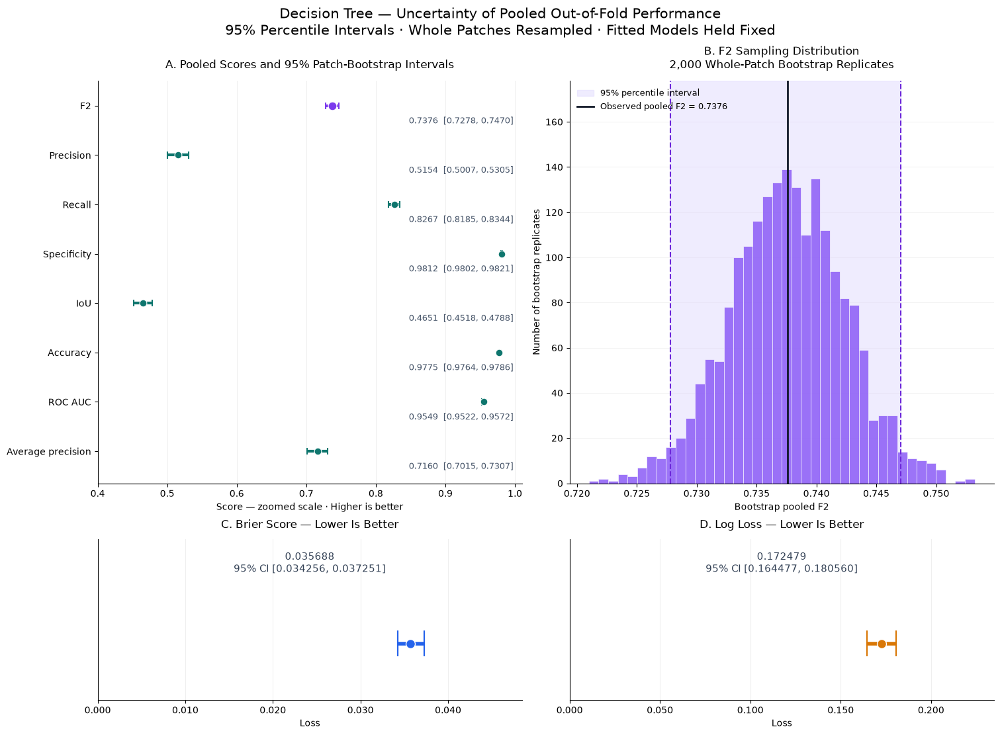

In [49]:
from matplotlib.ticker import FormatStrFormatter

intervals = dt_oof_bootstrap_intervals.copy()

score_metrics = [
    ("F2", "F2"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("Specificity", "Specificity"),
    ("IoU", "IoU"),
    ("Accuracy", "Accuracy"),
    ("ROC_AUC", "ROC AUC"),
    ("Average_precision", "Average precision")
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    gridspec_kw={"height_ratios": [3, 1.2]},
    constrained_layout=True
)

# ---------------------------------------------------------
# A. Point-and-interval plot
# ---------------------------------------------------------
ax = axes[0, 0]

for position, (metric, label) in enumerate(score_metrics):
    row = intervals.loc[metric]

    color = "#7C3AED" if metric == "F2" else "#0F766E"

    ax.hlines(
        position,
        row["CI_lower"],
        row["CI_upper"],
        color=color,
        linewidth=3,
        zorder=2
    )

    ax.vlines(
        [row["CI_lower"], row["CI_upper"]],
        position - 0.07,
        position + 0.07,
        color=color,
        linewidth=1.5
    )

    ax.scatter(
        row["Estimate"],
        position,
        s=85 if metric == "F2" else 60,
        color=color,
        edgecolors="white",
        linewidths=0.8,
        zorder=3
    )

    ax.text(
        0.98,
        position + 0.31,
        f"{row['Estimate']:.4f}  "
        f"[{row['CI_lower']:.4f}, {row['CI_upper']:.4f}]",
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=9,
        color="#475569"
    )

ax.set_yticks(
    range(len(score_metrics)),
    [label for _, label in score_metrics]
)
ax.set_ylim(-0.5, len(score_metrics) - 0.35)
ax.invert_yaxis()

# Explicitly zoomed score axis
ax.set_xlim(0.40, 1.01)
ax.set_xlabel("Score — zoomed scale · Higher is better")
ax.set_title(
    "A. Pooled Scores and 95% Patch-Bootstrap Intervals",
    fontsize=12,
    pad=14
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)


# ---------------------------------------------------------
# B. Bootstrap distribution of F2
# ---------------------------------------------------------
ax = axes[0, 1]

f2_samples = dt_oof_bootstrap_samples["F2"].to_numpy()
f2_interval = intervals.loc["F2"]

ax.hist(
    f2_samples,
    bins=40,
    color="#8B5CF6",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.85,
    zorder=2
)

ax.axvspan(
    f2_interval["CI_lower"],
    f2_interval["CI_upper"],
    color="#DDD6FE",
    alpha=0.45,
    zorder=1,
    label="95% percentile interval"
)

for boundary in ["CI_lower", "CI_upper"]:
    ax.axvline(
        f2_interval[boundary],
        color="#6D28D9",
        linestyle="--",
        linewidth=1.5
    )

ax.axvline(
    f2_interval["Estimate"],
    color="#111827",
    linewidth=2,
    label=f"Observed pooled F2 = {f2_interval['Estimate']:.4f}"
)

ax.set_xlabel("Bootstrap pooled F2")
ax.set_ylabel("Number of bootstrap replicates")
ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
ax.set_title(
    "B. F2 Sampling Distribution\n"
    f"{len(f2_samples):,} Whole-Patch Bootstrap Replicates",
    fontsize=12,
    pad=14
)

# Leave headroom for the legend
current_top = ax.get_ylim()[1]
ax.set_ylim(0, current_top * 1.22)
ax.legend(loc="upper left", fontsize=9, frameon=False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)


# ---------------------------------------------------------
# C–D. Probability-loss intervals on separate scales
# ---------------------------------------------------------
for ax, metric, title, color in [
    (
        axes[1, 0],
        "Brier",
        "C. Brier Score — Lower Is Better",
        "#2563EB"
    ),
    (
        axes[1, 1],
        "Log_loss",
        "D. Log Loss — Lower Is Better",
        "#D97706"
    )
]:
    row = intervals.loc[metric]

    ax.hlines(
        0,
        row["CI_lower"],
        row["CI_upper"],
        color=color,
        linewidth=4
    )

    ax.vlines(
        [row["CI_lower"], row["CI_upper"]],
        -0.08,
        0.08,
        color=color,
        linewidth=1.6
    )

    ax.scatter(
        row["Estimate"],
        0,
        color=color,
        s=100,
        edgecolors="white",
        zorder=3
    )

    ax.text(
        0.5,
        0.85,
        f"{row['Estimate']:.6f}\n"
        f"95% CI [{row['CI_lower']:.6f}, {row['CI_upper']:.6f}]",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=11,
        color="#334155"
    )

    ax.set_xlim(0, row["CI_upper"] * 1.30)
    ax.set_ylim(-0.35, 0.65)
    ax.set_yticks([])
    ax.set_xlabel("Loss")
    ax.set_title(title, fontsize=12, pad=12)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

for ax in axes.flat:
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Uncertainty of Pooled Out-of-Fold Performance\n"
    "95% Percentile Intervals · Whole Patches Resampled · Fitted Models Held Fixed",
    fontsize=15
)

plt.show()

### Rationale — Visualizing Performance Uncertainty

The figure combines point-and-interval summaries with the bootstrap F2 distribution. Probability losses are shown separately because their interpretation and scales differ from classification scores.

### Result — Uncertainty Visualization

The F2 bootstrap distribution is unimodal and approximately symmetric around the observed pooled estimate of 0.737575. Its 95% percentile interval is [0.727800, 0.747044]. Visual symmetry alone does not establish normality.

Precision and IoU show wider intervals than several other metrics. Narrow specificity and accuracy intervals do not remove the substantial false-positive burden.

Brier score was 0.035688 with interval [0.034256, 0.037251]. Log loss was 0.172479 with interval [0.164477, 0.180560].

All intervals are conditional on the existing out-of-fold predictions. Whole patches were resampled, but models were not retrained and unknown between-patch dependence remains a limitation.

The figure is sufficient for this uncertainty summary; no additional plot is required.

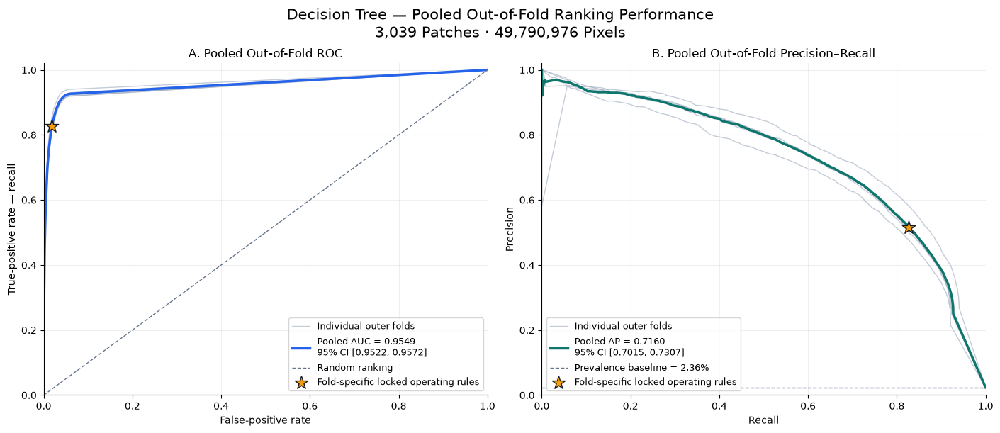

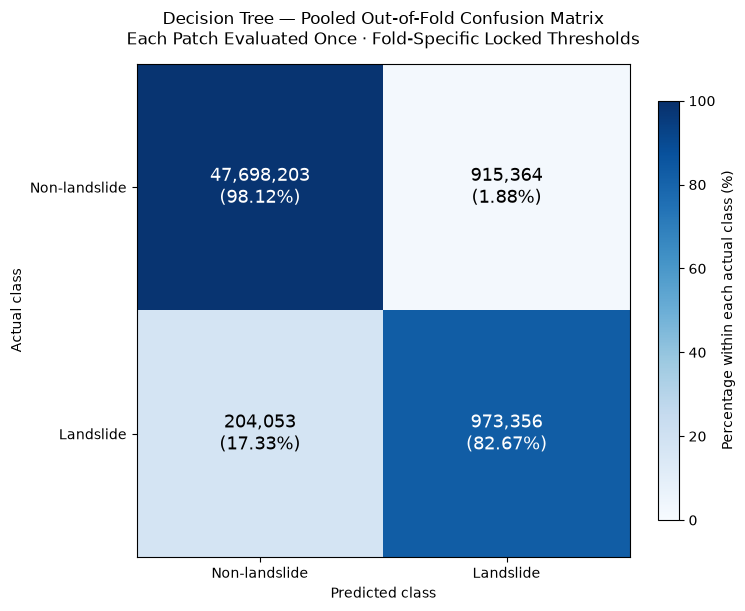

In [50]:
# ---------------------------------------------------------
# 1. Exact curves from probability-frequency counts
# ---------------------------------------------------------
def dt_curves_from_score_counts(scores, positive_counts, negative_counts):
    labels = np.concatenate([
        np.ones(len(scores), dtype=np.uint8),
        np.zeros(len(scores), dtype=np.uint8)
    ])

    probabilities = np.tile(scores, 2)
    weights = np.concatenate([
        positive_counts, negative_counts
    ])

    keep = weights > 0

    fpr, tpr, roc_thresholds = roc_curve(
        labels[keep],
        probabilities[keep],
        sample_weight=weights[keep]
    )

    precision, recall, pr_thresholds = precision_recall_curve(
        labels[keep],
        probabilities[keep],
        sample_weight=weights[keep]
    )

    return {
        "fpr": fpr,
        "tpr": tpr,
        "roc_thresholds": roc_thresholds,
        "precision": precision,
        "recall": recall,
        "pr_thresholds": pr_thresholds
    }


score_values = dt_bootstrap_score_histograms["score_values"]

positive_matrix = dt_bootstrap_score_histograms["positive"]
negative_matrix = dt_bootstrap_score_histograms["negative"]

pooled_positive = np.asarray(
    positive_matrix.sum(axis=0)
).ravel()

pooled_negative = np.asarray(
    negative_matrix.sum(axis=0)
).ravel()

dt_pooled_roc_pr_curves = dt_curves_from_score_counts(
    score_values,
    pooled_positive,
    pooled_negative
)

dt_fold_roc_pr_curves = {}

for outer_number in range(1, 6):
    rows = (
        dt_bootstrap_patch_table["outer_fold"].to_numpy()
        == outer_number
    )

    dt_fold_roc_pr_curves[outer_number] = dt_curves_from_score_counts(
        score_values,
        np.asarray(positive_matrix[rows].sum(axis=0)).ravel(),
        np.asarray(negative_matrix[rows].sum(axis=0)).ravel()
    )


# ---------------------------------------------------------
# 2. ROC and precision–recall panels
# ---------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

for outer_number, curves in dt_fold_roc_pr_curves.items():
    label = "Individual outer folds" if outer_number == 1 else None

    axes[0].plot(
        curves["fpr"], curves["tpr"],
        color="#94A3B8", alpha=0.55,
        linewidth=1, label=label
    )
    axes[1].plot(
        curves["recall"], curves["precision"],
        color="#94A3B8", alpha=0.55,
        linewidth=1, label=label
    )

auc_ci = dt_oof_bootstrap_intervals.loc["ROC_AUC"]
ap_ci = dt_oof_bootstrap_intervals.loc["Average_precision"]

axes[0].plot(
    dt_pooled_roc_pr_curves["fpr"],
    dt_pooled_roc_pr_curves["tpr"],
    color="#2563EB",
    linewidth=2.5,
    label=(
        f"Pooled AUC = {auc_ci['Estimate']:.4f}\n"
        f"95% CI [{auc_ci['CI_lower']:.4f}, "
        f"{auc_ci['CI_upper']:.4f}]"
    )
)

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#64748B",
    linewidth=1,
    label="Random ranking"
)

axes[1].plot(
    dt_pooled_roc_pr_curves["recall"],
    dt_pooled_roc_pr_curves["precision"],
    color="#0F766E",
    linewidth=2.5,
    label=(
        f"Pooled AP = {ap_ci['Estimate']:.4f}\n"
        f"95% CI [{ap_ci['CI_lower']:.4f}, "
        f"{ap_ci['CI_upper']:.4f}]"
    )
)

pooled_prevalence = float(
    pooled_positive.sum()
    / (pooled_positive.sum() + pooled_negative.sum())
)

axes[1].axhline(
    pooled_prevalence,
    linestyle="--",
    color="#64748B",
    linewidth=1,
    label=f"Prevalence baseline = {pooled_prevalence:.2%}"
)

# Decisions were made with each fold's locked threshold
axes[0].scatter(
    1 - dt_pooled_oof_metrics["Specificity"],
    dt_pooled_oof_metrics["Recall"],
    marker="*",
    s=190,
    color="#F59E0B",
    edgecolors="#111827",
    zorder=5,
    label="Fold-specific locked operating rules"
)

axes[1].scatter(
    dt_pooled_oof_metrics["Recall"],
    dt_pooled_oof_metrics["Precision"],
    marker="*",
    s=190,
    color="#F59E0B",
    edgecolors="#111827",
    zorder=5,
    label="Fold-specific locked operating rules"
)

axes[0].set(
    xlabel="False-positive rate",
    ylabel="True-positive rate — recall",
    title="A. Pooled Out-of-Fold ROC"
)

axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="B. Pooled Out-of-Fold Precision–Recall"
)

axes[0].legend(loc="lower right", fontsize=9)
axes[1].legend(loc="lower left", fontsize=9)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Pooled Out-of-Fold Ranking Performance\n"
    "3,039 Patches · 49,790,976 Pixels",
    fontsize=15
)

plt.show()


# ---------------------------------------------------------
# 3. Pooled confusion matrix
# ---------------------------------------------------------
tn, fp, fn, tp = dt_pooled_counts.to_numpy()
counts = np.array([[tn, fp], [fn, tp]])

percentages = (
    counts / counts.sum(axis=1, keepdims=True) * 100
)

fig, ax = plt.subplots(
    figsize=(7.5, 6),
    constrained_layout=True
)

heatmap = ax.imshow(
    percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

for row in range(2):
    for column in range(2):
        value = percentages[row, column]

        ax.text(
            column, row,
            f"{counts[row, column]:,}\n({value:.2f}%)",
            ha="center",
            va="center",
            fontsize=13,
            color="white" if value > 55 else "black"
        )

ax.set_xticks([0, 1], ["Non-landslide", "Landslide"])
ax.set_yticks([0, 1], ["Non-landslide", "Landslide"])
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title(
    "Decision Tree — Pooled Out-of-Fold Confusion Matrix\n"
    "Each Patch Evaluated Once · Fold-Specific Locked Thresholds",
    fontsize=12,
    pad=14
)

fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.85,
    label="Percentage within each actual class (%)"
)

plt.show()

### Rationale — Pooled Ranking and Error Visualization

The figures summarize ranking performance and classification errors across all out-of-fold predictions, with each development patch evaluated once.

### Result — Pooled ROC, Precision–Recall, and Confusion Matrix

Pooled ROC AUC was 0.954870, with 95% patch-bootstrap interval [0.952163, 0.957225]. Pooled average precision was 0.716037, with interval [0.701491, 0.730660]. Landslide prevalence was approximately 2.36%.

The ROC curves were relatively close across folds, while differences were more visible in the precision–recall curves.

The locked fold-specific decisions achieved recall of 82.67% and precision of 51.54%. The false-positive rate among actual non-landslide pixels was 1.88%, whereas 48.46% of predicted landslide pixels were false positives. These percentages use different denominators.

The displayed intervals apply to AUC and AP, not to the entire curves. The operating marker combines fold-specific thresholds and need not correspond to one common threshold on the pooled curve.

Both figures are sufficient for this diagnostic; no additional plot is needed.

OUTER-PREDICTION RELIABILITY SUMMARY


,pixels,nonempty_bins,mean_predicted_probability,observed_landslide_fraction,ECE_20_equal_width_bins
Evaluation,,,,,
Fold 1,9961472,20,0.063552,0.025139,0.042245
Fold 2,9961472,20,0.059104,0.022948,0.039271
Fold 3,9961472,20,0.063797,0.022584,0.044594
Fold 4,9961472,20,0.062081,0.024545,0.040172
Fold 5,9945088,20,0.063798,0.023018,0.043809
Pooled out-of-fold,49790976,20,0.062466,0.023647,0.042018



POOLED BIN DETAILS


,bin_left,bin_right,pixels,pixel_fraction,mean_probability,observed_landslide_fraction,probability_minus_observed
0,0.00,0.05,45756919,0.918980,0.000150,0.001890,-0.001740
1,0.05,0.10,139633,0.002804,0.076405,0.005314,0.071092
2,0.10,0.15,93093,0.001870,0.125177,0.005768,0.119408
3,0.15,0.20,65470,0.001315,0.169888,0.009501,0.160387
4,0.20,0.25,90885,0.001825,0.223600,0.009231,0.214369
5,0.25,0.30,70132,0.001409,0.277183,0.014729,0.262454
6,0.30,0.35,77042,0.001547,0.331539,0.015667,0.315872
7,0.35,0.40,79357,0.001594,0.371219,0.018209,0.353010
8,0.40,0.45,54384,0.001092,0.425494,0.022893,0.402601
9,0.45,0.50,72025,0.001447,0.474747,0.025449,0.449297


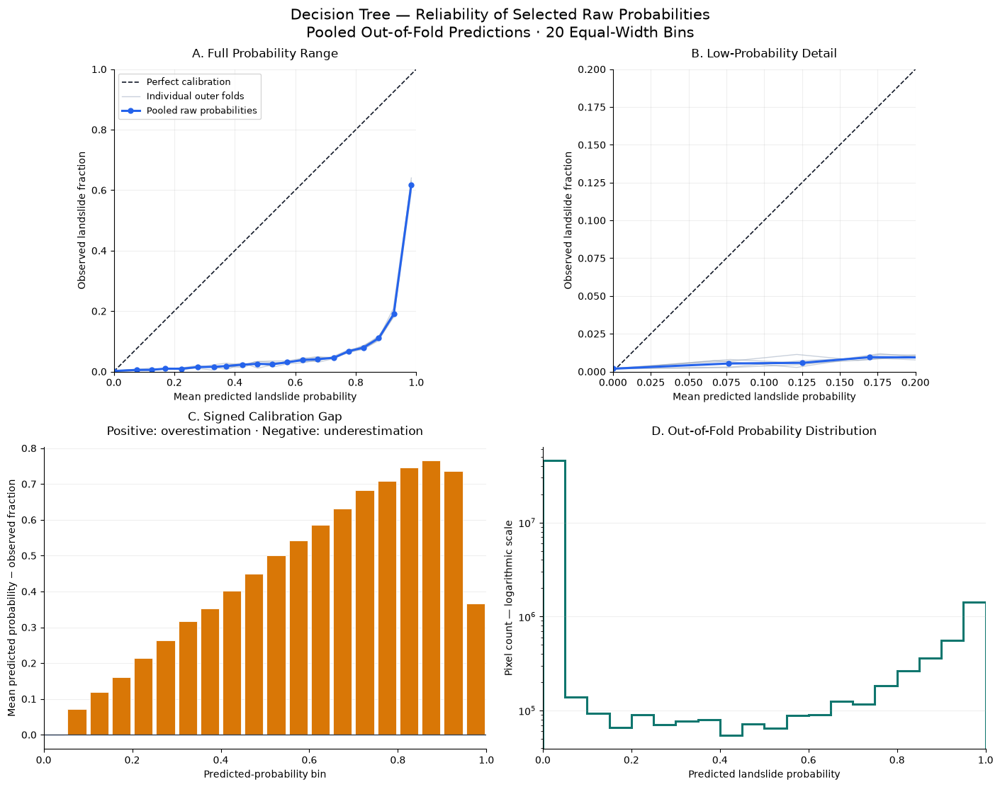

In [51]:
# ---------------------------------------------------------
# 1. Summarize existing exact probability counts into 20 bins
# ---------------------------------------------------------
dt_oof_reliability_edges = np.linspace(0, 1, 21)


def summarize_dt_probability_bins(scores, positives, negatives, edges):
    number_of_bins = len(edges) - 1

    bin_ids = np.minimum(
        np.searchsorted(edges, scores, side="right") - 1,
        number_of_bins - 1
    )

    score_counts = positives + negatives

    counts = np.bincount(
        bin_ids, weights=score_counts, minlength=number_of_bins
    )
    probability_sums = np.bincount(
        bin_ids,
        weights=score_counts * scores,
        minlength=number_of_bins
    )
    positive_sums = np.bincount(
        bin_ids, weights=positives, minlength=number_of_bins
    )

    nonempty = counts > 0

    mean_probability = np.divide(
        probability_sums,
        counts,
        out=np.full(number_of_bins, np.nan),
        where=nonempty
    )
    observed_fraction = np.divide(
        positive_sums,
        counts,
        out=np.full(number_of_bins, np.nan),
        where=nonempty
    )

    table = pd.DataFrame({
        "bin_left": edges[:-1],
        "bin_right": edges[1:],
        "pixels": counts.astype(np.int64),
        "pixel_fraction": counts / counts.sum(),
        "mean_probability": mean_probability,
        "observed_landslide_fraction": observed_fraction,
        "probability_minus_observed": (
            mean_probability - observed_fraction
        )
    })

    summary = {
        "pixels": int(counts.sum()),
        "nonempty_bins": int(nonempty.sum()),
        "mean_predicted_probability": (
            probability_sums.sum() / counts.sum()
        ),
        "observed_landslide_fraction": (
            positive_sums.sum() / counts.sum()
        ),
        "ECE_20_equal_width_bins": float(np.sum(
            counts[nonempty] / counts.sum()
            * np.abs(
                mean_probability[nonempty]
                - observed_fraction[nonempty]
            )
        ))
    }

    return table, summary


score_values = dt_bootstrap_score_histograms["score_values"]
positive_matrix = dt_bootstrap_score_histograms["positive"]
negative_matrix = dt_bootstrap_score_histograms["negative"]

dt_oof_fold_reliability_tables = {}
dt_oof_reliability_summary_rows = []

for outer_number in range(1, 6):
    rows = (
        dt_bootstrap_patch_table["outer_fold"].to_numpy()
        == outer_number
    )

    table, summary = summarize_dt_probability_bins(
        score_values,
        np.asarray(positive_matrix[rows].sum(axis=0)).ravel(),
        np.asarray(negative_matrix[rows].sum(axis=0)).ravel(),
        dt_oof_reliability_edges
    )

    dt_oof_fold_reliability_tables[outer_number] = table
    dt_oof_reliability_summary_rows.append({
        "Evaluation": f"Fold {outer_number}",
        **summary
    })

dt_oof_reliability_table, pooled_summary = (
    summarize_dt_probability_bins(
        score_values,
        np.asarray(positive_matrix.sum(axis=0)).ravel(),
        np.asarray(negative_matrix.sum(axis=0)).ravel(),
        dt_oof_reliability_edges
    )
)

dt_oof_reliability_summary_rows.append({
    "Evaluation": "Pooled out-of-fold",
    **pooled_summary
})

dt_oof_reliability_summary = pd.DataFrame(
    dt_oof_reliability_summary_rows
).set_index("Evaluation")

assert (
    dt_oof_reliability_table["pixels"].sum()
    == dt_pooled_pixel_count
)

print("OUTER-PREDICTION RELIABILITY SUMMARY")
display(dt_oof_reliability_summary.round(6))

print("\nPOOLED BIN DETAILS")
display(dt_oof_reliability_table.round(6))


# ---------------------------------------------------------
# 2. Reliability plots
# ---------------------------------------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11),
    constrained_layout=True
)

pooled = dt_oof_reliability_table
valid = pooled["pixels"] > 0

for ax, limit, title in [
    (axes[0, 0], 1.0, "A. Full Probability Range"),
    (axes[0, 1], 0.20, "B. Low-Probability Detail")
]:
    ax.plot(
        [0, limit], [0, limit],
        linestyle="--",
        color="#111827",
        linewidth=1.2,
        label="Perfect calibration"
    )

    for outer_number, table in dt_oof_fold_reliability_tables.items():
        nonempty = table["pixels"] > 0

        ax.plot(
            table.loc[nonempty, "mean_probability"],
            table.loc[nonempty, "observed_landslide_fraction"],
            color="#94A3B8",
            alpha=0.5,
            linewidth=1,
            label="Individual outer folds" if outer_number == 1 else None
        )

    ax.plot(
        pooled.loc[valid, "mean_probability"],
        pooled.loc[valid, "observed_landslide_fraction"],
        color="#2563EB",
        marker="o",
        markersize=5,
        linewidth=2.2,
        label="Pooled raw probabilities"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_xlabel("Mean predicted landslide probability")
    ax.set_ylabel("Observed landslide fraction")
    ax.set_title(title, fontsize=12, pad=12)
    ax.grid(alpha=0.2)
    ax.set_aspect("equal", adjustable="box")

axes[0, 0].legend(loc="upper left", fontsize=9)


# ---------------------------------------------------------
# 3. Signed calibration gaps
# ---------------------------------------------------------
ax = axes[1, 0]

centers = (
    pooled["bin_left"].to_numpy()
    + pooled["bin_right"].to_numpy()
) / 2

gaps = pooled["probability_minus_observed"].to_numpy()

ax.bar(
    centers[valid],
    gaps[valid],
    width=0.042,
    color=[
        "#D97706" if gap >= 0 else "#2563EB"
        for gap in gaps[valid]
    ],
    edgecolor="white",
    linewidth=0.6
)

ax.axhline(0, color="#334155", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted-probability bin")
ax.set_ylabel("Mean predicted probability − observed fraction")
ax.set_title(
    "C. Signed Calibration Gap\n"
    "Positive: overestimation · Negative: underestimation",
    fontsize=12,
    pad=12
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)


# ---------------------------------------------------------
# 4. Probability distribution
# ---------------------------------------------------------
ax = axes[1, 1]

distribution_counts = pooled["pixels"].to_numpy(dtype=float)
distribution_counts[distribution_counts == 0] = np.nan

ax.stairs(
    distribution_counts,
    dt_oof_reliability_edges,
    color="#0F766E",
    linewidth=2.2
)

ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted landslide probability")
ax.set_ylabel("Pixel count — logarithmic scale")
ax.set_title(
    "D. Out-of-Fold Probability Distribution",
    fontsize=12,
    pad=12
)
ax.grid(axis="y", alpha=0.2)

for ax in axes.flat:
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Reliability of Selected Raw Probabilities\n"
    "Pooled Out-of-Fold Predictions · 20 Equal-Width Bins",
    fontsize=15
)

plt.show()

### Rationale — Out-of-Fold Probability Reliability

Ranking and threshold-based performance do not establish probability calibration. Reliability was therefore examined separately using 20 equal-width bins.

### Result — Raw Probabilities Are Miscalibrated

Mean predicted landslide probability was 0.062466, compared with observed prevalence of 0.023647. Pooled binned ECE was 0.042018.

Most probability bins showed overestimation. In the 0.90–0.95 bin, mean predicted probability was 0.925482 while observed landslide frequency was 0.190365. In the 0.95–1.00 bin, these values were 0.983359 and 0.617012.

Approximately 91.90% of pixels occupied the lowest bin. There, mean predicted probability was 0.000150 and observed frequency was 0.001890, indicating underestimation at very low probabilities.

Class weighting can contribute to raw probabilities differing from observed class frequencies. The selected pipeline optimized F2 after threshold tuning, not probability calibration.

Raw outputs must therefore not be interpreted as calibrated confidence percentages. No recalibration or retuning will be performed using these outer-evaluation results.

ECE is bin-dependent and does not describe every bin's discrepancy. The reliability curves, signed gaps, distribution, Brier score, and log loss should be interpreted together.

### Visualization Decision

The four-panel figure adequately documents this limitation. No additional reliability plot is required.

In [52]:
# ---------------------------------------------------------
# 1. Define descriptive coverage groups
# ---------------------------------------------------------
dt_coverage_patch_records = dt_oof_patch_counts.copy()

assert dt_coverage_patch_records["patch_id"].is_unique
assert dt_coverage_patch_records["landslide_fraction"].between(0, 1).all()

DT_COVERAGE_EDGES = [-np.inf, 0, 0.01, 0.05, 0.20, 1.0]
DT_COVERAGE_LABELS = [
    "No landslide",
    ">0–1%",
    ">1–5%",
    ">5–20%",
    ">20%"
]

dt_coverage_patch_records["coverage_group"] = pd.cut(
    dt_coverage_patch_records["landslide_fraction"],
    bins=DT_COVERAGE_EDGES,
    labels=DT_COVERAGE_LABELS,
    right=True,
    include_lowest=True
)

assert dt_coverage_patch_records["coverage_group"].notna().all()

dt_coverage_rows = []

for label in DT_COVERAGE_LABELS:
    group = dt_coverage_patch_records.loc[
        dt_coverage_patch_records["coverage_group"] == label
    ]

    if group.empty:
        dt_coverage_rows.append({
            "coverage_group": label,
            "patches": 0,
            "pixels": 0,
            "landslide_pixels": 0,
            "F2": np.nan,
            "Precision": np.nan,
            "Recall": np.nan,
            "Specificity": np.nan,
            "IoU": np.nan,
            "FP": 0,
            "FN": 0,
            "Brier": np.nan,
            "Log_loss": np.nan
        })
        continue

    tn, fp, fn, tp = (
        group[["TN", "FP", "FN", "TP"]]
        .sum()
        .to_numpy()
    )

    pixels = int(group["pixels"].sum())
    actual_positives = int(tp + fn)
    beta_squared = BETA ** 2

    # Detection metrics are not informative for an all-negative group
    if actual_positives > 0:
        f2 = dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        )
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = dt_safe_ratio(tp, tp + fn)
        iou = dt_safe_ratio(tp, tp + fp + fn)
    else:
        f2 = precision = recall = iou = np.nan

    dt_coverage_rows.append({
        "coverage_group": label,
        "patches": len(group),
        "pixels": pixels,
        "landslide_pixels": actual_positives,
        "F2": f2,
        "Precision": precision,
        "Recall": recall,
        "Specificity": dt_safe_ratio(tn, tn + fp),
        "IoU": iou,
        "FP": int(fp),
        "FN": int(fn),
        "Brier": group["squared_error_sum"].sum() / pixels,
        "Log_loss": group["log_loss_sum"].sum() / pixels
    })

dt_coverage_summary = pd.DataFrame(
    dt_coverage_rows
).set_index("coverage_group")

assert dt_coverage_summary["patches"].sum() == len(dev_ids)

print("PERFORMANCE BY TRUE LANDSLIDE COVERAGE")
display(
    dt_coverage_summary[
        [
            "patches", "landslide_pixels",
            "F2", "Precision", "Recall", "IoU"
        ]
    ].round(6)
)

print("\nERROR COUNTS AND PROBABILITY SCORES")
display(
    dt_coverage_summary[
        ["pixels", "FP", "FN", "Specificity", "Brier", "Log_loss"]
    ].round(6)
)


# ---------------------------------------------------------
# 2. Dedicated analysis of patches with no true landslide
# ---------------------------------------------------------
dt_negative_patch_records = dt_coverage_patch_records.loc[
    dt_coverage_patch_records["landslide_pixels"] == 0
].copy()

if len(dt_negative_patch_records) > 0:
    negative_fp = dt_negative_patch_records["FP"].to_numpy()
    negative_pixels = int(
        dt_negative_patch_records["pixels"].sum()
    )

    dt_negative_patch_summary = pd.Series({
        "negative_patches": len(dt_negative_patch_records),
        "patches_with_any_false_positive": int(
            np.count_nonzero(negative_fp > 0)
        ),
        "fraction_with_any_false_positive": float(
            np.mean(negative_fp > 0)
        ),
        "total_false_positive_pixels": int(negative_fp.sum()),
        "pixel_false_positive_rate": (
            negative_fp.sum() / negative_pixels
        ),
        "mean_FP_pixels_per_patch": float(negative_fp.mean()),
        "median_FP_pixels_per_patch": float(np.median(negative_fp)),
        "95th_percentile_FP_pixels_per_patch": float(
            np.quantile(negative_fp, 0.95)
        ),
        "maximum_FP_pixels_per_patch": int(negative_fp.max())
    }, name="Value")

    print("\nFALSE ALARMS ON COMPLETELY NEGATIVE PATCHES")
    display(dt_negative_patch_summary.to_frame().round(6))

else:
    dt_negative_patch_summary = pd.Series(dtype=float)
    print("\nNo completely negative patches were present.")

PERFORMANCE BY TRUE LANDSLIDE COVERAGE


,patches,landslide_pixels,F2,Precision,Recall,IoU
coverage_group,,,,,,
No landslide,1254,0,NaN,NaN,NaN,NaN
>0–1%,610,40609,0.452329,0.189129,0.693664,0.174550
>1–5%,700,298158,0.665253,0.442121,0.761308,0.388297
>5–20%,438,669859,0.792036,0.620564,0.850809,0.559663
>20%,37,168783,0.851806,0.759508,0.878495,0.687308



ERROR COUNTS AND PROBABILITY SCORES


,pixels,FP,FN,Specificity,Brier,Log_loss
coverage_group,,,,,,
No landslide,20545536,112749,0,0.994512,0.012340,0.038528
>0–1%,9994240,120772,12440,0.987867,0.025179,0.099066
>1–5%,11468800,286421,71168,0.974359,0.049958,0.250410
>5–20%,7176192,348472,99937,0.946441,0.086206,0.470925
>20%,606208,46950,20508,0.892667,0.132254,0.915329



FALSE ALARMS ON COMPLETELY NEGATIVE PATCHES


,Value
negative_patches,1254.000000
patches_with_any_false_positive,1062.000000
fraction_with_any_false_positive,0.846890
total_false_positive_pixels,112749.000000
pixel_false_positive_rate,0.005488
mean_FP_pixels_per_patch,89.911483
median_FP_pixels_per_patch,27.000000
95th_percentile_FP_pixels_per_patch,399.950000
maximum_FP_pixels_per_patch,3185.000000


### Rationale — Coverage Subgroups and Negative-Patch Errors

Pooled metrics can conceal performance differences between low-coverage landslide patches and completely negative patches.

### Result — Coverage-Dependent Performance

F2 increased across the positive-coverage groups:

- >0–1%: 0.452329; 610 patches.
- >1–5%: 0.665253; 700 patches.
- >5–20%: 0.792036; 438 patches.
- >20%: 0.851806; 37 patches.

Precision and recall also increased with coverage. However, class prevalence affects these metrics, the highest-coverage group contains few patches, and patch coverage does not identify individual landslide-object size.

Brier score and log loss worsened with increasing coverage, despite improved classification metrics. Probability quality and threshold-based detection therefore require separate interpretation.

### Result — Completely Negative Patches

Among 1,254 negative patches, 1,062 (84.69%) contained at least one false-positive pixel.

There were 112,749 false-positive pixels in total, corresponding to a pixel false-positive rate of approximately 0.55%. Median false-positive count was 27 pixels per patch; the 95th percentile was approximately 400, and the maximum was 3,185.

The high fraction of affected patches and low pixel false-positive rate use different denominators. Neither directly measures the number of false landslide objects or operational review burden.

### Visualization Decision

Coverage-performance plots with patch counts and an empirical cumulative distribution of negative-patch false positives are appropriate next.

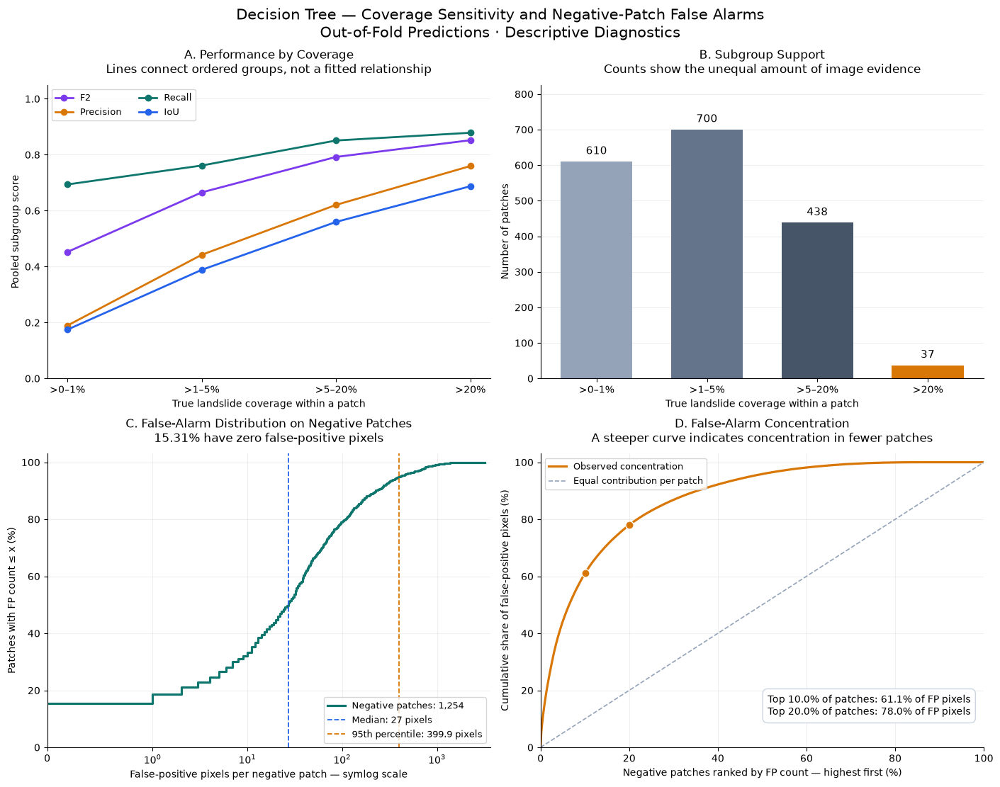

In [53]:
positive_groups = DT_COVERAGE_LABELS[1:]
coverage_plot = dt_coverage_summary.loc[positive_groups]

negative_fp = np.sort(
    dt_negative_patch_records["FP"].to_numpy()
)

if len(negative_fp) == 0:
    raise ValueError("No negative patches are available for these plots.")

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11),
    constrained_layout=True
)

# ---------------------------------------------------------
# A. Performance by true landslide coverage
# ---------------------------------------------------------
ax = axes[0, 0]
positions = np.arange(len(positive_groups))

for metric, color in [
    ("F2", "#7C3AED"),
    ("Precision", "#D97706"),
    ("Recall", "#0F766E"),
    ("IoU", "#2563EB")
]:
    ax.plot(
        positions,
        coverage_plot[metric].to_numpy(),
        marker="o",
        markersize=6,
        linewidth=2,
        color=color,
        label=metric
    )

ax.set_xticks(positions, positive_groups)
ax.set_ylim(0, 1.05)
ax.set_xlabel("True landslide coverage within a patch")
ax.set_ylabel("Pooled subgroup score")
ax.set_title(
    "A. Performance by Coverage\n"
    "Lines connect ordered groups, not a fitted relationship",
    fontsize=12,
    pad=12
)
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.grid(axis="y", alpha=0.2)


# ---------------------------------------------------------
# B. Number of patches supporting each subgroup
# ---------------------------------------------------------
ax = axes[0, 1]

patch_counts = coverage_plot["patches"].to_numpy()

bars = ax.bar(
    positions,
    patch_counts,
    color=["#94A3B8", "#64748B", "#475569", "#D97706"],
    width=0.65
)

ax.bar_label(
    bars,
    labels=[f"{int(n):,}" for n in patch_counts],
    padding=5,
    fontsize=11
)

ax.set_xticks(positions, positive_groups)
ax.set_ylim(0, max(patch_counts) * 1.18)
ax.set_xlabel("True landslide coverage within a patch")
ax.set_ylabel("Number of patches")
ax.set_title(
    "B. Subgroup Support\n"
    "Counts show the unequal amount of image evidence",
    fontsize=12,
    pad=12
)
ax.grid(axis="y", alpha=0.2)


# ---------------------------------------------------------
# C. Empirical CDF of negative-patch false positives
# ---------------------------------------------------------
ax = axes[1, 0]

unique_fp, frequency = np.unique(
    negative_fp,
    return_counts=True
)
cumulative_percentage = np.cumsum(frequency) / len(negative_fp) * 100

median_fp = float(np.median(negative_fp))
percentile_95_fp = float(np.quantile(negative_fp, 0.95))
zero_fp_percentage = float(np.mean(negative_fp == 0) * 100)

ax.step(
    unique_fp,
    cumulative_percentage,
    where="post",
    color="#0F766E",
    linewidth=2.3,
    label=f"Negative patches: {len(negative_fp):,}"
)

ax.axvline(
    median_fp,
    color="#2563EB",
    linestyle="--",
    linewidth=1.3,
    label=f"Median: {median_fp:.0f} pixels"
)
ax.axvline(
    percentile_95_fp,
    color="#D97706",
    linestyle="--",
    linewidth=1.3,
    label=f"95th percentile: {percentile_95_fp:.1f} pixels"
)

# Unlike a logarithmic axis, symlog can display zero
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(0, max(negative_fp.max() * 1.15, 2))
ax.set_ylim(0, 103)
ax.set_xlabel("False-positive pixels per negative patch — symlog scale")
ax.set_ylabel("Patches with FP count ≤ x (%)")
ax.set_title(
    "C. False-Alarm Distribution on Negative Patches\n"
    f"{zero_fp_percentage:.2f}% have zero false-positive pixels",
    fontsize=12,
    pad=12
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)


# ---------------------------------------------------------
# D. Concentration of false positives across negative patches
# ---------------------------------------------------------
ax = axes[1, 1]

ranked_fp = negative_fp[::-1]
total_fp = ranked_fp.sum()

if total_fp > 0:
    patch_share = np.arange(1, len(ranked_fp) + 1) / len(ranked_fp)
    false_positive_share = np.cumsum(ranked_fp) / total_fp

    ax.plot(
        np.r_[0, patch_share] * 100,
        np.r_[0, false_positive_share] * 100,
        color="#D97706",
        linewidth=2.3,
        label="Observed concentration"
    )

    ax.plot(
        [0, 100], [0, 100],
        linestyle="--",
        color="#94A3B8",
        linewidth=1.2,
        label="Equal contribution per patch"
    )

    concentration_notes = []

    for fraction in [0.10, 0.20]:
        number_selected = max(
            1, int(np.ceil(len(ranked_fp) * fraction))
        )

        x_value = number_selected / len(ranked_fp) * 100
        y_value = ranked_fp[:number_selected].sum() / total_fp * 100

        ax.scatter(
            x_value, y_value,
            s=65,
            color="#D97706",
            edgecolors="white",
            zorder=4
        )

        concentration_notes.append(
            f"Top {x_value:.1f}% of patches: "
            f"{y_value:.1f}% of FP pixels"
        )

    ax.text(
        0.97, 0.10,
        "\n".join(concentration_notes),
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="#CBD5E1"
        )
    )

else:
    ax.text(
        0.5, 0.5,
        "No false-positive pixels",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

ax.set_xlim(0, 100)
ax.set_ylim(0, 103)
ax.set_xlabel("Negative patches ranked by FP count — highest first (%)")
ax.set_ylabel("Cumulative share of false-positive pixels (%)")
ax.set_title(
    "D. False-Alarm Concentration\n"
    "A steeper curve indicates concentration in fewer patches",
    fontsize=12,
    pad=12
)
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.2)

for ax in axes.flat:
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Coverage Sensitivity and Negative-Patch False Alarms\n"
    "Out-of-Fold Predictions · Descriptive Diagnostics",
    fontsize=15
)

plt.show()

### Rationale — Coverage and False-Alarm Diagnostics

The figure examines subgroup performance, the number of supporting patches, and the distribution and concentration of false positives on completely negative patches.

### Result — Coverage and False-Alarm Patterns

Performance increased with true landslide coverage. The lowest-coverage positive group had the weakest detection scores. The highest-coverage group contained only 37 patches, limiting the image support for its result.

Among negative patches, 15.31% had no false-positive pixels. The median false-positive count was 27 pixels, and the 95th percentile was approximately 400 pixels.

False positives were strongly concentrated: approximately 10% of negative patches accounted for 61.1% of false-positive pixels, while approximately 20% accounted for 78.0%.

This identifies useful cases for diagnostic inspection, not grounds for removing difficult patches or retuning on outer-evaluation results.

These are descriptive pixel-level analyses. They do not measure independent false landslide objects, geographic area, or operational review time.

The four panels sufficiently cover this analysis; no additional plot is required.

In [54]:
# Fixed comparison IDs recorded in the project handoff
dt_fixed_spatial_examples = [
    ("105", "Fixed diagnostic"),
    ("2684", "Fixed diagnostic"),
    ("3459", "Fixed diagnostic"),
    ("1535", "Previously selected random example"),
    ("590", "Previously selected random example"),
    ("3316", "Previously selected random example")
]

development_id_set = set(str(i) for i in dev_ids)
holdout_id_set = set(str(i) for i in test_ids)

dt_oof_location_by_id = {}

for outer_number, result in sorted(dt_outer_evaluations.items()):
    for patch_position, patch_id in enumerate(result["patch_ids"]):
        patch_id = str(patch_id)

        if patch_id in dt_oof_location_by_id:
            raise ValueError(f"Duplicate outer-evaluation ID: {patch_id}")

        dt_oof_location_by_id[patch_id] = {
            "outer_fold": outer_number,
            "patch_position": patch_position
        }

dt_spatial_membership_rows = []

for patch_id, example_type in dt_fixed_spatial_examples:
    if patch_id in development_id_set:
        partition = "Development"
        location = dt_oof_location_by_id[patch_id]
        outer_fold = location["outer_fold"]
        next_use = "Use stored out-of-fold prediction"

    elif patch_id in holdout_id_set:
        partition = "Holdout"
        outer_fold = pd.NA
        next_use = "Reserve for final-model holdout evaluation"

    else:
        partition = "Not found"
        outer_fold = pd.NA
        next_use = "Check ID before plotting"

    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
    )

    dt_spatial_membership_rows.append({
        "patch_id": patch_id,
        "example_type": example_type,
        "partition": partition,
        "outer_fold": outer_fold,
        "image_exists": image_path.is_file(),
        "mask_exists": mask_path.is_file(),
        "next_use": next_use
    })

dt_spatial_membership_table = pd.DataFrame(
    dt_spatial_membership_rows
)

print("FIXED SPATIAL EXAMPLES — PARTITION CHECK")
display(dt_spatial_membership_table)

print("No new predictions computed.")

FIXED SPATIAL EXAMPLES — PARTITION CHECK


,patch_id,example_type,partition,outer_fold,image_exists,mask_exists,next_use
0,105,Fixed diagnostic,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation
1,2684,Fixed diagnostic,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation
2,3459,Fixed diagnostic,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation
3,1535,Previously selected random example,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation
4,590,Previously selected random example,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation
5,3316,Previously selected random example,Holdout,<NA>,True,True,Reserve for final-model holdout evaluation


No new predictions computed.


### Rationale — Checking Spatial-Example Membership

The fixed comparison IDs were checked to distinguish development out-of-fold diagnostics from later holdout evaluation.

### Result — Fixed Examples Belong to the Holdout Set

All six fixed examples—105, 2684, 3459, 1535, 590, and 3316—belong to the holdout partition. Their image and reference-mask files are available.

These IDs will be retained for consistent cross-method spatial comparison after final-model fitting. No new predictions were computed.

Current out-of-fold spatial diagnostics will use development patches, with the example-selection procedure explicitly documented.

### Visualization Decision

No plot is required for this membership check. Spatial prediction and error maps will follow for selected development examples.

In [55]:
rng = np.random.default_rng(RANDOM_STATE)

dt_spatial_selection_rows = []
selected_ids = set()


def add_dt_spatial_example(patch_id, selection_reason):
    patch_id = str(patch_id)

    if patch_id in selected_ids:
        raise ValueError(f"Duplicate spatial example: {patch_id}")

    selected_ids.add(patch_id)

    dt_spatial_selection_rows.append({
        "patch_id": patch_id,
        "selection_reason": selection_reason
    })


# 1. One random example from each positive-coverage group
for coverage_group in DT_COVERAGE_LABELS[1:]:
    candidates = (
        dt_coverage_patch_records.loc[
            dt_coverage_patch_records["coverage_group"] == coverage_group,
            "patch_id"
        ]
        .astype(str)
        .sort_values()
        .to_numpy()
    )

    if len(candidates) > 0:
        add_dt_spatial_example(
            rng.choice(candidates),
            f"Random within coverage group {coverage_group}"
        )


# 2. One random completely negative patch
negative_candidates = (
    dt_negative_patch_records["patch_id"]
    .astype(str)
    .sort_values()
    .to_numpy()
)

if len(negative_candidates) > 0:
    add_dt_spatial_example(
        rng.choice(negative_candidates),
        "Random completely negative patch"
    )


# 3. Highest-FP negative patch not already selected
remaining_negative = dt_negative_patch_records.loc[
    ~dt_negative_patch_records["patch_id"].astype(str).isin(selected_ids)
].copy()

if not remaining_negative.empty:
    hard_negative = (
        remaining_negative
        .sort_values(
            ["FP", "patch_id"],
            ascending=[False, True]
        )
        .iloc[0]
    )

    add_dt_spatial_example(
        hard_negative["patch_id"],
        "Targeted: highest-FP remaining negative patch"
    )


# Attach existing out-of-fold results
dt_spatial_example_table = (
    pd.DataFrame(dt_spatial_selection_rows)
    .merge(
        dt_coverage_patch_records[
            [
                "patch_id", "outer_fold", "coverage_group",
                "landslide_fraction", "TP", "FP", "FN"
            ]
        ],
        on="patch_id",
        validate="one_to_one"
    )
)

dt_spatial_example_table["true_landslide_percent"] = (
    100 * dt_spatial_example_table["landslide_fraction"]
)

dt_spatial_example_table["locked_threshold"] = (
    dt_spatial_example_table["outer_fold"]
    .map({
        fold: settings["threshold"]
        for fold, settings in dt_locked_settings_by_outer.items()
    })
)

assert dt_spatial_example_table["patch_id"].is_unique
assert set(dt_spatial_example_table["patch_id"]).issubset(
    set(str(i) for i in dev_ids)
)
assert set(dt_spatial_example_table["patch_id"]).isdisjoint(
    set(str(i) for i in test_ids)
)

for row in dt_spatial_example_table.itertuples():
    location = dt_oof_location_by_id[row.patch_id]
    assert location["outer_fold"] == row.outer_fold

print("DEVELOPMENT EXAMPLES FOR OUT-OF-FOLD SPATIAL DIAGNOSTICS")
print("Random seed:", RANDOM_STATE)

display(
    dt_spatial_example_table[
        [
            "patch_id", "selection_reason", "outer_fold",
            "true_landslide_percent", "locked_threshold",
            "TP", "FP", "FN"
        ]
    ].round(6)
)

print("No new predictions computed.")

DEVELOPMENT EXAMPLES FOR OUT-OF-FOLD SPATIAL DIAGNOSTICS
Random seed: 43


,patch_id,selection_reason,outer_fold,true_landslide_percent,locked_threshold,TP,FP,FN
0,2646,Random within coverage group >0–1%,5,0.067139,0.91,11,60,0
1,3105,Random within coverage group >1–5%,1,3.912354,0.91,551,823,90
2,2067,Random within coverage group >5–20%,4,8.972168,0.92,1280,1654,190
3,1495,Random within coverage group >20%,3,28.149414,0.91,4426,1042,186
4,3033,Random completely negative patch,5,0.000000,0.91,0,0,0
5,943,Targeted: highest-FP remaining negative patch,4,0.000000,0.92,0,3185,0


No new predictions computed.


### Rationale — Selecting Spatial Diagnostic Examples

Examples were selected to inspect predictions across four positive-coverage groups, a random negative patch, and a targeted high-false-positive negative patch.

### Result — Selected Development Examples

Using random seed 43, the positive examples were 2646, 3105, 2067, and 1495. Patch 3033 was selected randomly from negative patches and had no false-positive pixels.

Patch 943 was selected deliberately as the highest-FP remaining negative patch. It contained 3,185 false-positive pixels, approximately 19.44% of its area in pixel units. It is a targeted failure example, not a representative negative patch.

All six examples belong to development data and have stored out-of-fold predictions. No new predictions were computed.

The examples are illustrative, not a representative estimate of overall performance. The six fixed holdout examples remain reserved for later final-model comparison.

### Visualization Decision

Spatial displays are required to inspect the locations and patterns of true detections, missed pixels, and false positives.

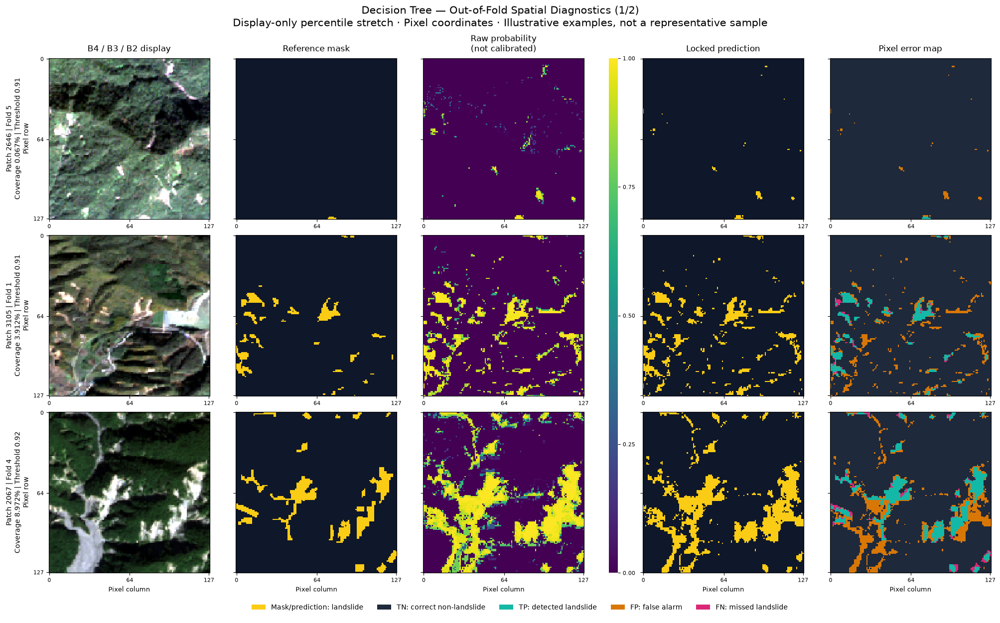

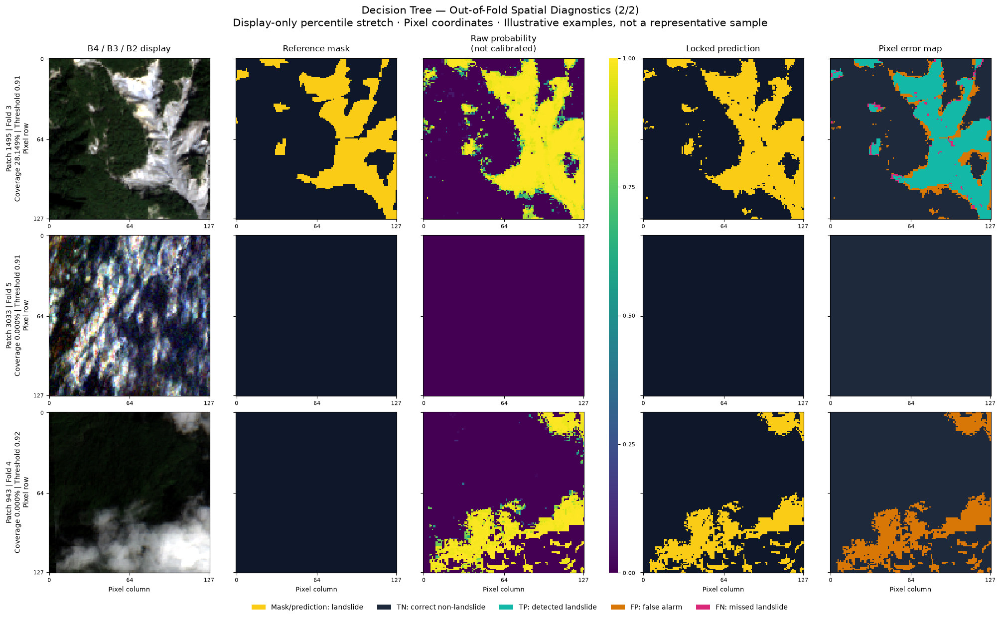

In [56]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Display channels follow the saved feature order
dt_display_channels = [
    FEATURE_NAMES.index(name)
    for name in ["B4", "B3", "B2"]
]

dt_binary_cmap = ListedColormap([
    "#0F172A",  # Non-landslide
    "#FACC15"   # Landslide
])

# Error codes: 0=TN, 1=FP, 2=FN, 3=TP
dt_error_cmap = ListedColormap([
    "#1E293B",
    "#D97706",
    "#DB2777",
    "#14B8A6"
])
dt_error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    dt_error_cmap.N
)


def dt_display_composite(image):
    """Per-channel 2nd–98th percentile stretch, for display only."""
    composite = image[..., dt_display_channels].astype(
        np.float64, copy=True
    )

    for channel in range(3):
        low, high = np.percentile(
            composite[..., channel], [2, 98]
        )

        if high > low:
            composite[..., channel] = np.clip(
                (composite[..., channel] - low) / (high - low),
                0, 1
            )
        else:
            composite[..., channel] = 0.0

    return composite


dt_spatial_plot_records = []
dt_patch_audit_by_id = dt_oof_patch_counts.set_index("patch_id")

for example in dt_spatial_example_table.itertuples():
    patch_id = str(example.patch_id)
    location = dt_oof_location_by_id[patch_id]

    outer_number = location["outer_fold"]
    patch_position = location["patch_position"]

    evaluation = dt_outer_evaluations[outer_number]
    threshold = evaluation["settings"]["threshold"]

    # Stored out-of-fold predictions; no new model prediction
    probability = evaluation["probability"].reshape(
        -1, 128, 128
    )[patch_position]

    cached_mask = evaluation["y"].reshape(
        -1, 128, 128
    )[patch_position]

    image_path = (
        DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
    )
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
    )

    with h5py.File(image_path, "r") as file:
        image = np.asarray(file["img"], dtype=np.float32)

    with h5py.File(mask_path, "r") as file:
        mask = np.asarray(file["mask"])

    assert image.shape == (128, 128, len(FEATURE_NAMES))
    assert mask.shape == (128, 128)
    assert np.isfinite(image).all()
    assert np.isin(mask, [0, 1]).all()
    assert np.array_equal(mask, cached_mask)

    prediction = (probability >= threshold).astype(np.uint8)
    error_map = 2 * mask.astype(np.uint8) + prediction

    # Verify maps reproduce the previously reported counts
    observed_counts = np.bincount(
        error_map.ravel(), minlength=4
    )
    expected_counts = (
        dt_patch_audit_by_id.loc[
            patch_id, ["TN", "FP", "FN", "TP"]
        ].to_numpy(dtype=np.int64)
    )

    assert np.array_equal(observed_counts, expected_counts)

    dt_spatial_plot_records.append({
        "patch_id": patch_id,
        "outer_fold": outer_number,
        "threshold": threshold,
        "coverage_percent": float(mask.mean() * 100),
        "selection_reason": example.selection_reason,
        "composite": dt_display_composite(image),
        "mask": mask,
        "probability": probability,
        "prediction": prediction,
        "error_map": error_map
    })


# Two figures, three patches per figure
for start in range(0, len(dt_spatial_plot_records), 3):
    examples = dt_spatial_plot_records[start:start + 3]
    number_of_rows = len(examples)

    fig = plt.figure(
        figsize=(20, 3.8 * number_of_rows + 1),
        constrained_layout=True
    )

    grid = fig.add_gridspec(
        number_of_rows + 1,
        6,
        width_ratios=[1, 1, 1, 0.055, 1, 1],
        height_ratios=[1] * number_of_rows + [0.13]
    )

    image_columns = [0, 1, 2, 4, 5]
    column_titles = [
        "B4 / B3 / B2 display",
        "Reference mask",
        "Raw probability\n(not calibrated)",
        "Locked prediction",
        "Pixel error map"
    ]

    for row, example in enumerate(examples):
        axes = [
            fig.add_subplot(grid[row, column])
            for column in image_columns
        ]

        axes[0].imshow(
            example["composite"], interpolation="nearest"
        )
        axes[1].imshow(
            example["mask"],
            cmap=dt_binary_cmap,
            vmin=0, vmax=1,
            interpolation="nearest"
        )

        probability_image = axes[2].imshow(
            example["probability"],
            cmap="viridis",
            vmin=0, vmax=1,
            interpolation="nearest"
        )

        axes[3].imshow(
            example["prediction"],
            cmap=dt_binary_cmap,
            vmin=0, vmax=1,
            interpolation="nearest"
        )
        axes[4].imshow(
            example["error_map"],
            cmap=dt_error_cmap,
            norm=dt_error_norm,
            interpolation="nearest"
        )

        for column, ax in enumerate(axes):
            if row == 0:
                ax.set_title(
                    column_titles[column],
                    fontsize=12,
                    pad=10
                )

            ax.set_xticks([0, 64, 127])
            ax.set_yticks([0, 64, 127])
            ax.tick_params(labelsize=8)

            if row == number_of_rows - 1:
                ax.set_xlabel("Pixel column", fontsize=9)

            if column != 0:
                ax.tick_params(axis="y", labelleft=False)

        axes[0].set_ylabel(
            f"Patch {example['patch_id']} | Fold {example['outer_fold']}\n"
            f"Coverage {example['coverage_percent']:.3f}% | "
            f"Threshold {example['threshold']:.2f}\n"
            "Pixel row",
            fontsize=10
        )

    colorbar_axis = fig.add_subplot(grid[:number_of_rows, 3])
    colorbar = fig.colorbar(
        probability_image,
        cax=colorbar_axis,
        ticks=[0, 0.25, 0.5, 0.75, 1]
    )
    colorbar.ax.tick_params(labelsize=8)
    colorbar.outline.set_visible(False)

    legend_axis = fig.add_subplot(grid[number_of_rows, :])
    legend_axis.axis("off")

    legend_axis.legend(
        handles=[
            Patch(facecolor="#FACC15", label="Mask/prediction: landslide"),
            Patch(facecolor="#1E293B", label="TN: correct non-landslide"),
            Patch(facecolor="#14B8A6", label="TP: detected landslide"),
            Patch(facecolor="#D97706", label="FP: false alarm"),
            Patch(facecolor="#DB2777", label="FN: missed landslide")
        ],
        loc="center",
        ncol=5,
        frameon=False,
        fontsize=10
    )

    fig.suptitle(
        f"Decision Tree — Out-of-Fold Spatial Diagnostics "
        f"({start // 3 + 1}/2)\n"
        "Display-only percentile stretch · Pixel coordinates · "
        "Illustrative examples, not a representative sample",
        fontsize=15
    )

    plt.show()

### Rationale — Out-of-Fold Spatial Error Inspection

The maps locate correct detections, missed landslide pixels, and false positives in illustrative development examples.

### Result — Spatial Diagnostics

Patch 2646 contains a very small detected reference region alongside scattered false positives. Patches 3105 and 2067 show substantial false-positive regions outside the reference masks, together with missed pixels.

Patch 1495 shows substantial agreement over the main reference region, with remaining boundary and adjacent-area errors. Patch 3033 is correctly predicted as entirely negative.

Patch 943 demonstrates a targeted failure case: extensive false-positive regions despite an empty reference mask. The cause cannot be established from visual appearance alone.

These examples are illustrative and include one deliberately selected high-error negative patch. They are not a representative performance sample.

### Relationship to the Logistic Regression Examples

These development IDs differ from the fixed holdout examples used previously: 105, 2684, 3459, 1535, 590, and 3316.

The fixed holdout IDs remain reserved for consistent cross-method spatial comparison after final-model fitting. No direct same-image LR-versus-DT comparison is claimed from the current figures.

### Visualization Decision

Both figures are readable and sufficient for these selected examples. Raw-probability colors must not be interpreted as calibrated confidence.

IMPURITY-BASED FEATURE IMPORTANCE


,Mean importance,SD across folds,Minimum,Maximum
Feature,,,,
B4,0.567414,0.007067,0.556474,0.575800
Slope,0.086768,0.002338,0.084571,0.090379
Elevation,0.066889,0.006398,0.057683,0.075226
B7,0.066743,0.003510,0.062399,0.071096
B1,0.047836,0.001817,0.045326,0.049337
B2,0.045615,0.004350,0.040662,0.050600
B8,0.035640,0.002928,0.032932,0.039942
B10,0.020409,0.002527,0.017342,0.022880
B12,0.016633,0.002815,0.013270,0.020328


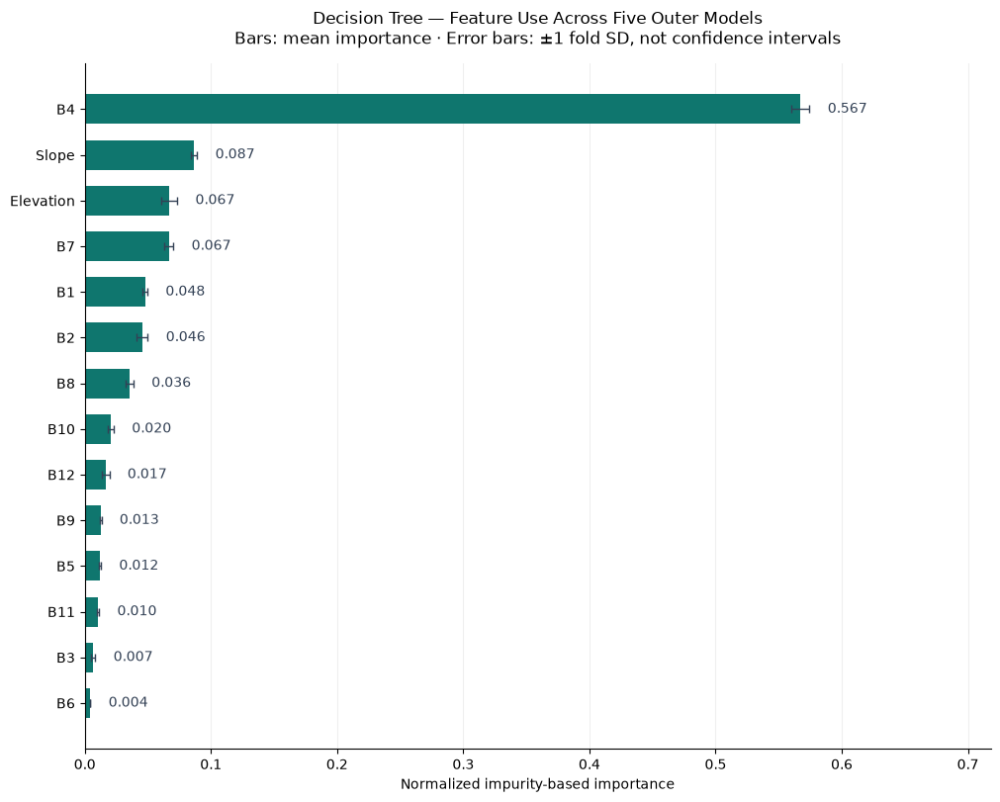

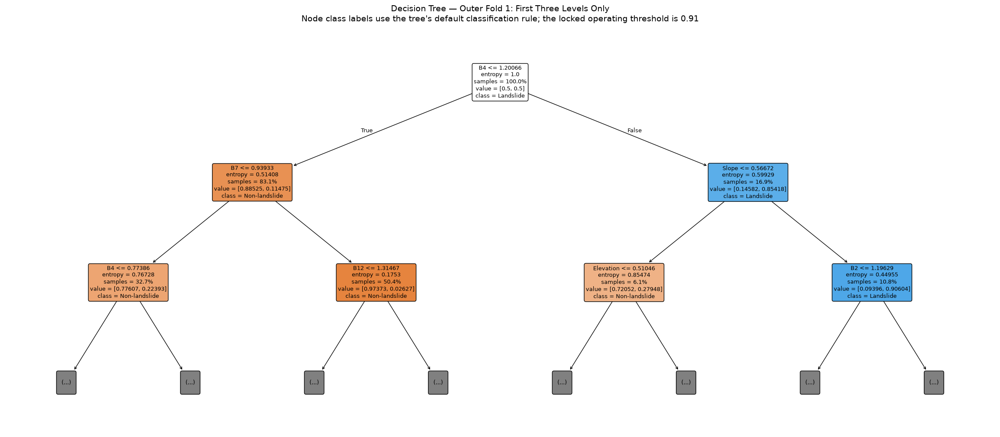

In [57]:
from sklearn.tree import plot_tree

# ---------------------------------------------------------
# 1. Feature importance from all five fitted outer models
# ---------------------------------------------------------
dt_impurity_importance_by_fold = pd.DataFrame(
    {
        f"Fold {outer_number}":
            bundle["model"].feature_importances_
        for outer_number, bundle in sorted(
            dt_fitted_bundles_by_outer.items()
        )
    },
    index=FEATURE_NAMES
)

assert dt_impurity_importance_by_fold.shape == (14, 5)

assert np.allclose(
    dt_impurity_importance_by_fold.sum(axis=0).to_numpy(),
    1.0
)

dt_impurity_importance_summary = pd.DataFrame({
    "Mean importance": dt_impurity_importance_by_fold.mean(axis=1),
    "SD across folds": dt_impurity_importance_by_fold.std(axis=1),
    "Minimum": dt_impurity_importance_by_fold.min(axis=1),
    "Maximum": dt_impurity_importance_by_fold.max(axis=1)
}).sort_values(
    "Mean importance",
    ascending=False,
    kind="stable"
)

dt_impurity_importance_summary.index.name = "Feature"

print("IMPURITY-BASED FEATURE IMPORTANCE")
display(dt_impurity_importance_summary.round(6))

fig, ax = plt.subplots(
    figsize=(10, 8),
    constrained_layout=True
)

positions = np.arange(len(dt_impurity_importance_summary))
means = dt_impurity_importance_summary["Mean importance"].to_numpy()
standard_deviations = (
    dt_impurity_importance_summary["SD across folds"].to_numpy()
)

ax.barh(
    positions,
    means,
    xerr=standard_deviations,
    height=0.65,
    color="#0F766E",
    capsize=3,
    error_kw={"ecolor": "#334155", "elinewidth": 1}
)

upper_extent = means + standard_deviations
label_padding = max(float(upper_extent.max()) * 0.025, 0.001)

for position, mean, upper in zip(positions, means, upper_extent):
    ax.text(
        upper + label_padding,
        position,
        f"{mean:.3f}",
        va="center",
        fontsize=10,
        color="#334155"
    )

ax.set_yticks(
    positions,
    dt_impurity_importance_summary.index
)
ax.invert_yaxis()
ax.set_xlim(0, max(float(upper_extent.max()) * 1.25, 0.05))
ax.set_xlabel("Normalized impurity-based importance")
ax.set_title(
    "Decision Tree — Feature Use Across Five Outer Models\n"
    "Bars: mean importance · Error bars: ±1 fold SD, not confidence intervals",
    fontsize=12,
    pad=14
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.show()


# ---------------------------------------------------------
# 2. Show only the first three tree levels
# ---------------------------------------------------------
dt_interpretation_model = dt_fitted_bundles_by_outer[1]["model"]

fig, ax = plt.subplots(
    figsize=(23, 10),
    constrained_layout=True
)

plot_tree(
    dt_interpretation_model,
    max_depth=2,
    feature_names=FEATURE_NAMES,
    class_names=["Non-landslide", "Landslide"],
    filled=True,
    rounded=True,
    proportion=True,
    impurity=True,
    precision=5,
    fontsize=9,
    ax=ax
)

ax.set_title(
    "Decision Tree — Outer Fold 1: First Three Levels Only\n"
    "Node class labels use the tree's default classification rule; "
    "the locked operating threshold is 0.91",
    fontsize=14,
    pad=18
)

plt.show()

### Rationale — Interpreting Feature Use and Tree Structure

Impurity-based importance and the upper tree levels describe how the fitted models use the predictors. They do not establish causal effects or independent feature contributions.

### Result — Feature Importance

B4 dominated mean normalized impurity importance at 0.567414, followed by Slope (0.086768), Elevation (0.066889), and B7 (0.066743).

B4 importance ranged from 0.556474 to 0.575800 across the five outer models. B6 and B3 had the lowest reported importance.

These values represent shares of weighted impurity reduction, not prediction accuracy. Correlated features can substitute for one another; low importance alone does not justify removal.

### Result — Upper Tree Structure

The outer-fold-1 tree first splits on B4 ≤ 1.20066. Subsequent displayed splits use B7, Slope, B4, B12, Elevation, and B2.

Thresholds use stored feature scales; terrain thresholds must not be interpreted directly as metres or degrees.

Node class proportions reflect class weighting. The root value near [0.5, 0.5] does not indicate 50% observed landslide prevalence. Node class labels also differ from the final decision rule using threshold 0.91.

Only the first three levels are displayed; omitted branches continue below the diagram.

### Visualization Decision

The importance chart is readable. The tree diagram benefits from enlargement for node-level reading. Performance-based permutation importance is needed as a complementary diagnostic.

In [58]:
DT_PERMUTATION_REPEATS = 3
DT_PERMUTATION_BATCH_PATCHES = 8

DT_PERMUTATION_DIR = DT_PIPELINE_CHECKPOINT_DIR / "permutation_importance"
DT_PERMUTATION_DIR.mkdir(parents=True, exist_ok=True)


def run_dt_patch_permutation(outer_number):
    start_time = perf_counter()

    evaluation = dt_outer_evaluations[outer_number]
    model = dt_fitted_bundles_by_outer[outer_number]["model"]
    settings = evaluation["settings"]

    assert settings["probability_method"] == DT_SELECTION_METHODS[0]

    patch_ids = evaluation["patch_ids"]
    number_of_patches = len(patch_ids)

    # Cache one outer fold's inputs in RAM
    images = np.empty(
        (number_of_patches, 128, 128, len(FEATURE_NAMES)),
        dtype=np.float32
    )

    labels = evaluation["y"].reshape(number_of_patches, 128, 128)

    print("  Loading evaluation images...", flush=True)

    for position, patch_id in enumerate(patch_ids):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        if image.shape != images.shape[1:]:
            raise ValueError(f"Unexpected image shape: {patch_id}")
        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")

        images[position] = image

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )
    beta_squared = BETA ** 2

    def score_feature_permutation(feature_index=None, donors=None):
        counts = np.zeros(4, dtype=np.int64)

        for start in range(
            0, number_of_patches, DT_PERMUTATION_BATCH_PATCHES
        ):
            stop = min(
                start + DT_PERMUTATION_BATCH_PATCHES,
                number_of_patches
            )

            batch = images[start:stop].copy()

            if feature_index is not None:
                batch[..., feature_index] = images[
                    donors[start:stop], :, :, feature_index
                ]

            probability = model.predict_proba(
                batch.reshape(-1, len(FEATURE_NAMES))
            )[:, positive_column]

            prediction = (
                probability >= settings["threshold"]
            ).astype(np.uint8)

            y = labels[start:stop].reshape(-1)

            counts += np.bincount(
                2 * y + prediction,
                minlength=4
            )

        tn, fp, fn, tp = counts

        f2 = dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        )

        return f2, counts

    # Confirm that unmodified inputs reproduce cached evaluation
    baseline_f2, baseline_counts = score_feature_permutation()

    expected_counts = (
        evaluation["patch_counts"][["TN", "FP", "FN", "TP"]]
        .sum()
        .to_numpy()
    )

    assert np.array_equal(baseline_counts, expected_counts)
    assert np.isclose(
        baseline_f2, evaluation["metrics"]["F2"],
        rtol=0, atol=1e-12
    )

    rows = []

    for repeat in range(DT_PERMUTATION_REPEATS):
        rng = np.random.default_rng(
            np.random.SeedSequence([
                RANDOM_STATE, outer_number, repeat
            ])
        )

        # Same donor permutation for all features within this repeat
        donors = rng.permutation(number_of_patches)

        for feature_index, feature_name in enumerate(FEATURE_NAMES):
            permuted_f2, _ = score_feature_permutation(
                feature_index=feature_index,
                donors=donors
            )

            rows.append({
                "outer_fold": outer_number,
                "repeat": repeat + 1,
                "Feature": feature_name,
                "baseline_F2": baseline_f2,
                "permuted_F2": permuted_f2,
                "F2_drop": baseline_f2 - permuted_f2
            })

            print(
                f"  Repeat {repeat + 1}/{DT_PERMUTATION_REPEATS}"
                f" | {feature_name}"
                f" | F2 drop = {baseline_f2 - permuted_f2:.6f}",
                flush=True
            )

    return {
        "results": pd.DataFrame(rows),
        "elapsed_seconds": perf_counter() - start_time
    }


if "dt_permutation_results_by_outer" not in globals():
    dt_permutation_results_by_outer = {}

for outer_number in range(1, 6):
    signature = joblib.hash({
        "pipeline_signature": dt_pipeline_signature,
        "settings": dt_locked_settings_by_outer[outer_number],
        "repeats": DT_PERMUTATION_REPEATS,
        "seed": RANDOM_STATE,
        "scheme": "whole_channel_between_patches_within_outer_fold_v1",
        "features": FEATURE_NAMES
    })

    path = (
        DT_PERMUTATION_DIR
        / f"outer_{outer_number}_permutation.joblib"
    )

    print(
        f"\nPERMUTATION IMPORTANCE — OUTER FOLD {outer_number}/5",
        flush=True
    )

    if outer_number in dt_permutation_results_by_outer:
        result = dt_permutation_results_by_outer[outer_number]

    elif path.exists():
        checkpoint = joblib.load(path)

        if checkpoint["signature"] != signature:
            raise ValueError("Permutation checkpoint mismatch.")

        result = checkpoint["result"]
        dt_permutation_results_by_outer[outer_number] = result

    else:
        result = run_dt_patch_permutation(outer_number)
        dt_permutation_results_by_outer[outer_number] = result

    save_dt_pipeline_checkpoint(
        path,
        {"signature": signature, "result": result}
    )

    print("Completed and saved.", flush=True)


dt_permutation_results = pd.concat(
    [
        result["results"]
        for _, result in sorted(dt_permutation_results_by_outer.items())
    ],
    ignore_index=True
)

assert len(dt_permutation_results) == 5 * 14 * DT_PERMUTATION_REPEATS
assert not dt_permutation_results.duplicated(
    ["outer_fold", "repeat", "Feature"]
).any()

# Separate shuffle variability from variation across fold means
dt_permutation_fold_summary = (
    dt_permutation_results
    .groupby(["outer_fold", "Feature"], as_index=False)
    .agg(
        mean_F2_drop=("F2_drop", "mean"),
        shuffle_SD=("F2_drop", "std")
    )
)

dt_permutation_summary = (
    dt_permutation_fold_summary
    .groupby("Feature")
    .agg(
        mean_F2_drop=("mean_F2_drop", "mean"),
        SD_across_fold_means=("mean_F2_drop", "std"),
        mean_within_fold_shuffle_SD=("shuffle_SD", "mean")
    )
    .sort_values("mean_F2_drop", ascending=False)
)

print("\nPERFORMANCE-BASED PERMUTATION IMPORTANCE")
display(dt_permutation_summary.round(6))


PERMUTATION IMPORTANCE — OUTER FOLD 1/5
  Loading evaluation images...
  Repeat 1/3 | B1 | F2 drop = 0.112634
  Repeat 1/3 | B2 | F2 drop = 0.069453
  Repeat 1/3 | B3 | F2 drop = 0.035968
  Repeat 1/3 | B4 | F2 drop = 0.531640
  Repeat 1/3 | B5 | F2 drop = 0.070083
  Repeat 1/3 | B6 | F2 drop = 0.005553
  Repeat 1/3 | B7 | F2 drop = 0.152171
  Repeat 1/3 | B8 | F2 drop = 0.070957
  Repeat 1/3 | B9 | F2 drop = 0.020946
  Repeat 1/3 | B10 | F2 drop = 0.045358
  Repeat 1/3 | B11 | F2 drop = 0.010604
  Repeat 1/3 | B12 | F2 drop = 0.028606
  Repeat 1/3 | Slope | F2 drop = 0.134781
  Repeat 1/3 | Elevation | F2 drop = 0.157405
  Repeat 2/3 | B1 | F2 drop = 0.109695
  Repeat 2/3 | B2 | F2 drop = 0.069338
  Repeat 2/3 | B3 | F2 drop = 0.035480
  Repeat 2/3 | B4 | F2 drop = 0.513347
  Repeat 2/3 | B5 | F2 drop = 0.071359
  Repeat 2/3 | B6 | F2 drop = 0.004612
  Repeat 2/3 | B7 | F2 drop = 0.139110
  Repeat 2/3 | B8 | F2 drop = 0.072150
  Repeat 2/3 | B9 | F2 drop = 0.018647
  Repeat 2/3 | B10

,mean_F2_drop,SD_across_fold_means,mean_within_fold_shuffle_SD
Feature,,,
B4,0.526225,0.040812,0.008396
Elevation,0.181521,0.034238,0.014064
B7,0.163306,0.046613,0.004237
Slope,0.134477,0.008980,0.011385
B1,0.112454,0.025260,0.008142
B8,0.093188,0.040824,0.003383
B2,0.078064,0.008466,0.001792
B12,0.074518,0.042697,0.002013
B10,0.065432,0.008646,0.004621


### Rationale — Performance-Based Feature Importance

Whole feature channels were permuted between evaluation patches within each outer fold. This preserves each donor channel's internal spatial pattern while disrupting its relationship with the target patch and other features.

Importance was defined as baseline F2 minus permuted F2, using three permutations per feature per fold.

### Result — Permutation Importance

B4 produced the largest mean F2 decrease (0.526225). Mean F2 after its permutation was approximately 0.2112, compared with baseline mean outer F2 of 0.737458.

The next largest decreases were Elevation (0.181521), B7 (0.163306), Slope (0.134477), and B1 (0.112454). B6 had the smallest mean decrease (0.006065).

B4 ranked first under both impurity and permutation importance. However, permutation ranked Elevation and B7 above Slope.

The fold-level SD and within-fold shuffle SD describe different sources of variation; neither is a confidence interval. Positive mean decreases do not constitute formal significance tests.

Permutation can create unusual combinations of correlated predictors. These decreases are scheme-dependent, non-additive, and not causal effects or estimates of feature removal followed by retraining.

### Visualization Decision

Plot F2 decreases and compare feature ranks across the two importance methods. Their raw magnitudes should not share one importance scale.

FEATURE IMPORTANCE AND RANK COMPARISON


,Impurity importance,Permutation F2 drop,Impurity rank,Permutation rank
Feature,,,,
B4,0.567414,0.526225,1,1
Elevation,0.066889,0.181521,3,2
B7,0.066743,0.163306,4,3
Slope,0.086768,0.134477,2,4
B1,0.047836,0.112454,5,5
B8,0.035640,0.093188,7,6
B2,0.045615,0.078064,6,7
B12,0.016633,0.074518,9,8
B10,0.020409,0.065432,8,9


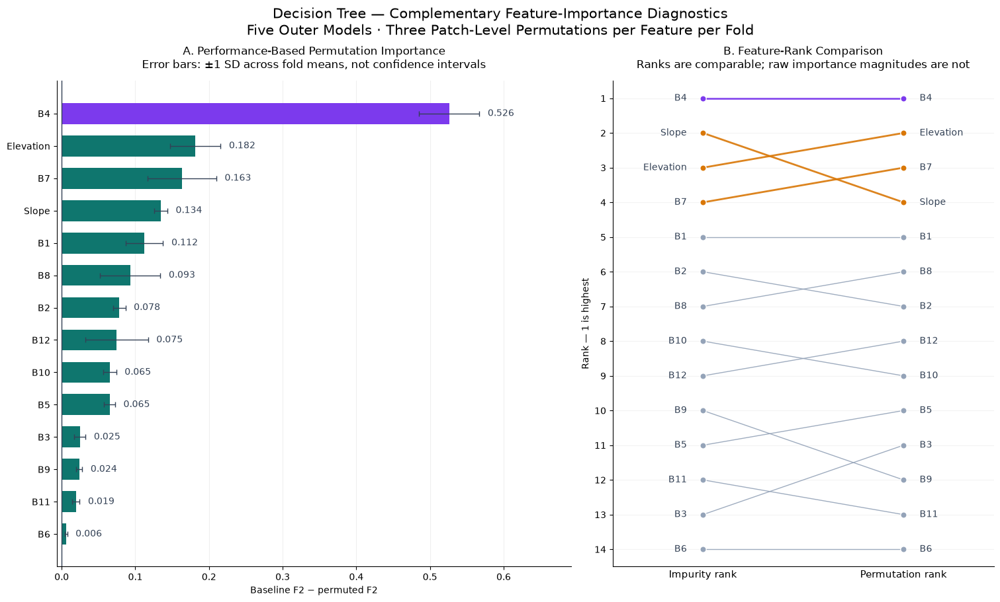

In [59]:
# ---------------------------------------------------------
# 1. Prepare feature rankings
# ---------------------------------------------------------
dt_importance_rank_comparison = pd.DataFrame({
    "Impurity importance":
        dt_impurity_importance_summary["Mean importance"],
    "Permutation F2 drop":
        dt_permutation_summary["mean_F2_drop"]
})

dt_importance_rank_comparison["Impurity rank"] = (
    dt_importance_rank_comparison["Impurity importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

dt_importance_rank_comparison["Permutation rank"] = (
    dt_importance_rank_comparison["Permutation F2 drop"]
    .rank(ascending=False, method="min")
    .astype(int)
)

dt_importance_rank_comparison = (
    dt_importance_rank_comparison
    .sort_values("Permutation rank")
)

print("FEATURE IMPORTANCE AND RANK COMPARISON")
display(dt_importance_rank_comparison.round(6))


# ---------------------------------------------------------
# 2. Two complementary plots
# ---------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.35, 1]},
    constrained_layout=True
)

# PANEL A: Actual F2 decrease
ax = axes[0]

plot_table = dt_permutation_summary.copy()
positions = np.arange(len(plot_table))

means = plot_table["mean_F2_drop"].to_numpy()
fold_sd = plot_table["SD_across_fold_means"].to_numpy()

ax.barh(
    positions,
    means,
    xerr=fold_sd,
    color=[
        "#7C3AED" if feature == "B4" else "#0F766E"
        for feature in plot_table.index
    ],
    height=0.65,
    capsize=3,
    error_kw={"ecolor": "#334155", "elinewidth": 1}
)

extent = means + fold_sd
padding = max(float(extent.max()) * 0.02, 0.001)

for position, mean, upper in zip(positions, means, extent):
    ax.text(
        upper + padding,
        position,
        f"{mean:.3f}",
        va="center",
        fontsize=10,
        color="#334155"
    )

ax.set_yticks(positions, plot_table.index)
ax.invert_yaxis()
ax.axvline(0, color="#334155", linewidth=1)

ax.set_xlim(
    min(0, float((means - fold_sd).min()) - padding),
    max(float(extent.max()) * 1.22, 0.05)
)

ax.set_xlabel("Baseline F2 − permuted F2")
ax.set_title(
    "A. Performance-Based Permutation Importance\n"
    "Error bars: ±1 SD across fold means, not confidence intervals",
    fontsize=12,
    pad=14
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)


# PANEL B: Rank changes, without mixing importance scales
ax = axes[1]

number_of_features = len(dt_importance_rank_comparison)

for feature, row in dt_importance_rank_comparison.iterrows():
    left_rank = row["Impurity rank"]
    right_rank = row["Permutation rank"]

    color = (
        "#7C3AED" if feature == "B4"
        else "#D97706" if feature in ["Elevation", "B7", "Slope"]
        else "#94A3B8"
    )

    ax.plot(
        [0, 1],
        [left_rank, right_rank],
        color=color,
        linewidth=2 if feature in ["B4", "Elevation", "B7", "Slope"] else 1,
        alpha=0.9
    )

    ax.scatter(
        [0, 1],
        [left_rank, right_rank],
        color=color,
        s=45,
        edgecolors="white",
        zorder=3
    )

    ax.text(
        -0.08,
        left_rank,
        feature,
        ha="right",
        va="center",
        fontsize=10,
        color="#334155"
    )

    ax.text(
        1.08,
        right_rank,
        feature,
        ha="left",
        va="center",
        fontsize=10,
        color="#334155"
    )

ax.set_xticks([0, 1], ["Impurity rank", "Permutation rank"])
ax.set_yticks(range(1, number_of_features + 1))
ax.set_ylim(number_of_features + 0.5, 0.5)
ax.set_xlim(-0.45, 1.45)
ax.set_ylabel("Rank — 1 is highest")
ax.set_title(
    "B. Feature-Rank Comparison\n"
    "Ranks are comparable; raw importance magnitudes are not",
    fontsize=12,
    pad=14
)
ax.grid(axis="y", alpha=0.15)
ax.tick_params(axis="x", length=0, labelsize=11)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Complementary Feature-Importance Diagnostics\n"
    "Five Outer Models · Three Patch-Level Permutations per Feature per Fold",
    fontsize=15
)

plt.show()

### Rationale — Comparing Complementary Importance Measures

The plots distinguish feature use during tree construction from performance sensitivity to feature permutation. Ranks are compared without treating the two importance magnitudes as equivalent.

### Result — Importance Agreement and Differences

B4 ranked first under both methods, while B1 remained fifth and B6 remained last.

Elevation moved from impurity rank 3 to permutation rank 2, B7 moved from 4 to 3, and Slope moved from 2 to 4. These differences reflect the distinct quantities measured by the two diagnostics.

Small rank differences should not be overinterpreted. For example, B10 and B5 had very similar mean F2 decreases, approximately 0.0654 and 0.0651.

Permutation error bars describe variation across fold means, not confidence intervals. Importance values are not independent causal contributions and do not automatically justify feature removal.

The figure is sufficient for this comparison. No feature removal or outer-model retuning follows from these diagnostics.

In [60]:
# Reuse the saved final-development CV splits
dt_final_inner_splits_saved = saved_variables["lr_final_inner_splits"]

print("Saved final-CV object type:",
      type(dt_final_inner_splits_saved).__name__)
print("Number of saved splits:", len(dt_final_inner_splits_saved))

first_final_split = dt_final_inner_splits_saved[0]

print("\nFIRST FINAL-CV SPLIT STRUCTURE")
print("Type:", type(first_final_split).__name__)

if isinstance(first_final_split, dict):
    for name, value in first_final_split.items():
        size = len(value) if hasattr(value, "__len__") else "N/A"
        print(f"{name}: {type(value).__name__}, length={size}")

required_keys = {"train_ids", "validation_ids"}

supported_structure = all(
    isinstance(split, dict)
    and required_keys.issubset(split)
    for split in dt_final_inner_splits_saved
)

if supported_structure:
    development_set = set(str(i) for i in dev_ids)
    holdout_set = set(str(i) for i in test_ids)

    dt_final_inner_splits = []
    dt_final_split_rows = []
    all_validation_ids = []

    for split_number, split in enumerate(
        dt_final_inner_splits_saved,
        start=1
    ):
        train_ids = np.asarray([
            str(i) for i in split["train_ids"]
        ])
        validation_ids = np.asarray([
            str(i) for i in split["validation_ids"]
        ])

        train_set = set(train_ids)
        validation_set = set(validation_ids)

        assert len(train_set) == len(train_ids)
        assert len(validation_set) == len(validation_ids)
        assert train_set.isdisjoint(validation_set)
        assert train_set | validation_set == development_set
        assert (train_set | validation_set).isdisjoint(holdout_set)

        dt_final_inner_splits.append({
            "train_ids": train_ids,
            "validation_ids": validation_ids
        })

        all_validation_ids.extend(validation_ids)

        dt_final_split_rows.append({
            "final_CV_split": split_number,
            "training_patches": len(train_ids),
            "validation_patches": len(validation_ids),
            "train_validation_overlap": len(
                train_set & validation_set
            ),
            "holdout_overlap": len(
                (train_set | validation_set) & holdout_set
            )
        })

    assert len(dt_final_inner_splits) == 3
    assert len(all_validation_ids) == len(dev_ids)
    assert set(all_validation_ids) == development_set

    dt_final_split_table = pd.DataFrame(dt_final_split_rows)

    print("\nFINAL-DEVELOPMENT CV CHECKS PASSED")
    display(dt_final_split_table)

    print("Every development patch is validated exactly once.")
    print("No models fitted. No holdout predictions computed.")

else:
    print(
        "\nThe saved structure differs from the expected ID dictionaries."
    )
    print("Inspect the structure above before proceeding.")

Saved final-CV object type: list
Number of saved splits: 3

FIRST FINAL-CV SPLIT STRUCTURE
Type: dict
train_ids: ndarray, length=2026
validation_ids: ndarray, length=1013

FINAL-DEVELOPMENT CV CHECKS PASSED


,final_CV_split,training_patches,validation_patches,train_validation_overlap,holdout_overlap
0,1,2026,1013,0,0
1,2,2026,1013,0,0
2,3,2026,1013,0,0


Every development patch is validated exactly once.
No models fitted. No holdout predictions computed.


### Rationale — Final-Development CV Preparation

The saved final-development splits were reused to select the final Decision Tree pipeline using development data only.

### Result — Final CV Splits Verified

Three splits were successfully restored. Each contains 2,026 training patches and 1,013 validation patches.

Training and validation patches have zero overlap within each split. Every development patch is validated exactly once, and all 760 holdout patches remain excluded.

These splits support final-model selection; they do not replace the completed five-fold outer assessment.

No models were fitted and no holdout predictions were computed. No additional visualization is needed for this check.

In [62]:
def get_sampled_pixels(patch_ids, pixels_per_patch=512):
    """Retrieve saved training samples using a local ID mapping."""
    if not 1 <= pixels_per_patch <= X_patch_samples.shape[1]:
        raise ValueError("Invalid number of pixels per patch.")

    # Local mapping: unaffected by variables used in plotting cells
    row_by_id = {
        str(patch_id): row
        for row, patch_id in enumerate(sampled_patch_ids)
    }

    requested_ids = [str(patch_id) for patch_id in patch_ids]

    missing_ids = [
        patch_id for patch_id in requested_ids
        if patch_id not in row_by_id
    ]

    if missing_ids:
        raise ValueError(
            f"Patch IDs missing from saved samples: {missing_ids[:10]}"
        )

    positions = np.asarray(
        [row_by_id[patch_id] for patch_id in requested_ids],
        dtype=int
    )

    X = X_patch_samples[
        positions, :pixels_per_patch, :
    ].reshape(-1, len(FEATURE_NAMES))

    y = y_patch_samples[
        positions, :pixels_per_patch
    ].reshape(-1)

    return X, y


# Small check using three existing development-training patches
check_ids = dt_final_inner_splits[0]["train_ids"][:3]

X_check, y_check = get_sampled_pixels(
    check_ids,
    pixels_per_patch=512
)

assert X_check.shape == (len(check_ids) * 512, len(FEATURE_NAMES))
assert y_check.shape == (len(check_ids) * 512,)

print("Sample retrieval check passed.")
print("X shape:", X_check.shape)
print("y shape:", y_check.shape)

del X_check, y_check

Sample retrieval check passed.
X shape: (1536, 14)
y shape: (1536,)


In [63]:
dt_final_search_signature = joblib.hash({
    "initial_protocol": dt_search_signature,
    "final_splits": dt_final_inner_splits,
    "candidates": dt_candidates,
    "pixels_per_patch": DT_PIXELS_PER_PATCH,
    "threshold": DT_BASELINE_THRESHOLD,
    "random_state": RANDOM_STATE,
    "beta": BETA
})

DT_FINAL_SELECTION_DIR = (
    DT_CHECKPOINT_DIR
    / "final_development"
    / dt_final_search_signature
)
DT_FINAL_SELECTION_DIR.mkdir(parents=True, exist_ok=True)


def run_dt_final_initial_search():
    split_results = []
    completed_split_seconds = []

    for split_number, split in enumerate(
        dt_final_inner_splits,
        start=1
    ):
        checkpoint_path = (
            DT_FINAL_SELECTION_DIR
            / f"initial_search_split_{split_number}.joblib"
        )

        print(
            f"\nFINAL-DEVELOPMENT SEARCH — SPLIT {split_number}/3",
            flush=True
        )

        if checkpoint_path.exists():
            completed = joblib.load(checkpoint_path)

            if (
                completed["signature"] != dt_final_search_signature
                or completed["split_number"] != split_number
            ):
                raise ValueError("Final-search checkpoint mismatch.")

            print("Loaded completed split.", flush=True)

        else:
            split_start = perf_counter()

            X_fit, y_fit = get_sampled_pixels(
                split["train_ids"],
                pixels_per_patch=DT_PIXELS_PER_PATCH
            )

            models = {}
            fit_times = {}
            depths = {}
            leaves = {}

            for candidate_id, params in enumerate(dt_candidates):
                model = DecisionTreeClassifier(
                    **params,
                    random_state=RANDOM_STATE
                )

                fit_start = perf_counter()
                model.fit(X_fit, y_fit)

                models[candidate_id] = model
                fit_times[candidate_id] = perf_counter() - fit_start
                depths[candidate_id] = model.get_depth()
                leaves[candidate_id] = model.get_n_leaves()

                print(
                    f"  Candidate {candidate_id:02d} fitted"
                    f" ({candidate_id + 1}/{len(dt_candidates)})"
                    f" | {fit_times[candidate_id]:.2f} s",
                    flush=True
                )

            print(
                "  Evaluating all pixels of validation patches...",
                flush=True
            )

            scores = evaluate_dt_candidates_full_patches(
                models=models,
                patch_ids=split["validation_ids"],
                threshold=DT_BASELINE_THRESHOLD
            )

            scores["final_CV_split"] = split_number
            scores["fit_seconds"] = scores["candidate_id"].map(fit_times)
            scores["tree_depth"] = scores["candidate_id"].map(depths)
            scores["n_leaves"] = scores["candidate_id"].map(leaves)

            completed = {
                "signature": dt_final_search_signature,
                "split_number": split_number,
                "scores": scores,
                "elapsed_seconds": perf_counter() - split_start
            }

            save_dt_pipeline_checkpoint(
                checkpoint_path, completed
            )

            del models, model, X_fit, y_fit
            print("Split completed and saved.", flush=True)

        split_results.append(completed["scores"])
        completed_split_seconds.append(completed["elapsed_seconds"])

    results = pd.concat(split_results, ignore_index=True)

    assert len(results) == len(dt_candidates) * 3
    assert not results.duplicated(
        ["candidate_id", "final_CV_split"]
    ).any()

    assert (
        results.groupby("candidate_id")["final_CV_split"]
        .nunique()
        .eq(3)
        .all()
    )
    assert np.isfinite(results["F2"]).all()

    ranking = (
        results
        .groupby("candidate_id", as_index=False)
        .agg(
            mean_inner_F2=("F2", "mean"),
            sd_inner_F2=("F2", "std"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_specificity=("specificity", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_fit_seconds=("fit_seconds", "mean")
        )
        .sort_values(
            ["mean_inner_F2", "candidate_id"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    best_id = int(ranking.iloc[0]["candidate_id"])

    return {
        "signature": dt_final_search_signature,
        "fold_results": results,
        "ranking": ranking,
        "best_candidate_id": best_id,
        "best_params": dict(dt_candidates[best_id]),
        "search_seconds": sum(completed_split_seconds)
    }


final_search_path = DT_FINAL_SELECTION_DIR / "initial_search_complete.joblib"

if final_search_path.exists():
    dt_final_initial_search = joblib.load(final_search_path)

    if (
        dt_final_initial_search["signature"]
        != dt_final_search_signature
    ):
        raise ValueError("Stored final search has different settings.")

    print("Loaded completed final-development initial search.")

else:
    dt_final_initial_search = run_dt_final_initial_search()

    save_dt_pipeline_checkpoint(
        final_search_path,
        dt_final_initial_search
    )

print("\nFINAL-DEVELOPMENT INITIAL SEARCH COMPLETED")
print(
    "Selected candidate:",
    dt_final_initial_search["best_candidate_id"]
)
print(
    "Selected parameters:",
    dt_final_initial_search["best_params"]
)
print(
    "Total completed split runtime:",
    f"{dt_final_initial_search['search_seconds'] / 60:.2f} minutes"
)

display(dt_final_initial_search["ranking"].round(6))

print("\nNo holdout predictions computed.")


FINAL-DEVELOPMENT SEARCH — SPLIT 1/3
  Candidate 00 fitted (1/25) | 7.40 s
  Candidate 01 fitted (2/25) | 7.50 s
  Candidate 02 fitted (3/25) | 3.85 s
  Candidate 03 fitted (4/25) | 7.51 s
  Candidate 04 fitted (5/25) | 6.38 s
  Candidate 05 fitted (6/25) | 7.67 s
  Candidate 06 fitted (7/25) | 7.32 s
  Candidate 07 fitted (8/25) | 4.13 s
  Candidate 08 fitted (9/25) | 9.59 s
  Candidate 09 fitted (10/25) | 7.42 s
  Candidate 10 fitted (11/25) | 9.75 s
  Candidate 11 fitted (12/25) | 3.79 s
  Candidate 12 fitted (13/25) | 3.83 s
  Candidate 13 fitted (14/25) | 10.54 s
  Candidate 14 fitted (15/25) | 4.02 s
  Candidate 15 fitted (16/25) | 7.16 s
  Candidate 16 fitted (17/25) | 6.65 s
  Candidate 17 fitted (18/25) | 7.09 s
  Candidate 18 fitted (19/25) | 6.15 s
  Candidate 19 fitted (20/25) | 6.77 s
  Candidate 20 fitted (21/25) | 3.75 s
  Candidate 21 fitted (22/25) | 10.21 s
  Candidate 22 fitted (23/25) | 6.61 s
  Candidate 23 fitted (24/25) | 10.37 s
  Candidate 24 fitted (25/25) | 

,candidate_id,mean_inner_F2,sd_inner_F2,mean_precision,mean_recall,mean_specificity,mean_IoU,mean_fit_seconds
0,3,0.683555,0.006852,0.362417,0.878679,0.962549,0.345050,7.554064
1,1,0.661330,0.005949,0.307736,0.928142,0.949446,0.300552,7.474105
2,6,0.643351,0.004332,0.283905,0.941429,0.942494,0.278969,7.356152
3,9,0.628269,0.007416,0.268020,0.946712,0.937328,0.264009,7.419596
4,0,0.627553,0.007462,0.717423,0.608606,0.994168,0.490745,7.335474
5,16,0.627529,0.009953,0.268329,0.943831,0.937644,0.264081,6.759960
6,15,0.626887,0.005335,0.265241,0.951253,0.936178,0.261677,7.322626
7,10,0.624615,0.002473,0.264781,0.946079,0.936395,0.260841,9.749981
8,4,0.614083,0.010920,0.726146,0.591295,0.994600,0.483473,6.616963
9,18,0.610313,0.016851,0.727382,0.586814,0.994678,0.480890,6.471448



No holdout predictions computed.


### Rationale — Final-Development Hyperparameter Search

The same 25 configurations were evaluated across the three saved final-development splits to select final-model hyperparameters without choosing an outer-fold model.

### Result — Initial Final-Development Search

Candidate 3 achieved the highest mean validation F2: 0.683555, with SD 0.006852.

Selected parameters:
max_depth=15, min_samples_leaf=5, min_samples_split=2, criterion="entropy", class_weight="balanced", and ccp_alpha=0.00001.

Mean precision was 0.362417, recall was 0.878679, and IoU was 0.345050. Baseline mean F2 was 0.627553, giving an absolute increase of approximately 0.0560.

The search used 512 sampled training pixels per patch and threshold 0.50. Total completed split runtime was 11.78 minutes.

These are selection-stage scores, not final performance estimates. Local refinement, sample-size and probability-method comparison, and threshold selection remain pending. No holdout predictions were computed.

### Visualization Decision

The complete ranking table is sufficient at this stage. A compact final-selection visualization can follow after the remaining selection steps.

In [64]:
dt_final_refinement_candidates, dt_final_refinement_changes = (
    make_dt_simplification_candidates(
        dt_final_initial_search["best_params"]
    )
)

dt_final_refinement_signature = joblib.hash({
    "final_search_signature": dt_final_search_signature,
    "candidates": dt_final_refinement_candidates,
    "selection": "maximum_mean_F2_then_fewer_mean_leaves_then_local_id"
})


def run_dt_final_local_refinement():
    reference = dt_final_initial_search["fold_results"].loc[
        lambda table:
            table["candidate_id"]
            == dt_final_initial_search["best_candidate_id"]
    ].copy()

    assert len(reference) == 3

    reference["candidate_id"] = 0
    reference["reused_from_initial_search"] = True

    frames = [reference]

    for split_number, split in enumerate(
        dt_final_inner_splits,
        start=1
    ):
        path = (
            DT_FINAL_SELECTION_DIR
            / f"local_refinement_split_{split_number}.joblib"
        )

        print(
            f"\nFINAL LOCAL REFINEMENT — SPLIT {split_number}/3",
            flush=True
        )

        if path.exists():
            completed = joblib.load(path)

            if (
                completed["signature"] != dt_final_refinement_signature
                or completed["split_number"] != split_number
            ):
                raise ValueError("Final-refinement checkpoint mismatch.")

            print("Loaded completed split.", flush=True)

        else:
            X_fit, y_fit = get_sampled_pixels(
                split["train_ids"],
                pixels_per_patch=DT_PIXELS_PER_PATCH
            )

            models = {}
            depths = {}
            leaves = {}

            for local_id, params in enumerate(
                dt_final_refinement_candidates[1:],
                start=1
            ):
                model = DecisionTreeClassifier(
                    **params,
                    random_state=RANDOM_STATE
                )
                model.fit(X_fit, y_fit)

                models[local_id] = model
                depths[local_id] = model.get_depth()
                leaves[local_id] = model.get_n_leaves()

                print(
                    f"  Local candidate {local_id}/"
                    f"{len(dt_final_refinement_candidates) - 1} fitted.",
                    flush=True
                )

            print("  Evaluating full validation patches...", flush=True)

            scores = evaluate_dt_candidates_full_patches(
                models=models,
                patch_ids=split["validation_ids"],
                threshold=DT_BASELINE_THRESHOLD
            )

            scores["final_CV_split"] = split_number
            scores["tree_depth"] = scores["candidate_id"].map(depths)
            scores["n_leaves"] = scores["candidate_id"].map(leaves)
            scores["reused_from_initial_search"] = False

            completed = {
                "signature": dt_final_refinement_signature,
                "split_number": split_number,
                "scores": scores
            }

            save_dt_pipeline_checkpoint(path, completed)

            del models, model, X_fit, y_fit
            print("Split completed and saved.", flush=True)

        frames.append(completed["scores"])

    results = (
        pd.concat(frames, ignore_index=True)
        .rename(columns={"candidate_id": "local_candidate_id"})
    )

    assert len(results) == len(dt_final_refinement_candidates) * 3
    assert not results.duplicated(
        ["local_candidate_id", "final_CV_split"]
    ).any()

    assert (
        results.groupby("local_candidate_id")["final_CV_split"]
        .nunique()
        .eq(3)
        .all()
    )
    assert np.isfinite(results["F2"]).all()

    ranking = (
        results.groupby("local_candidate_id", as_index=False)
        .agg(
            mean_F2=("F2", "mean"),
            sd_F2=("F2", "std"),
            mean_precision=("precision", "mean"),
            mean_recall=("recall", "mean"),
            mean_IoU=("IoU", "mean"),
            mean_depth=("tree_depth", "mean"),
            mean_leaves=("n_leaves", "mean")
        )
    )

    ranking["change"] = ranking["local_candidate_id"].map(
        dict(enumerate(dt_final_refinement_changes))
    )

    reference_f2 = float(
        ranking.loc[
            ranking["local_candidate_id"] == 0, "mean_F2"
        ].iloc[0]
    )

    ranking["F2_difference_from_reference"] = (
        ranking["mean_F2"] - reference_f2
    )

    ranking = ranking.sort_values(
        ["mean_F2", "mean_leaves", "local_candidate_id"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    selected_id = int(ranking.iloc[0]["local_candidate_id"])

    return {
        "signature": dt_final_refinement_signature,
        "fold_results": results,
        "ranking": ranking,
        "selected_local_id": selected_id,
        "selected_params": dict(
            dt_final_refinement_candidates[selected_id]
        )
    }


final_refinement_path = (
    DT_FINAL_SELECTION_DIR / "local_refinement_complete.joblib"
)

if final_refinement_path.exists():
    dt_final_refinement_result = joblib.load(final_refinement_path)

    if (
        dt_final_refinement_result["signature"]
        != dt_final_refinement_signature
    ):
        raise ValueError("Stored refinement uses different settings.")

    print("Loaded completed final local refinement.")

else:
    dt_final_refinement_result = run_dt_final_local_refinement()

    save_dt_pipeline_checkpoint(
        final_refinement_path,
        dt_final_refinement_result
    )

print("\nFINAL LOCAL REFINEMENT COMPLETED")
print(
    "Selected local candidate:",
    dt_final_refinement_result["selected_local_id"]
)
print(
    "Selected parameters:",
    dt_final_refinement_result["selected_params"]
)

display(dt_final_refinement_result["ranking"].round(6))

print("\nNo holdout predictions computed.")


FINAL LOCAL REFINEMENT — SPLIT 1/3
  Local candidate 1/6 fitted.
  Local candidate 2/6 fitted.
  Local candidate 3/6 fitted.
  Local candidate 4/6 fitted.
  Local candidate 5/6 fitted.
  Local candidate 6/6 fitted.
  Evaluating full validation patches...
Split completed and saved.

FINAL LOCAL REFINEMENT — SPLIT 2/3
  Local candidate 1/6 fitted.
  Local candidate 2/6 fitted.
  Local candidate 3/6 fitted.
  Local candidate 4/6 fitted.
  Local candidate 5/6 fitted.
  Local candidate 6/6 fitted.
  Evaluating full validation patches...
Split completed and saved.

FINAL LOCAL REFINEMENT — SPLIT 3/3
  Local candidate 1/6 fitted.
  Local candidate 2/6 fitted.
  Local candidate 3/6 fitted.
  Local candidate 4/6 fitted.
  Local candidate 5/6 fitted.
  Local candidate 6/6 fitted.
  Evaluating full validation patches...
Split completed and saved.

FINAL LOCAL REFINEMENT COMPLETED
Selected local candidate: 0
Selected parameters: {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 15, 'cr

,local_candidate_id,mean_F2,sd_F2,mean_precision,mean_recall,mean_IoU,mean_depth,mean_leaves,change,F2_difference_from_reference
0,0,0.683555,0.006852,0.362417,0.878679,0.345050,15.000000,2196.000000,Reference — current selected parameters,0.000000
1,3,0.683170,0.007746,0.353801,0.890942,0.339046,15.000000,1983.000000,min_samples_leaf → 10,-0.000386
2,4,0.674438,0.007499,0.331463,0.910286,0.320925,15.000000,1744.666667,min_samples_leaf → 20,-0.009117
3,1,0.653886,0.009053,0.300996,0.925619,0.293843,12.000000,1132.666667,max_depth → 12,-0.029670
4,5,0.627949,0.004569,0.266280,0.950935,0.262665,15.000000,469.333333,ccp_alpha → 0.0001,-0.055607
5,2,0.612679,0.005543,0.253818,0.947847,0.250312,9.000000,363.000000,max_depth → 9,-0.070876
6,6,0.554232,0.019222,0.208667,0.947703,0.206261,8.333333,44.666667,ccp_alpha → 0.001,-0.129323



No holdout predictions computed.


### Rationale — Final-Development Local Refinement

Six simpler alternatives were compared with the initial winner to examine whether stronger complexity control improved validation performance on the final-development splits.

### Result — Reference Parameters Retained

The reference retained the highest mean F2: 0.683555, with mean tree size of 2,196 leaves.

Increasing minimum leaf size to 10 reduced mean leaf count to 1,983, approximately 9.7% fewer leaves, while reducing F2 by only approximately 0.00039. The predefined maximum-mean-F2 rule nevertheless retained the reference.

Stronger simplification produced larger F2 reductions. These comparisons used 512 training pixels per patch and threshold 0.50; they do not establish that every simpler model would be inferior after separate threshold optimization.

Selected parameters remain max_depth=15, min_samples_leaf=5, min_samples_split=2, criterion="entropy", class_weight="balanced", and ccp_alpha=0.00001.

No holdout predictions were computed. Sample size, probability method, and final threshold remain to be selected.

### Visualization Decision

The seven-configuration table is sufficient. No additional local-refinement plot is needed.

In [65]:
dt_final_calibration_splits = []
dt_final_calibration_split_rows = []

development_set = set(str(i) for i in dev_ids)
holdout_set = set(str(i) for i in test_ids)

for split_number, split in enumerate(
    dt_final_inner_splits,
    start=1
):
    train_ids = np.asarray([
        str(i) for i in split["train_ids"]
    ])
    validation_ids = np.asarray([
        str(i) for i in split["validation_ids"]
    ])

    presence = dt_presence_by_id.reindex(train_ids)

    if presence.isna().any():
        raise ValueError("Missing patch-presence information.")

    if not np.isfinite(
        presence.to_numpy(dtype=float)
    ).all():
        raise ValueError("Invalid patch-presence values.")

    strata = (presence.to_numpy() > 0).astype(int)

    _, stratum_counts = np.unique(
        strata,
        return_counts=True
    )

    if stratum_counts.min() < 2:
        raise ValueError("Too few patches for stratified splitting.")

    fit_ids, calibration_ids = train_test_split(
        train_ids,
        test_size=CALIBRATION_FRACTION,
        random_state=RANDOM_STATE,
        stratify=strata
    )

    fit_set = set(fit_ids)
    calibration_set = set(calibration_ids)
    validation_set = set(validation_ids)

    assert fit_set.isdisjoint(calibration_set)
    assert fit_set.isdisjoint(validation_set)
    assert calibration_set.isdisjoint(validation_set)

    assert fit_set | calibration_set == set(train_ids)
    assert (
        fit_set | calibration_set | validation_set
    ) == development_set

    assert (
        fit_set | calibration_set | validation_set
    ).isdisjoint(holdout_set)

    # Same structure as the existing probability-fitting helper expects
    dt_final_calibration_splits.append({
        "inner_fold": split_number,
        "train_ids": train_ids,
        "fit_ids": fit_ids,
        "calibration_ids": calibration_ids,
        "validation_ids": validation_ids
    })

    dt_final_calibration_split_rows.append({
        "final_CV_split": split_number,
        "all_training_patches": len(train_ids),
        "tree_fitting_patches": len(fit_ids),
        "calibration_patches": len(calibration_ids),
        "validation_patches": len(validation_ids),
        "fit_calibration_overlap": len(
            fit_set & calibration_set
        ),
        "holdout_overlap": len(
            (fit_set | calibration_set | validation_set)
            & holdout_set
        )
    })

dt_final_calibration_split_table = pd.DataFrame(
    dt_final_calibration_split_rows
)

print("FINAL-DEVELOPMENT CALIBRATION SPLITS")
print("Calibration fraction:", CALIBRATION_FRACTION)

display(dt_final_calibration_split_table)

print("No models fitted. No holdout predictions computed.")

FINAL-DEVELOPMENT CALIBRATION SPLITS
Calibration fraction: 0.2


,final_CV_split,all_training_patches,tree_fitting_patches,calibration_patches,validation_patches,fit_calibration_overlap,holdout_overlap
0,1,2026,1620,406,1013,0,0
1,2,2026,1620,406,1013,0,0
2,3,2026,1620,406,1013,0,0


No models fitted. No holdout predictions computed.


### Rationale — Final-Development Calibration Separation

Separate fitting and calibration patches were prepared to compare probability methods without fitting the tree and calibrator on the same images.

### Result — Calibration Splits Verified

Each of the three final-development splits contains:

- 2,026 total training patches.
- 1,620 calibration-base tree-fitting patches.
- 406 calibration patches.
- 1,013 validation patches.

The saved calibration fraction was 20%. Tree-fitting and calibration subsets have zero overlap, and all holdout patches remain excluded.

The uncalibrated alternative will use all 2,026 training patches in each split. No models were fitted or holdout predictions computed by this preparation cell.

### Visualization Decision

The split-size and overlap table is sufficient; no additional plot is needed.

In [66]:
dt_final_pipeline_signature = joblib.hash({
    "final_refinement_signature": dt_final_refinement_signature,
    "selected_params": dt_final_refinement_result["selected_params"],
    "calibration_splits": dt_final_calibration_splits,
    "sample_sizes": [512, 1024],
    "methods": DT_SELECTION_METHODS,
    "thresholds": dt_threshold_grid,
    "fixed_diagnostic_threshold": DT_BASELINE_THRESHOLD,
    "sigmoid_C": PLATT_C,
    "sigmoid_input": "raw_tree_probability",
    "sigmoid_solver": "lbfgs",
    "sigmoid_max_iter": 1000,
    "random_state": RANDOM_STATE,
    "beta": BETA,
    "tie_rule": "smaller_sample_then_method_order_then_higher_threshold"
})

DT_FINAL_PIPELINE_DIR = (
    DT_FINAL_SELECTION_DIR
    / "pipeline_selection"
    / dt_final_pipeline_signature
)
DT_FINAL_PIPELINE_DIR.mkdir(parents=True, exist_ok=True)


def run_dt_final_pipeline_selection():
    fit_rows = []
    probability_frames = []
    threshold_frames = []

    for pixels_per_patch in [512, 1024]:
        for split in dt_final_calibration_splits:
            split_number = split["inner_fold"]

            print(
                f"\nFINAL SELECTION | {pixels_per_patch} pixels/patch"
                f" | Split {split_number}/3",
                flush=True
            )

            path = (
                DT_FINAL_PIPELINE_DIR
                / f"pixels_{pixels_per_patch}_split_{split_number}.joblib"
            )

            if path.exists():
                completed = joblib.load(path)

                if (
                    completed["signature"] != dt_final_pipeline_signature
                    or completed["split_number"] != split_number
                    or completed["pixels_per_patch"] != pixels_per_patch
                ):
                    raise ValueError("Final pipeline checkpoint mismatch.")

                print("Loaded completed task.", flush=True)

            else:
                options = fit_dt_probability_options_for_sample_size(
                    split=split,
                    params=dt_final_refinement_result["selected_params"],
                    pixels_per_patch=pixels_per_patch
                )

                print(
                    "Evaluating probability quality and fixed threshold...",
                    flush=True
                )

                probability_scores = evaluate_dt_probability_options(
                    options=options,
                    patch_ids=split["validation_ids"],
                    threshold=DT_BASELINE_THRESHOLD
                )

                print("Evaluating threshold grid...", flush=True)

                threshold_scores = evaluate_dt_threshold_grid(
                    options=options,
                    patch_ids=split["validation_ids"],
                    thresholds=dt_threshold_grid
                )

                completed = {
                    "signature": dt_final_pipeline_signature,
                    "split_number": split_number,
                    "pixels_per_patch": pixels_per_patch,
                    "fit_summary": options["summary"],
                    "probability_scores": probability_scores,
                    "threshold_scores": threshold_scores
                }

                save_dt_pipeline_checkpoint(path, completed)
                del options

                print("Task completed and saved.", flush=True)

            fit_rows.append(completed["fit_summary"])

            probability_frames.append(
                completed["probability_scores"]
                .reset_index()
                .assign(
                    final_CV_split=split_number,
                    pixels_per_patch=pixels_per_patch
                )
            )

            threshold_frames.append(
                completed["threshold_scores"].assign(
                    final_CV_split=split_number,
                    pixels_per_patch=pixels_per_patch
                )
            )

    probability_results = pd.concat(
        probability_frames, ignore_index=True
    )
    threshold_results = pd.concat(
        threshold_frames, ignore_index=True
    )

    assert len(probability_results) == 24
    assert not probability_results.duplicated(
        ["pixels_per_patch", "final_CV_split", "Method"]
    ).any()

    assert not threshold_results.duplicated(
        ["pixels_per_patch", "final_CV_split", "Method", "Threshold"]
    ).any()

    assert (
        threshold_results
        .groupby(["pixels_per_patch", "Method", "Threshold"])["final_CV_split"]
        .nunique()
        .eq(3)
        .all()
    )
    assert np.isfinite(threshold_results["F2"]).all()

    probability_summary = (
        probability_results
        .assign(
            precision_zero_convention=lambda table:
                table["Precision"].fillna(0.0)
        )
        .groupby(["pixels_per_patch", "Method"], sort=False)
        .agg(
            mean_F2=("F2", "mean"),
            mean_precision_zero_convention=(
                "precision_zero_convention", "mean"
            ),
            folds_with_defined_precision=("Precision", "count"),
            mean_recall=("Recall", "mean"),
            mean_Brier=("Brier", "mean"),
            mean_log_loss=("Log loss", "mean")
        )
    )

    threshold_summary = (
        threshold_results
        .groupby(
            ["pixels_per_patch", "Method", "Threshold"],
            as_index=False
        )
        .agg(
            mean_F2=("F2", "mean"),
            sd_F2=("F2", "std"),
            mean_precision=("Precision", "mean"),
            mean_recall=("Recall", "mean"),
            mean_specificity=("Specificity", "mean"),
            mean_IoU=("IoU", "mean")
        )
    )

    ranking = (
        threshold_summary
        .assign(
            method_priority=lambda table:
                table["Method"].map(method_priority)
        )
        .sort_values(
            [
                "mean_F2", "pixels_per_patch",
                "method_priority", "Threshold"
            ],
            ascending=[False, True, True, False]
        )
        .reset_index(drop=True)
    )

    return {
        "signature": dt_final_pipeline_signature,
        "fit_summary": pd.DataFrame(fit_rows),
        "probability_fold_results": probability_results,
        "probability_summary": probability_summary,
        "threshold_fold_results": threshold_results,
        "threshold_summary": threshold_summary,
        "ranking": ranking,
        "selected": ranking.iloc[0].to_dict()
    }


final_pipeline_path = (
    DT_FINAL_PIPELINE_DIR / "complete_selection.joblib"
)

if final_pipeline_path.exists():
    dt_final_pipeline_result = joblib.load(final_pipeline_path)

    if (
        dt_final_pipeline_result["signature"]
        != dt_final_pipeline_signature
    ):
        raise ValueError("Stored final pipeline uses different settings.")

    print("Loaded completed final pipeline selection.")

else:
    dt_final_pipeline_result = run_dt_final_pipeline_selection()

    save_dt_pipeline_checkpoint(
        final_pipeline_path,
        dt_final_pipeline_result
    )

print("\nCALIBRATOR FITTING DETAILS")
display(
    dt_final_pipeline_result["fit_summary"][
        [
            "pixels_per_patch", "inner_fold",
            "calibration_pixels",
            "sigmoid_iterations", "sigmoid_p_at_raw_1",
            "isotonic_mapping_points", "isotonic_p_at_raw_1"
        ]
    ].round(6)
)

print("\nMEAN RESULTS AT FIXED THRESHOLD 0.50")
display(dt_final_pipeline_result["probability_summary"].round(6))

print("\nBEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD")
display(
    dt_final_pipeline_result["ranking"]
    .drop_duplicates(["pixels_per_patch", "Method"])
    .drop(columns="method_priority")
    .round(6)
)

print("\nSELECTED FINAL PIPELINE")
display(
    dt_final_pipeline_result["ranking"]
    .head(1)
    .drop(columns="method_priority")
    .round(6)
)

print("\nNo holdout predictions computed.")


FINAL SELECTION | 512 pixels/patch | Split 1/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
Evaluating probability quality and fixed threshold...
Evaluating threshold grid...
Task completed and saved.

FINAL SELECTION | 512 pixels/patch | Split 2/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
Evaluating probability quality and fixed threshold...
Evaluating threshold grid...
Task completed and saved.

FINAL SELECTION | 512 pixels/patch | Split 3/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
Evaluating probability quality and fixed threshold...
Evaluating threshold grid...
Task completed and saved.

FINAL SELECTION | 1024 pixels/patch | Split 1/3
  Uncalibrated tree fitted.
  Calibration-base tree fitted.
  Sigmoid calibrator fitted.
  Isotonic calibrator fitted.
Eval

,pixels_per_patch,inner_fold,calibration_pixels,sigmoid_iterations,sigmoid_p_at_raw_1,isotonic_mapping_points,isotonic_p_at_raw_1
0,512,1,6651904,12,0.491046,84,0.920848
1,512,2,6651904,12,0.487523,67,0.935121
2,512,3,6651904,12,0.489811,70,0.913160
3,1024,1,6651904,12,0.490727,98,0.943065
4,1024,2,6651904,12,0.487340,86,0.971196
5,1024,3,6651904,12,0.492471,109,0.965102



MEAN RESULTS AT FIXED THRESHOLD 0.50


mean_F2  \
pixels_per_patch Method                                             
512              Uncalibrated — all training patches     0.683555   
                 Raw calibration-base tree — diagnostic  0.684267   
                 Sigmoid                                 0.000000   
                 Isotonic                                0.569717   
1024             Uncalibrated — all training patches     0.680123   
                 Raw calibration-base tree — diagnostic  0.680272   
                 Sigmoid                                 0.000000   
                 Isotonic                                0.596569   

                                                         mean_precision_zero_convention  \
pixels_per_patch Method                                                                   
512              Uncalibrated — all training patches                           0.362417   
                 Raw calibration-base tree — diagnostic                        0.373424   
                 Sigmoid                                                       0.000000   
                 Isotonic                                                      0.756990   
1024             Uncalibrated — all training patches                           0.338390   
                 Raw calibration-base tree — diagnostic                        0.345904   
                 Sigmoid                                                       0.000000   
                 Isotonic                                                      0.758727   

                                                         folds_with_defined_precision  \
pixels_per_patch Method                                                                 
512              Uncalibrated — all training patches                                3   
                 Raw calibration-base tree — diagnostic                             3   
                 Sigmoid                                                            0   
                 Isotonic                                                           3   
1024             Uncalibrated — all training patches                                3   
                 Raw calibration-base tree — diagnostic                             3   
                 Sigmoid                                                            0   
                 Isotonic                                                           3   

                                                         mean_recall  \
pixels_per_patch Method                                                
512              Uncalibrated — all training patches        0.878679   
                 Raw calibration-base tree — diagnostic     0.864477   
                 Sigmoid                                    0.000000   
                 Isotonic                                   0.536688   
1024             Uncalibrated — all training patches        0.910183   
                 Raw calibration-base tree — diagnostic     0.897361   
                 Sigmoid                                    0.000000   
                 Isotonic                                   0.566628   

                                                         mean_Brier  \
pixels_per_patch Method                                               
512              Uncalibrated — all training patches       0.031915   
                 Raw calibration-base tree — diagnostic    0.031096   
                 Sigmoid                                   0.014002   
                 Isotonic                                  0.011489   
1024             Uncalibrated — all training patches       0.034550   
                 Raw calibration-base tree — diagnostic    0.033803   
                 Sigmoid                                   0.013680   
                 Isotonic                                  0.011052   

                                                         mean_log_loss  
pixels_per_patch Method                                     


BEST THRESHOLD FOR EACH SAMPLE SIZE AND METHOD


,pixels_per_patch,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,1024,Uncalibrated — all training patches,0.92,0.733712,0.004934,0.533248,0.810134,0.982750,0.473853
6,1024,Isotonic,0.17,0.730348,0.006796,0.524439,0.809939,0.982171,0.466965
10,1024,Sigmoid,0.36,0.730021,0.006511,0.516859,0.814028,0.981532,0.462272
38,512,Uncalibrated — all training patches,0.90,0.719861,0.004895,0.484349,0.819516,0.978871,0.437648
58,512,Isotonic,0.16,0.715034,0.006337,0.510450,0.794792,0.981490,0.450974
61,512,Sigmoid,0.35,0.714610,0.005795,0.481814,0.812879,0.978783,0.433702



SELECTED FINAL PIPELINE


,pixels_per_patch,Method,Threshold,mean_F2,sd_F2,mean_precision,mean_recall,mean_specificity,mean_IoU
0,1024,Uncalibrated — all training patches,0.92,0.733712,0.004934,0.533248,0.810134,0.98275,0.473853



No holdout predictions computed.


### Rationale — Final Pipeline Selection

Sample size, probability method, and threshold were compared across the three final-development splits before holdout evaluation.

### Result — Selected Final Pipeline

The selected pipeline uses 1,024 sampled training pixels per patch, uncalibrated probabilities, and threshold 0.92.

Its mean validation metrics were:
- F2: 0.733712; SD: 0.004934.
- Precision: 0.533248.
- Recall: 0.810134.
- Specificity: 0.982750.
- IoU: 0.473853.

The corresponding 1,024-pixel isotonic and sigmoid pipelines achieved tuned F2 values of 0.730348 and 0.730021. These small differences do not establish statistical superiority.

Isotonic achieved the best probability scores: mean Brier = 0.011052 and mean log loss = 0.043768. Nevertheless, selection followed the predefined F2 objective.

Sigmoid produced no positive predictions at threshold 0.50, but performed substantially better at its selected threshold of 0.36.

Tree hyperparameters remain unchanged. These are selection-stage scores, not final-model or holdout performance. No holdout predictions were computed.

### Visualization Decision

A compact comparison of the six tuned alternatives and threshold-sensitivity curves is sufficient to document final selection.

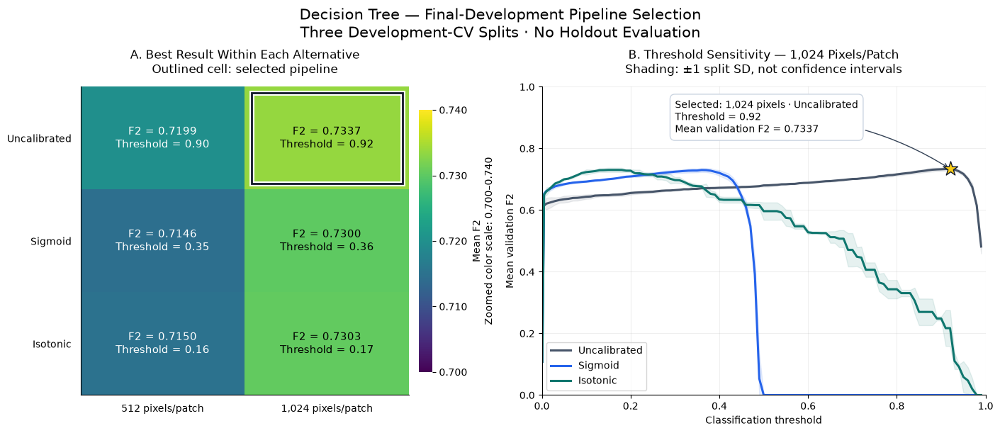

In [67]:
final_result = dt_final_pipeline_result
final_selected = final_result["selected"]

dt_final_best_alternatives = (
    final_result["ranking"]
    .drop_duplicates(["pixels_per_patch", "Method"])
    .copy()
)

method_order = DT_SELECTION_METHODS
sample_order = [512, 1024]

f2_matrix = (
    dt_final_best_alternatives
    .pivot(
        index="Method",
        columns="pixels_per_patch",
        values="mean_F2"
    )
    .reindex(index=method_order, columns=sample_order)
)

threshold_matrix = (
    dt_final_best_alternatives
    .pivot(
        index="Method",
        columns="pixels_per_patch",
        values="Threshold"
    )
    .reindex(index=method_order, columns=sample_order)
)

assert np.isfinite(f2_matrix.to_numpy()).all()
assert np.isfinite(threshold_matrix.to_numpy()).all()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1, 1.35]},
    constrained_layout=True
)

# ---------------------------------------------------------
# A. Six alternatives with their individually tuned thresholds
# ---------------------------------------------------------
ax = axes[0]

cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=0.70, vmax=0.74)

heatmap = ax.imshow(
    f2_matrix.to_numpy(),
    cmap=cmap,
    norm=norm,
    aspect="auto"
)

for row in range(3):
    for column in range(2):
        value = f2_matrix.iloc[row, column]
        threshold = threshold_matrix.iloc[row, column]

        red, green, blue, _ = cmap(norm(value))
        brightness = 0.2126 * red + 0.7152 * green + 0.0722 * blue

        ax.text(
            column, row,
            f"F2 = {value:.4f}\nThreshold = {threshold:.2f}",
            ha="center",
            va="center",
            fontsize=11,
            color="black" if brightness > 0.55 else "white"
        )

selected_row = method_order.index(final_selected["Method"])
selected_column = sample_order.index(
    int(final_selected["pixels_per_patch"])
)

for color, width in [("white", 5), ("#111827", 2)]:
    ax.add_patch(Rectangle(
        (selected_column - 0.46, selected_row - 0.44),
        0.92, 0.88,
        fill=False,
        edgecolor=color,
        linewidth=width
    ))

ax.set_xticks([0, 1], ["512 pixels/patch", "1,024 pixels/patch"])
ax.set_yticks([0, 1, 2], ["Uncalibrated", "Sigmoid", "Isotonic"])
ax.tick_params(length=0, pad=9)
ax.set_title(
    "A. Best Result Within Each Alternative\n"
    "Outlined cell: selected pipeline",
    fontsize=12,
    pad=14
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    pad=0.03,
    shrink=0.85,
    ticks=[0.700, 0.710, 0.720, 0.730, 0.740]
)
colorbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)
colorbar.outline.set_visible(False)
colorbar.set_label(
    "Mean F2\nZoomed color scale: 0.700–0.740",
    fontsize=10
)


# ---------------------------------------------------------
# B. Threshold sensitivity for the 1,024-pixel alternatives
# ---------------------------------------------------------
ax = axes[1]

for method, label, color in zip(
    method_order,
    ["Uncalibrated", "Sigmoid", "Isotonic"],
    ["#475569", "#2563EB", "#0F766E"]
):
    curve = (
        final_result["threshold_summary"].loc[
            (final_result["threshold_summary"]["pixels_per_patch"] == 1024)
            & (final_result["threshold_summary"]["Method"] == method)
        ]
        .sort_values("Threshold")
    )

    thresholds = curve["Threshold"].to_numpy()
    means = curve["mean_F2"].to_numpy()
    deviations = curve["sd_F2"].to_numpy()

    ax.plot(
        thresholds, means,
        color=color,
        linewidth=2.2,
        label=label
    )
    ax.fill_between(
        thresholds,
        np.clip(means - deviations, 0, 1),
        np.clip(means + deviations, 0, 1),
        color=color,
        alpha=0.10
    )

ax.scatter(
    final_selected["Threshold"],
    final_selected["mean_F2"],
    marker="*",
    s=230,
    color="#FACC15",
    edgecolors="#111827",
    zorder=5
)

ax.annotate(
    f"Selected: 1,024 pixels · Uncalibrated\n"
    f"Threshold = {final_selected['Threshold']:.2f}\n"
    f"Mean validation F2 = {final_selected['mean_F2']:.4f}",
    xy=(
        final_selected["Threshold"],
        final_selected["mean_F2"]
    ),
    xytext=(0.30, 0.96),
    textcoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#CBD5E1"
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#334155",
        connectionstyle="arc3,rad=-0.15"
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Mean validation F2")
ax.set_title(
    "B. Threshold Sensitivity — 1,024 Pixels/Patch\n"
    "Shading: ±1 split SD, not confidence intervals",
    fontsize=12,
    pad=14
)
ax.legend(loc="lower left", fontsize=10)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Decision Tree — Final-Development Pipeline Selection\n"
    "Three Development-CV Splits · No Holdout Evaluation",
    fontsize=15
)

plt.show()

### Rationale — Final-Selection Visualization

The figure documents the six tuned alternatives and threshold sensitivity for the 1,024-pixel pipelines.

### Result — Final Selection Confirmed

The selected pipeline uses 1,024 pixels per training patch, uncalibrated probabilities, and threshold 0.92. Mean validation F2 was 0.733712.

This exceeded the corresponding 512-pixel pipeline by approximately 0.0139. Isotonic and sigmoid achieved nearby tuned scores of 0.730348 and 0.730021; these differences do not establish statistical superiority.

The uncalibrated curve is relatively flat near its selected threshold, followed by a decline toward the upper end of the tested range.

The zoomed heatmap colors and descriptive SD bands do not represent significance tests. These remain development-selection results, not final-model holdout performance.

No additional selection plot is required.

In [68]:
import sklearn

selected = dt_final_pipeline_result["selected"]

dt_final_locked_specification = {
    "pixels_per_patch": int(selected["pixels_per_patch"]),
    "probability_method": selected["Method"],
    "threshold": float(selected["Threshold"]),
    "feature_names": list(FEATURE_NAMES),
    "positive_class": 1,
    "beta": BETA,
    "model_params": {
        **dt_final_refinement_result["selected_params"],
        "random_state": RANDOM_STATE
    },
    "selection_signature": dt_final_pipeline_signature
}

assert (
    dt_final_locked_specification["probability_method"]
    == DT_SELECTION_METHODS[0]
)
assert set(str(i) for i in dev_ids).isdisjoint(
    set(str(i) for i in test_ids)
)

dt_final_fit_signature = joblib.hash({
    "specification": dt_final_locked_specification,
    "development_ids": dev_ids,
    "sample_source": dt_search_signature
})

dt_final_model_path = (
    DT_FINAL_PIPELINE_DIR / "final_decision_tree_model.joblib"
)


def fit_dt_final_model(specification):
    X_train, y_train = get_sampled_pixels(
        dev_ids,
        pixels_per_patch=specification["pixels_per_patch"]
    )

    assert len(y_train) == (
        len(dev_ids) * specification["pixels_per_patch"]
    )
    assert X_train.shape[1] == len(specification["feature_names"])

    model = DecisionTreeClassifier(
        **specification["model_params"]
    )

    print("Fitting the final Decision Tree...", flush=True)

    start_time = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start_time

    print("Calculating training diagnostics...", flush=True)

    positive_column = int(
        np.flatnonzero(model.classes_ == 1)[0]
    )

    probability = np.asarray(
        model.predict_proba(X_train)[:, positive_column],
        dtype=np.float64
    )
    prediction = (
        probability >= specification["threshold"]
    ).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_train, prediction, labels=[0, 1]
    ).ravel()

    beta_squared = specification["beta"] ** 2
    epsilon = np.finfo(np.float64).eps
    clipped_probability = np.clip(
        probability, epsilon, 1 - epsilon
    )

    training_metrics = {
        "F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": dt_safe_ratio(tp, tp + fp),
        "Recall": dt_safe_ratio(tp, tp + fn),
        "Specificity": dt_safe_ratio(tn, tn + fp),
        "IoU": dt_safe_ratio(tp, tp + fp + fn),
        "Accuracy": dt_safe_ratio(tp + tn, len(y_train)),
        "ROC_AUC": roc_auc_score(y_train, probability),
        "Average_precision": average_precision_score(
            y_train, probability
        ),
        "Brier": float(np.mean(
            np.square(probability - y_train)
        )),
        "Log_loss": float(-np.mean(
            y_train * np.log(clipped_probability)
            + (1 - y_train) * np.log1p(-clipped_probability)
        ))
    }

    return {
        "specification": specification,
        "model": model,
        "training_ids": np.asarray(dev_ids).copy(),
        "training_summary": {
            "development_patches": len(dev_ids),
            "training_pixels": len(y_train),
            "pixels_per_patch": specification["pixels_per_patch"],
            "features": X_train.shape[1],
            "threshold": specification["threshold"],
            "tree_depth": model.get_depth(),
            "n_leaves": model.get_n_leaves(),
            "fit_seconds": fit_seconds
        },
        "training_metrics": training_metrics,
        "training_counts": {
            "TN": int(tn), "FP": int(fp),
            "FN": int(fn), "TP": int(tp)
        },
        "package_versions": {
            "sklearn": sklearn.__version__,
            "numpy": np.__version__,
            "joblib": joblib.__version__
        }
    }


if dt_final_model_path.exists():
    checkpoint = joblib.load(dt_final_model_path)

    if checkpoint["signature"] != dt_final_fit_signature:
        raise ValueError(
            "A saved final model has a different specification."
        )

    dt_final_model_bundle = checkpoint["bundle"]
    print("Loaded the matching final model.")

else:
    dt_final_model_bundle = fit_dt_final_model(
        dt_final_locked_specification
    )

    save_dt_pipeline_checkpoint(
        dt_final_model_path,
        {
            "signature": dt_final_fit_signature,
            "bundle": dt_final_model_bundle
        }
    )

assert (
    dt_final_model_bundle["specification"]
    == dt_final_locked_specification
)

print("\nFINAL MODEL — TRAINING DETAILS")
display(
    pd.Series(
        dt_final_model_bundle["training_summary"],
        name="Value"
    ).to_frame().round(6)
)

print("\nFINAL MODEL — TRAINING METRICS")
display(
    pd.Series(
        dt_final_model_bundle["training_metrics"],
        name="Training value"
    ).to_frame().round(6)
)

print("\nSaved model:")
print(dt_final_model_path)

print("\nNo holdout predictions computed.")

Fitting the final Decision Tree...
Calculating training diagnostics...

FINAL MODEL — TRAINING DETAILS


,Value
development_patches,3.039000e+03
training_pixels,3.111936e+06
pixels_per_patch,1.024000e+03
features,1.400000e+01
threshold,9.200000e-01
tree_depth,1.500000e+01
n_leaves,3.032000e+03
fit_seconds,2.701112e+01



FINAL MODEL — TRAINING METRICS


,Training value
F2,0.772679
Precision,0.581709
Recall,0.841765
Specificity,0.985352
IoU,0.524369
Accuracy,0.981959
ROC_AUC,0.993169
Average_precision,0.780904
Brier,0.033919
Log_loss,0.107739



Saved model:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_checkpoints\fb68d01cf38fc3e53e6685386ece1d0e\final_development\8858272af8acd9d142b76dc428d2fedc\pipeline_selection\08296980cf830039c8b341767ba4e132\final_decision_tree_model.joblib

No holdout predictions computed.


### Rationale — Final Model Fitting

After development-only selection, the locked uncalibrated Decision Tree was fitted using all 3,039 development patches, with 1,024 sampled pixels per patch.

### Result — Final Model Trained and Saved

The model used 3,111,936 training pixels and 14 predictors. It reached depth 15 with 3,032 leaves. Fitting took approximately 27.01 seconds. The operating threshold remains fixed at 0.92.

Training metrics:
- F2: 0.772679.
- Precision: 0.581709.
- Recall: 0.841765.
- Specificity: 0.985352.
- IoU: 0.524369.
- Accuracy: 0.981959.
- ROC AUC: 0.993169.
- Average precision: 0.780904.
- Brier score: 0.033919.
- Log loss: 0.107739.

The model, feature order, settings, and training metadata were saved together. These are in-sample training scores, not estimates of unseen-image performance.

No holdout predictions were computed.

### Visualization Decision

The tables are sufficient now. Training–holdout comparisons and fixed-example spatial maps will follow after holdout evaluation.

In [70]:
import hashlib
from collections import Counter

dt_previous_holdout_labels = np.load(
    ARRAYS_DIR / "lr_test_y.npy",
    mmap_mode="r",
    allow_pickle=False
)

print("Previous cache shape:", dt_previous_holdout_labels.shape)
print("Previous cache dtype:", dt_previous_holdout_labels.dtype)

pixels_per_patch = 128 * 128

dt_current_holdout_masks = np.empty(
    (len(test_ids), pixels_per_patch),
    dtype=np.uint8
)

for position, patch_id in enumerate(test_ids):
    mask_path = (
        DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
    )

    with h5py.File(mask_path, "r") as file:
        mask = np.asarray(file["mask"])

    if mask.shape != (128, 128):
        raise ValueError(f"Unexpected mask shape: {patch_id}")

    if not np.isin(mask, [0, 1]).all():
        raise ValueError(f"Unexpected mask labels: {patch_id}")

    dt_current_holdout_masks[position] = mask.reshape(-1)

previous_flat = dt_previous_holdout_labels.reshape(-1)

if previous_flat.size != dt_current_holdout_masks.size:
    raise ValueError("The caches contain different numbers of pixels.")

if not np.isin(previous_flat, [0, 1]).all():
    raise ValueError("The previous label cache contains non-binary values.")

previous_by_patch = previous_flat.reshape(
    len(test_ids), pixels_per_patch
)

# Compare masks independently of their numeric storage dtype
def dt_mask_fingerprint(values):
    canonical = np.ascontiguousarray(values, dtype=np.uint8)
    return hashlib.sha256(canonical.tobytes()).hexdigest()

current_fingerprints = [
    dt_mask_fingerprint(row)
    for row in dt_current_holdout_masks
]
previous_fingerprints = [
    dt_mask_fingerprint(row)
    for row in previous_by_patch
]

dt_holdout_label_diagnostics = pd.Series({
    "patches": len(test_ids),
    "current_landslide_pixels": int(dt_current_holdout_masks.sum()),
    "previous_landslide_pixels": int(previous_flat.sum()),
    "pixel_positions_with_different_labels": int(
        np.count_nonzero(
            dt_current_holdout_masks != previous_by_patch
        )
    ),
    "patch_masks_matching_at_same_position": sum(
        current == previous
        for current, previous in zip(
            current_fingerprints, previous_fingerprints
        )
    ),
    "same_collection_of_complete_masks": (
        Counter(current_fingerprints)
        == Counter(previous_fingerprints)
    )
}, name="Diagnostic value")

display(dt_holdout_label_diagnostics.to_frame())

print("No existing files changed.")
print("No model fitting or predictions performed.")

Previous cache shape: (12451840,)
Previous cache dtype: uint8


,Diagnostic value
patches,760
current_landslide_pixels,265381
previous_landslide_pixels,265381
pixel_positions_with_different_labels,518108
patch_masks_matching_at_same_position,140
same_collection_of_complete_masks,True


No existing files changed.
No model fitting or predictions performed.


### Result — Holdout Label-Order Diagnostic

Both label arrays contain 265,381 landslide pixels, and their collections of complete patch masks are identical. However, only 140 of 760 masks occupy the same positions.

This identifies an ordering discrepancy rather than a difference in mask content. Existing files remain unchanged. Explicit ID-order checks are required before aligning cached predictions across methods.

In [71]:
# Known mask fingerprints in the current test_ids order
dt_current_fingerprint_by_id = {
    str(patch_id): fingerprint
    for patch_id, fingerprint in zip(
        test_ids, current_fingerprints
    )
}

dt_holdout_order_candidates = {
    "Saved test_ids order": [str(i) for i in test_ids],
    "Text-sorted IDs": sorted(str(i) for i in test_ids),
    "Numerically sorted IDs": sorted(
        (str(i) for i in test_ids),
        key=int
    )
}

dt_holdout_order_check_rows = []

for order_name, ordered_ids in dt_holdout_order_candidates.items():
    ordered_fingerprints = [
        dt_current_fingerprint_by_id[patch_id]
        for patch_id in ordered_ids
    ]

    matches = [
        current == previous
        for current, previous in zip(
            ordered_fingerprints,
            previous_fingerprints
        )
    ]

    dt_holdout_order_check_rows.append({
        "candidate_order": order_name,
        "matching_mask_positions": sum(matches),
        "all_760_masks_match": all(matches)
    })

dt_holdout_order_check_table = pd.DataFrame(
    dt_holdout_order_check_rows
)

display(dt_holdout_order_check_table)

print("No files changed. No predictions computed.")

,candidate_order,matching_mask_positions,all_760_masks_match
0,Saved test_ids order,140,False
1,Text-sorted IDs,121,False
2,Numerically sorted IDs,760,True


No files changed. No predictions computed.


In [72]:
# ---------------------------------------------------------
# 1. Use the verified numeric holdout order
# ---------------------------------------------------------
dt_holdout_evaluation_ids = np.asarray(
    sorted((str(i) for i in test_ids), key=int)
)

dt_holdout_evaluation_signature = joblib.hash({
    "final_fit_signature": dt_final_fit_signature,
    "holdout_ids": dt_holdout_evaluation_ids,
    "threshold": dt_final_locked_specification["threshold"],
    "beta": BETA,
    "log_loss_clipping": "float64_machine_epsilon"
})

dt_holdout_evaluation_path = (
    DT_FINAL_PIPELINE_DIR / "secondary_holdout_evaluation.joblib"
)


# ---------------------------------------------------------
# 2. Evaluate the existing final model
# ---------------------------------------------------------
def evaluate_dt_final_holdout():
    bundle = dt_final_model_bundle
    specification = bundle["specification"]
    model = bundle["model"]

    assert specification == dt_final_locked_specification
    assert specification["feature_names"] == list(FEATURE_NAMES)

    holdout_ids = dt_holdout_evaluation_ids.copy()

    assert len(np.unique(holdout_ids)) == len(holdout_ids)
    assert set(holdout_ids) == set(str(i) for i in test_ids)
    assert set(holdout_ids).isdisjoint(
        set(str(i) for i in bundle["training_ids"])
    )

    positive_column = int(
        np.flatnonzero(
            model.classes_ == specification["positive_class"]
        )[0]
    )

    threshold = specification["threshold"]
    pixels_per_patch = 128 * 128
    number_of_pixels = len(holdout_ids) * pixels_per_patch

    all_probability = np.empty(number_of_pixels, dtype=np.float64)
    all_labels = np.empty(number_of_pixels, dtype=np.uint8)

    patch_rows = []
    epsilon = np.finfo(np.float64).eps
    start_time = perf_counter()

    for position, patch_id in enumerate(holdout_ids):
        image_path = (
            DATA_DIR / "TrainData" / "img" / f"image_{patch_id}.h5"
        )
        mask_path = (
            DATA_DIR / "TrainData" / "mask" / f"mask_{patch_id}.h5"
        )

        with h5py.File(image_path, "r") as file:
            image = np.asarray(file["img"], dtype=np.float32)

        with h5py.File(mask_path, "r") as file:
            mask = np.asarray(file["mask"])

        if image.shape != (128, 128, len(FEATURE_NAMES)):
            raise ValueError(f"Unexpected image shape: {patch_id}")

        if mask.shape != (128, 128):
            raise ValueError(f"Unexpected mask shape: {patch_id}")

        if not np.isfinite(image).all():
            raise ValueError(f"Invalid features: {patch_id}")

        if not np.isin(mask, [0, 1]).all():
            raise ValueError(f"Invalid mask labels: {patch_id}")

        y = mask.reshape(-1).astype(np.uint8)

        p = np.asarray(
            model.predict_proba(
                image.reshape(-1, len(FEATURE_NAMES))
            )[:, positive_column],
            dtype=np.float64
        )

        if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
            raise ValueError(f"Invalid probabilities: {patch_id}")

        prediction = (p >= threshold).astype(np.uint8)

        tn, fp, fn, tp = np.bincount(
            2 * y + prediction,
            minlength=4
        )

        clipped_p = np.clip(p, epsilon, 1 - epsilon)

        patch_rows.append({
            "patch_id": str(patch_id),
            "pixels": len(y),
            "landslide_pixels": int(y.sum()),
            "landslide_fraction": float(y.mean()),
            "predicted_landslide_pixels": int(prediction.sum()),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "squared_error_sum": float(np.square(p - y).sum()),
            "log_loss_sum": float(-(
                y * np.log(clipped_p)
                + (1 - y) * np.log1p(-clipped_p)
            ).sum())
        })

        start = position * pixels_per_patch
        stop = start + pixels_per_patch

        all_labels[start:stop] = y
        all_probability[start:stop] = p

        if (position + 1) % 200 == 0 or position + 1 == len(holdout_ids):
            print(
                f"Evaluated {position + 1}/{len(holdout_ids)} holdout patches",
                flush=True
            )

    patch_counts = pd.DataFrame(patch_rows)

    assert patch_counts["patch_id"].is_unique
    assert len(patch_counts) == len(holdout_ids)

    # Strictly verify alignment with the previous label cache
    previous_labels = np.load(
        ARRAYS_DIR / "lr_test_y.npy",
        mmap_mode="r",
        allow_pickle=False
    ).reshape(-1)

    assert previous_labels.shape == all_labels.shape
    assert np.array_equal(previous_labels, all_labels)

    tn, fp, fn, tp = (
        patch_counts[["TN", "FP", "FN", "TP"]]
        .sum()
        .to_numpy()
    )

    assert tn + fp + fn + tp == number_of_pixels

    beta_squared = BETA ** 2

    metrics = {
        "holdout_patches": len(holdout_ids),
        "holdout_pixels": number_of_pixels,
        "threshold": threshold,
        "F2": dt_safe_ratio(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": dt_safe_ratio(tp, tp + fp),
        "Recall": dt_safe_ratio(tp, tp + fn),
        "Specificity": dt_safe_ratio(tn, tn + fp),
        "IoU": dt_safe_ratio(tp, tp + fp + fn),
        "Accuracy": dt_safe_ratio(tp + tn, number_of_pixels),
        "ROC_AUC": roc_auc_score(all_labels, all_probability),
        "Average_precision": average_precision_score(
            all_labels, all_probability
        ),
        "Brier": (
            patch_counts["squared_error_sum"].sum() / number_of_pixels
        ),
        "Log_loss": (
            patch_counts["log_loss_sum"].sum() / number_of_pixels
        ),
        "evaluation_seconds": perf_counter() - start_time
    }

    return {
        "evaluation_role": "Secondary/exploratory holdout evaluation",
        "specification": specification,
        "metrics": metrics,
        "patch_counts": patch_counts,
        "patch_ids": holdout_ids,
        "y": all_labels,
        "probability": all_probability,
        "previous_label_alignment_verified": True
    }


# ---------------------------------------------------------
# 3. Run or restore the matching completed evaluation
# ---------------------------------------------------------
if dt_holdout_evaluation_path.exists():
    checkpoint = joblib.load(dt_holdout_evaluation_path)

    if checkpoint["signature"] != dt_holdout_evaluation_signature:
        raise ValueError(
            "An existing evaluation uses a different specification. "
            "It has not been overwritten."
        )

    dt_final_holdout_evaluation = checkpoint["result"]
    print("Loaded the matching completed holdout evaluation.")

else:
    dt_final_holdout_evaluation = evaluate_dt_final_holdout()

    save_dt_pipeline_checkpoint(
        dt_holdout_evaluation_path,
        {
            "signature": dt_holdout_evaluation_signature,
            "result": dt_final_holdout_evaluation
        }
    )


# ---------------------------------------------------------
# 4. Display results
# ---------------------------------------------------------
print("\nFINAL MODEL — SECONDARY HOLDOUT EVALUATION")

display(
    pd.Series(
        dt_final_holdout_evaluation["metrics"],
        name="Value"
    ).to_frame().round(6)
)

holdout_counts = (
    dt_final_holdout_evaluation["patch_counts"][
        ["TN", "FP", "FN", "TP"]
    ].sum()
)

tn, fp, fn, tp = holdout_counts.to_numpy()

print("\nHOLDOUT CONFUSION MATRIX")

display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual non-landslide", "Actual landslide"],
    columns=["Predicted non-landslide", "Predicted landslide"]
))

print(
    "\nPrevious saved-label alignment verified:",
    dt_final_holdout_evaluation["previous_label_alignment_verified"]
)
print(
    "Per-image records retained:",
    len(dt_final_holdout_evaluation["patch_counts"])
)

Evaluated 200/760 holdout patches
Evaluated 400/760 holdout patches
Evaluated 600/760 holdout patches
Evaluated 760/760 holdout patches

FINAL MODEL — SECONDARY HOLDOUT EVALUATION


,Value
holdout_patches,7.600000e+02
holdout_pixels,1.245184e+07
threshold,9.200000e-01
F2,7.227910e-01
Precision,5.288890e-01
Recall,7.957240e-01
Specificity,9.845650e-01
IoU,4.656630e-01
Accuracy,9.805400e-01
ROC_AUC,9.597700e-01



HOLDOUT CONFUSION MATRIX


,Predicted non-landslide,Predicted landslide
Actual non-landslide,11998358,188101
Actual landslide,54211,211170



Previous saved-label alignment verified: True
Per-image records retained: 760


### Rationale
The locked final Decision Tree was evaluated on all pixels of the
760 holdout patches using the development-selected threshold of 0.92.
Label alignment with the previously saved holdout labels was verified.
Because this holdout had already been examined during the LR analysis,
this evaluation is reported as secondary and exploratory.

### Result
Across 12,451,840 pixels, the model achieved F2 = 0.722791,
precision = 0.528889, recall = 0.795724, specificity = 0.984565,
and IoU = 0.465663. ROC-AUC was 0.959770 and average precision
was 0.696749. The Brier score was 0.035599 and log loss was 0.158248.

The confusion matrix contained 11,998,358 true negatives,
188,101 false positives, 54,211 false negatives, and
211,170 true positives.

Holdout F2 was approximately 0.0148 lower than pooled outer-fold F2.
This descriptive difference does not establish statistical significance.
Per-patch results were retained for subsequent uncertainty estimation
and paired classifier comparisons. No holdout-based retuning was performed.

### Visualization Decision
A confusion matrix with counts and row-normalized percentages,
together with ROC and precision–recall curves, is useful here.
Spatial examples should also use the same holdout image IDs examined
for LR to support a consistent visual comparison.

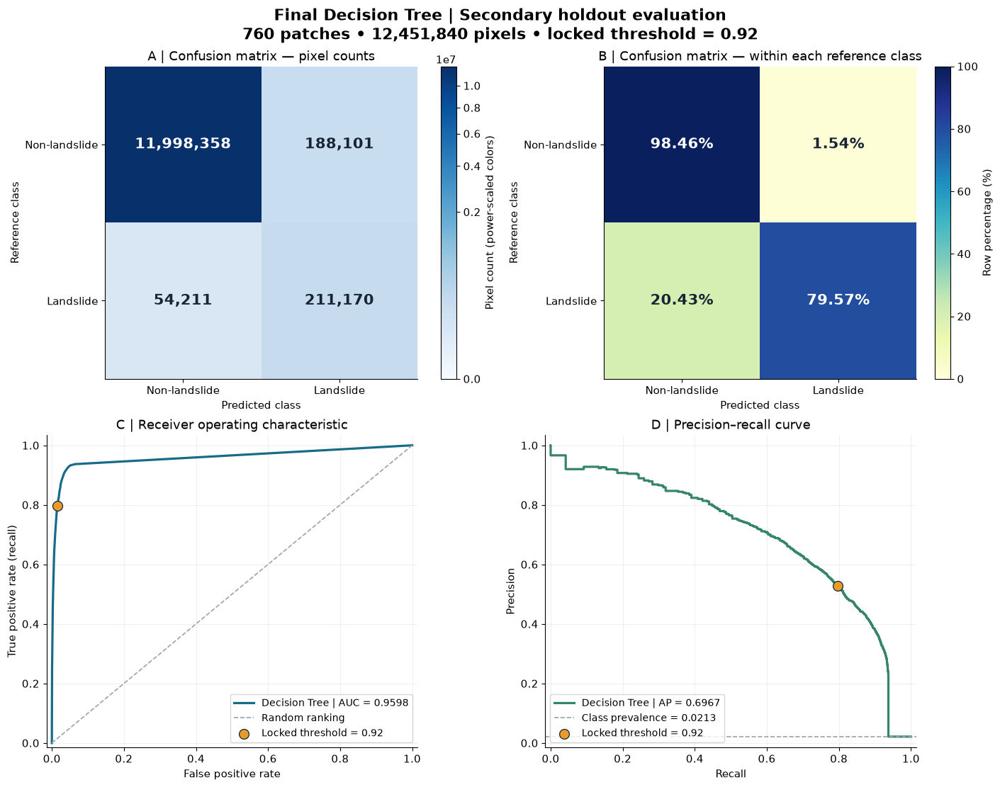

Curves use all holdout pixels; no pixel subsampling.
ROC-AUC and average precision match the saved evaluation.
No model refitting or threshold selection was performed.


In [73]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import PowerNorm
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
)

# ---------------------------------------------------------
# 1. Read the previously computed holdout results
# ---------------------------------------------------------
dt_h_plot_result = dt_final_holdout_evaluation

dt_h_plot_y = np.asarray(
    dt_h_plot_result["y"]
).reshape(-1)

dt_h_plot_probability = np.asarray(
    dt_h_plot_result["probability"]
).reshape(-1)

dt_h_plot_threshold = float(
    dt_h_plot_result["specification"]["threshold"]
)

assert dt_h_plot_y.shape == dt_h_plot_probability.shape
assert np.isfinite(dt_h_plot_probability).all()
assert np.isin(dt_h_plot_y, [0, 1]).all()

dt_h_plot_counts = (
    dt_h_plot_result["patch_counts"][["TN", "FP", "FN", "TP"]]
    .sum()
    .astype(np.int64)
)

dt_h_plot_tn, dt_h_plot_fp, dt_h_plot_fn, dt_h_plot_tp = (
    int(dt_h_plot_counts[name])
    for name in ["TN", "FP", "FN", "TP"]
)

dt_h_plot_cm = np.array([
    [dt_h_plot_tn, dt_h_plot_fp],
    [dt_h_plot_fn, dt_h_plot_tp],
])

assert dt_h_plot_cm.sum() == dt_h_plot_y.size

dt_h_plot_row_percent = (
    100 * dt_h_plot_cm / dt_h_plot_cm.sum(axis=1, keepdims=True)
)

dt_h_plot_recall = (
    dt_h_plot_tp / (dt_h_plot_tp + dt_h_plot_fn)
)
dt_h_plot_precision = (
    dt_h_plot_tp / (dt_h_plot_tp + dt_h_plot_fp)
)
dt_h_plot_fpr_operating = (
    dt_h_plot_fp / (dt_h_plot_fp + dt_h_plot_tn)
)
dt_h_plot_prevalence = (
    (dt_h_plot_tp + dt_h_plot_fn) / dt_h_plot_y.size
)

# ---------------------------------------------------------
# 2. Exact probability-score aggregation
#
# Identical scores are grouped with their pixel counts.
# This preserves the exact ROC and PR curves while reducing
# the number of values passed to the curve functions.
# ---------------------------------------------------------
dt_h_plot_scores, dt_h_plot_total_counts = np.unique(
    dt_h_plot_probability,
    return_counts=True,
)

dt_h_plot_positive_scores, dt_h_plot_positive_counts = np.unique(
    dt_h_plot_probability[dt_h_plot_y == 1],
    return_counts=True,
)

dt_h_plot_pos_hist = np.zeros(
    len(dt_h_plot_scores),
    dtype=np.int64,
)

dt_h_plot_pos_hist[
    np.searchsorted(dt_h_plot_scores, dt_h_plot_positive_scores)
] = dt_h_plot_positive_counts

dt_h_plot_neg_hist = (
    dt_h_plot_total_counts - dt_h_plot_pos_hist
)

dt_h_plot_weighted_y = np.concatenate([
    np.zeros(len(dt_h_plot_scores), dtype=np.uint8),
    np.ones(len(dt_h_plot_scores), dtype=np.uint8),
])

dt_h_plot_weighted_scores = np.tile(dt_h_plot_scores, 2)

dt_h_plot_weights = np.concatenate([
    dt_h_plot_neg_hist,
    dt_h_plot_pos_hist,
])

dt_h_plot_keep = dt_h_plot_weights > 0

dt_h_plot_weighted_y = dt_h_plot_weighted_y[dt_h_plot_keep]
dt_h_plot_weighted_scores = dt_h_plot_weighted_scores[dt_h_plot_keep]
dt_h_plot_weights = dt_h_plot_weights[dt_h_plot_keep]

dt_h_plot_fpr, dt_h_plot_tpr, _ = roc_curve(
    dt_h_plot_weighted_y,
    dt_h_plot_weighted_scores,
    sample_weight=dt_h_plot_weights,
)

dt_h_plot_pr_precision, dt_h_plot_pr_recall, _ = (
    precision_recall_curve(
        dt_h_plot_weighted_y,
        dt_h_plot_weighted_scores,
        sample_weight=dt_h_plot_weights,
    )
)

dt_h_plot_auc = roc_auc_score(
    dt_h_plot_weighted_y,
    dt_h_plot_weighted_scores,
    sample_weight=dt_h_plot_weights,
)

dt_h_plot_ap = average_precision_score(
    dt_h_plot_weighted_y,
    dt_h_plot_weighted_scores,
    sample_weight=dt_h_plot_weights,
)

# Verify agreement with the previous evaluation.
assert np.isclose(
    dt_h_plot_auc,
    dt_h_plot_result["metrics"]["ROC_AUC"],
    atol=1e-10,
)
assert np.isclose(
    dt_h_plot_ap,
    dt_h_plot_result["metrics"]["Average_precision"],
    atol=1e-10,
)

# ---------------------------------------------------------
# 3. Professional evaluation figure
# ---------------------------------------------------------
with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 11),
        constrained_layout=True,
    )

    class_labels = ["Non-landslide", "Landslide"]

    # A. Confusion matrix: pixel counts
    ax = axes[0, 0]

    count_norm = PowerNorm(
        gamma=0.35,
        vmin=0,
        vmax=dt_h_plot_cm.max(),
    )

    im_counts = ax.imshow(
        dt_h_plot_cm,
        cmap="Blues",
        norm=count_norm,
    )

    for row in range(2):
        for col in range(2):
            value = dt_h_plot_cm[row, col]
            text_color = (
                "white" if count_norm(value) > 0.65 else "#172435"
            )
            ax.text(
                col, row,
                f"{value:,}",
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color=text_color,
            )

    ax.set(
        title="A | Confusion matrix — pixel counts",
        xlabel="Predicted class",
        ylabel="Reference class",
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=class_labels,
        yticklabels=class_labels,
    )

    fig.colorbar(
        im_counts,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Pixel count (power-scaled colors)",
    )

    # B. Confusion matrix: row percentages
    ax = axes[0, 1]

    im_percent = ax.imshow(
        dt_h_plot_row_percent,
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
    )

    for row in range(2):
        for col in range(2):
            value = dt_h_plot_row_percent[row, col]
            ax.text(
                col, row,
                f"{value:.2f}%",
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color="white" if value > 55 else "#172435",
            )

    ax.set(
        title="B | Confusion matrix — within each reference class",
        xlabel="Predicted class",
        ylabel="Reference class",
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=class_labels,
        yticklabels=class_labels,
    )

    fig.colorbar(
        im_percent,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Row percentage (%)",
    )

    # C. ROC curve
    ax = axes[1, 0]

    ax.plot(
        dt_h_plot_fpr,
        dt_h_plot_tpr,
        color="#176B87",
        linewidth=2.3,
        label=f"Decision Tree | AUC = {dt_h_plot_auc:.4f}",
    )

    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="#9AA3AC",
        linewidth=1.2,
        label="Random ranking",
    )

    ax.scatter(
        dt_h_plot_fpr_operating,
        dt_h_plot_recall,
        s=100,
        color="#E89B28",
        edgecolor="#172435",
        linewidth=0.9,
        zorder=5,
        label=f"Locked threshold = {dt_h_plot_threshold:.2f}",
    )

    ax.set(
        title="C | Receiver operating characteristic",
        xlabel="False positive rate",
        ylabel="True positive rate (recall)",
        xlim=(-0.015, 1.015),
        ylim=(-0.015, 1.035),
    )
    ax.grid(alpha=0.18)
    ax.legend(loc="lower right", frameon=True, fontsize=10)

    # D. Precision–recall curve
    ax = axes[1, 1]

    ax.step(
        dt_h_plot_pr_recall,
        dt_h_plot_pr_precision,
        where="post",
        color="#35856A",
        linewidth=2.3,
        label=f"Decision Tree | AP = {dt_h_plot_ap:.4f}",
    )

    ax.axhline(
        dt_h_plot_prevalence,
        linestyle="--",
        color="#9AA3AC",
        linewidth=1.2,
        label=f"Class prevalence = {dt_h_plot_prevalence:.4f}",
    )

    ax.scatter(
        dt_h_plot_recall,
        dt_h_plot_precision,
        s=100,
        color="#E89B28",
        edgecolor="#172435",
        linewidth=0.9,
        zorder=5,
        label=f"Locked threshold = {dt_h_plot_threshold:.2f}",
    )

    ax.set(
        title="D | Precision–recall curve",
        xlabel="Recall",
        ylabel="Precision",
        xlim=(-0.015, 1.015),
        ylim=(-0.015, 1.035),
    )
    ax.grid(alpha=0.18)
    ax.legend(loc="lower left", frameon=True, fontsize=10)

    fig.suptitle(
        "Final Decision Tree | Secondary holdout evaluation\n"
        f"{len(dt_h_plot_result['patch_ids']):,} patches • "
        f"{dt_h_plot_y.size:,} pixels • "
        f"locked threshold = {dt_h_plot_threshold:.2f}",
        fontsize=16,
        fontweight="bold",
    )

    plt.show()

print("Curves use all holdout pixels; no pixel subsampling.")
print("ROC-AUC and average precision match the saved evaluation.")
print("No model refitting or threshold selection was performed.")

### Rationale
Confusion matrices and ROC and precision–recall curves were examined
to characterize classification errors and discrimination across thresholds.

### Result
At the locked threshold of 0.92, the model detected 79.57% of landslide
pixels while incorrectly labeling 1.54% of non-landslide pixels as landslide.
Precision was 52.89%.

ROC-AUC was 0.9598 and average precision was 0.6967, compared with
a positive-class prevalence of approximately 0.0213. Despite the low
false positive rate, false positives remained substantial in absolute
number because non-landslide pixels dominated the dataset.

The curves used all holdout pixels, and their summary metrics matched
the saved evaluation. No refitting or threshold adjustment was performed.

### Visualization Decision
These four panels adequately summarize aggregate holdout performance.
Spatial inspection of the same six holdout images previously examined
for LR is the next complementary analysis.

Same six holdout image IDs previously inspected for LR.
Mask alignment was verified for all six images.
Locked threshold: 0.92


,patch_id,landslide_pixels,landslide_percent,predicted_landslide_pixels,TN,FP,FN,TP,Precision,Recall,F2,IoU
0,105,918,5.60,1516,14743,723,125,793,0.5231,0.8638,0.7643,0.4832
1,2684,122,0.74,397,15919,343,68,54,0.1360,0.4426,0.3051,0.1161
2,3459,0,0.00,204,16180,204,0,0,0.0000,Undefined,0.0000,0.0000
3,1535,993,6.06,1063,15215,176,106,887,0.8344,0.8933,0.8808,0.7588
4,590,1545,9.43,1938,14094,745,352,1193,0.6156,0.7722,0.7348,0.5210
5,3316,0,0.00,6,16378,6,0,0,0.0000,Undefined,0.0000,0.0000


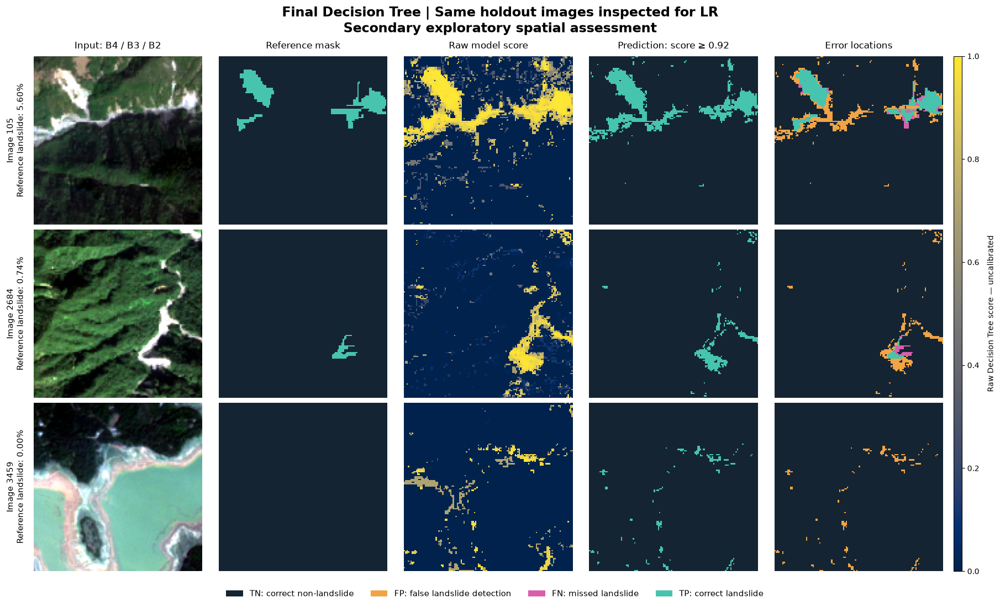

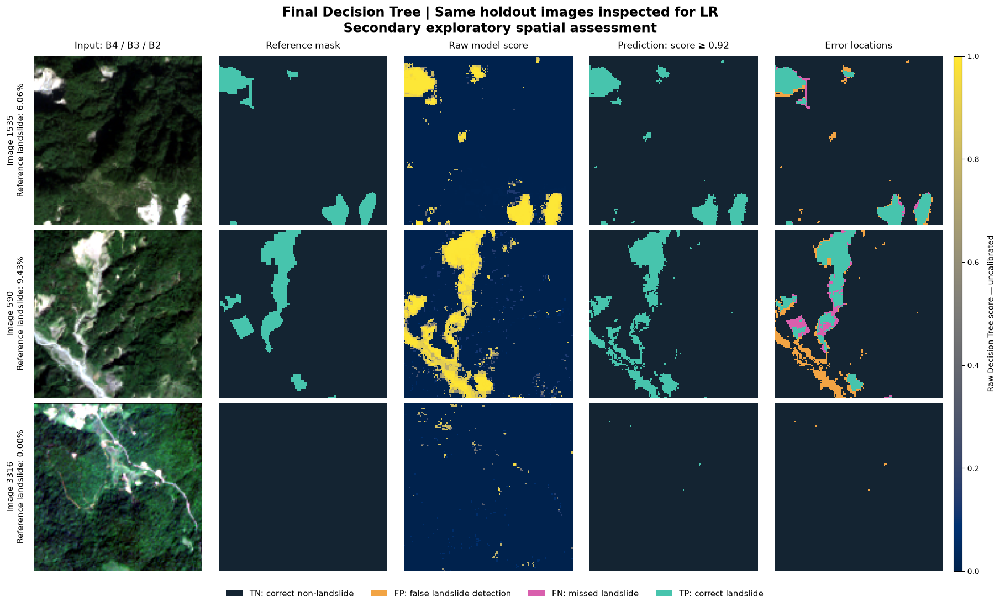

RGB stretching is for display only.
Raw model scores are uncalibrated.
These examples illustrate spatial behavior; aggregate evaluation uses all 760 holdout images.


In [75]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display

# ---------------------------------------------------------
# 1. Use the records already prepared by the previous cell
# ---------------------------------------------------------
assert len(dt_holdout_spatial_records) == 6

# Format a display copy without pandas Styler or jinja2.
dt_spatial_display_table = dt_holdout_spatial_metrics.copy()

for column in ["Precision", "Recall", "F2", "IoU"]:
    dt_spatial_display_table[column] = (
        dt_spatial_display_table[column].map(
            lambda value: (
                f"{value:.4f}" if np.isfinite(value) else "Undefined"
            )
        )
    )

dt_spatial_display_table["landslide_percent"] = (
    dt_spatial_display_table["landslide_percent"].map(
        lambda value: f"{value:.2f}"
    )
)

print("Same six holdout image IDs previously inspected for LR.")
print("Mask alignment was verified for all six images.")
print(f"Locked threshold: {dt_spatial_holdout_threshold:.2f}")

display(dt_spatial_display_table)

# ---------------------------------------------------------
# 2. Colors
# ---------------------------------------------------------
dt_holdout_binary_cmap = ListedColormap([
    "#142432",
    "#47C4AD",
])

dt_holdout_error_colors = [
    "#142432",  # TN
    "#F2A444",  # FP
    "#D95FAD",  # FN
    "#47C4AD",  # TP
]

dt_holdout_error_cmap = ListedColormap(
    dt_holdout_error_colors
)

dt_holdout_error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    ncolors=4,
)

dt_holdout_error_legend = [
    Patch(facecolor=color, label=label)
    for color, label in zip(
        dt_holdout_error_colors,
        [
            "TN: correct non-landslide",
            "FP: false landslide detection",
            "FN: missed landslide",
            "TP: correct landslide",
        ],
    )
]

# ---------------------------------------------------------
# 3. Draw both figures from the prepared records
# ---------------------------------------------------------
with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "figure.facecolor": "white",
}):

    for page_start in [0, 3]:

        page_records = dt_holdout_spatial_records[
            page_start:page_start + 3
        ]

        fig = plt.figure(
            figsize=(18, 11),
            constrained_layout=True,
        )

        grid = fig.add_gridspec(
            nrows=4,
            ncols=6,
            width_ratios=[1, 1, 1, 1, 1, 0.045],
            height_ratios=[1, 1, 1, 0.16],
        )

        score_artist = None

        for row, record in enumerate(page_records):

            panels = [
                (record["rgb"], "Input: B4 / B3 / B2"),
                (record["mask"], "Reference mask"),
                (record["probability"], "Raw model score"),
                (
                    record["prediction"],
                    f"Prediction: score ≥ {dt_spatial_holdout_threshold:.2f}",
                ),
                (record["error"], "Error locations"),
            ]

            for col, (panel_data, panel_title) in enumerate(panels):

                ax = fig.add_subplot(grid[row, col])

                if col == 0:
                    ax.imshow(panel_data)

                elif col in [1, 3]:
                    ax.imshow(
                        panel_data,
                        cmap=dt_holdout_binary_cmap,
                        vmin=0,
                        vmax=1,
                        interpolation="nearest",
                    )

                elif col == 2:
                    score_artist = ax.imshow(
                        panel_data,
                        cmap="cividis",
                        vmin=0,
                        vmax=1,
                        interpolation="nearest",
                    )

                else:
                    ax.imshow(
                        panel_data,
                        cmap=dt_holdout_error_cmap,
                        norm=dt_holdout_error_norm,
                        interpolation="nearest",
                    )

                if row == 0:
                    ax.set_title(panel_title, pad=10)

                if col == 0:
                    ax.set_ylabel(
                        f"Image {record['patch_id']}\n"
                        f"Reference landslide: "
                        f"{record['metrics']['landslide_percent']:.2f}%",
                        fontsize=11,
                        labelpad=10,
                    )

                ax.set_xticks([])
                ax.set_yticks([])

                for spine in ax.spines.values():
                    spine.set_visible(False)

        colorbar_ax = fig.add_subplot(grid[:3, 5])

        colorbar = fig.colorbar(
            score_artist,
            cax=colorbar_ax,
        )
        colorbar.set_label(
            "Raw Decision Tree score — uncalibrated",
            labelpad=10,
        )

        legend_ax = fig.add_subplot(grid[3, :])
        legend_ax.axis("off")
        legend_ax.legend(
            handles=dt_holdout_error_legend,
            loc="center",
            ncol=4,
            frameon=False,
            fontsize=11,
        )

        fig.suptitle(
            "Final Decision Tree | Same holdout images inspected for LR\n"
            "Secondary exploratory spatial assessment",
            fontsize=17,
            fontweight="bold",
        )

        plt.show()

print("RGB stretching is for display only.")
print("Raw model scores are uncalibrated.")
print(
    "These examples illustrate spatial behavior; "
    "aggregate evaluation uses all 760 holdout images."
)

### Rationale
The same six holdout image IDs previously inspected for LR were examined
to identify spatial overprediction, missed landslide regions, and false
detections in negative images. Saved-label alignment was verified for
every image.

### Result
Image 1535 showed the strongest performance among the four positive
examples (F2 = 0.8808; IoU = 0.7588). Image 105 achieved high recall
(0.8638), but substantial false positives reduced precision to 0.5231.

Image 2684 contained a small reference landslide and showed both missed
pixels and overprediction (54 TP, 68 FN, 343 FP; F2 = 0.3051).
Image 590 captured much of the reference landslide but exhibited
overprediction and omissions (1193 TP, 745 FP, 352 FN; F2 = 0.7348).

The two reference-negative images showed contrasting false-positive
burdens: 204 pixels for image 3459 and 6 pixels for image 3316.
Recall is undefined for these negative images; false-positive counts
and rates are more informative for their interpretation.

These examples illustrate spatial behavior and do not establish
aggregate superiority over LR. Overall performance remains based
on all 760 holdout images.

### Visualization Decision
The input composites, reference masks, raw-score maps, predictions,
and error maps provide complementary spatial information.
No additional plots are needed for these six examples.

In [76]:
import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from IPython.display import display

# ---------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------
dt_holdout_bootstrap_repeats = 2000
dt_holdout_bootstrap_seed = 43
dt_holdout_bootstrap_batch_size = 50

if not callable(globals().get("dt_bootstrap_metrics")):
    raise RuntimeError(
        "Run the earlier cell defining dt_bootstrap_metrics first."
    )

dt_hb_metric_names = list(dt_bootstrap_metric_names)

dt_hb_expected_names = [
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "Accuracy", "ROC_AUC", "Average_precision", "Brier", "Log_loss",
]

assert dt_hb_metric_names == dt_hb_expected_names

# ---------------------------------------------------------
# 2. Align per-image records with saved prediction order
# ---------------------------------------------------------
dt_hb_result = dt_final_holdout_evaluation

dt_hb_ids = [
    str(pid) for pid in dt_hb_result["patch_ids"]
]

dt_hb_patch_table = dt_hb_result["patch_counts"].copy()
dt_hb_patch_table["patch_id"] = (
    dt_hb_patch_table["patch_id"].astype(str)
)

assert dt_hb_patch_table["patch_id"].is_unique

dt_hb_patch_table = (
    dt_hb_patch_table
    .set_index("patch_id")
    .loc[dt_hb_ids]
    .reset_index()
)

dt_hb_n_patches = len(dt_hb_ids)

dt_hb_y = np.asarray(
    dt_hb_result["y"]
).reshape(dt_hb_n_patches, -1)

dt_hb_probability = np.asarray(
    dt_hb_result["probability"]
).reshape(dt_hb_n_patches, -1)

assert dt_hb_y.shape == dt_hb_probability.shape
assert np.all(
    dt_hb_y.sum(axis=1)
    == dt_hb_patch_table["landslide_pixels"].to_numpy()
)

# Required column order for the existing metric function.
dt_hb_totals_by_patch = dt_hb_patch_table[[
    "TN", "FP", "FN", "TP", "pixels",
    "squared_error_sum", "log_loss_sum",
]].to_numpy(dtype=np.float64)

# ---------------------------------------------------------
# 3. Exact per-image score histograms
# These preserve score ties for ROC-AUC and average precision.
# ---------------------------------------------------------
dt_hb_scores = np.unique(dt_hb_probability)
dt_hb_n_scores = len(dt_hb_scores)

dt_hb_pos_rows = []
dt_hb_pos_cols = []
dt_hb_pos_data = []

dt_hb_neg_rows = []
dt_hb_neg_cols = []
dt_hb_neg_data = []

for dt_hb_row in range(dt_hb_n_patches):

    patch_y = dt_hb_y[dt_hb_row]
    patch_probability = dt_hb_probability[dt_hb_row]

    for class_value, rows, cols, data in [
        (1, dt_hb_pos_rows, dt_hb_pos_cols, dt_hb_pos_data),
        (0, dt_hb_neg_rows, dt_hb_neg_cols, dt_hb_neg_data),
    ]:
        scores, counts = np.unique(
            patch_probability[patch_y == class_value],
            return_counts=True,
        )

        rows.extend([dt_hb_row] * len(scores))
        cols.extend(np.searchsorted(dt_hb_scores, scores).tolist())
        data.extend(counts.tolist())

dt_hb_positive_hist = csr_matrix(
    (
        np.asarray(dt_hb_pos_data, dtype=np.float64),
        (dt_hb_pos_rows, dt_hb_pos_cols),
    ),
    shape=(dt_hb_n_patches, dt_hb_n_scores),
)

dt_hb_negative_hist = csr_matrix(
    (
        np.asarray(dt_hb_neg_data, dtype=np.float64),
        (dt_hb_neg_rows, dt_hb_neg_cols),
    ),
    shape=(dt_hb_n_patches, dt_hb_n_scores),
)

assert int(dt_hb_positive_hist.sum()) == int(dt_hb_y.sum())
assert int(
    dt_hb_positive_hist.sum() + dt_hb_negative_hist.sum()
) == dt_hb_y.size

# ---------------------------------------------------------
# 4. Verify the metric function against the saved evaluation
# ---------------------------------------------------------
dt_hb_point_estimates = np.asarray(
    dt_bootstrap_metrics(
        dt_hb_totals_by_patch.sum(axis=0, keepdims=True),
        np.asarray(dt_hb_positive_hist.sum(axis=0)),
        np.asarray(dt_hb_negative_hist.sum(axis=0)),
    )
).reshape(-1)

dt_hb_saved_estimates = np.array([
    dt_hb_result["metrics"][name]
    for name in dt_hb_metric_names
])

np.testing.assert_allclose(
    dt_hb_point_estimates,
    dt_hb_saved_estimates,
    rtol=1e-8,
    atol=1e-10,
)

# ---------------------------------------------------------
# 5. Whole-image bootstrap
# Each row of weights represents one resampled image set.
# ---------------------------------------------------------
dt_hb_rng = np.random.default_rng(
    dt_holdout_bootstrap_seed
)

dt_hb_samples_array = np.empty((
    dt_holdout_bootstrap_repeats,
    len(dt_hb_metric_names),
))

for dt_hb_start in range(
    0,
    dt_holdout_bootstrap_repeats,
    dt_holdout_bootstrap_batch_size,
):
    dt_hb_stop = min(
        dt_hb_start + dt_holdout_bootstrap_batch_size,
        dt_holdout_bootstrap_repeats,
    )

    dt_hb_weights = dt_hb_rng.multinomial(
        n=dt_hb_n_patches,
        pvals=np.full(
            dt_hb_n_patches,
            1 / dt_hb_n_patches,
        ),
        size=dt_hb_stop - dt_hb_start,
    )

    dt_hb_resampled_totals = (
        dt_hb_weights @ dt_hb_totals_by_patch
    )

    dt_hb_resampled_positive = np.asarray(
        dt_hb_positive_hist.T.dot(dt_hb_weights.T)
    ).T

    dt_hb_resampled_negative = np.asarray(
        dt_hb_negative_hist.T.dot(dt_hb_weights.T)
    ).T

    dt_hb_samples_array[dt_hb_start:dt_hb_stop] = (
        dt_bootstrap_metrics(
            dt_hb_resampled_totals,
            dt_hb_resampled_positive,
            dt_hb_resampled_negative,
        )
    )

    if dt_hb_stop % 500 == 0:
        print(
            f"Completed {dt_hb_stop}/"
            f"{dt_holdout_bootstrap_repeats} bootstrap repetitions"
        )

assert np.isfinite(dt_hb_samples_array).all()

# ---------------------------------------------------------
# 6. Percentile 95% confidence intervals
# ---------------------------------------------------------
dt_holdout_bootstrap_samples = pd.DataFrame(
    dt_hb_samples_array,
    columns=dt_hb_metric_names,
)

dt_hb_limits = np.quantile(
    dt_hb_samples_array,
    [0.025, 0.975],
    axis=0,
)

dt_holdout_bootstrap_intervals = pd.DataFrame({
    "Estimate": dt_hb_point_estimates,
    "CI_lower": dt_hb_limits[0],
    "CI_upper": dt_hb_limits[1],
}, index=dt_hb_metric_names)

dt_holdout_bootstrap_intervals.index.name = "Metric"

print("\nSECONDARY HOLDOUT — WHOLE-IMAGE BOOTSTRAP")
print(f"Images per repetition: {dt_hb_n_patches}")
print(f"Repetitions: {dt_holdout_bootstrap_repeats}")
print("95% percentile confidence intervals\n")

display(dt_holdout_bootstrap_intervals.round(6))

# ---------------------------------------------------------
# 7. Save separately from the outer-fold bootstrap results
# ---------------------------------------------------------
dt_holdout_bootstrap_path = (
    DT_FINAL_PIPELINE_DIR / "secondary_holdout_bootstrap.joblib"
)

save_dt_pipeline_checkpoint(
    dt_holdout_bootstrap_path,
    {
        "evaluation_signature": dt_holdout_evaluation_signature,
        "repetitions": dt_holdout_bootstrap_repeats,
        "random_seed": dt_holdout_bootstrap_seed,
        "resampling_unit": "whole image",
        "model_held_fixed": True,
        "threshold_held_fixed": True,
        "samples": dt_holdout_bootstrap_samples,
        "intervals": dt_holdout_bootstrap_intervals,
        "patch_ids": dt_hb_ids,
    },
)

print("Bootstrap results saved.")

Completed 500/2000 bootstrap repetitions
Completed 1000/2000 bootstrap repetitions
Completed 1500/2000 bootstrap repetitions
Completed 2000/2000 bootstrap repetitions

SECONDARY HOLDOUT — WHOLE-IMAGE BOOTSTRAP
Images per repetition: 760
Repetitions: 2000
95% percentile confidence intervals



,Estimate,CI_lower,CI_upper
Metric,,,
F2,0.722791,0.700831,0.745124
Precision,0.528889,0.491954,0.563980
Recall,0.795724,0.774025,0.815943
Specificity,0.984565,0.982700,0.986162
IoU,0.465663,0.433943,0.497099
Accuracy,0.980540,0.978479,0.982388
ROC_AUC,0.959770,0.955375,0.964099
Average_precision,0.696749,0.658705,0.731897
Brier,0.035599,0.032753,0.038661


Bootstrap results saved.


### Rationale
Whole-image bootstrap resampling was used to quantify uncertainty
in aggregate secondary holdout metrics while preserving within-image
pixel dependence. Each of 2,000 repetitions sampled 760 images with
replacement, keeping the fitted model and threshold fixed.

### Result
Holdout F2 was 0.722791 (95% percentile CI: 0.700831–0.745124).
Precision was 0.528889 (0.491954–0.563980), recall was 0.795724
(0.774025–0.815943), and IoU was 0.465663 (0.433943–0.497099).

ROC-AUC was 0.959770 (0.955375–0.964099), and average precision
was 0.696749 (0.658705–0.731897). Results were saved separately
from the outer-fold bootstrap analysis.

These intervals describe image-sampling uncertainty for the fixed
model. They do not include training or model-selection uncertainty,
account for dependence between images, or describe individual-image
performance ranges.

### Visualization Decision
A point-and-interval plot is useful for presenting uncertainty.
Higher-is-better metrics and lower-is-better losses should be
displayed in separate panels.

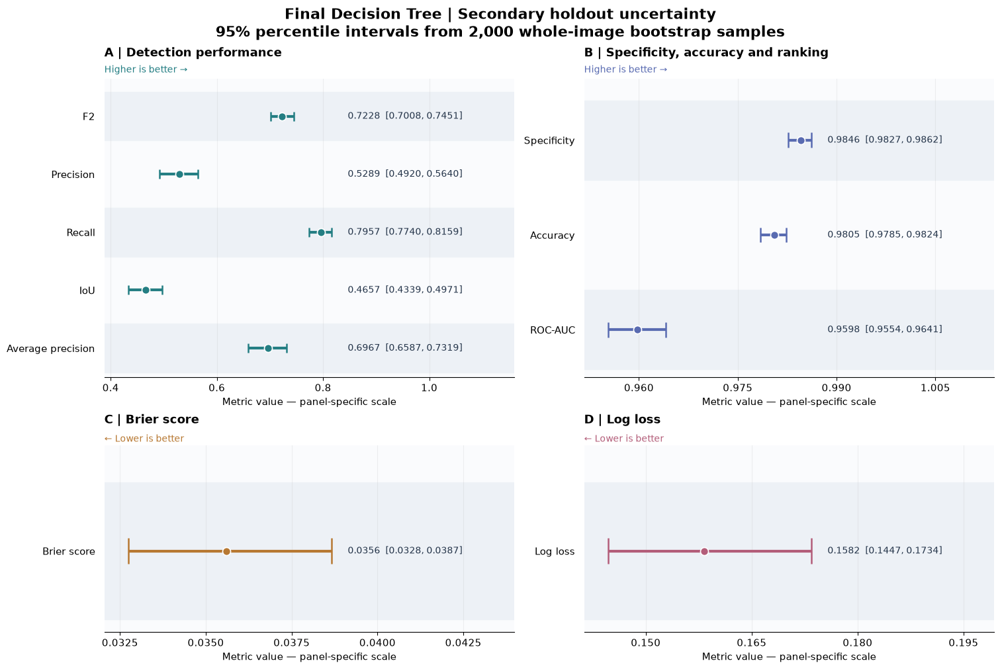

Point: original holdout estimate.
Horizontal line: 95% percentile bootstrap confidence interval.
Text: estimate [lower bound, upper bound].
Horizontal scales differ between panels.
Model and threshold were held fixed throughout resampling.


In [77]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Use the previously computed intervals.
dt_ci_plot_table = dt_holdout_bootstrap_intervals.copy()

dt_ci_plot_groups = [
    {
        "metrics": [
            "F2", "Precision", "Recall", "IoU", "Average_precision"
        ],
        "labels": [
            "F2", "Precision", "Recall", "IoU", "Average precision"
        ],
        "title": "A | Detection performance",
        "direction": "Higher is better →",
        "color": "#247E83",
    },
    {
        "metrics": ["Specificity", "Accuracy", "ROC_AUC"],
        "labels": ["Specificity", "Accuracy", "ROC-AUC"],
        "title": "B | Specificity, accuracy and ranking",
        "direction": "Higher is better →",
        "color": "#596BB1",
    },
    {
        "metrics": ["Brier"],
        "labels": ["Brier score"],
        "title": "C | Brier score",
        "direction": "← Lower is better",
        "color": "#B77832",
    },
    {
        "metrics": ["Log_loss"],
        "labels": ["Log loss"],
        "title": "D | Log loss",
        "direction": "← Lower is better",
        "color": "#B35D79",
    },
]

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "#FAFBFD",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
}):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True,
        gridspec_kw={"height_ratios": [1.6, 1]},
    )

    for ax, group in zip(axes.flat, dt_ci_plot_groups):

        selected = dt_ci_plot_table.loc[group["metrics"]]

        estimates = selected["Estimate"].to_numpy(dtype=float)
        lower = selected["CI_lower"].to_numpy(dtype=float)
        upper = selected["CI_upper"].to_numpy(dtype=float)

        y_positions = np.arange(len(selected))

        # Alternating row shading.
        for row in y_positions:
            if row % 2 == 0:
                ax.axhspan(
                    row - 0.42,
                    row + 0.42,
                    color="#EDF1F6",
                    zorder=0,
                )

        # Draw intervals independently of the point locations.
        ax.hlines(
            y_positions,
            lower,
            upper,
            color=group["color"],
            linewidth=3,
            zorder=2,
        )

        ax.vlines(
            lower,
            y_positions - 0.08,
            y_positions + 0.08,
            color=group["color"],
            linewidth=1.8,
            zorder=2,
        )

        ax.vlines(
            upper,
            y_positions - 0.08,
            y_positions + 0.08,
            color=group["color"],
            linewidth=1.8,
            zorder=2,
        )

        ax.scatter(
            estimates,
            y_positions,
            s=75,
            color=group["color"],
            edgecolor="white",
            linewidth=1.2,
            zorder=3,
        )

        # Reserve space to the right for exact values.
        interval_min = min(lower.min(), estimates.min())
        interval_max = max(upper.max(), estimates.max())
        interval_span = max(interval_max - interval_min, 0.005)

        left_limit = max(0, interval_min - 0.12 * interval_span)
        right_limit = interval_max + 0.90 * interval_span

        ax.set_xlim(left_limit, right_limit)

        text_x = interval_max + 0.08 * interval_span

        for row, estimate, lo, hi in zip(
            y_positions, estimates, lower, upper
        ):
            ax.text(
                text_x,
                row,
                f"{estimate:.4f}  [{lo:.4f}, {hi:.4f}]",
                va="center",
                ha="left",
                fontsize=10,
                color="#243449",
            )

        ax.set_yticks(y_positions)
        ax.set_yticklabels(group["labels"])
        ax.set_ylim(len(selected) - 0.5, -0.65)

        ax.set_title(
            group["title"],
            loc="left",
            pad=24,
            fontweight="bold",
        )

        ax.text(
            0,
            1.02,
            group["direction"],
            transform=ax.transAxes,
            fontsize=10,
            color=group["color"],
        )

        ax.set_xlabel("Metric value — panel-specific scale")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.tick_params(axis="y", length=0, pad=10)
        ax.grid(axis="x", alpha=0.18)
        ax.set_axisbelow(True)

    fig.suptitle(
        "Final Decision Tree | Secondary holdout uncertainty\n"
        "95% percentile intervals from 2,000 whole-image bootstrap samples",
        fontsize=16,
        fontweight="bold",
    )

    plt.show()

print("Point: original holdout estimate.")
print("Horizontal line: 95% percentile bootstrap confidence interval.")
print("Text: estimate [lower bound, upper bound].")
print("Horizontal scales differ between panels.")
print("Model and threshold were held fixed throughout resampling.")

### Rationale
Point-and-interval plots summarize holdout estimates together with
their image-level bootstrap uncertainty.

### Result
F2 was 0.7228 (95% CI: 0.7008–0.7451), recall was 0.7957
(0.7740–0.8159), and precision was 0.5289 (0.4920–0.5640).
The model detected a substantial proportion of landslide pixels,
while false positive predictions remained an important limitation.

Intervals reflect image-sampling uncertainty for the fixed model
and threshold. Their visual lengths should not be compared across
panels because horizontal scales differ.

### Visualization Decision
The figure adequately summarizes uncertainty. For the final report,
numeric annotations should be placed outside the plotting axes so
that bounded metrics do not require axes extending beyond 1.

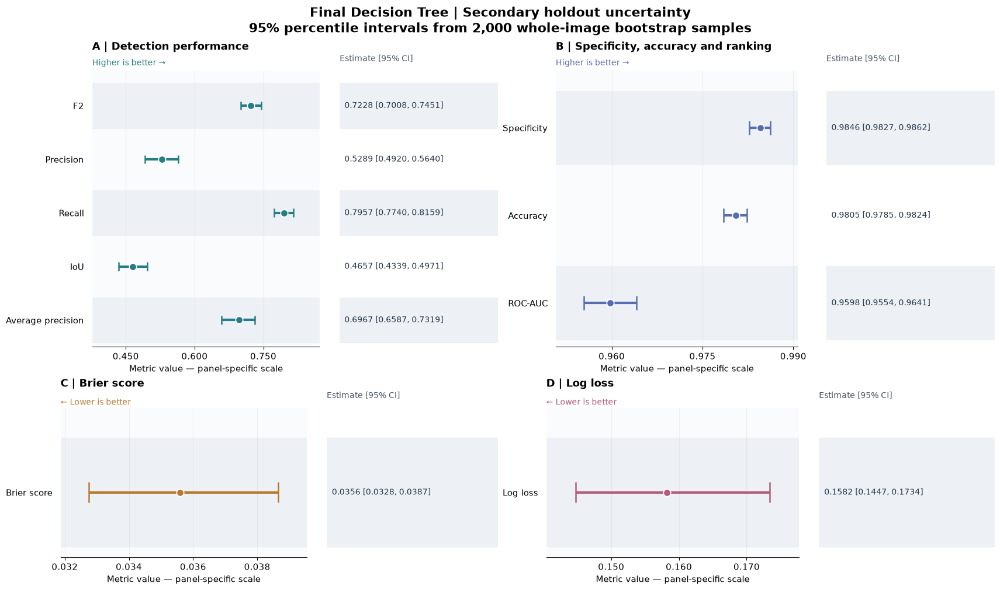

Points: original holdout estimates.
Lines: 95% percentile bootstrap confidence intervals.
Numeric annotations are displayed in separate columns.
Horizontal scales differ between panels.


In [78]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

dt_ci_table = dt_holdout_bootstrap_intervals.copy()

dt_ci_groups = [
    {
        "metrics": [
            "F2", "Precision", "Recall", "IoU", "Average_precision"
        ],
        "labels": [
            "F2", "Precision", "Recall", "IoU", "Average precision"
        ],
        "title": "A | Detection performance",
        "direction": "Higher is better →",
        "color": "#247E83",
        "bounded": True,
    },
    {
        "metrics": ["Specificity", "Accuracy", "ROC_AUC"],
        "labels": ["Specificity", "Accuracy", "ROC-AUC"],
        "title": "B | Specificity, accuracy and ranking",
        "direction": "Higher is better →",
        "color": "#596BB1",
        "bounded": True,
    },
    {
        "metrics": ["Brier"],
        "labels": ["Brier score"],
        "title": "C | Brier score",
        "direction": "← Lower is better",
        "color": "#B77832",
        "bounded": True,
    },
    {
        "metrics": ["Log_loss"],
        "labels": ["Log loss"],
        "title": "D | Log loss",
        "direction": "← Lower is better",
        "color": "#B35D79",
        "bounded": False,
    },
]

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "#FAFBFD",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
}):
    fig = plt.figure(
        figsize=(17, 10),
        constrained_layout=True,
    )

    outer_grid = fig.add_gridspec(
        2, 2,
        height_ratios=[1.6, 1],
        wspace=0.10,
        hspace=0.10,
    )

    for panel_index, group in enumerate(dt_ci_groups):

        panel_row, panel_col = divmod(panel_index, 2)

        inner_grid = outer_grid[
            panel_row, panel_col
        ].subgridspec(
            1, 2,
            width_ratios=[1.8, 1.25],
            wspace=0.04,
        )

        ax = fig.add_subplot(inner_grid[0, 0])
        text_ax = fig.add_subplot(
            inner_grid[0, 1],
            sharey=ax,
        )

        selected = dt_ci_table.loc[group["metrics"]]

        estimates = selected["Estimate"].to_numpy(dtype=float)
        lower = selected["CI_lower"].to_numpy(dtype=float)
        upper = selected["CI_upper"].to_numpy(dtype=float)

        y_positions = np.arange(len(selected))

        for row in y_positions:
            if row % 2 == 0:
                for target_ax in [ax, text_ax]:
                    target_ax.axhspan(
                        row - 0.42,
                        row + 0.42,
                        color="#EDF1F6",
                        zorder=0,
                    )

        ax.hlines(
            y_positions,
            lower,
            upper,
            color=group["color"],
            linewidth=3,
            zorder=2,
        )

        for bounds in [lower, upper]:
            ax.vlines(
                bounds,
                y_positions - 0.08,
                y_positions + 0.08,
                color=group["color"],
                linewidth=1.8,
                zorder=2,
            )

        ax.scatter(
            estimates,
            y_positions,
            s=80,
            color=group["color"],
            edgecolor="white",
            linewidth=1.2,
            zorder=3,
        )

        # Limits are determined by the data, with modest padding.
        data_min = min(lower.min(), estimates.min())
        data_max = max(upper.max(), estimates.max())
        data_span = max(data_max - data_min, 0.005)
        padding = 0.15 * data_span

        left_limit = max(0, data_min - padding)
        right_limit = data_max + padding

        if group["bounded"]:
            right_limit = min(1, right_limit)

        ax.set_xlim(left_limit, right_limit)

        ax.set_yticks(y_positions)
        ax.set_yticklabels(group["labels"])
        ax.set_ylim(len(selected) - 0.5, -0.65)

        ax.set_title(
            group["title"],
            loc="left",
            pad=26,
            fontweight="bold",
        )

        ax.text(
            0,
            1.02,
            group["direction"],
            transform=ax.transAxes,
            fontsize=10,
            color=group["color"],
        )

        ax.set_xlabel("Metric value — panel-specific scale")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.xaxis.set_major_formatter(
            FormatStrFormatter("%.3f")
        )

        ax.tick_params(axis="y", length=0, pad=10)
        ax.grid(axis="x", alpha=0.18)
        ax.set_axisbelow(True)

        # Separate annotation column: no extra metric-axis space.
        text_ax.set_xlim(0, 1)
        text_ax.set_axis_off()

        text_ax.set_title(
            "Estimate [95% CI]",
            fontsize=10,
            loc="left",
            pad=12,
            color="#475569",
        )

        for row, estimate, lo, hi in zip(
            y_positions, estimates, lower, upper
        ):
            text_ax.text(
                0.03,
                row,
                f"{estimate:.4f} [{lo:.4f}, {hi:.4f}]",
                va="center",
                ha="left",
                fontsize=10,
                color="#243449",
            )

    fig.suptitle(
        "Final Decision Tree | Secondary holdout uncertainty\n"
        "95% percentile intervals from 2,000 whole-image bootstrap samples",
        fontsize=16,
        fontweight="bold",
    )

    plt.show()

print("Points: original holdout estimates.")
print("Lines: 95% percentile bootstrap confidence intervals.")
print("Numeric annotations are displayed in separate columns.")
print("Horizontal scales differ between panels.")

### Result
The final Decision Tree achieved holdout F2 = 0.7228
(95% image-bootstrap CI: 0.7008–0.7451).
Points show the original estimates; horizontal lines show
95% percentile intervals from 2,000 whole-image bootstrap samples.

### Visualization Decision
The revised layout separates numeric annotations from the plotting
axes. Panel-specific scales improve readability, so interval lengths
should not be compared across panels. No further figure is needed
for this uncertainty analysis.

In [79]:
import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------
# 1. Final consistency checks
# ---------------------------------------------------------
dt_audit_dev_ids = {str(pid) for pid in dev_ids}
dt_audit_test_ids = {str(pid) for pid in test_ids}

dt_audit_training_ids = {
    str(pid)
    for pid in dt_final_model_bundle["training_ids"]
}

dt_audit_evaluated_ids = [
    str(pid)
    for pid in dt_final_holdout_evaluation["patch_ids"]
]

assert dt_audit_dev_ids.isdisjoint(dt_audit_test_ids)
assert dt_audit_training_ids == dt_audit_dev_ids

assert len(dt_audit_evaluated_ids) == len(
    set(dt_audit_evaluated_ids)
)
assert set(dt_audit_evaluated_ids) == dt_audit_test_ids

assert dt_final_holdout_evaluation[
    "previous_label_alignment_verified"
]

assert len(dt_outer_evaluations) == 5

dt_audit_oof_ids = (
    dt_oof_patch_counts["patch_id"].astype(str)
)

assert dt_audit_oof_ids.is_unique
assert set(dt_audit_oof_ids) == dt_audit_dev_ids

assert np.isclose(
    dt_final_model_bundle["specification"]["threshold"],
    dt_final_holdout_evaluation["specification"]["threshold"],
)

assert (
    len(dt_final_holdout_evaluation["y"])
    == len(dt_final_holdout_evaluation["probability"])
    == len(dt_audit_test_ids) * 128 * 128
)

dt_final_audit_table = pd.DataFrame({
    "Check": [
        "Development and holdout IDs are disjoint",
        "Final model training IDs equal development IDs",
        "Every holdout image evaluated exactly once",
        "Saved holdout label alignment verified",
        "Five outer-fold evaluations available",
        "Every development image has one OOF record",
        "Holdout threshold matches final locked threshold",
        "All holdout pixels have saved predictions",
    ],
    "Status": ["PASS"] * 8,
})

print("DECISION TREE — FINAL CONSISTENCY CHECKS")
display(dt_final_audit_table)

# ---------------------------------------------------------
# 2. Performance summary
# ---------------------------------------------------------
dt_final_summary_metric_names = [
    "F2",
    "Precision",
    "Recall",
    "Specificity",
    "IoU",
    "Accuracy",
    "ROC_AUC",
    "Average_precision",
    "Brier",
    "Log_loss",
]

dt_summary_outer_fold_table = pd.DataFrame([
    {
        metric: evaluation["metrics"][metric]
        for metric in dt_final_summary_metric_names
    }
    for _, evaluation in sorted(dt_outer_evaluations.items())
])

dt_final_performance_summary = pd.DataFrame(
    index=dt_final_summary_metric_names
)

dt_final_performance_summary["Training_apparent"] = [
    dt_final_model_bundle["training_metrics"][metric]
    for metric in dt_final_summary_metric_names
]

dt_final_performance_summary["Outer_mean"] = (
    dt_summary_outer_fold_table.mean()
)

dt_final_performance_summary["Outer_SD"] = (
    dt_summary_outer_fold_table.std(ddof=1)
)

dt_final_performance_summary["Pooled_OOF"] = [
    dt_pooled_oof_metrics[metric]
    for metric in dt_final_summary_metric_names
]

dt_final_performance_summary["Secondary_holdout"] = [
    dt_final_holdout_evaluation["metrics"][metric]
    for metric in dt_final_summary_metric_names
]

dt_final_performance_summary["Holdout_CI_lower"] = (
    dt_holdout_bootstrap_intervals["CI_lower"]
)

dt_final_performance_summary["Holdout_CI_upper"] = (
    dt_holdout_bootstrap_intervals["CI_upper"]
)

dt_final_performance_summary.index.name = "Metric"

print("\nDECISION TREE — PERFORMANCE SUMMARY")
display(dt_final_performance_summary.round(6))

# ---------------------------------------------------------
# 3. Final model specification
# ---------------------------------------------------------
dt_final_specification_table = pd.DataFrame({
    "Setting": [
        "Development images",
        "Secondary holdout images",
        "Sampled training pixels per image",
        "Probability method",
        "Locked threshold",
        "Final fitted tree depth",
        "Final fitted leaf count",
        "Primary metric",
    ],
    "Value": [
        len(dt_audit_dev_ids),
        len(dt_audit_test_ids),
        dt_final_model_bundle["specification"]["pixels_per_patch"],
        dt_final_model_bundle["specification"]["probability_method"],
        dt_final_model_bundle["specification"]["threshold"],
        dt_final_model_bundle["model"].get_depth(),
        dt_final_model_bundle["model"].get_n_leaves(),
        "F2",
    ],
})

print("\nFINAL MODEL SPECIFICATION")
display(dt_final_specification_table)

print("\nSelected model parameters:")
print(dt_final_model_bundle["specification"]["model_params"])

print(
    "\nTraining results are apparent performance, "
    "not an independent generalization estimate."
)
print(
    "Outer-fold SD is descriptive; "
    "it is not a confidence interval."
)
print(
    "Formal paired classifier comparisons remain deferred "
    "until all classifiers are completed."
)

DECISION TREE — FINAL CONSISTENCY CHECKS


,Check,Status
0,Development and holdout IDs are disjoint,PASS
1,Final model training IDs equal development IDs,PASS
2,Every holdout image evaluated exactly once,PASS
3,Saved holdout label alignment verified,PASS
4,Five outer-fold evaluations available,PASS
5,Every development image has one OOF record,PASS
6,Holdout threshold matches final locked threshold,PASS
7,All holdout pixels have saved predictions,PASS



DECISION TREE — PERFORMANCE SUMMARY


,Training_apparent,Outer_mean,Outer_SD,Pooled_OOF,Secondary_holdout,Holdout_CI_lower,Holdout_CI_upper
Metric,,,,,,,
F2,0.772679,0.737458,0.016114,0.737575,0.722791,0.700831,0.745124
Precision,0.581709,0.516138,0.030783,0.515352,0.528889,0.491954,0.563980
Recall,0.841765,0.826556,0.008987,0.826693,0.795724,0.774025,0.815943
Specificity,0.985352,0.981170,0.001984,0.981171,0.984565,0.982700,0.986162
IoU,0.524369,0.465706,0.026779,0.465103,0.465663,0.433943,0.497099
Accuracy,0.981959,0.977518,0.002023,0.977518,0.980540,0.978479,0.982388
ROC_AUC,0.993169,0.954825,0.005049,0.954870,0.959770,0.955375,0.964099
Average_precision,0.780904,0.713780,0.025692,0.716037,0.696749,0.658705,0.731897
Brier,0.033919,0.035689,0.001993,0.035688,0.035599,0.032753,0.038661



FINAL MODEL SPECIFICATION


,Setting,Value
0,Development images,3039
1,Secondary holdout images,760
2,Sampled training pixels per image,1024
3,Probability method,Uncalibrated — all training patches
4,Locked threshold,0.92
5,Final fitted tree depth,15
6,Final fitted leaf count,3032
7,Primary metric,F2



Selected model parameters:
{'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 15, 'criterion': 'entropy', 'class_weight': 'balanced', 'ccp_alpha': 1e-05, 'random_state': 43}

Training results are apparent performance, not an independent generalization estimate.
Outer-fold SD is descriptive; it is not a confidence interval.
Formal paired classifier comparisons remain deferred until all classifiers are completed.


### Rationale
A final consistency audit and performance summary were prepared to
verify split membership, evaluation coverage, label alignment, and
agreement between the locked and evaluated thresholds.

### Result
All eight consistency checks passed. The final Decision Tree used
depth 15, 3,032 leaves, 1,024 sampled training pixels per development
image, uncalibrated scores, and a locked threshold of 0.92.

Training F2 was 0.772679, pooled outer-fold F2 was 0.737575,
and secondary holdout F2 was 0.722791
(95% image-bootstrap CI: 0.700831–0.745124).

Compared with pooled outer-fold evaluation, holdout precision was
higher and recall was lower, while IoU remained similar.
Training performance was optimistic relative to out-of-training
evaluation. Raw model scores should not be interpreted as calibrated
landslide probabilities.

### Visualization Decision
The summary table complements the existing performance, uncertainty,
and spatial figures. No additional visualization is needed here.
Formal paired classifier comparisons remain deferred until all
classifiers are completed.

In [80]:
from pathlib import Path
from datetime import datetime
import json
import joblib
import numpy as np

# ---------------------------------------------------------
# 1. Create a new export directory
# ---------------------------------------------------------
dt_export_timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

DT_EXPORT_DIR = (
    Path(PROJECT_DIR)
    / "artifacts"
    / f"decision_tree_handoff_{dt_export_timestamp}"
)

DT_EXPORT_DIR.mkdir(parents=True, exist_ok=False)

# ---------------------------------------------------------
# 2. Required objects
# Stop before export if a critical result is missing.
# ---------------------------------------------------------
dt_export_required = [
    "dev_ids",
    "test_ids",
    "nested_splits",
    "FEATURE_NAMES",
    "dt_final_model_bundle",
    "dt_outer_evaluations",
    "dt_final_holdout_evaluation",
    "dt_final_performance_summary",
    "dt_final_audit_table",
    "dt_oof_patch_counts",
    "dt_oof_bootstrap_intervals",
    "dt_holdout_bootstrap_intervals",
]

dt_export_missing_required = [
    name for name in dt_export_required
    if name not in globals()
]

if dt_export_missing_required:
    raise RuntimeError(
        "Required objects are missing: "
        + ", ".join(dt_export_missing_required)
    )

# ---------------------------------------------------------
# 3. Organize saved objects
# Functions are not serialized.
# ---------------------------------------------------------
dt_export_groups = {
    "project_context": [
        "dev_ids",
        "test_ids",
        "nested_splits",
        "FEATURE_NAMES",
        "RANDOM_STATE",
        "BETA",
        "THRESHOLDS",
        "CALIBRATION_FRACTION",
        "PLATT_C",
        "PROJECT_DIR",
        "DATA_DIR",
        "HANDOFF_DIR",
        "STATE_PATH",
        "ARRAYS_DIR",
        "DT_CHECKPOINT_DIR",
        "DT_PIPELINE_CHECKPOINT_DIR",
        "DT_FINAL_SELECTION_DIR",
        "DT_FINAL_PIPELINE_DIR",
        "dt_search_signature",
        "dt_final_pipeline_signature",
        "dt_final_fit_signature",
        "dt_holdout_evaluation_signature",
    ],

    "model_selection": [
        "dt_candidates",
        "dt_candidate_table",
        "dt_search_results_by_outer",
        "dt_refinement_results_by_outer",
        "dt_calibration_splits_by_outer",
        "dt_pipeline_results_by_outer",
        "dt_locked_settings_by_outer",
        "dt_final_inner_splits",
        "dt_final_initial_search",
        "dt_final_refinement_candidates",
        "dt_final_refinement_changes",
        "dt_final_refinement_result",
        "dt_final_calibration_splits",
        "dt_final_pipeline_result",
        "dt_final_locked_specification",
    ],

    "outer_models_and_predictions": [
        "dt_fitted_bundles_by_outer",
        "dt_outer_evaluations",
        "dt_oof_patch_counts",
        "dt_outer_metrics_table",
        "dt_outer_mean_sd",
        "dt_pooled_oof_metrics",
        "dt_pooled_counts",
        "dt_pooled_probability_score_counts",
        "dt_oof_metric_comparison",
    ],

    "diagnostics": [
        "dt_oof_reliability_table",
        "dt_coverage_patch_records",
        "dt_coverage_summary",
        "dt_negative_patch_records",
        "dt_negative_patch_summary",
        "dt_spatial_example_table",
        "dt_impurity_importance_by_fold",
        "dt_impurity_importance_summary",
        "dt_permutation_results_by_outer",
        "dt_permutation_results",
        "dt_permutation_fold_summary",
        "dt_permutation_summary",
        "dt_importance_rank_comparison",
    ],

    "bootstrap_results": [
        "dt_bootstrap_metric_names",
        "dt_oof_bootstrap_samples",
        "dt_oof_bootstrap_intervals",
        "dt_holdout_bootstrap_samples",
        "dt_holdout_bootstrap_intervals",
        "dt_holdout_bootstrap_repeats",
        "dt_holdout_bootstrap_seed",
    ],

    "final_model_and_holdout": [
        "dt_final_model_bundle",
        "dt_final_holdout_evaluation",
        "dt_fixed_holdout_ids",
        "dt_holdout_spatial_records",
        "dt_holdout_spatial_metrics",
        "dt_final_performance_summary",
        "dt_final_specification_table",
        "dt_final_audit_table",
    ],
}

# ---------------------------------------------------------
# 4. Save each group atomically
# Prediction groups may take longer because they contain
# full-pixel arrays.
# ---------------------------------------------------------
dt_export_inventory = {}
dt_export_optional_missing = {}

for group_name, object_names in dt_export_groups.items():

    available_names = [
        name for name in object_names
        if name in globals()
    ]

    missing_names = [
        name for name in object_names
        if name not in globals()
    ]

    payload = {
        name: globals()[name]
        for name in available_names
    }

    destination = DT_EXPORT_DIR / f"{group_name}.joblib"
    temporary = DT_EXPORT_DIR / f"{group_name}.joblib.tmp"

    print(f"Saving {group_name} ...", flush=True)

    joblib.dump(payload, temporary, compress=3)
    temporary.replace(destination)

    dt_export_inventory[group_name] = {
        "filename": destination.name,
        "objects": available_names,
        "size_MB": round(
            destination.stat().st_size / (1024 ** 2), 2
        ),
    }

    if missing_names:
        dt_export_optional_missing[group_name] = missing_names

    print(
        f"Saved: {destination.name} "
        f"({dt_export_inventory[group_name]['size_MB']:.2f} MB)",
        flush=True,
    )

# ---------------------------------------------------------
# 5. Export readable summary tables
# ---------------------------------------------------------
dt_export_tables = {
    "performance_summary.csv": dt_final_performance_summary,
    "final_specification.csv": dt_final_specification_table,
    "consistency_checks.csv": dt_final_audit_table,
    "oof_bootstrap_intervals.csv": dt_oof_bootstrap_intervals,
    "holdout_bootstrap_intervals.csv": dt_holdout_bootstrap_intervals,
    "holdout_per_image_results.csv": (
        dt_final_holdout_evaluation["patch_counts"]
    ),
    "oof_per_image_results.csv": dt_oof_patch_counts,
    "six_spatial_examples.csv": dt_holdout_spatial_metrics,
}

for filename, table in dt_export_tables.items():
    table.to_csv(
        DT_EXPORT_DIR / filename,
        index=True,
        encoding="utf-8-sig",
    )

# ---------------------------------------------------------
# 6. Write a readable project handoff
# ---------------------------------------------------------
dt_export_handoff_text = f"""
LANDSLIDE4SENSE — DECISION TREE HANDOFF

Export directory:
{DT_EXPORT_DIR}

PROJECT
- Pixel classification: 0 = non-landslide, 1 = landslide.
- Features: B1–B12, Slope, Elevation.
- Images: 128 × 128 pixels with 14 input channels.
- Primary metric: F2, beta = 2.
- No specificity constraint.
- Random seed: 43.
- Keep all existing LR results and split definitions.
- Terrain values are stored scaled; do not label them as degrees/metres.
- This is landslide mapping, not forecasting.

EVALUATION
- Development images: {len(dev_ids)}.
- Secondary holdout images: {len(test_ids)}.
- Nested CV: five outer folds and three inner folds.
- Patches remain intact across splits.
- Training uses sampled pixels; evaluation uses all pixels.
- Final development search completed before holdout evaluation.
- Holdout was previously examined for LR; report as secondary/exploratory.
- Saved LR holdout labels follow numeric image-ID order.
- Final DT holdout label alignment was verified.
- Do not retune using outer-fold or holdout diagnostics.

FINAL MODEL
- Parameters:
  {dt_final_model_bundle["specification"]["model_params"]}
- Training samples per image: 1024.
- Probability method: uncalibrated.
- Locked threshold: 0.92.
- Final depth: 15.
- Final leaves: 3032.
- Raw scores must not be interpreted as calibrated probabilities.

MAIN RESULTS
- Mean outer-fold F2: 0.737458.
- Outer-fold F2 SD: 0.016114; descriptive, not a confidence interval.
- Pooled OOF F2: 0.737575.
- Secondary holdout F2: 0.722791.
- Holdout precision: 0.528889.
- Holdout recall: 0.795724.
- Holdout IoU: 0.465663.
- Holdout ROC-AUC: 0.959770.
- Holdout average precision: 0.696749.
- Holdout F2 95% bootstrap CI: 0.700831–0.745124.
- Bootstrap: 2000 whole-image resamples; fitted models held fixed.
- Intervals exclude training/selection uncertainty and do not account
  for possible dependence between neighboring images.

COMPLETED ANALYSES
- Initial randomized hyperparameter search and local refinement.
- Training sample-size comparison.
- Uncalibrated, sigmoid and isotonic alternatives.
- Inner-fold threshold selection.
- Five outer-fold evaluations and pooled OOF assessment.
- Learning-curve analysis.
- Training versus evaluation performance.
- ROC, precision–recall and confusion matrices.
- Reliability and probability-score diagnostics.
- Landslide-coverage groups and negative-image false positives.
- OOF spatial examples.
- Impurity and channel-permutation feature importance.
- Final selection on development data and final model fit.
- Secondary holdout evaluation and whole-image bootstrap intervals.
- Same six holdout images inspected for LR:
  105, 2684, 3459, 1535, 590, 3316.
- Final consistency audit: all eight checks passed.

NEXT
- Keep per-image results for paired classifier comparisons.
- Formal hypothesis tests are deferred until all classifiers finish.
- Do not claim DT superiority over LR from the six spatial examples.
- Confirm the next classifier before starting it.

RESTORATION NOTES
- The joblib files contain data and standard fitted sklearn models.
- Notebook helper functions are not serialized.
- Save the existing notebook to preserve helper code and all figures.
- Original project data and the previous LR handoff remain necessary
  for workflows using those source files.
- Use compatible Python, NumPy and scikit-learn environments.

COMMUNICATION
- Explain in Persian, with English technical labels where useful.
- Work step by step in the existing notebook.
- Inspect actual outputs before writing result interpretations.
- Explain rationale, actual results and whether graphs add value.
"""

(DT_EXPORT_DIR / "CHAT_HANDOFF.txt").write_text(
    dt_export_handoff_text.strip(),
    encoding="utf-8",
)

# ---------------------------------------------------------
# 7. Manifest and restoration cell
# ---------------------------------------------------------
dt_export_manifest = {
    "created_at": dt_export_timestamp,
    "groups": dt_export_inventory,
    "optional_objects_not_found": dt_export_optional_missing,
    "tables": list(dt_export_tables),
    "numpy_version": np.__version__,
    "joblib_version": joblib.__version__,
}

(DT_EXPORT_DIR / "manifest.json").write_text(
    json.dumps(
        dt_export_manifest,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

dt_restore_code = f'''from pathlib import Path
import json
import joblib

DT_RESTORE_DIR = Path({str(DT_EXPORT_DIR)!r})

manifest = json.loads(
    (DT_RESTORE_DIR / "manifest.json").read_text(encoding="utf-8")
)

for group_name, group_info in manifest["groups"].items():
    print("Loading:", group_name, flush=True)
    restored_objects = joblib.load(
        DT_RESTORE_DIR / group_info["filename"]
    )
    globals().update(restored_objects)

print("Decision Tree results restored.")
print("Helper functions remain in the original notebook.")
'''

(DT_EXPORT_DIR / "RESTORE_IN_NOTEBOOK.py").write_text(
    dt_restore_code,
    encoding="utf-8",
)

print("\nEXPORT COMPLETED")
print("Folder:", DT_EXPORT_DIR)
print("Chat handoff:", DT_EXPORT_DIR / "CHAT_HANDOFF.txt")
print("Restore code:", DT_EXPORT_DIR / "RESTORE_IN_NOTEBOOK.py")

if dt_export_optional_missing:
    print("\nOptional object names not present:")
    for group_name, names in dt_export_optional_missing.items():
        print(group_name, ":", ", ".join(names))

print("\nKeep the original notebook and source-data folders.")
print("Save the notebook again with Ctrl + S.")

Saving project_context ...
Saved: project_context.joblib (0.11 MB)
Saving model_selection ...
Saved: model_selection.joblib (0.78 MB)
Saving outer_models_and_predictions ...
Saved: outer_models_and_predictions.joblib (14.72 MB)
Saving diagnostics ...
Saved: diagnostics.joblib (0.14 MB)
Saving bootstrap_results ...
Saved: bootstrap_results.joblib (0.27 MB)
Saving final_model_and_holdout ...
Saved: final_model_and_holdout.joblib (4.50 MB)

EXPORT COMPLETED
Folder: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_handoff_20261018_222647_720637
Chat handoff: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_handoff_20261018_222647_720637\CHAT_HANDOFF.txt
Restore code: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\decision_tree_handoff_20261018_222647_720637\RESTORE_IN_NOTEBOOK.py

Keep the original notebook and source-data folders.
Save the notebook again with Ctrl + S.


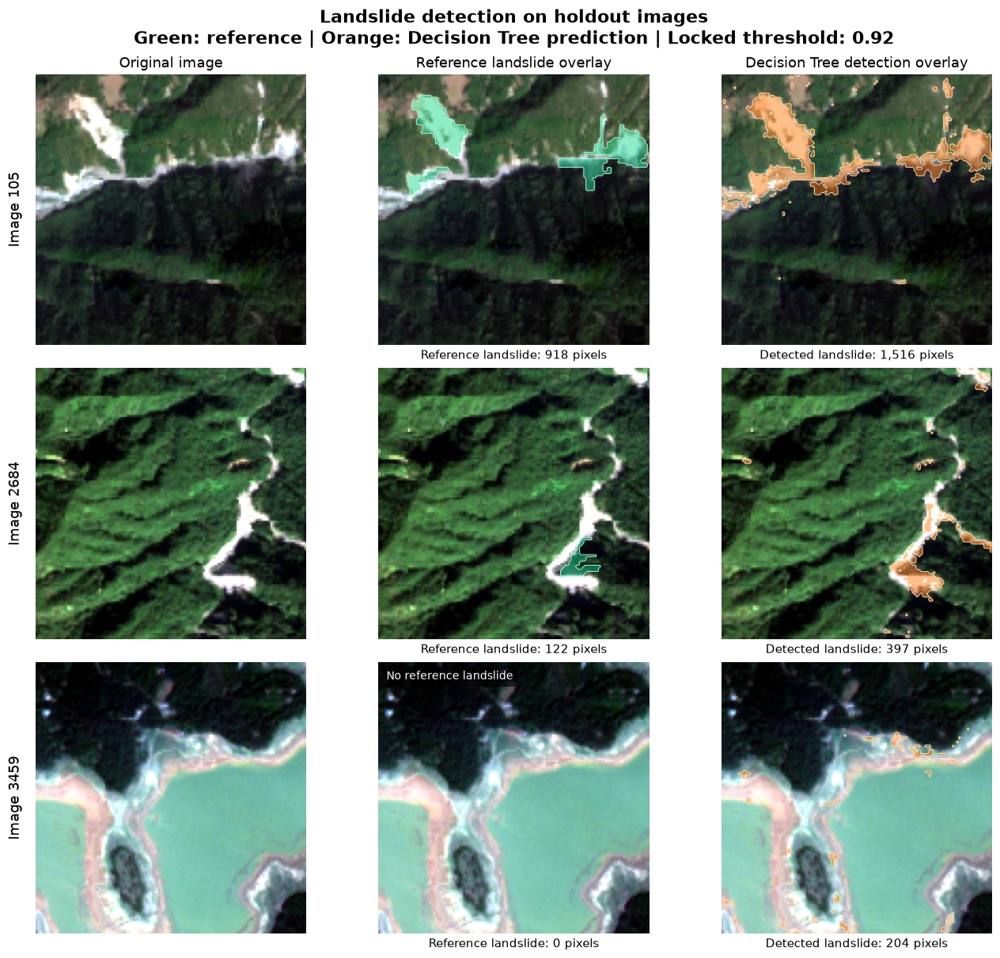

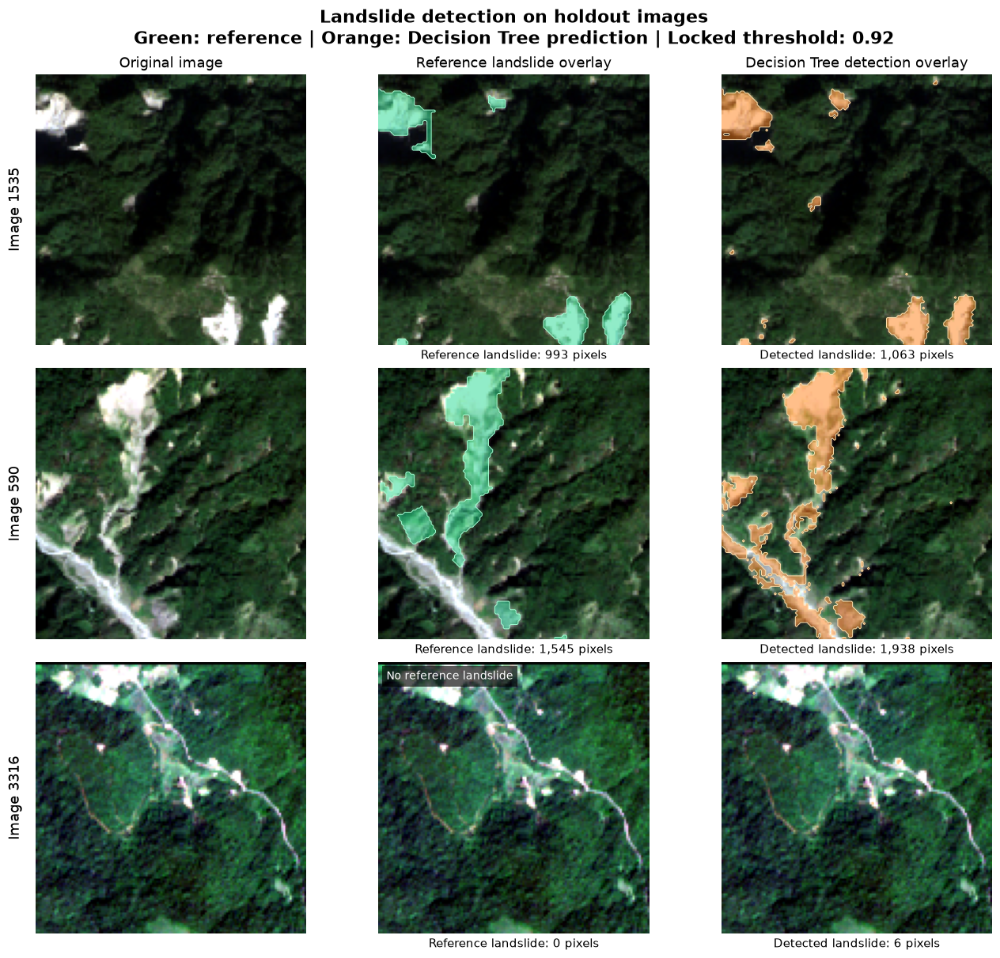

Overlays use the saved predictions at threshold 0.92.
RGB contrast enhancement is for display only.


In [81]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if "dt_holdout_spatial_records" not in globals():
    raise RuntimeError(
        "Restore the saved final_model_and_holdout results "
        "or run the previous spatial preparation cell first."
    )

def dt_make_detection_overlay(
    rgb,
    mask,
    color,
    opacity=0.48,
):
    """Apply a transparent color only to positive mask pixels."""
    overlay = np.zeros((*mask.shape, 4), dtype=float)
    overlay[..., :3] = color
    overlay[..., 3] = np.asarray(mask, dtype=bool) * opacity
    return overlay


with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "figure.facecolor": "white",
}):
    for page_start in range(
        0, len(dt_holdout_spatial_records), 3
    ):
        page_records = dt_holdout_spatial_records[
            page_start:page_start + 3
        ]

        fig, axes = plt.subplots(
            len(page_records),
            3,
            figsize=(13, 12),
            squeeze=False,
            constrained_layout=True,
        )

        for row, record in enumerate(page_records):

            rgb = record["rgb"]
            reference = record["mask"].astype(bool)
            prediction = record["prediction"].astype(bool)

            reference_overlay = dt_make_detection_overlay(
                rgb,
                reference,
                color=(0.10, 0.85, 0.55),
            )

            prediction_overlay = dt_make_detection_overlay(
                rgb,
                prediction,
                color=(1.00, 0.48, 0.05),
            )

            for col in range(3):
                ax = axes[row, col]
                ax.imshow(rgb)
                ax.set_xticks([])
                ax.set_yticks([])

                for spine in ax.spines.values():
                    spine.set_visible(False)

            axes[row, 1].imshow(reference_overlay)
            axes[row, 2].imshow(prediction_overlay)

            # Draw boundaries where both classes are present.
            if reference.any() and not reference.all():
                axes[row, 1].contour(
                    reference.astype(float),
                    levels=[0.5],
                    colors=["#A4FFD4"],
                    linewidths=0.7,
                )

            if prediction.any() and not prediction.all():
                axes[row, 2].contour(
                    prediction.astype(float),
                    levels=[0.5],
                    colors=["#FFE0AD"],
                    linewidths=0.7,
                )

            axes[row, 0].set_ylabel(
                f"Image {record['patch_id']}",
                fontsize=13,
                labelpad=12,
            )

            axes[row, 1].set_xlabel(
                f"Reference landslide: {reference.sum():,} pixels"
            )

            axes[row, 2].set_xlabel(
                f"Detected landslide: {prediction.sum():,} pixels"
            )

            if row == 0:
                axes[row, 0].set_title("Original image")
                axes[row, 1].set_title("Reference landslide overlay")
                axes[row, 2].set_title("Decision Tree detection overlay")

            if not reference.any():
                axes[row, 1].text(
                    0.03, 0.97,
                    "No reference landslide",
                    transform=axes[row, 1].transAxes,
                    ha="left",
                    va="top",
                    color="white",
                    fontsize=10,
                    bbox={
                        "facecolor": "black",
                        "alpha": 0.65,
                        "edgecolor": "none",
                        "pad": 4,
                    },
                )

        fig.suptitle(
            "Landslide detection on holdout images\n"
            "Green: reference | Orange: Decision Tree prediction "
            "| Locked threshold: 0.92",
            fontsize=16,
            fontweight="bold",
        )

        plt.show()

print(
    "Overlays use the saved predictions at threshold 0.92."
)
print(
    "RGB contrast enhancement is for display only."
)

### Rationale
Reference and predicted landslide masks were overlaid on the input
images to interpret detections in their visual context.

### Result
Image 1535 showed good spatial agreement with the reference.
Images 105 and 590 captured substantial landslide regions but also
showed overprediction. Image 2684 exhibited both omissions and
overprediction around a small reference landslide.

The reference-negative images produced 204 false positive pixels
(image 3459) and 6 false positive pixels (image 3316).
Similar predicted and reference pixel counts alone do not establish
spatial agreement.

### Visualization Decision
These overlays complement the error maps and are useful for the report.
The six examples illustrate model behavior; overall performance remains
based on all 760 holdout images.